In [1]:
## PROCESS FOR RUNNING ALL PARTICIPANTS FOR EACH STUDY
## FOR EACH STUDY
## 1) Specify sleep schedule
## 2) Get Inidivual data
## 3) Run Parameter sweep for timepoint X
## 5) Run parameter sweep again with best set from previous sweep
## 6) Compare distance between new params and old (and/or 
## 7) Iterate through 5 and 6 until distance or KL val does not diminish

In [2]:
library(Hmisc)
library(haven)
library(utils)
library(jsonlite)
library(stats)
#library(likelihood)
#library(GenSA)
library(optimization)
library(DBI)
library(RPostgreSQL)
library(dbplyr)
library(ks)
library(philentropy)
library(doBy)
library(lme4)
library(cluster)
library(mclust)
library(randomForest)
library(rstatix)
library(effectsize)
library(tidyverse)
library(lubridate)
library(furrr)
library(future)
library(dplyr)
library(purrr)
library(GGally)
library(ggpubr)
library(patchwork)
library(scales)
library(ggh4x)
library(viridis)
library(scico)
library(reshape2)
library(grid)
library(ggrepel)
library(ggallin)
library(ggnewscale)
library(RColorBrewer)
library(GGally)
library(ggpubr)
library(patchwork)
#library(broom)

Warning message:
"package 'Hmisc' was built under R version 4.3.3"

Attaching package: 'Hmisc'


The following objects are masked from 'package:base':

    format.pval, units


Warning message:
"package 'haven' was built under R version 4.3.3"
Warning message:
"package 'optimization' was built under R version 4.3.3"
Loading required package: Rcpp

Warning message:
"package 'DBI' was built under R version 4.3.3"
Warning message:
"package 'RPostgreSQL' was built under R version 4.3.3"
Warning message:
"package 'dbplyr' was built under R version 4.3.3"
Warning message:
"package 'philentropy' was built under R version 4.3.3"
Loading required package: Matrix

Warning message:
"package 'mclust' was built under R version 4.3.3"
Package 'mclust' version 6.1.1
Type 'citation("mclust")' for citing this R package in publications.

Warning message:
"package 'randomForest' was built under R version 4.3.3"
randomForest 4.7-1.2

Type rfNews() to see new features/changes/bug fixes.


Attaching package

In [3]:
HOST = "127.0.0.1"
#PORT = 9895
#PORT = 9897

# Load and Process Human Data

## Load OPSI and OPSII Data

In [4]:
###########################   START SETUP OBS DATASET   ############################
## Set up our dataset
## todo: iterate over studies X tasks X participants
##       automate extraction of sleep schedules and include that in msg to model
##       automate extraction of timing of tests and include that as bouts in msg to model

# Don't save your login in the script itself for database security. If this
# get's pushed to gitlab or any other platform the DB is no longer secure
# ***** Change file location to where you save your login info *****
# Should be a csv file with site, tool, username, and password columns
# site = ihmc, tool = postgresql, username = *your username*, password = *your password*

info <- readr::read_csv("C:/Users/ecranford/Desktop/IHMC/Projects/ROPER/DataMgmt/sql_info.csv",show_col_types = FALSE)
login_info <- filter(info, site == "ihmc", tool == "postgresql")

# connect
con <- dbConnect(
  drv=RPostgres::Postgres(),
  host = "10.1.28.79",
  port = 5432,
  user = login_info$username,
  password = login_info$password,
  dbname = "ROPER"
)

DBI::dbListTables(con)

#DBI::dbReadTable(con, "file_mapping")

# import full table into R
pvt_data <- DBI::dbReadTable(con, "pvt_raw_ops")
nback_ops_raw <- DBI::dbGetQuery(con, 'SELECT * FROM nback_raw_ops')
#roper_time_points <- DBI::dbReadTable(con, "roper_time_points")
#oura_data <- DBI::dbReadTable(con, "oura_sleep_data")
#garmin_data <- DBI::dbReadTable(con, "garmin_activity_data")

# pass SQL syntax/query to postgresql
#DBI::dbGetQuery(con, 'SELECT * FROM pvt_raw_ops')

pids <- DBI::dbReadTable(con, "pid_master_list")
file_mapping <- DBI::dbReadTable(con, "file_mapping")
dexa_body_comp <- DBI::dbReadTable(con, "dexa_body_comp")
poms_ops1 <- DBI::dbReadTable(con, "poms_raw_ops")
poms <- DBI::dbReadTable(con, "profile_of_mood_states")

# disconnect
DBI::dbDisconnect(con)





# Define False Starts (P=Premature) and Lapses (T=Timeout)
# Prematures that immediately follow previous trial with no elapsed
# time are assumed to be double-clicks or included as timeouts
#ops2_data$rt <- ifelse(ops2_data$RecType == "T", 500,
#                    ifelse(ops2_data$RecType == "P",
#                           ifelse(ops2_data$ElapsedSec == lag(ops2_data$ElapsedSec), NA, 0),
#                           ops2_data$RespTime * 1000))

## get bout schedule from day (day * 24) + time (translate time into decimal format)
#timing_data <- subset(subj_data, SessBlockID == 1 & RecNo == 1, select = c(study, ExpID, SubjID, SessionID, TaskID, SessBlockID, RecNo, StartDT))
#bouts <- round(((timing_data$SessionID-1)*24) + hour(timing_data$StartDT) + ((minute(timing_data$StartDT) + (second(timing_data$StartDT) / 60)) / 60),3)
#bouts <- c(34, 82, 130, 274, 322, 394, 514, 634, 754, 898)
ops1_bouts <- c(322,994,1450)
ops2_bouts <- c(130, 514, 898)
sere_bouts <- c(37,421,1069)
high_bouts <- c(181,541,781,1045)
#SERE - Day 2 (baseline), Day 18 (stress), Day 45 (recovery)
#OPS1 - Day 13 (baseline), Day 41 (stress), EOS (recovery)
#OPS2 - Day 6 (baseline), Day 22 (stress), Day 38 (recovery)

###########################   END SETUP OBS DATASET   ##############################

[1] "environment_symptoms"             "pid_master_list"                 
 [3] "rtmite"                           "ultimatum_game"                  
 [5] "evaluation_of_risks"              "visual_vigilance_test"           
 [7] "biodex_performance"               "study_meta"                      
 [9] "biodex_ops1"                      "demographics"                    
[11] "mass_spectrometry"                "patient_health_questionnaire"    
[13] "balloon_analogue_risk_task"       "garmin_activity_data"            
[15] "hormone_cytokine"                 "leg_press"                       
[17] "urine"                            "neuro_tracker_topt"              
[19] "speech_testing_topt"              "wingate"                         
[21] "deadlift"                         "recent_life_changes"             
[23] "psychomotor_vigilance_test"       "ops_misentered_pid_dictionary"   
[25] "ultimatum_raw_ops"                "vo2"                             
[27] "cycle_60min_ops1"                 "gramatical_reasoning_test"       
[29] "vitals_ops1"                      "slim"                            
[31] "connor_davidson_resilience_scale" "bart_raw_ops"                    
[33] "grip_strength"                    "vitals"                          
[35] "vo2_topt"                         "rtmite_raw_ops"                  
[37] "dari_movement_quality"            "topt_medical_history"            
[39] "counter_movement_jump"            "complete_blood_count"            
[41] "emotion_reg_topt"                 "visual_analogue_scale"           
[43] "cortisol_topt"                    "diet"                            
[45] "med_ball"                         "oura_sleep_data"                 
[47] "oxidative_stress"                 "cognitive_behavorial_all_topt"   
[49] "pvt_raw_ops"                      "poms_raw_ops"                    
[51] "visual_vigilance_raw_ops"         "adverse_events_raw_ops"          
[53] "nback_raw_ops"                    "qstb_raw_ops"                    
[55] "mab_topt"                         "neo_topt"                        
[57] "anam_topt"                        "eog_topt"                        
[59] "eeg_topt"                         "virtra_topt"                     
[61] "match_raw_ops"                    "gram_raw_ops"                    
[63] "roper_time_points"                "dexa_body_comp"                  
[65] "profile_of_mood_states"           "matching_to_sample_test"         
[67] "file_mapping"                     "nback_test"                      
[69] "buss_perry_aggression"            "comprehensive_metabolic_panel"   
[71] "daily_weight_ops1"                "demographics_sere"

In [55]:
head(pvt_data)

,study,ExpID,pid_raw,SessionID,TaskID,SessBlockID,RecNo,StartDT,TaskParms,ElapsedSec,⋯,MeanRRT,VarianceRRT,MedianRRT,Slope,YIntercept,RValue,subjectid,days,date1,date2
,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dttm>,<chr>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
1,OPSI,pbrc_ctb_v6,a00002249,1,PVT,1,1,2016-04-21 13:21:27,"10,60,0,1,5,1,500,F,F,35,0,255,K",2.9,⋯,NA,NA,NA,NA,NA,NA,A00-00-2249,0,Day 0 _4.21.16,Day 0
2,OPSI,pbrc_ctb_v6,a00002249,1,PVT,1,2,NA,,3.0,⋯,NA,NA,NA,NA,NA,NA,A00-00-2249,0,Day 0 _4.21.16,Day 0
3,OPSI,pbrc_ctb_v6,a00002249,1,PVT,1,3,NA,,4.4,⋯,NA,NA,NA,NA,NA,NA,A00-00-2249,0,Day 0 _4.21.16,Day 0
4,OPSI,pbrc_ctb_v6,a00002249,1,PVT,1,4,NA,,7.8,⋯,NA,NA,NA,NA,NA,NA,A00-00-2249,0,Day 0 _4.21.16,Day 0
5,OPSI,pbrc_ctb_v6,a00002249,1,PVT,1,5,NA,,11.1,⋯,NA,NA,NA,NA,NA,NA,A00-00-2249,0,Day 0 _4.21.16,Day 0
6,OPSI,pbrc_ctb_v6,a00002249,1,PVT,1,6,NA,,16.4,⋯,NA,NA,NA,NA,NA,NA,A00-00-2249,0,Day 0 _4.21.16,Day 0


In [5]:
head(pids)
colnames(pids)
head(file_mapping)
colnames(file_mapping)
head(dexa_body_comp)
colnames(dexa_body_comp)
unique(dexa_body_comp$study)
head(poms)
colnames(poms)
unique(poms$study)
head(poms_ops1)
colnames(poms_ops1)
unique(poms_ops1$study)


,Master_pid,study_pid,study_pid_alt,study
,<chr>,<chr>,<chr>,<chr>
1,ROP001,1,NA,SERE
2,ROP002,2,NA,SERE
3,ROP003,3,NA,SERE
4,ROP004,4,NA,SERE
5,ROP005,5,NA,SERE
6,ROP006,6,NA,SERE


[1] "Master_pid"    "study_pid"     "study_pid_alt" "study"

,pk_file_mapping,file_name,data_set,study
,<int64>,<chr>,<chr>,<chr>
1,1,Body Comp_16-02_High Altitude.xlsx,dxa,HIGH
2,2,OPS DXA GE Lunar iDXA - 2024-03-19 07 45 26.xlsx,dxa,OPSI
3,3,OPS II DXA Discovery - 2024-03-19 07 51 37.xlsx,dxa,OPSII
4,4,DataPhase4.01Prep.RData,dxa,TOPT
5,5,Body Comp_14-02_SERE.xlsx,dxa,SERE
6,6,N/A,VAS,SERE


[1] "pk_file_mapping" "file_name"       "data_set"        "study"

,study,roper_pid,pid,study_event_id,testdate,fat.android,fat.arms,fat.gynoid,fat.leftarm,fat.leftleg,⋯,tissuemass.tblh,totalmass.diff.arms,totalmass.diff.legs,totalmass.diff.tblh,totalmass.diff.total,totalmass.diff.trunk,totalmass.lefttblh,totalmass.righttblh,totalmass.tblh,weight
,<chr>,<chr>,<chr>,<chr>,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,OPSI,ROP166,A00-00-2249,D0,2016-04-21,11.9469,9.8998,18.3650,10.6423,17.4939,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
2,OPSI,ROP166,A00-00-2249,D11,2016-05-02,10.0285,9.5621,17.8119,9.6439,18.3040,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
3,OPSI,ROP166,A00-00-2249,D28,2016-05-19,7.2988,8.8658,16.1031,8.9119,15.2653,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
4,OPSI,ROP166,A00-00-2249,D39,2016-05-30,5.8275,7.9810,12.0910,8.3812,13.1262,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
5,OPSI,ROP166,A00-00-2249,D53,2016-06-13,7.9809,7.6673,12.2959,7.7442,12.8410,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
6,OPSI,ROP166,A00-00-2249,EOS,2016-06-20,9.9016,8.8557,13.7271,8.4666,14.5098,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA


...

[1] "study"                  "roper_pid"              "pid"                   
 [4] "time_point"             "anger.hostility"        "confusion.bewilderment"
 [7] "depression.dejection"   "fatigue.inertia"        "tension.anxiety"       
[10] "totalmooddisturbance"   "vigor.activity"         "uuid"

[1] "SERE"  "HIGH"  "OPSI"  "OPSII"

,study,ExpID,pid_raw,SessionID,TaskID,SessBlockID,RecNo,StartDT,TaskParms,ElapsedSec,⋯,Tension_Anxiety,Depression_Dejection,Anger_Hostility,Vigor_Activity,Fatigue,Confusion_Bewilderment,subjectid,days,date1,date2
,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dttm>,<chr>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
1,OPSI,pbrc_ctb_v,a00002249,1,POMS1,1,1,2016-04-21 12:49:09,"K,1,F",16.1,⋯,NA,NA,NA,NA,NA,NA,A00-00-2249,0,Day 0 _4.21.16,Day 0
2,OPSI,pbrc_ctb_v,a00002249,1,POMS1,1,2,NA,,23.9,⋯,NA,NA,NA,NA,NA,NA,A00-00-2249,0,Day 0 _4.21.16,Day 0
3,OPSI,pbrc_ctb_v,a00002249,1,POMS1,1,3,NA,,27.0,⋯,NA,NA,NA,NA,NA,NA,A00-00-2249,0,Day 0 _4.21.16,Day 0
4,OPSI,pbrc_ctb_v,a00002249,1,POMS1,1,4,NA,,36.4,⋯,NA,NA,NA,NA,NA,NA,A00-00-2249,0,Day 0 _4.21.16,Day 0
5,OPSI,pbrc_ctb_v,a00002249,1,POMS1,1,5,NA,,42.2,⋯,NA,NA,NA,NA,NA,NA,A00-00-2249,0,Day 0 _4.21.16,Day 0
6,OPSI,pbrc_ctb_v,a00002249,1,POMS1,1,6,NA,,50.2,⋯,NA,NA,NA,NA,NA,NA,A00-00-2249,0,Day 0 _4.21.16,Day 0


[1] "study"                  "ExpID"                  "pid_raw"               
 [4] "SessionID"              "TaskID"                 "SessBlockID"           
 [7] "RecNo"                  "StartDT"                "TaskParms"             
[10] "ElapsedSec"             "No_"                    "Adjective"             
[13] "Score"                  "Factor"                 "Passed"                
[16] "Skipped"                "Total_MD"               "Tension_Anxiety"       
[19] "Depression_Dejection"   "Anger_Hostility"        "Vigor_Activity"        
[22] "Fatigue"                "Confusion_Bewilderment" "subjectid"             
[25] "days"                   "date1"                  "date2"

[1] "OPSI"  "OPSII"

In [29]:
pid_key_join <- pids %>%
  mutate(
    join_pid = if_else(
      study == "HIGH",
      study_pid_alt,
      study_pid
    )
  ) %>%
  select(study, join_pid, Master_pid)
head(pid_key_join)

,study,join_pid,Master_pid
,<chr>,<chr>,<chr>
1,SERE,1,ROP001
2,SERE,2,ROP002
3,SERE,3,ROP003
4,SERE,4,ROP004
5,SERE,5,ROP005
6,SERE,6,ROP006


# Get DXA Data

In [42]:
dxa_data <- read_csv("dxa_data_all_studies.csv",show_col_types = FALSE)
head(dxa_data)

study,subjectid,Stress,Baseline,Recovery,dxa_delta_stress,dxa_delta_recovery,Robustness_dxa,Resilience_dxa
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HIGH,ROP072,48549,51348,NA,-2799,NA,-0.05451040,NA
HIGH,ROP073,61975,70859,NA,-8884,NA,-0.12537575,NA
HIGH,ROP074,72679,78515,NA,-5836,NA,-0.07432975,NA
HIGH,ROP075,57258,60131,NA,-2873,NA,-0.04777902,NA
HIGH,ROP076,58540,62834,NA,-4294,NA,-0.06833880,NA
HIGH,ROP077,55102,59190,NA,-4088,NA,-0.06906572,NA


In [37]:
dxa_data <- dxa_data %>%
  left_join(
    pid_key_join %>%
      select(study, join_pid, Master_pid),
    by = c(
      "study" = "study",
      "subjectid" = "join_pid"
    )
  )
head(dxa_data)

study,subjectid,Stress,Baseline,Recovery,dxa_delta_stress,dxa_delta_recovery,Robustness_dxa,Resilience_dxa,Master_pid
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
HIGH,1,48549,51348,NA,-2799,NA,-0.05451040,NA,ROP072
HIGH,2,61975,70859,NA,-8884,NA,-0.12537575,NA,ROP073
HIGH,3,72679,78515,NA,-5836,NA,-0.07432975,NA,ROP074
HIGH,4,57258,60131,NA,-2873,NA,-0.04777902,NA,ROP075
HIGH,5,58540,62834,NA,-4294,NA,-0.06833880,NA,ROP076
HIGH,6,55102,59190,NA,-4088,NA,-0.06906572,NA,ROP077


In [38]:
write.csv(dxa_data,"./dxa_data_new_ids.csv", row.names=FALSE)

In [39]:
dxa_data <- dxa_data %>%
  select(-subjectid) %>%
  rename(subjectid = Master_pid) %>%
  relocate(subjectid, .after = study)
head(dxa_data)

study,subjectid,Stress,Baseline,Recovery,dxa_delta_stress,dxa_delta_recovery,Robustness_dxa,Resilience_dxa
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HIGH,ROP072,48549,51348,NA,-2799,NA,-0.05451040,NA
HIGH,ROP073,61975,70859,NA,-8884,NA,-0.12537575,NA
HIGH,ROP074,72679,78515,NA,-5836,NA,-0.07432975,NA
HIGH,ROP075,57258,60131,NA,-2873,NA,-0.04777902,NA
HIGH,ROP076,58540,62834,NA,-4294,NA,-0.06833880,NA
HIGH,ROP077,55102,59190,NA,-4088,NA,-0.06906572,NA


In [40]:
write.csv(dxa_data,"./dxa_data_all_studies.csv", row.names=FALSE)

# Get POMS Data

In [50]:
poms_data <- poms_data %>%
  left_join(
    pid_key_join %>%
      select(study, join_pid, Master_pid),
    by = c(
      "study" = "study",
      "subjectid" = "join_pid"
    )
  )
head(poms_data)

poms_data <- poms_data %>%
  select(-subjectid) %>%
  rename(subjectid = Master_pid) %>%
  relocate(subjectid, .after = study)
head(poms_data)

write.csv(poms_data,"./poms_data_all_studies.csv", row.names=FALSE)

study,subjectid,Baseline,Stress,Recovery,poms_delta_stress,poms_delta_recovery,Robustness_poms,Resilience_poms,Rob_poms_v2,Rob_poms_v3
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HIGH,ROP072,-9,6,NA,15,NA,1.6666667,NA,0.6250000,-1.6666667
HIGH,ROP073,20,14,NA,-6,NA,-0.3000000,NA,-0.1132075,-0.3000000
HIGH,ROP074,5,52,NA,47,NA,9.4000000,NA,1.2368421,9.4000000
HIGH,ROP075,7,10,NA,3,NA,0.4285714,NA,0.0750000,0.4285714
HIGH,ROP076,11,24,NA,13,NA,1.1818182,NA,0.2954545,1.1818182
HIGH,ROP077,9,44,NA,35,NA,3.8888889,NA,0.8333333,3.8888889


In [52]:
poms_data <- read_csv("poms_data_all_studies.csv",show_col_types = FALSE)
head(poms_data)

study,subjectid,Baseline,Stress,Recovery,poms_delta_stress,poms_delta_recovery,Robustness_poms,Resilience_poms,Rob_poms_v2,Rob_poms_v3
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HIGH,ROP072,-9,6,NA,15,NA,1.6666667,NA,0.6250000,-1.6666667
HIGH,ROP073,20,14,NA,-6,NA,-0.3000000,NA,-0.1132075,-0.3000000
HIGH,ROP074,5,52,NA,47,NA,9.4000000,NA,1.2368421,9.4000000
HIGH,ROP075,7,10,NA,3,NA,0.4285714,NA,0.0750000,0.4285714
HIGH,ROP076,11,24,NA,13,NA,1.1818182,NA,0.2954545,1.1818182
HIGH,ROP077,9,44,NA,35,NA,3.8888889,NA,0.8333333,3.8888889


# Get Sleep Data

In [58]:
ops2_sleep_data <- read_csv("ops2_sleep_data.csv",show_col_types = FALSE)
head(ops2_sleep_data)

subjectid,date,days,FS_Id,Name,Identifier,Location,UTC_Offset,Average_Alertness,Latency,⋯,Slp_15,Slp_16,Slp_17,Slp_18,Slp_19,Slp_20,Slp_21,Slp_22,Slp_23,phase
<chr>,<date>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ROP216,2021-01-08,1,48164,A00-02-9405 TURMA,TURMA,Baton Rouge,-6,NA,13,⋯,0,0,0,0,0,0,0,0,0,1
ROP216,2021-01-09,2,48164,A00-02-9405 TURMA,TURMA,Baton Rouge,-6,NA,314,⋯,0,0,0,0,0,0,0,0,35,1
ROP216,2021-01-10,3,48164,A00-02-9405 TURMA,TURMA,Baton Rouge,-6,84.6,22,⋯,0,0,0,0,0,0,0,0,5,1
ROP216,2021-01-11,4,48164,A00-02-9405 TURMA,TURMA,Baton Rouge,-6,87.1,10,⋯,0,0,0,0,0,0,0,20,60,1
ROP216,2021-01-12,5,48164,A00-02-9405 TURMA,TURMA,Baton Rouge,-6,84.5,253,⋯,0,0,0,0,0,0,0,0,0,1
ROP216,2021-01-13,6,48164,A00-02-9405 TURMA,TURMA,Baton Rouge,-6,86.0,61,⋯,0,0,0,0,0,0,0,0,50,1


In [60]:
high_sleep_data <- read_csv("high_sleep_data.csv",show_col_types = FALSE)
head(high_sleep_data)

subjectid,date,location,week,days,session_id,sleep_onset,wake_onset,average_variance,minutes_resting,minutes_sleeping,minutes_sleep_latency,sleep_efficiency,wake_episodes,mean_wake_episode_duration
<chr>,<date>,<dbl>,<dbl>,<dbl>,<chr>,<dttm>,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ROP072,2016-05-16,1,1,1,0,NA,NA,NA,NA,NA,NA,NA,NA,NA
ROP072,2016-05-17,1,1,2,1,NA,NA,NA,NA,NA,NA,NA,NA,NA
ROP072,2016-05-18,1,1,3,2,2016-05-18 23:49:00,2016-05-19 05:13:00,78,338,280,11,82.8,6,9.3
ROP072,2016-05-19,1,1,4,3,2016-05-19 22:14:00,2016-05-20 05:53:00,-17,517,335,51,64.8,7,25.1
ROP072,2016-05-20,1,1,5,4,2016-05-20 23:54:00,2016-05-21 05:43:00,83,369,275,9,74.5,5,16.8
ROP072,2016-05-21,1,1,6,5,NA,NA,NA,NA,NA,NA,NA,NA,NA


# Get OPSI and OPSII Data

In [61]:
unique(nback_ops_raw$study)

#nback_ops
#Remove additional session for subject A00-07-5000
nback_ops <- nback_ops_raw[-(111597:111679),]
#Fix errors with SessionIDs for these two participants: A00-07-2880 & A00-07-4590
nback_ops$SessionID[nback_ops$subjectid=="A00-07-2880" & nback_ops$days=="          29"] <- 29
nback_ops$SessionID[nback_ops$subjectid=="A00-07-4590" & nback_ops$days=="          22"] <- 22


#Fix error with subjectid for this participant: A00-07-288
nback_ops$subjectid[nback_ops$subjectid=="A00-07-2880"] <- "A00-06-2880"
#Fix error with subjectid for this participant:
nback_ops$subjectid[nback_ops$pid_raw=="a00060739"] <- "A00-06-0739"

nback_ops$subjectid[nback_ops$pid_raw=="a00070590"] <- "A00-07-0590"

nback_ops <- nback_ops %>% arrange(study, subjectid, SessionID, SessBlockID, RecNo)

#head(nback_ops)



#First need to clean data with duplicate sessions, and then fix messed up days, date1, and date2 fields for ops1
nback_ops <- nback_ops[!duplicated(nback_ops[1:26]), ] ##removes duplicate rows, but leaving those with only incorrectly labeled SessionID's

days <- nback_ops %>%
    group_by(study, subjectid) %>% filter(!is.na(StartDT)) %>% arrange(study, subjectid, SessionID, SessBlockID) %>%
    mutate(days = ifelse(study == "OPSI", 
                         as.character(as.numeric(as.Date(StartDT) - as.Date(StartDT[1]))),
                         as.character(as.numeric(as.Date(StartDT) - as.Date(StartDT[1])) + 2))) %>% 
    mutate(date2 = ifelse(study == "OPSI",
                          ifelse(subjectid == "A00-06-0739" & as.numeric(days)>=16 & as.numeric(days)<=42, paste("Day ", as.numeric(days)-1, sep=""),
                                 ifelse(as.numeric(days)==3, "Day 2",
                                        ifelse(as.numeric(days)==7, "Day 6",
                                               ifelse(as.numeric(days)>56, "EOS",
                                                      ifelse(as.numeric(days)>=53, "Day 54", paste("Day ", days, sep="")))))),
                          ifelse(subjectid == "A00-07-2030" | subjectid == "A00-07-4258", paste("Day ", SessionID, sep=""),
                                 ifelse(as.numeric(days)==7, "Day 6",
                                        ifelse(as.numeric(days)==16 | as.numeric(days)==18, "Day 17",
                                               ifelse(as.numeric(days)==21, "Day 22",
                                                      ifelse(as.numeric(days)==26, "Day 27",
                                                             ifelse(as.numeric(days)==31 | as.numeric(days)==33, "Day 32",
                                                                    ifelse(as.numeric(days)>33, "Day 38", paste("Day ", days, sep="")))))))))) %>%
    mutate(date1 = paste(date2, "_", month(as.Date(StartDT)), ".", day(as.Date(StartDT)),".",format(as.Date(StartDT), "%y"), sep="")) %>%
    select(study,subjectid,SessionID,SessBlockID,days,date1,date2)
days

#days[1327,]
#days[1328,]

nback_ops <- nback_ops %>% rows_update(days, by = c("study","subjectid","SessionID","SessBlockID"))
#pvt_ops

#add study_event_id
nback_ops$study_event_id <- ifelse(nback_ops$study=="OPSI", nback_ops$date2, substr(nback_ops$date2,5,nchar(nback_ops$date2)))
nback_ops$days_fix <- ifelse(nback_ops$date2=="EOS", nback_ops$days, substr(nback_ops$date2,5,nchar(nback_ops$date2)))
#pvt_ops$RespTime <- as.double(pvt_ops$RespTime)
#pvt_ops
#nrow(subset(pvt_ops, study_event_id == "ERROR"))

#filter invalid trials (aka double clicks)
nback_ops <- nback_ops %>% group_by(study, subjectid, study_event_id, SessBlockID) %>% filter(!(row_number()>1 & TrialNo == lag(TrialNo)))

nback_ops$study <- as.factor(nback_ops$study)
nback_ops$subjectid <- as.factor(nback_ops$subjectid)
nback_ops$SessBlockID <- as.factor(nback_ops$SessBlockID)

unique(nback_ops$study_event_id)

[1] "OPSI"  "OPSII"

study,subjectid,SessionID,SessBlockID,days,date1,date2
<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
OPSI,A00-00-2249,1,1,0,Day 0_4.21.16,Day 0
OPSI,A00-00-2249,1,2,0,Day 0_4.21.16,Day 0
OPSI,A00-00-2249,2,1,2,Day 2_4.23.16,Day 2
OPSI,A00-00-2249,2,2,2,Day 2_4.23.16,Day 2
OPSI,A00-00-2249,4,1,4,Day 4_4.25.16,Day 4
OPSI,A00-00-2249,4,2,4,Day 4_4.25.16,Day 4
OPSI,A00-00-2249,5,1,5,Day 5_4.26.16,Day 5
OPSI,A00-00-2249,5,2,5,Day 5_4.26.16,Day 5
OPSI,A00-00-2249,6,1,6,Day 6_4.27.16,Day 6


[1] "Day 0"  "Day 2"  "Day 4"  "Day 5"  "Day 6"  "Day 8"  "Day 9"  "Day 10"
 [9] "Day 13" "Day 15" "Day 20" "Day 22" "Day 27" "Day 29" "Day 34" "Day 36"
[17] "Day 41" "Day 54" "EOS"    "2"      "4"      "6"      "12"     "14"    
[25] "17"     "22"     "27"     "32"     "38"

In [62]:
unique(pvt_data$study)

#pid_raw is very messed up
#A00-07-6166 SessionID 33 needs to change to 32
#A00-07-8758 SessionID 33 needs to change to 32
#A00-07-1637 SessionID 37 needs to change to 38
#A00-07-4627 SessionID 39 needs to change to 38
#### or just use 'subjectid' and 'days' which are already corrected
#using 'subjectid', 'days'

#Fix errors with SessionIDs for these two participants: A00-07-2880 & A00-07-4590
pvt_data$SessionID[pvt_data$subjectid=="A00-07-2880" & pvt_data$days=="          29"] <- 29
pvt_data$SessionID[pvt_data$subjectid=="A00-07-4590" & pvt_data$days=="          22"] <- 22

#Fix error with subjectid for this participant: A00-07-288
pvt_data$subjectid[pvt_data$subjectid=="A00-07-2880"] <- "A00-06-2880"

#First need to clean data with duplicate sessions, and then fix messed up days, date1, and date2 fields for ops1
pvt_data <- pvt_data[!duplicated(pvt_data[1:30]), ] ##removes duplicate rows, but leaving those with only incorrectly labeled SessionID's

days <- pvt_data %>%
    group_by(study, subjectid) %>% filter(!is.na(StartDT)) %>% arrange(study, subjectid, SessionID) %>%
    mutate(days = ifelse(study == "OPSI", 
                         as.character(as.numeric(as.Date(StartDT) - as.Date(StartDT[1]))),
                         as.character(as.numeric(as.Date(StartDT) - as.Date(StartDT[1])) + 2))) %>% 
    mutate(date2 = ifelse(study == "OPSI",
                          ifelse(subjectid == "A00-06-0739" & as.numeric(days)>=16 & as.numeric(days)<=42, paste("Day ", as.numeric(days)-1, sep=""),
                                 ifelse(as.numeric(days)==3, "Day 2",
                                        ifelse(as.numeric(days)==7, "Day 6",
                                               ifelse(as.numeric(days)>56, "EOS",
                                                      ifelse(as.numeric(days)>=53, "Day 54", paste("Day ", days, sep="")))))),
                          ifelse(subjectid == "A00-07-2030" | subjectid == "A00-07-4258", paste("Day ", SessionID, sep=""),
                                 ifelse(as.numeric(days)==7, "Day 6",
                                        ifelse(as.numeric(days)==16 | as.numeric(days)==18, "Day 17",
                                               ifelse(as.numeric(days)==21, "Day 22",
                                                      ifelse(as.numeric(days)==26, "Day 27",
                                                             ifelse(as.numeric(days)==31 | as.numeric(days)==33, "Day 32",
                                                                    ifelse(as.numeric(days)>33, "Day 38", paste("Day ", days, sep="")))))))))) %>%
    mutate(date1 = paste(date2, "_", month(as.Date(StartDT)), ".", day(as.Date(StartDT)),".",format(as.Date(StartDT), "%y"), sep="")) %>%
    select(study,subjectid,SessionID,days,date1,date2)
days

pvt_data <- pvt_data %>% rows_update(days, by = c("study","subjectid","SessionID"))
#pvt_data

#add study_event_id
pvt_data$study_event_id <- ifelse(pvt_data$study=="OPSI", pvt_data$date2, substr(pvt_data$date2,5,nchar(pvt_data$date2)))
pvt_data$days_fix <- ifelse(pvt_data$date2=="EOS", pvt_data$days, substr(pvt_data$date2,5,nchar(pvt_data$date2)))
#pvt_data$RespTime <- as.double(pvt_data$RespTime)
#pvt_data
#nrow(subset(pvt_data, study_event_id == "ERROR"))
unique(pvt_data$study_event_id)

#Filter agg data from files
pvt_data <- pvt_data %>% filter(RecType=="P" | RecType=="V" | RecType=="T")

#Fix Lapses and Filter invalid Prematures
pvt_data_cleaned <- pvt_data %>% group_by(study, subjectid, study_event_id) %>% 
    mutate(RecType = case_when(RecType=="T" & lead(RecType) == "P" & lead(ElapsedSec)-ElapsedSec<=0.5 ~ "L", TRUE ~ RecType),
           RespTime = ifelse(RecType=="L", 0.5+lead(ElapsedSec)-ElapsedSec, RespTime),
           ElapsedSec = ifelse(RecType=="L", lead(ElapsedSec), ElapsedSec)
          ) %>%
    filter(!(row_number()>1 & RecType == "P" & lag(RecType) == "L" & ElapsedSec >= lag(ElapsedSec) & ElapsedSec <= 0.5 + lag(ElapsedSec)))



[1] "OPSI"  "OPSII"

study,subjectid,SessionID,days,date1,date2
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>
OPSI,A00-00-2249,1,0,Day 0_4.21.16,Day 0
OPSI,A00-00-2249,2,2,Day 2_4.23.16,Day 2
OPSI,A00-00-2249,4,4,Day 4_4.25.16,Day 4
OPSI,A00-00-2249,5,5,Day 5_4.26.16,Day 5
OPSI,A00-00-2249,6,6,Day 6_4.27.16,Day 6
OPSI,A00-00-2249,8,8,Day 8_4.29.16,Day 8
OPSI,A00-00-2249,9,9,Day 9_4.30.16,Day 9
OPSI,A00-00-2249,10,10,Day 10_5.1.16,Day 10
OPSI,A00-00-2249,13,13,Day 13_5.4.16,Day 13


[1] "Day 0"  "Day 2"  "Day 4"  "Day 5"  "Day 6"  "Day 8"  "Day 9"  "Day 10"
 [9] "Day 13" "Day 15" "Day 20" "Day 22" "Day 27" "Day 29" "Day 34" "Day 36"
[17] "Day 41" "Day 54" "EOS"    "2"      "4"      "6"      "12"     "14"    
[25] "17"     "22"     "27"     "32"     "38"

## Process OPSI Data

In [81]:
## Get OPSII data
nback_ops1_data_cleaned <- subset(nback_ops, study == "OPSI")
unique(nback_ops1_data_cleaned$subjectid)
n_distinct(nback_ops1_data_cleaned$subjectid)

nback_ops1_data_cleaned <- nback_ops1_data_cleaned %>% group_by(study, subjectid) %>% arrange(match(study_event_id, c("Day 0","Day 2","Day 4","Day 5","Day 6","Day 8","Day 9","Day 10","Day 13","Day 15","Day 20","Day 22","Day 27","Day 29","Day 34","Day 36","Day 41","Day 54","EOS")), .by_group = TRUE)

head(nback_ops1_data_cleaned)

# Specify phases
nback_ops1_data_cleaned$phase <- ifelse(nback_ops1_data_cleaned$study_event_id == "EOS","Recovery",
                                  ifelse(as.integer(gsub("[A-Za-z]", "", nback_ops1_data_cleaned$study_event_id)) < 14, "Baseline",
                                         ifelse(as.integer(gsub("[A-Za-z]", "", nback_ops1_data_cleaned$study_event_id)) < 42, "Stress", "Recovery")))
nback_ops1_data_cleaned$phase <- factor(nback_ops1_data_cleaned$phase, c("Baseline","Stress","Recovery"))

nback_ops1_data_cleaned$study_event_id <- factor(nback_ops1_data_cleaned$study_event_id,levels=c("Day 0","Day 2","Day 4","Day 5","Day 6","Day 8","Day 9","Day 10","Day 13","Day 15","Day 20","Day 22","Day 27","Day 29","Day 34","Day 36","Day 41","Day 54","EOS"))

nback_ops1_data_cleaned <- nback_ops1_data_cleaned %>% filter(study_event_id %in% c("Day 13","Day 41","EOS")) %>% group_by(subjectid) %>%
    filter(length(unique(study_event_id)) == 3) #%>%
    #group_by(subjectid, study_event_id) %>%
    #filter(sum(!is.na(ResponseTime)) != 0) %>%
    #group_by(subjectid) %>% filter(n_distinct(phase) == 3)

n_distinct(nback_ops1_data_cleaned$subjectid)
head(nback_ops1_data_cleaned)

[1] A00-00-2249 A00-00-3079 A00-03-1277 A00-03-1546 A00-04-0719 A00-04-4617
 [7] A00-05-0608 A00-05-5251 A00-05-7326 A00-06-0459 A00-06-0662 A00-06-0739
[13] A00-06-2279 A00-06-2689 A00-06-2880 A00-06-3639 A00-06-4179 A00-06-4220
[19] A00-06-5839 A00-06-6899 A00-06-7069 A00-06-9279 A00-07-0431 A00-07-0570
[25] A00-07-0590 A00-07-0880 A00-07-1370 A00-07-1750 A00-07-1861 A00-07-2030
[31] A00-07-2760 A00-07-2821 A00-07-2831 A00-07-2911 A00-07-3350 A00-07-4331
[37] A00-07-4590 A00-07-4621 A00-07-4911 A00-07-5000 A00-07-6020 A00-07-6501
[43] A00-07-6820 A00-07-6930 A00-07-7141 A00-07-7711 A00-07-7960 A00-07-8150
[49] A00-07-8870 A00-07-9850
78 Levels: A00-00-2249 A00-00-3079 A00-02-9405 A00-03-1277 ... A00-08-7520

[1] 50

study,ExpID,pid_raw,SessionID,TaskID,SessBlockID,RecNo,StartDT,TaskParms,ElapsedSec,⋯,MeanRTHit,VarRTHit,MeanRTFalsePos,VarRTFalsePos,subjectid,days,date1,date2,study_event_id,days_fix
<fct>,<chr>,<chr>,<dbl>,<chr>,<fct>,<dbl>,<dttm>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>
OPSI,pbrc_ctb_v6,a00002249,1,NBack,1,1,2016-04-21 13:44:44,8.01205e+12,5.7,⋯,NA,NA,NA,NA,A00-00-2249,0,Day 0_4.21.16,Day 0,Day 0,0
OPSI,pbrc_ctb_v6,a00002249,1,NBack,1,2,NA,NA,8.2,⋯,NA,NA,NA,NA,A00-00-2249,0,Day 0_4.21.16,Day 0,Day 0,0
OPSI,pbrc_ctb_v6,a00002249,1,NBack,1,3,NA,NA,10.7,⋯,NA,NA,NA,NA,A00-00-2249,0,Day 0_4.21.16,Day 0,Day 0,0
OPSI,pbrc_ctb_v6,a00002249,1,NBack,1,4,NA,NA,13.2,⋯,NA,NA,NA,NA,A00-00-2249,0,Day 0_4.21.16,Day 0,Day 0,0
OPSI,pbrc_ctb_v6,a00002249,1,NBack,1,5,NA,NA,15.7,⋯,NA,NA,NA,NA,A00-00-2249,0,Day 0_4.21.16,Day 0,Day 0,0
OPSI,pbrc_ctb_v6,a00002249,1,NBack,1,6,NA,NA,18.3,⋯,NA,NA,NA,NA,A00-00-2249,0,Day 0_4.21.16,Day 0,Day 0,0


[1] 50

study,ExpID,pid_raw,SessionID,TaskID,SessBlockID,RecNo,StartDT,TaskParms,ElapsedSec,⋯,VarRTHit,MeanRTFalsePos,VarRTFalsePos,subjectid,days,date1,date2,study_event_id,days_fix,phase
<fct>,<chr>,<chr>,<dbl>,<chr>,<fct>,<dbl>,<dttm>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<chr>,<fct>,<chr>,<fct>
OPSI,pbrc_ctb_v7,a00002249,13,NBack,1,1,2016-05-04 09:30:02,8.01205e+12,2.6,⋯,NA,NA,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline
OPSI,pbrc_ctb_v7,a00002249,13,NBack,1,2,NA,NA,6.0,⋯,NA,NA,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline
OPSI,pbrc_ctb_v7,a00002249,13,NBack,1,3,NA,NA,10.6,⋯,NA,NA,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline
OPSI,pbrc_ctb_v7,a00002249,13,NBack,1,4,NA,NA,13.2,⋯,NA,NA,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline
OPSI,pbrc_ctb_v7,a00002249,13,NBack,1,5,NA,NA,15.7,⋯,NA,NA,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline
OPSI,pbrc_ctb_v7,a00002249,13,NBack,1,6,NA,NA,18.2,⋯,NA,NA,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline


In [82]:
nback_ops1_data_cleaned <- nback_ops1_data_cleaned %>%
  left_join(
    pid_key_join %>%
      select(study, join_pid, Master_pid),
    by = c(
      "study" = "study",
      "subjectid" = "join_pid"
    )
  )
head(nback_ops1_data_cleaned)

nback_ops1_data_cleaned <- nback_ops1_data_cleaned %>%
  ungroup() %>%
  select(-subjectid,-pid_raw) %>%
  rename(subjectid = Master_pid) %>%
  relocate(subjectid, .after = ExpID)
head(nback_ops1_data_cleaned)

write.csv(nback_ops1_data_cleaned,"./nback_ops1_data.csv", row.names=FALSE)

study,ExpID,pid_raw,SessionID,TaskID,SessBlockID,RecNo,StartDT,TaskParms,ElapsedSec,⋯,MeanRTFalsePos,VarRTFalsePos,subjectid,days,date1,date2,study_event_id,days_fix,phase,Master_pid
<chr>,<chr>,<chr>,<dbl>,<chr>,<fct>,<dbl>,<dttm>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<fct>,<chr>,<fct>,<chr>
OPSI,pbrc_ctb_v7,a00002249,13,NBack,1,1,2016-05-04 09:30:02,8.01205e+12,2.6,⋯,NA,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline,ROP166
OPSI,pbrc_ctb_v7,a00002249,13,NBack,1,2,NA,NA,6.0,⋯,NA,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline,ROP166
OPSI,pbrc_ctb_v7,a00002249,13,NBack,1,3,NA,NA,10.6,⋯,NA,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline,ROP166
OPSI,pbrc_ctb_v7,a00002249,13,NBack,1,4,NA,NA,13.2,⋯,NA,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline,ROP166
OPSI,pbrc_ctb_v7,a00002249,13,NBack,1,5,NA,NA,15.7,⋯,NA,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline,ROP166
OPSI,pbrc_ctb_v7,a00002249,13,NBack,1,6,NA,NA,18.2,⋯,NA,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline,ROP166


study,ExpID,subjectid,SessionID,TaskID,SessBlockID,RecNo,StartDT,TaskParms,ElapsedSec,⋯,MeanRTHit,VarRTHit,MeanRTFalsePos,VarRTFalsePos,days,date1,date2,study_event_id,days_fix,phase
<chr>,<chr>,<chr>,<dbl>,<chr>,<fct>,<dbl>,<dttm>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<fct>,<chr>,<fct>
OPSI,pbrc_ctb_v7,ROP166,13,NBack,1,1,2016-05-04 09:30:02,8.01205e+12,2.6,⋯,NA,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline
OPSI,pbrc_ctb_v7,ROP166,13,NBack,1,2,NA,NA,6.0,⋯,NA,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline
OPSI,pbrc_ctb_v7,ROP166,13,NBack,1,3,NA,NA,10.6,⋯,NA,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline
OPSI,pbrc_ctb_v7,ROP166,13,NBack,1,4,NA,NA,13.2,⋯,NA,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline
OPSI,pbrc_ctb_v7,ROP166,13,NBack,1,5,NA,NA,15.7,⋯,NA,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline
OPSI,pbrc_ctb_v7,ROP166,13,NBack,1,6,NA,NA,18.2,⋯,NA,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline


In [83]:
nback_ops1_data_cleaned <- read_csv("nback_ops1_data.csv",show_col_types = FALSE)
head(nback_ops1_data_cleaned)

study,ExpID,subjectid,SessionID,TaskID,SessBlockID,RecNo,StartDT,TaskParms,ElapsedSec,⋯,MeanRTHit,VarRTHit,MeanRTFalsePos,VarRTFalsePos,days,date1,date2,study_event_id,days_fix,phase
<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dttm>,<dbl>,<dbl>,⋯,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<chr>
OPSI,pbrc_ctb_v7,ROP166,13,NBack,1,1,2016-05-04 09:30:02,8.01205e+12,2.6,⋯,NA,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline
OPSI,pbrc_ctb_v7,ROP166,13,NBack,1,2,NA,NA,6.0,⋯,NA,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline
OPSI,pbrc_ctb_v7,ROP166,13,NBack,1,3,NA,NA,10.6,⋯,NA,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline
OPSI,pbrc_ctb_v7,ROP166,13,NBack,1,4,NA,NA,13.2,⋯,NA,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline
OPSI,pbrc_ctb_v7,ROP166,13,NBack,1,5,NA,NA,15.7,⋯,NA,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline
OPSI,pbrc_ctb_v7,ROP166,13,NBack,1,6,NA,NA,18.2,⋯,NA,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,Baseline


In [64]:
## Get OPSI data
pvt_ops1_data_cleaned <- subset(pvt_data_cleaned, study == "OPSI")
unique(pvt_ops1_data_cleaned$subjectid)
n_distinct(pvt_ops1_data_cleaned$subjectid)

pvt_ops1_data_cleaned <- pvt_ops1_data_cleaned %>% group_by(study, subjectid) %>% arrange(match(study_event_id, c("Day 0","Day 2","Day 4","Day 5","Day 6","Day 8","Day 9","Day 10","Day 13","Day 15","Day 20","Day 22","Day 27","Day 29","Day 34","Day 36","Day 41","Day 54","EOS")), .by_group = TRUE)

pvt_ops1_data_cleaned$rt <- ifelse(pvt_ops1_data_cleaned$RecType == "T", 1000,
                               ifelse(pvt_ops1_data_cleaned$RecType == "P", 0, 
                                      ifelse(pvt_ops1_data_cleaned$RespTime < 0.150, 0,
                                             ifelse(pvt_ops1_data_cleaned$RespTime >= 0.5, 750, pvt_ops1_data_cleaned$RespTime * 1000))))

# Specify phases
pvt_ops1_data_cleaned$phase <- ifelse(pvt_ops1_data_cleaned$study_event_id == "EOS","Recovery",
                                  ifelse(as.integer(gsub("[A-Za-z]", "", pvt_ops1_data_cleaned$study_event_id)) < 14, "Baseline",
                                         ifelse(as.integer(gsub("[A-Za-z]", "", pvt_ops1_data_cleaned$study_event_id)) < 42, "Stress", "Recovery")))
pvt_ops1_data_cleaned$phase <- factor(pvt_ops1_data_cleaned$phase, c("Baseline","Stress","Recovery"))

pvt_ops1_data_cleaned$study_event_id <- factor(pvt_ops1_data_cleaned$study_event_id,levels=c("Day 0","Day 2","Day 4","Day 5","Day 6","Day 8","Day 9","Day 10","Day 13","Day 15","Day 20","Day 22","Day 27","Day 29","Day 34","Day 36","Day 41","Day 54","EOS"))

pvt_ops1_data_cleaned <- pvt_ops1_data_cleaned %>% filter(study_event_id %in% c("Day 13","Day 41","EOS")) %>% group_by(subjectid) %>%
    filter(length(unique(study_event_id)) == 3) %>%
    group_by(subjectid, study_event_id) %>%
    filter(sum(!is.na(RespTime)) != 0) %>%
    group_by(subjectid) %>% filter(n_distinct(phase) == 3)

n_distinct(pvt_ops1_data_cleaned$subjectid)
head(pvt_ops1_data_cleaned)

[1] "A00-00-2249" "A00-00-3079" "A00-03-1277" "A00-03-1546" "A00-04-0719"
 [6] "A00-04-4617" "A00-05-0608" "A00-05-5251" "A00-05-7326" "A00-06-0459"
[11] "A00-06-0662" "A00-06-0739" "A00-06-2279" "A00-06-2689" "A00-06-3639"
[16] "A00-06-4179" "A00-06-4220" "A00-06-5839" "A00-06-6899" "A00-06-7069"
[21] "A00-06-9279" "A00-07-0431" "A00-07-0570" "A00-07-0590" "A00-07-0880"
[26] "A00-07-1370" "A00-07-1750" "A00-07-1861" "A00-07-2030" "A00-07-2760"
[31] "A00-07-2821" "A00-07-2831" "A00-06-2880" "A00-07-2911" "A00-07-3350"
[36] "A00-07-4331" "A00-07-4590" "A00-07-4621" "A00-07-4911" "A00-07-5000"
[41] "A00-07-6020" "A00-07-6501" "A00-07-6820" "A00-07-6930" "A00-07-7141"
[46] "A00-07-7711" "A00-07-7960" "A00-07-8150" "A00-07-8870" "A00-07-9850"

[1] 50

[1] 48

study,ExpID,pid_raw,SessionID,TaskID,SessBlockID,RecNo,StartDT,TaskParms,ElapsedSec,⋯,YIntercept,RValue,subjectid,days,date1,date2,study_event_id,days_fix,rt,phase
<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dttm>,<chr>,<dbl>,⋯,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<fct>,<chr>,<dbl>,<fct>
OPSI,pbrc_ctb_v7,a00002249,13,PVT,1,1,2016-05-04 09:17:14,"10,60,0,1,5,1,500,F,F,35,0,255,K",5.5,⋯,NA,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,462,Baseline
OPSI,pbrc_ctb_v7,a00002249,13,PVT,1,2,NA,,10.9,⋯,NA,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,358,Baseline
OPSI,pbrc_ctb_v7,a00002249,13,PVT,1,3,NA,,15.2,⋯,NA,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,317,Baseline
OPSI,pbrc_ctb_v7,a00002249,13,PVT,1,4,NA,,17.7,⋯,NA,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,438,Baseline
OPSI,pbrc_ctb_v7,a00002249,13,PVT,1,5,NA,,19.1,⋯,NA,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,482,Baseline
OPSI,pbrc_ctb_v7,a00002249,13,PVT,1,6,NA,,22.7,⋯,NA,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,750,Baseline


In [84]:
pvt_ops1_data_cleaned <- pvt_ops1_data_cleaned %>%
  left_join(
    pid_key_join %>%
      select(study, join_pid, Master_pid),
    by = c(
      "study" = "study",
      "subjectid" = "join_pid"
    )
  )
head(pvt_ops1_data_cleaned)

pvt_ops1_data_cleaned <- pvt_ops1_data_cleaned %>%
  ungroup() %>%
  select(-subjectid,-pid_raw) %>%
  rename(subjectid = Master_pid) %>%
  relocate(subjectid, .after = ExpID)
head(pvt_ops1_data_cleaned)

write.csv(pvt_ops1_data_cleaned,"./pvt_ops1_data.csv", row.names=FALSE)

study,ExpID,pid_raw,SessionID,TaskID,SessBlockID,RecNo,StartDT,TaskParms,ElapsedSec,⋯,RValue,subjectid,days,date1,date2,study_event_id,days_fix,rt,phase,Master_pid
<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dttm>,<chr>,<dbl>,⋯,<dbl>,<chr>,<chr>,<chr>,<chr>,<fct>,<chr>,<dbl>,<fct>,<chr>
OPSI,pbrc_ctb_v7,a00002249,13,PVT,1,1,2016-05-04 09:17:14,"10,60,0,1,5,1,500,F,F,35,0,255,K",5.5,⋯,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,462,Baseline,ROP166
OPSI,pbrc_ctb_v7,a00002249,13,PVT,1,2,NA,,10.9,⋯,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,358,Baseline,ROP166
OPSI,pbrc_ctb_v7,a00002249,13,PVT,1,3,NA,,15.2,⋯,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,317,Baseline,ROP166
OPSI,pbrc_ctb_v7,a00002249,13,PVT,1,4,NA,,17.7,⋯,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,438,Baseline,ROP166
OPSI,pbrc_ctb_v7,a00002249,13,PVT,1,5,NA,,19.1,⋯,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,482,Baseline,ROP166
OPSI,pbrc_ctb_v7,a00002249,13,PVT,1,6,NA,,22.7,⋯,NA,A00-00-2249,13,Day 13_5.4.16,Day 13,Day 13,13,750,Baseline,ROP166


study,ExpID,subjectid,SessionID,TaskID,SessBlockID,RecNo,StartDT,TaskParms,ElapsedSec,⋯,Slope,YIntercept,RValue,days,date1,date2,study_event_id,days_fix,rt,phase
<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dttm>,<chr>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<fct>,<chr>,<dbl>,<fct>
OPSI,pbrc_ctb_v7,ROP166,13,PVT,1,1,2016-05-04 09:17:14,"10,60,0,1,5,1,500,F,F,35,0,255,K",5.5,⋯,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,462,Baseline
OPSI,pbrc_ctb_v7,ROP166,13,PVT,1,2,NA,,10.9,⋯,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,358,Baseline
OPSI,pbrc_ctb_v7,ROP166,13,PVT,1,3,NA,,15.2,⋯,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,317,Baseline
OPSI,pbrc_ctb_v7,ROP166,13,PVT,1,4,NA,,17.7,⋯,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,438,Baseline
OPSI,pbrc_ctb_v7,ROP166,13,PVT,1,5,NA,,19.1,⋯,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,482,Baseline
OPSI,pbrc_ctb_v7,ROP166,13,PVT,1,6,NA,,22.7,⋯,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,750,Baseline


In [85]:
pvt_ops1_data_cleaned <- read_csv("pvt_ops1_data.csv",show_col_types = FALSE)
head(pvt_ops1_data_cleaned)

study,ExpID,subjectid,SessionID,TaskID,SessBlockID,RecNo,StartDT,TaskParms,ElapsedSec,⋯,Slope,YIntercept,RValue,days,date1,date2,study_event_id,days_fix,rt,phase
<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dttm>,<chr>,<dbl>,⋯,<lgl>,<lgl>,<lgl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
OPSI,pbrc_ctb_v7,ROP166,13,PVT,1,1,2016-05-04 09:17:14,"10,60,0,1,5,1,500,F,F,35,0,255,K",5.5,⋯,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,462,Baseline
OPSI,pbrc_ctb_v7,ROP166,13,PVT,1,2,NA,NA,10.9,⋯,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,358,Baseline
OPSI,pbrc_ctb_v7,ROP166,13,PVT,1,3,NA,NA,15.2,⋯,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,317,Baseline
OPSI,pbrc_ctb_v7,ROP166,13,PVT,1,4,NA,NA,17.7,⋯,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,438,Baseline
OPSI,pbrc_ctb_v7,ROP166,13,PVT,1,5,NA,NA,19.1,⋯,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,482,Baseline
OPSI,pbrc_ctb_v7,ROP166,13,PVT,1,6,NA,NA,22.7,⋯,NA,NA,NA,13,Day 13_5.4.16,Day 13,Day 13,13,750,Baseline


In [22]:
#subset(nback_ops1_data_cleaned, subjectid=="A00-00-2249" & phase=="Baseline" & SessBlockID==1)
#write.csv(subset(nback_ops1_data_cleaned, subjectid=="A00-00-2249"),"./nback_ops1_A00-00-2249.csv", row.names = FALSE)

In [23]:

#write.csv(subset(nback_ops1_data_cleaned, subjectid=="A00-07-8870"),"./nback_ops1_A00-07-8870.csv", row.names = FALSE)

## Process OPSII Data

In [92]:
## Get OPSII data
nback_ops2_data_cleaned <- subset(nback_ops, study == "OPSII")
unique(nback_ops2_data_cleaned$subjectid)
n_distinct(nback_ops2_data_cleaned$subjectid)

nback_ops2_data_cleaned <- nback_ops2_data_cleaned %>% group_by(study, subjectid) %>% arrange(match(study_event_id, c('2','4','6','12','14','17','22','27','32','38')), .by_group = TRUE)

head(nback_ops2_data_cleaned)

# Specify phases
nback_ops2_data_cleaned$phase <- ifelse(as.integer(nback_ops2_data_cleaned$study_event_id) < 8, "Baseline",
                                        ifelse(as.integer(nback_ops2_data_cleaned$study_event_id) < 28, "Stress", "Recovery"))
nback_ops2_data_cleaned$phase <- factor(nback_ops2_data_cleaned$phase, c("Baseline","Stress","Recovery"))

nback_ops2_data_cleaned$study_event_id <- factor(nback_ops2_data_cleaned$study_event_id,levels=c("2","4","6","12","14","17","22","27","32","38"))


[1] A00-02-9405 A00-04-8804 A00-06-0662 A00-06-9279 A00-07-0048 A00-07-0209
 [7] A00-07-1637 A00-07-2030 A00-07-2429 A00-07-2839 A00-07-3038 A00-07-3350
[13] A00-07-3727 A00-07-4011 A00-07-4258 A00-07-4569 A00-07-4627 A00-07-4679
[19] A00-07-5329 A00-07-6020 A00-07-6166 A00-07-6317 A00-07-6501 A00-07-6617
[25] A00-07-6629 A00-07-6808 A00-07-7149 A00-07-7818 A00-07-7829 A00-07-8059
[31] A00-07-8447 A00-07-8758 A00-07-9817 A00-08-7520
78 Levels: A00-00-2249 A00-00-3079 A00-02-9405 A00-03-1277 ... A00-08-7520

[1] 34

study,ExpID,pid_raw,SessionID,TaskID,SessBlockID,RecNo,StartDT,TaskParms,ElapsedSec,⋯,MeanRTHit,VarRTHit,MeanRTFalsePos,VarRTFalsePos,subjectid,days,date1,date2,study_event_id,days_fix
<fct>,<chr>,<chr>,<dbl>,<chr>,<fct>,<dbl>,<dttm>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>
OPSII,OPSII_Practice,a00029405,2,NBack,1,1,2021-01-09 09:14:25,8.01205e+12,5.6,⋯,NA,NA,NA,NA,A00-02-9405,2,Day 2_1.9.21,Day 2,2,2
OPSII,OPSII_Practice,a00029405,2,NBack,1,2,NA,NA,8.1,⋯,NA,NA,NA,NA,A00-02-9405,2,Day 2_1.9.21,Day 2,2,2
OPSII,OPSII_Practice,a00029405,2,NBack,1,3,NA,NA,10.6,⋯,NA,NA,NA,NA,A00-02-9405,2,Day 2_1.9.21,Day 2,2,2
OPSII,OPSII_Practice,a00029405,2,NBack,1,4,NA,NA,13.1,⋯,NA,NA,NA,NA,A00-02-9405,2,Day 2_1.9.21,Day 2,2,2
OPSII,OPSII_Practice,a00029405,2,NBack,1,5,NA,NA,15.6,⋯,NA,NA,NA,NA,A00-02-9405,2,Day 2_1.9.21,Day 2,2,2
OPSII,OPSII_Practice,a00029405,2,NBack,1,6,NA,NA,16.4,⋯,NA,NA,NA,NA,A00-02-9405,2,Day 2_1.9.21,Day 2,2,2


In [93]:
nback_ops2_data_cleaned <- nback_ops2_data_cleaned %>%
  left_join(
    pid_key_join %>%
      select(study, join_pid, Master_pid),
    by = c(
      "study" = "study",
      "subjectid" = "join_pid"
    )
  )
head(nback_ops2_data_cleaned)

nback_ops2_data_cleaned <- nback_ops2_data_cleaned %>%
  ungroup() %>%
  select(-subjectid,-pid_raw) %>%
  rename(subjectid = Master_pid) %>%
  relocate(subjectid, .after = ExpID)
head(nback_ops2_data_cleaned)

write.csv(nback_ops2_data_cleaned,"./nback_ops2_data.csv", row.names=FALSE)

study,ExpID,pid_raw,SessionID,TaskID,SessBlockID,RecNo,StartDT,TaskParms,ElapsedSec,⋯,MeanRTFalsePos,VarRTFalsePos,subjectid,days,date1,date2,study_event_id,days_fix,phase,Master_pid
<chr>,<chr>,<chr>,<dbl>,<chr>,<fct>,<dbl>,<dttm>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<fct>,<chr>,<fct>,<chr>
OPSII,OPSII_Practice,a00029405,2,NBack,1,1,2021-01-09 09:14:25,8.01205e+12,5.6,⋯,NA,NA,A00-02-9405,2,Day 2_1.9.21,Day 2,2,2,Baseline,ROP216
OPSII,OPSII_Practice,a00029405,2,NBack,1,2,NA,NA,8.1,⋯,NA,NA,A00-02-9405,2,Day 2_1.9.21,Day 2,2,2,Baseline,ROP216
OPSII,OPSII_Practice,a00029405,2,NBack,1,3,NA,NA,10.6,⋯,NA,NA,A00-02-9405,2,Day 2_1.9.21,Day 2,2,2,Baseline,ROP216
OPSII,OPSII_Practice,a00029405,2,NBack,1,4,NA,NA,13.1,⋯,NA,NA,A00-02-9405,2,Day 2_1.9.21,Day 2,2,2,Baseline,ROP216
OPSII,OPSII_Practice,a00029405,2,NBack,1,5,NA,NA,15.6,⋯,NA,NA,A00-02-9405,2,Day 2_1.9.21,Day 2,2,2,Baseline,ROP216
OPSII,OPSII_Practice,a00029405,2,NBack,1,6,NA,NA,16.4,⋯,NA,NA,A00-02-9405,2,Day 2_1.9.21,Day 2,2,2,Baseline,ROP216


study,ExpID,subjectid,SessionID,TaskID,SessBlockID,RecNo,StartDT,TaskParms,ElapsedSec,⋯,MeanRTHit,VarRTHit,MeanRTFalsePos,VarRTFalsePos,days,date1,date2,study_event_id,days_fix,phase
<chr>,<chr>,<chr>,<dbl>,<chr>,<fct>,<dbl>,<dttm>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<fct>,<chr>,<fct>
OPSII,OPSII_Practice,ROP216,2,NBack,1,1,2021-01-09 09:14:25,8.01205e+12,5.6,⋯,NA,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,Baseline
OPSII,OPSII_Practice,ROP216,2,NBack,1,2,NA,NA,8.1,⋯,NA,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,Baseline
OPSII,OPSII_Practice,ROP216,2,NBack,1,3,NA,NA,10.6,⋯,NA,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,Baseline
OPSII,OPSII_Practice,ROP216,2,NBack,1,4,NA,NA,13.1,⋯,NA,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,Baseline
OPSII,OPSII_Practice,ROP216,2,NBack,1,5,NA,NA,15.6,⋯,NA,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,Baseline
OPSII,OPSII_Practice,ROP216,2,NBack,1,6,NA,NA,16.4,⋯,NA,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,Baseline


In [94]:
nback_ops2_data_cleaned <- read_csv("nback_ops2_data.csv",show_col_types = FALSE)
head(nback_ops2_data_cleaned)

nback_ops2_data_cleaned <- nback_ops2_data_cleaned %>% filter(study_event_id %in% c("6","22","38")) %>% group_by(subjectid) %>%
    filter(length(unique(study_event_id)) == 3) #%>%
    #group_by(subjectid, study_event_id) %>%
    #filter(sum(!is.na(ResponseTime)) != 0) %>%
    #group_by(subjectid) %>% filter(n_distinct(phase) == 3)

head(nback_ops2_data_cleaned)
unique(nback_ops2_data_cleaned$subjectid)
n_distinct(nback_ops2_data_cleaned$subjectid)

study,ExpID,subjectid,SessionID,TaskID,SessBlockID,RecNo,StartDT,TaskParms,ElapsedSec,⋯,MeanRTHit,VarRTHit,MeanRTFalsePos,VarRTFalsePos,days,date1,date2,study_event_id,days_fix,phase
<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dttm>,<dbl>,<dbl>,⋯,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<chr>
OPSII,OPSII_Practice,ROP216,2,NBack,1,1,2021-01-09 09:14:25,8.01205e+12,5.6,⋯,NA,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,Baseline
OPSII,OPSII_Practice,ROP216,2,NBack,1,2,NA,NA,8.1,⋯,NA,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,Baseline
OPSII,OPSII_Practice,ROP216,2,NBack,1,3,NA,NA,10.6,⋯,NA,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,Baseline
OPSII,OPSII_Practice,ROP216,2,NBack,1,4,NA,NA,13.1,⋯,NA,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,Baseline
OPSII,OPSII_Practice,ROP216,2,NBack,1,5,NA,NA,15.6,⋯,NA,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,Baseline
OPSII,OPSII_Practice,ROP216,2,NBack,1,6,NA,NA,16.4,⋯,NA,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,Baseline


study,ExpID,subjectid,SessionID,TaskID,SessBlockID,RecNo,StartDT,TaskParms,ElapsedSec,⋯,MeanRTHit,VarRTHit,MeanRTFalsePos,VarRTFalsePos,days,date1,date2,study_event_id,days_fix,phase
<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dttm>,<dbl>,<dbl>,⋯,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<chr>
OPSII,OPSII_Practice,ROP216,6,NBack,1,1,2021-01-13 08:23:19,8.01205e+12,5.6,⋯,NA,NA,NA,NA,6,Day 6_1.13.21,Day 6,6,6,Baseline
OPSII,OPSII_Practice,ROP216,6,NBack,1,2,NA,NA,8.1,⋯,NA,NA,NA,NA,6,Day 6_1.13.21,Day 6,6,6,Baseline
OPSII,OPSII_Practice,ROP216,6,NBack,1,3,NA,NA,10.6,⋯,NA,NA,NA,NA,6,Day 6_1.13.21,Day 6,6,6,Baseline
OPSII,OPSII_Practice,ROP216,6,NBack,1,4,NA,NA,13.1,⋯,NA,NA,NA,NA,6,Day 6_1.13.21,Day 6,6,6,Baseline
OPSII,OPSII_Practice,ROP216,6,NBack,1,5,NA,NA,13.5,⋯,NA,NA,NA,NA,6,Day 6_1.13.21,Day 6,6,6,Baseline
OPSII,OPSII_Practice,ROP216,6,NBack,1,6,NA,NA,18.1,⋯,NA,NA,NA,NA,6,Day 6_1.13.21,Day 6,6,6,Baseline


[1] "ROP216" "ROP217" "ROP249" "ROP218" "ROP219" "ROP220" "ROP221" "ROP222"
 [9] "ROP223" "ROP224" "ROP225" "ROP226" "ROP227" "ROP228" "ROP229" "ROP230"
[17] "ROP231" "ROP232" "ROP233" "ROP234" "ROP235" "ROP236" "ROP237" "ROP238"
[25] "ROP239" "ROP240" "ROP241" "ROP242" "ROP243" "ROP244" "ROP245" "ROP246"

[1] 32

In [95]:
## Get OPSII data
pvt_ops2_data_cleaned <- subset(pvt_data_cleaned, study == "OPSII")
unique(pvt_ops2_data_cleaned$subjectid)
n_distinct(pvt_ops2_data_cleaned$subjectid)

pvt_ops2_data_cleaned <- pvt_ops2_data_cleaned %>% group_by(study, subjectid) %>% arrange(match(study_event_id, c('2','4','6','12','14','17','22','27','32','38')), .by_group = TRUE)

pvt_ops2_data_cleaned$rt <- ifelse(pvt_ops2_data_cleaned$RecType == "T", 1000,
                               ifelse(pvt_ops2_data_cleaned$RecType == "P", 0, 
                                      ifelse(pvt_ops2_data_cleaned$RespTime < 0.150, 0,
                                             ifelse(pvt_ops2_data_cleaned$RespTime >= 0.5, 750, pvt_ops2_data_cleaned$RespTime * 1000))))

# Specify phases
pvt_ops2_data_cleaned$phase <- ifelse(as.integer(pvt_ops2_data_cleaned$study_event_id) <= 8, "Baseline",
                                  ifelse(as.integer(pvt_ops2_data_cleaned$study_event_id) <= 28, "Stress", "Recovery"))
pvt_ops2_data_cleaned$phase <- factor(pvt_ops2_data_cleaned$phase, c("Baseline","Stress","Recovery"))

pvt_ops2_data_cleaned$study_event_id <- factor(pvt_ops2_data_cleaned$study_event_id,levels=c("2","4","6","12","14","17","22","27","32","38"))


[1] "A00-02-9405" "A00-04-8804" "A00-06-0662" "A00-06-9279" "A00-07-0048"
 [6] "A00-07-0209" "A00-07-1637" "A00-07-2030" "A00-07-2429" "A00-07-2839"
[11] "A00-07-3038" "A00-07-3350" "A00-07-3727" "A00-07-4011" "A00-07-4258"
[16] "A00-07-4569" "A00-07-4627" "A00-07-4679" "A00-07-5329" "A00-07-6020"
[21] "A00-07-6166" "A00-07-6317" "A00-07-6501" "A00-07-6617" "A00-07-6629"
[26] "A00-07-6808" "A00-07-7149" "A00-07-7818" "A00-07-7829" "A00-07-8059"
[31] "A00-07-8447" "A00-07-8758" "A00-07-9817" "A00-08-7520"

[1] 34

In [96]:
pvt_ops2_data_cleaned <- pvt_ops2_data_cleaned %>%
  left_join(
    pid_key_join %>%
      select(study, join_pid, Master_pid),
    by = c(
      "study" = "study",
      "subjectid" = "join_pid"
    )
  )
head(pvt_ops2_data_cleaned)

pvt_ops2_data_cleaned <- pvt_ops2_data_cleaned %>%
  ungroup() %>%
  select(-subjectid,-pid_raw) %>%
  rename(subjectid = Master_pid) %>%
  relocate(subjectid, .after = ExpID)
head(pvt_ops2_data_cleaned)

write.csv(pvt_ops2_data_cleaned,"./pvt_ops2_data.csv", row.names=FALSE)

study,ExpID,pid_raw,SessionID,TaskID,SessBlockID,RecNo,StartDT,TaskParms,ElapsedSec,⋯,RValue,subjectid,days,date1,date2,study_event_id,days_fix,rt,phase,Master_pid
<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dttm>,<chr>,<dbl>,⋯,<dbl>,<chr>,<chr>,<chr>,<chr>,<fct>,<chr>,<dbl>,<fct>,<chr>
OPSII,OPSII_Practice,a00029405,2,PVT,1,1,2021-01-09 08:59:21,"10,60,0,1,5,1,500,F,F,35,0,255,B",5.6,⋯,NA,A00-02-9405,2,Day 2_1.9.21,Day 2,2,2,1000,Baseline,ROP216
OPSII,OPSII_Practice,a00029405,2,PVT,1,2,NA,,9.1,⋯,NA,A00-02-9405,2,Day 2_1.9.21,Day 2,2,2,1000,Baseline,ROP216
OPSII,OPSII_Practice,a00029405,2,PVT,1,3,NA,,13.6,⋯,NA,A00-02-9405,2,Day 2_1.9.21,Day 2,2,2,1000,Baseline,ROP216
OPSII,OPSII_Practice,a00029405,2,PVT,1,4,NA,,18.2,⋯,NA,A00-02-9405,2,Day 2_1.9.21,Day 2,2,2,1000,Baseline,ROP216
OPSII,OPSII_Practice,a00029405,2,PVT,1,5,NA,,20.7,⋯,NA,A00-02-9405,2,Day 2_1.9.21,Day 2,2,2,1000,Baseline,ROP216
OPSII,OPSII_Practice,a00029405,2,PVT,1,6,NA,,24.2,⋯,NA,A00-02-9405,2,Day 2_1.9.21,Day 2,2,2,1000,Baseline,ROP216


study,ExpID,subjectid,SessionID,TaskID,SessBlockID,RecNo,StartDT,TaskParms,ElapsedSec,⋯,Slope,YIntercept,RValue,days,date1,date2,study_event_id,days_fix,rt,phase
<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dttm>,<chr>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<fct>,<chr>,<dbl>,<fct>
OPSII,OPSII_Practice,ROP216,2,PVT,1,1,2021-01-09 08:59:21,"10,60,0,1,5,1,500,F,F,35,0,255,B",5.6,⋯,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,1000,Baseline
OPSII,OPSII_Practice,ROP216,2,PVT,1,2,NA,,9.1,⋯,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,1000,Baseline
OPSII,OPSII_Practice,ROP216,2,PVT,1,3,NA,,13.6,⋯,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,1000,Baseline
OPSII,OPSII_Practice,ROP216,2,PVT,1,4,NA,,18.2,⋯,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,1000,Baseline
OPSII,OPSII_Practice,ROP216,2,PVT,1,5,NA,,20.7,⋯,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,1000,Baseline
OPSII,OPSII_Practice,ROP216,2,PVT,1,6,NA,,24.2,⋯,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,1000,Baseline


In [97]:
pvt_ops2_data_cleaned <- read_csv("pvt_ops2_data.csv",show_col_types = FALSE)
head(pvt_ops2_data_cleaned)

pvt_ops2_data_cleaned <- pvt_ops2_data_cleaned %>% filter(study_event_id %in% c("6","22","38")) %>% group_by(subjectid) %>%
    filter(length(unique(study_event_id)) == 3) %>%
    group_by(subjectid, study_event_id) %>%
    filter(sum(!is.na(RespTime)) != 0) %>%
    group_by(subjectid) %>% filter(n_distinct(phase) == 3)

n_distinct(pvt_ops2_data_cleaned$subjectid)
head(pvt_ops2_data_cleaned)

study,ExpID,subjectid,SessionID,TaskID,SessBlockID,RecNo,StartDT,TaskParms,ElapsedSec,⋯,Slope,YIntercept,RValue,days,date1,date2,study_event_id,days_fix,rt,phase
<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dttm>,<chr>,<dbl>,⋯,<lgl>,<lgl>,<lgl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>
OPSII,OPSII_Practice,ROP216,2,PVT,1,1,2021-01-09 08:59:21,"10,60,0,1,5,1,500,F,F,35,0,255,B",5.6,⋯,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,1000,Baseline
OPSII,OPSII_Practice,ROP216,2,PVT,1,2,NA,NA,9.1,⋯,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,1000,Baseline
OPSII,OPSII_Practice,ROP216,2,PVT,1,3,NA,NA,13.6,⋯,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,1000,Baseline
OPSII,OPSII_Practice,ROP216,2,PVT,1,4,NA,NA,18.2,⋯,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,1000,Baseline
OPSII,OPSII_Practice,ROP216,2,PVT,1,5,NA,NA,20.7,⋯,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,1000,Baseline
OPSII,OPSII_Practice,ROP216,2,PVT,1,6,NA,NA,24.2,⋯,NA,NA,NA,2,Day 2_1.9.21,Day 2,2,2,1000,Baseline


[1] 30

study,ExpID,subjectid,SessionID,TaskID,SessBlockID,RecNo,StartDT,TaskParms,ElapsedSec,⋯,Slope,YIntercept,RValue,days,date1,date2,study_event_id,days_fix,rt,phase
<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dttm>,<chr>,<dbl>,⋯,<lgl>,<lgl>,<lgl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>
OPSII,OPSII_Practice,ROP216,6,PVT,1,1,2021-01-13 08:10:19,"10,60,0,1,5,1,500,F,F,35,0,255,B",1.6,⋯,NA,NA,NA,6,Day 6_1.13.21,Day 6,6,6,750,Baseline
OPSII,OPSII_Practice,ROP216,6,PVT,1,3,NA,NA,4.1,⋯,NA,NA,NA,6,Day 6_1.13.21,Day 6,6,6,428,Baseline
OPSII,OPSII_Practice,ROP216,6,PVT,1,4,NA,NA,9.4,⋯,NA,NA,NA,6,Day 6_1.13.21,Day 6,6,6,349,Baseline
OPSII,OPSII_Practice,ROP216,6,PVT,1,5,NA,NA,14.7,⋯,NA,NA,NA,6,Day 6_1.13.21,Day 6,6,6,299,Baseline
OPSII,OPSII_Practice,ROP216,6,PVT,1,6,NA,NA,19.0,⋯,NA,NA,NA,6,Day 6_1.13.21,Day 6,6,6,292,Baseline
OPSII,OPSII_Practice,ROP216,6,PVT,1,7,NA,NA,21.5,⋯,NA,NA,NA,6,Day 6_1.13.21,Day 6,6,6,472,Baseline


## Process SERE Data **** NO N-BACK DATA FOR SERE STUDY*******

In [98]:
##SERE
pvt_sere_base <- read.table("../../Data/FromHarris/fwcogdataroper/Base_PVT-Presentations.tab", header=TRUE)
#head(pvt_sere_base)
pvt_sere_post <- read.table("../../Data/FromHarris/fwcogdataroper/Post_PVT-Presentations.tab", header=TRUE)
#head(pvt_sere_post)
pvt_sere_rec <- read.table("../../Data/FromHarris/fwcogdataroper/Recv_PVT-Presentations.tab", header=TRUE)
#head(pvt_sere_rec)

#Stack data, add study_event_id
pvt_sere_base$study_event_id <- "bt"
pvt_sere_post$study_event_id <- "pt"
pvt_sere_rec$study_event_id <- "rt"
pvt_sere <- rbind(pvt_sere_base, pvt_sere_post, pvt_sere_rec)
pvt_sere$RespTime <- as.double(pvt_sere$RespTime)
#head(pvt_sere)

pvt_sere$study <- "SERE"
colnames(pvt_sere)[colnames(pvt_sere) == "SubjID"] <- "subjectid"
pvt_sere$subjectid <- as.character(pvt_sere$subjectid)
#head(pvt_sere)


#Fix Lapses and Filter invalid Prematures
pvt_sere_data_cleaned <- pvt_sere %>% group_by(subjectid, study_event_id) %>% 
    mutate(RecType = case_when(RecType=="T" & lead(RecType) == "P" & lead(ElapsedSec)-ElapsedSec<=0.5 ~ "L", TRUE ~ RecType),
           RespTime = ifelse(RecType=="L", 0.5+lead(ElapsedSec)-ElapsedSec, RespTime),
           ElapsedSec = ifelse(RecType=="L", lead(ElapsedSec), ElapsedSec)
          ) %>%
    filter(!(row_number()>1 & RecType == "P" & lag(RecType) == "L" & ElapsedSec >= lag(ElapsedSec) & ElapsedSec <= 0.5 + lag(ElapsedSec)))
#head(pvt_sere_cleaned)
#nrow(subset(pvt_high_cleaned, RecType == "P")) - nrow(subset(pvt_high, RecType == "P"))
pvt_sere_data_cleaned$study <- as.factor(pvt_sere_data_cleaned$study)
pvt_sere_data_cleaned$subjectid <- as.factor(pvt_sere_data_cleaned$subjectid)
pvt_sere_data_cleaned$SessBlockID <- as.factor(pvt_sere_data_cleaned$SessBlockID)
unique(pvt_sere$subjectid)
n_distinct(pvt_sere$subjectid)

pvt_sere_data_cleaned <- pvt_sere_data_cleaned %>% group_by(study, subjectid) %>% arrange(match(study_event_id, c("bt","pt","rt")), .by_group = TRUE)

pvt_sere_data_cleaned$rt <- ifelse(pvt_sere_data_cleaned$RecType == "T", 1000,
                               ifelse(pvt_sere_data_cleaned$RecType == "P", 0, 
                                      ifelse(pvt_sere_data_cleaned$RespTime < 0.150, 0,
                                             ifelse(pvt_sere_data_cleaned$RespTime >= 0.5, 750, pvt_sere_data_cleaned$RespTime * 1000))))

# Specify phases
pvt_sere_data_cleaned$phase <- ifelse(pvt_sere_data_cleaned$study_event_id == "bt","Baseline",
                                 ifelse(pvt_sere_data_cleaned$study_event_id == "pt","Stress","Recovery"))

pvt_sere_data_cleaned$phase <- factor(pvt_sere_data_cleaned$phase, c("Baseline","Stress","Recovery"))

pvt_sere_data_cleaned$study_event_id <- factor(pvt_sere_data_cleaned$study_event_id,c("bt","pt","rt"))

#pvt_sere_cleaned <- pvt_sere_cleaned %>% group_by(subjectid, study_event_id) %>%
#    filter(sum(!is.na(RespTime)) != 0)


Warning message in eval(expr, envir, enclos):
"NAs introduced by coercion"


[1] "1"  "10" "11" "12" "13" "14" "15" "16" "17" "18" "19" "2"  "20" "3"  "4" 
[16] "5"  "6"  "7"  "8"  "9"  "21" "22" "23" "24" "25" "27" "28" "30" "31" "36"
[31] "37" "38" "39" "40" "41" "43" "44" "45" "46" "47" "48" "49" "51" "52" "53"
[46] "54" "55" "56" "57" "58" "70" "71" "33" "34" "35" "59" "60" "61" "62" "64"
[61] "65" "67" "68"

[1] 63

In [99]:
pvt_sere_data_cleaned <- pvt_sere_data_cleaned %>%
  left_join(
    subset(pid_key_join, study=="SERE") %>%
      select(join_pid, Master_pid),
    by = c(
      "subjectid" = "join_pid"
    )
  )
head(pvt_sere_data_cleaned)

pvt_sere_data_cleaned <- pvt_sere_data_cleaned %>%
  ungroup() %>%
  select(-subjectid) %>%
  rename(subjectid = Master_pid) %>%
  relocate(subjectid, .after = ExpID)
head(pvt_sere_data_cleaned)

write.csv(pvt_sere_data_cleaned,"./pvt_sere_data.csv", row.names=FALSE)

ExpID,subjectid,SessionID,TaskID,SessBlockID,ElapsedSec,BlockNo,TrialNo,RecType,Delay,RespTime,Device,study_event_id,study,rt,phase,Master_pid
<chr>,<chr>,<int>,<chr>,<fct>,<dbl>,<int>,<int>,<chr>,<int>,<dbl>,<chr>,<fct>,<fct>,<dbl>,<fct>,<chr>
CTB_MARSOC,1,1,PVT,1,1.8,1,1,P,3,NA,M,bt,SERE,0,Baseline,ROP001
CTB_MARSOC,1,1,PVT,1,7.3,1,2,T,5,NA,.,bt,SERE,1000,Baseline,ROP001
CTB_MARSOC,1,1,PVT,1,8.8,1,3,T,1,NA,.,bt,SERE,1000,Baseline,ROP001
CTB_MARSOC,1,1,PVT,1,12.7,1,4,P,4,NA,M,bt,SERE,0,Baseline,ROP001
CTB_MARSOC,1,1,PVT,1,18.2,1,5,V,5,0.437,K,bt,SERE,437,Baseline,ROP001
CTB_MARSOC,1,1,PVT,1,19.6,1,6,V,1,0.394,K,bt,SERE,394,Baseline,ROP001


ExpID,subjectid,SessionID,TaskID,SessBlockID,ElapsedSec,BlockNo,TrialNo,RecType,Delay,RespTime,Device,study_event_id,study,rt,phase
<chr>,<chr>,<int>,<chr>,<fct>,<dbl>,<int>,<int>,<chr>,<int>,<dbl>,<chr>,<fct>,<fct>,<dbl>,<fct>
CTB_MARSOC,ROP001,1,PVT,1,1.8,1,1,P,3,NA,M,bt,SERE,0,Baseline
CTB_MARSOC,ROP001,1,PVT,1,7.3,1,2,T,5,NA,.,bt,SERE,1000,Baseline
CTB_MARSOC,ROP001,1,PVT,1,8.8,1,3,T,1,NA,.,bt,SERE,1000,Baseline
CTB_MARSOC,ROP001,1,PVT,1,12.7,1,4,P,4,NA,M,bt,SERE,0,Baseline
CTB_MARSOC,ROP001,1,PVT,1,18.2,1,5,V,5,0.437,K,bt,SERE,437,Baseline
CTB_MARSOC,ROP001,1,PVT,1,19.6,1,6,V,1,0.394,K,bt,SERE,394,Baseline


In [100]:
pvt_sere_data_cleaned <- read_csv("pvt_sere_data.csv",show_col_types = FALSE)
head(pvt_sere_data_cleaned)

pvt_sere_data_cleaned <- pvt_sere_data_cleaned %>% filter(study_event_id %in% c("bt","pt","rt")) %>% group_by(subjectid) %>%
    filter(length(unique(study_event_id)) == 3) %>%
    group_by(subjectid, study_event_id) %>%
    filter(sum(!is.na(RespTime)) != 0) %>%
    group_by(subjectid) %>% filter(n_distinct(phase) == 3)

n_distinct(pvt_sere_data_cleaned$subjectid)
head(pvt_sere_data_cleaned)

ExpID,subjectid,SessionID,TaskID,SessBlockID,ElapsedSec,BlockNo,TrialNo,RecType,Delay,RespTime,Device,study_event_id,study,rt,phase
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<chr>
CTB_MARSOC,ROP001,1,PVT,1,1.8,1,1,P,3,NA,M,bt,SERE,0,Baseline
CTB_MARSOC,ROP001,1,PVT,1,7.3,1,2,T,5,NA,.,bt,SERE,1000,Baseline
CTB_MARSOC,ROP001,1,PVT,1,8.8,1,3,T,1,NA,.,bt,SERE,1000,Baseline
CTB_MARSOC,ROP001,1,PVT,1,12.7,1,4,P,4,NA,M,bt,SERE,0,Baseline
CTB_MARSOC,ROP001,1,PVT,1,18.2,1,5,V,5,0.437,K,bt,SERE,437,Baseline
CTB_MARSOC,ROP001,1,PVT,1,19.6,1,6,V,1,0.394,K,bt,SERE,394,Baseline


[1] 63

ExpID,subjectid,SessionID,TaskID,SessBlockID,ElapsedSec,BlockNo,TrialNo,RecType,Delay,RespTime,Device,study_event_id,study,rt,phase
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<chr>
CTB_MARSOC,ROP001,1,PVT,1,1.8,1,1,P,3,NA,M,bt,SERE,0,Baseline
CTB_MARSOC,ROP001,1,PVT,1,7.3,1,2,T,5,NA,.,bt,SERE,1000,Baseline
CTB_MARSOC,ROP001,1,PVT,1,8.8,1,3,T,1,NA,.,bt,SERE,1000,Baseline
CTB_MARSOC,ROP001,1,PVT,1,12.7,1,4,P,4,NA,M,bt,SERE,0,Baseline
CTB_MARSOC,ROP001,1,PVT,1,18.2,1,5,V,5,0.437,K,bt,SERE,437,Baseline
CTB_MARSOC,ROP001,1,PVT,1,19.6,1,6,V,1,0.394,K,bt,SERE,394,Baseline


## Process HIGH Data

In [101]:
##HIGH
#14=B1, 21=A1, 22=A2, 23=A3
##Participants with missing data
# 5 = A1 & A3
# 10 = A1
# 13 = A3
# 19 = A1
# 20 = A3
nback_high_SL_1 <- read.table("../../Data/FromHarris/HIGH/High1/SL1-base-NBack-Presentations.tab", header=TRUE)
#head(nback_high_SL_1)
nback_high_AL_1 <- read.table("../../Data/FromHarris/HIGH/High1/AL1-trials-NBack-Presentations.tab", header=TRUE)
#head(nback_high_AL_1)
nback_high_SL_2 <- read.table("../../Data/FromHarris/HIGH/High2/SL2-base-NBack-Presentations.tab", header=TRUE)
#head(nback_high_SL_2)
nback_high_AL_2 <- read.table("../../Data/FromHarris/HIGH/High2/AL2-trials-NBack-Presentations.tab", header=TRUE)
#head(nback_high_AL_2)

#write.csv(subset(nback_high_SL_1, SubjID == 1),"./nback_high_p1_B1.csv", row.names = FALSE)

#Stack data, add study_event_id
nback_high <- rbind(nback_high_SL_1, nback_high_AL_1, nback_high_SL_2, nback_high_AL_2)
nback_high$study_event_id <- ifelse(nback_high$SessionID == 14, "B1",
                                  ifelse(nback_high$SessionID == 21, "A1",
                                         ifelse(nback_high$SessionID == 22, "A2",
                                                ifelse(nback_high$SessionID == 23, "A3", "ERROR"))))
nback_high$ResponseTime <- as.double(nback_high$ResponseTime)
#head(nback_high)
#nrow(subset(nback_high, study_event_id == "ERROR"))

nback_high$study <- "HIGH"
colnames(nback_high)[colnames(nback_high) == "SubjID"] <- "subjectid"
nback_high$subjectid <- as.character(nback_high$subjectid)
#head(nback_high)

#filter invalid trials (aka double clicks)
nback_high_data_cleaned <- nback_high %>% group_by(study, subjectid, study_event_id, SessBlockID) %>% filter(!(row_number()>1 & TrialNo == lag(TrialNo)))

#head(nback_high_data_cleaned)
#nrow(subset(nback_high_data_cleaned, RecType == "P")) - nrow(subset(nback_high, RecType == "P"))
nback_high_data_cleaned$study <- as.factor(nback_high_data_cleaned$study)
nback_high_data_cleaned$subjectid <- as.factor(nback_high_data_cleaned$subjectid)
nback_high_data_cleaned$SessBlockID <- as.factor(nback_high_data_cleaned$SessBlockID)
unique(nback_high_data_cleaned$subjectid)
n_distinct(nback_high_data_cleaned$subjectid)

nback_high_data_cleaned <- nback_high_data_cleaned %>% group_by(study, subjectid) %>% arrange(match(study_event_id, c("B1","A1","A2","A3")), .by_group = TRUE)

# Specify phases
nback_high_data_cleaned$phase <- ifelse(nback_high_data_cleaned$study_event_id == "B1","Baseline","Stress")

nback_high_data_cleaned$phase <- factor(nback_high_data_cleaned$phase, c("Baseline","Stress","Recovery"))

nback_high_data_cleaned$study_event_id <- factor(nback_high_data_cleaned$study_event_id,c("B1","A1","A2","A3"))


Warning message in eval(expr, envir, enclos):
"NAs introduced by coercion"


[1] 1  2  3  4  5  6  7  10 13 14 16 18 19 20 21 22 23
Levels: 1 10 13 14 16 18 19 2 20 21 22 23 3 4 5 6 7

[1] 17

In [102]:
nback_high_data_cleaned <- nback_high_data_cleaned %>%
  left_join(
    subset(pid_key_join, study=="HIGH") %>%
      select(join_pid, Master_pid),
    by = c(
      "subjectid" = "join_pid"
    )
  )
head(nback_high_data_cleaned)

nback_high_data_cleaned <- nback_high_data_cleaned %>%
  ungroup() %>%
  select(-subjectid) %>%
  rename(subjectid = Master_pid) %>%
  relocate(subjectid, .after = ExpID)
head(nback_high_data_cleaned)

write.csv(nback_high_data_cleaned,"./nback_high_data.csv", row.names=FALSE)

ExpID,subjectid,SessionID,TaskID,SessBlockID,ElapsedSec,TrialNo,Stimulus,TrialType,Response,ResponseTime,study_event_id,study,phase,Master_pid
<chr>,<chr>,<int>,<chr>,<fct>,<dbl>,<int>,<chr>,<chr>,<int>,<dbl>,<fct>,<fct>,<fct>,<chr>
a2_pikesPeak_ctb_v4,1,14,NBack,1,5.6,1,G,empty,1,NA,B1,HIGH,Baseline,ROP072
a2_pikesPeak_ctb_v4,1,14,NBack,1,8.1,2,P,empty,1,NA,B1,HIGH,Baseline,ROP072
a2_pikesPeak_ctb_v4,1,14,NBack,1,10.6,3,Q,empty,1,NA,B1,HIGH,Baseline,ROP072
a2_pikesPeak_ctb_v4,1,14,NBack,1,13.1,4,W,empty,1,NA,B1,HIGH,Baseline,ROP072
a2_pikesPeak_ctb_v4,1,14,NBack,1,15.6,5,Q,empty,1,NA,B1,HIGH,Baseline,ROP072
a2_pikesPeak_ctb_v4,1,14,NBack,1,18.1,6,G,empty,1,NA,B1,HIGH,Baseline,ROP072


ExpID,subjectid,SessionID,TaskID,SessBlockID,ElapsedSec,TrialNo,Stimulus,TrialType,Response,ResponseTime,study_event_id,study,phase
<chr>,<chr>,<int>,<chr>,<fct>,<dbl>,<int>,<chr>,<chr>,<int>,<dbl>,<fct>,<fct>,<fct>
a2_pikesPeak_ctb_v4,ROP072,14,NBack,1,5.6,1,G,empty,1,NA,B1,HIGH,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,NBack,1,8.1,2,P,empty,1,NA,B1,HIGH,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,NBack,1,10.6,3,Q,empty,1,NA,B1,HIGH,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,NBack,1,13.1,4,W,empty,1,NA,B1,HIGH,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,NBack,1,15.6,5,Q,empty,1,NA,B1,HIGH,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,NBack,1,18.1,6,G,empty,1,NA,B1,HIGH,Baseline


In [103]:
nback_high_data_cleaned <- read_csv("nback_high_data.csv",show_col_types = FALSE)
head(nback_high_data_cleaned)


nback_high_data_cleaned <- nback_high_data_cleaned %>% filter(study_event_id %in% c("B1",
                                                                                    #"A1","A2",
                                                                                    "A3")) %>% group_by(subjectid) %>%
    filter(length(unique(study_event_id)) == 2) #4) #%>%
    #group_by(subjectid, study_event_id) %>%
    #filter(sum(!is.na(ResponseTime)) != 0) %>%
    #group_by(subjectid) %>% filter(n_distinct(phase) == 2) %>%
    #filter(length(unique(study_event_id)) == 4)

unique(nback_high_data_cleaned$subjectid)
n_distinct(nback_high_data_cleaned$subjectid)
head(nback_high_data_cleaned)

ExpID,subjectid,SessionID,TaskID,SessBlockID,ElapsedSec,TrialNo,Stimulus,TrialType,Response,ResponseTime,study_event_id,study,phase
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
a2_pikesPeak_ctb_v4,ROP072,14,NBack,1,5.6,1,G,empty,1,NA,B1,HIGH,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,NBack,1,8.1,2,P,empty,1,NA,B1,HIGH,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,NBack,1,10.6,3,Q,empty,1,NA,B1,HIGH,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,NBack,1,13.1,4,W,empty,1,NA,B1,HIGH,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,NBack,1,15.6,5,Q,empty,1,NA,B1,HIGH,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,NBack,1,18.1,6,G,empty,1,NA,B1,HIGH,Baseline


[1] "ROP072" "ROP081" "ROP084" "ROP085" "ROP087" "ROP089" "ROP090" "ROP073"
 [9] "ROP091" "ROP092" "ROP093" "ROP094" "ROP074" "ROP075" "ROP076" "ROP077"
[17] "ROP078"

[1] 17

ExpID,subjectid,SessionID,TaskID,SessBlockID,ElapsedSec,TrialNo,Stimulus,TrialType,Response,ResponseTime,study_event_id,study,phase
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>
a2_pikesPeak_ctb_v4,ROP072,14,NBack,1,5.6,1,G,empty,1,NA,B1,HIGH,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,NBack,1,8.1,2,P,empty,1,NA,B1,HIGH,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,NBack,1,10.6,3,Q,empty,1,NA,B1,HIGH,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,NBack,1,13.1,4,W,empty,1,NA,B1,HIGH,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,NBack,1,15.6,5,Q,empty,1,NA,B1,HIGH,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,NBack,1,18.1,6,G,empty,1,NA,B1,HIGH,Baseline


In [104]:
##HIGH
#14=B1, 21=A1, 22=A2, 23=A3
##Participants with missing data
# 5 = A1 & A3
# 10 = A1
# 13 = A3
# 19 = A1
# 20 = A3
pvt_high_SL_1 <- read.table("../../Data/FromHarris/HIGH/High1/SL1-base-PVT-Presentations.tab", header=TRUE)
#head(pvt_high_SL_1)
pvt_high_AL_1 <- read.table("../../Data/FromHarris/HIGH/High1/AL1-trials-PVT-Presentations.tab", header=TRUE)
#head(pvt_high_AL_1)
pvt_high_SL_2 <- read.table("../../Data/FromHarris/HIGH/High2/SL2-base-PVT-Presentations.tab", header=TRUE)
#head(pvt_high_SL_2)
pvt_high_AL_2 <- read.table("../../Data/FromHarris/HIGH/High2/AL2-trials-PVT-Presentations.tab", header=TRUE)
#head(pvt_high_AL_2)

#write.csv(subset(pvt_high_SL_1, SubjID == 1),"./pvt_high_p1_B1.csv", row.names = FALSE)

#Stack data, add study_event_id
pvt_high <- rbind(pvt_high_SL_1, pvt_high_AL_1, pvt_high_SL_2, pvt_high_AL_2)
pvt_high$study_event_id <- ifelse(pvt_high$SessionID == 14, "B1",
                                  ifelse(pvt_high$SessionID == 21, "A1",
                                         ifelse(pvt_high$SessionID == 22, "A2",
                                                ifelse(pvt_high$SessionID == 23, "A3", "ERROR"))))
pvt_high$RespTime <- as.double(pvt_high$RespTime)
#head(pvt_high)
#nrow(subset(pvt_high, study_event_id == "ERROR"))

pvt_high$study <- "HIGH"
colnames(pvt_high)[colnames(pvt_high) == "SubjID"] <- "subjectid"
pvt_high$subjectid <- as.character(pvt_high$subjectid)
#head(pvt_high)

#Fix Lapses and Filter invalid Prematures
pvt_high_data_cleaned <- pvt_high %>% group_by(subjectid, study_event_id) %>% 
    mutate(RecType = case_when(RecType=="T" & lead(RecType) == "P" & lead(ElapsedSec)-ElapsedSec<=0.5 ~ "L", TRUE ~ RecType),
           RespTime = ifelse(RecType=="L", 0.5+lead(ElapsedSec)-ElapsedSec, RespTime),
           ElapsedSec = ifelse(RecType=="L", lead(ElapsedSec), ElapsedSec)
          ) %>%
    filter(!(row_number()>1 & RecType == "P" & lag(RecType) == "L" & ElapsedSec >= lag(ElapsedSec) & ElapsedSec <= 0.5 + lag(ElapsedSec)))
#head(pvt_high_cleaned)
#nrow(subset(pvt_high_cleaned, RecType == "P")) - nrow(subset(pvt_high, RecType == "P"))
pvt_high_data_cleaned$study <- as.factor(pvt_high_data_cleaned$study)
pvt_high_data_cleaned$subjectid <- as.factor(pvt_high_data_cleaned$subjectid)
pvt_high_data_cleaned$SessBlockID <- as.factor(pvt_high_data_cleaned$SessBlockID)
unique(pvt_high_data_cleaned$subjectid)
n_distinct(pvt_high_data_cleaned$subjectid)

pvt_high_data_cleaned <- pvt_high_data_cleaned %>% group_by(study, subjectid) %>% arrange(match(study_event_id, c("B1","A1","A2","A3")), .by_group = TRUE)

pvt_high_data_cleaned$rt <- ifelse(pvt_high_data_cleaned$RecType == "T", 1000,
                               ifelse(pvt_high_data_cleaned$RecType == "P", 0, 
                                      ifelse(pvt_high_data_cleaned$RespTime < 0.150, 0,
                                             ifelse(pvt_high_data_cleaned$RespTime >= 0.5, 750, pvt_high_data_cleaned$RespTime * 1000))))

# Specify phases
pvt_high_data_cleaned$phase <- ifelse(pvt_high_data_cleaned$study_event_id == "B1","Baseline","Stress")

pvt_high_data_cleaned$phase <- factor(pvt_high_data_cleaned$phase, c("Baseline","Stress","Recovery"))

pvt_high_data_cleaned$study_event_id <- factor(pvt_high_data_cleaned$study_event_id,c("B1","A1","A2","A3"))


Warning message in eval(expr, envir, enclos):
"NAs introduced by coercion"


[1] 1  2  3  4  5  6  7  10 13 14 16 18 19 20 21 22 23
Levels: 1 10 13 14 16 18 19 2 20 21 22 23 3 4 5 6 7

[1] 17

In [105]:
pvt_high_data_cleaned <- pvt_high_data_cleaned %>%
  left_join(
    subset(pid_key_join, study=="HIGH") %>%
      select(join_pid, Master_pid),
    by = c(
      "subjectid" = "join_pid"
    )
  )
head(pvt_high_data_cleaned)

pvt_high_data_cleaned <- pvt_high_data_cleaned %>%
  ungroup() %>%
  select(-subjectid) %>%
  rename(subjectid = Master_pid) %>%
  relocate(subjectid, .after = ExpID)
head(pvt_high_data_cleaned)

write.csv(pvt_high_data_cleaned,"./pvt_high_data.csv", row.names=FALSE)

ExpID,subjectid,SessionID,TaskID,SessBlockID,ElapsedSec,BlockNo,TrialNo,RecType,Delay,RespTime,Device,study_event_id,study,rt,phase,Master_pid
<chr>,<chr>,<int>,<chr>,<fct>,<dbl>,<int>,<int>,<chr>,<int>,<dbl>,<chr>,<fct>,<fct>,<dbl>,<fct>,<chr>
a2_pikesPeak_ctb_v4,1,14,PVT,1,3.6,1,1,V,3,0.473,K,B1,HIGH,473,Baseline,ROP072
a2_pikesPeak_ctb_v4,1,14,PVT,1,7.9,1,2,V,4,0.302,K,B1,HIGH,302,Baseline,ROP072
a2_pikesPeak_ctb_v4,1,14,PVT,1,10.3,1,3,V,2,0.369,K,B1,HIGH,369,Baseline,ROP072
a2_pikesPeak_ctb_v4,1,14,PVT,1,12.6,1,4,V,2,0.310,K,B1,HIGH,310,Baseline,ROP072
a2_pikesPeak_ctb_v4,1,14,PVT,1,13.9,1,5,V,1,0.336,K,B1,HIGH,336,Baseline,ROP072
a2_pikesPeak_ctb_v4,1,14,PVT,1,15.3,1,6,V,1,0.346,K,B1,HIGH,346,Baseline,ROP072


ExpID,subjectid,SessionID,TaskID,SessBlockID,ElapsedSec,BlockNo,TrialNo,RecType,Delay,RespTime,Device,study_event_id,study,rt,phase
<chr>,<chr>,<int>,<chr>,<fct>,<dbl>,<int>,<int>,<chr>,<int>,<dbl>,<chr>,<fct>,<fct>,<dbl>,<fct>
a2_pikesPeak_ctb_v4,ROP072,14,PVT,1,3.6,1,1,V,3,0.473,K,B1,HIGH,473,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,PVT,1,7.9,1,2,V,4,0.302,K,B1,HIGH,302,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,PVT,1,10.3,1,3,V,2,0.369,K,B1,HIGH,369,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,PVT,1,12.6,1,4,V,2,0.310,K,B1,HIGH,310,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,PVT,1,13.9,1,5,V,1,0.336,K,B1,HIGH,336,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,PVT,1,15.3,1,6,V,1,0.346,K,B1,HIGH,346,Baseline


In [106]:
pvt_high_data_cleaned <- read_csv("pvt_high_data.csv",show_col_types = FALSE)
head(pvt_high_data_cleaned)

pvt_high_data_cleaned <- pvt_high_data_cleaned %>% filter(study_event_id %in% c("B1",
                                                                                #"A1","A2",
                                                                                "A3")) %>% group_by(subjectid) %>%
    filter(length(unique(study_event_id)) == 2) %>% #4) %>%
    group_by(subjectid, study_event_id) %>%
    filter(sum(!is.na(RespTime)) != 0) %>%
    group_by(subjectid) %>% filter(n_distinct(phase) == 2) %>%
    filter(length(unique(study_event_id)) == 2) #4)

unique(pvt_high_data_cleaned$subjectid)
n_distinct(pvt_high_data_cleaned$subjectid)
head(pvt_high_data_cleaned)

ExpID,subjectid,SessionID,TaskID,SessBlockID,ElapsedSec,BlockNo,TrialNo,RecType,Delay,RespTime,Device,study_event_id,study,rt,phase
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<chr>
a2_pikesPeak_ctb_v4,ROP072,14,PVT,1,3.6,1,1,V,3,0.473,K,B1,HIGH,473,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,PVT,1,7.9,1,2,V,4,0.302,K,B1,HIGH,302,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,PVT,1,10.3,1,3,V,2,0.369,K,B1,HIGH,369,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,PVT,1,12.6,1,4,V,2,0.310,K,B1,HIGH,310,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,PVT,1,13.9,1,5,V,1,0.336,K,B1,HIGH,336,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,PVT,1,15.3,1,6,V,1,0.346,K,B1,HIGH,346,Baseline


[1] "ROP072" "ROP081" "ROP085" "ROP087" "ROP089" "ROP090" "ROP073" "ROP092"
 [9] "ROP093" "ROP094" "ROP074" "ROP075" "ROP076" "ROP077" "ROP078"

[1] 15

ExpID,subjectid,SessionID,TaskID,SessBlockID,ElapsedSec,BlockNo,TrialNo,RecType,Delay,RespTime,Device,study_event_id,study,rt,phase
<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<chr>
a2_pikesPeak_ctb_v4,ROP072,14,PVT,1,3.6,1,1,V,3,0.473,K,B1,HIGH,473,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,PVT,1,7.9,1,2,V,4,0.302,K,B1,HIGH,302,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,PVT,1,10.3,1,3,V,2,0.369,K,B1,HIGH,369,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,PVT,1,12.6,1,4,V,2,0.310,K,B1,HIGH,310,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,PVT,1,13.9,1,5,V,1,0.336,K,B1,HIGH,336,Baseline
a2_pikesPeak_ctb_v4,ROP072,14,PVT,1,15.3,1,6,V,1,0.346,K,B1,HIGH,346,Baseline


# BEHAVIORAL ANALYSES (HETEROGENEITY)

## NBack

In [107]:
nback_ops1_avg_data <- nback_ops1_data_cleaned %>% arrange(study, subjectid, study_event_id, SessBlockID, TrialNo) %>% 
    filter(study_event_id%in%c("Day 13","Day 41","EOS")) %>% filter(n_distinct(phase) == 3) %>%
    filter(!(TrialNo=="NA")) %>% group_by(study, subjectid, study_event_id, SessBlockID) %>%
    mutate(hit = ifelse(TrialType == "target" & Response == 1, 1, 0),
           miss = ifelse(TrialType == "target" & Response == 0, 1, 0),
           fa = ifelse(TrialType == "empty" & Response == -1, 1, 0),
           cr = ifelse(TrialType == "empty" & Response == 1, 1, 0),
           foil = ifelse(TrialType != "target",
                         case_when(as.numeric(SessBlockID) > 1 & (Stimulus == lag(Stimulus, n=3) | Stimulus == lag(Stimulus, n=1)) ~ 1,
                                   as.numeric(SessBlockID) <= 1 & Stimulus == lag(Stimulus, n=2) ~ 1,
                                   TRUE ~ 0), 0)) %>%
    group_by(subjectid) %>% filter(n_distinct(phase) == 3) %>%
    group_by(study,subjectid,phase,SessBlockID) %>%
    summarise(n = n(),
              mrt = mean(ResponseTime[(hit==1 | fa==1) & ResponseTime>=0.12]),
              mrt_hit = mean(ResponseTime[hit==1 & ResponseTime>=0.12]),
              mrt_fa = mean(ResponseTime[fa==1 & ResponseTime>=0.12]),
              meanrrt = mean(1/ResponseTime[(hit==1 | fa==1) & ResponseTime>=0.12]),
              totalAcc = sum(hit | cr)/sum(hit | miss | fa | cr),
              accFoil = sum(foil[cr==1])/sum(foil),
              accTarget = sum(hit==1)/sum(hit==1 | miss==1),
              nhit = sum(hit),
              nmiss = sum(miss),
              nfa = sum(fa),
              ncr = sum(cr),
              hr = sum(hit)/sum(hit | miss),
              far = sum(fa)/sum(fa | cr),
              hr_adj = (sum(hit)+0.5)/(sum(hit | miss)+1.0),
              far_adj = (sum(fa)+0.5)/(sum(fa | cr)+1.0)
             ) %>% 
        ungroup() %>%
    mutate(zhr = replace_na(qnorm(hr_adj),0),
           zfar = replace_na(qnorm(far_adj),0),
           dprime = zhr - zfar) %>%
    group_by(study,subjectid,SessBlockID) %>%
    mutate(mrt, meanrrt, dprime,
           delta_stress_mrt = (mrt[phase=="Stress"]-mrt[phase=="Baseline"]),
           delta_recovery_mrt = (mrt[phase=="Recovery"]-mrt[phase=="Stress"]),
           Robustness_mrt = (mrt[phase=="Stress"]-mrt[phase=="Baseline"])/abs(mrt[phase=="Baseline"]), 
           Resilience_mrt = (mrt[phase=="Recovery"]-mrt[phase=="Stress"])/abs(mrt[phase=="Baseline"]), #abs(mrt[phase=="Baseline"]-mrt[phase=="Stress"]),
           delta_stress_mrrt = (meanrrt[phase=="Stress"]-meanrrt[phase=="Baseline"]),
           delta_recovery_mrrt = (meanrrt[phase=="Recovery"]-meanrrt[phase=="Stress"]),
           Robustness_mrrt = (meanrrt[phase=="Stress"]-meanrrt[phase=="Baseline"])/abs(meanrrt[phase=="Baseline"]), 
           Resilience_mrrt = (meanrrt[phase=="Recovery"]-meanrrt[phase=="Stress"])/abs(meanrrt[phase=="Baseline"]), #abs(meanrrt[phase=="Baseline"]-meanrrt[phase=="Stress"]),
           delta_stress_dprime = (dprime[phase=="Stress"]-dprime[phase=="Baseline"]),
           delta_recovery_dprime = (dprime[phase=="Recovery"]-dprime[phase=="Stress"]),
           Robustness_dprime = (dprime[phase=="Stress"]-dprime[phase=="Baseline"])/abs(dprime[phase=="Baseline"]), 
           Resilience_dprime = (dprime[phase=="Recovery"]-dprime[phase=="Stress"])/abs(dprime[phase=="Baseline"]), #abs(dprime[phase=="Baseline"]-dprime[phase=="Stress"]),
           #logRobustness = log(abs((dprime[phase=="Stress"]-dprime[phase=="Baseline"])/dprime[phase=="Baseline"]))*((dprime[phase=="Stress"]-dprime[phase=="Baseline"])/abs((dprime[phase=="Stress"]-dprime[phase=="Baseline"]))), 
           #logResilience = log(abs((dprime[phase=="Recovery"]-dprime[phase=="Stress"])/abs(dprime[phase=="Baseline"]-dprime[phase=="Stress"])))*((dprime[phase=="Recovery"]-dprime[phase=="Stress"])/abs((dprime[phase=="Recovery"]-dprime[phase=="Stress"]))),
           #devRobustness = (dprime[phase=="Stress"]-dprime[phase=="Baseline"])/(abs(dprime[phase=="Stress"]-dprime[phase=="Baseline"])+abs(dprime[phase=="Recovery"]-dprime[phase=="Stress"])), 
           #devResilience = (dprime[phase=="Recovery"]-dprime[phase=="Stress"])/(abs(dprime[phase=="Stress"]-dprime[phase=="Baseline"])+abs(dprime[phase=="Recovery"]-dprime[phase=="Stress"]))
          )
#head(nback_ops1_avg_data)

nback_ops2_avg_data <- nback_ops2_data_cleaned %>% arrange(study, subjectid, study_event_id, SessBlockID, TrialNo) %>% 
    filter(study_event_id%in%c("6","22","38")) %>% filter(n_distinct(phase) == 3) %>%
    filter(!(TrialNo=="NA")) %>% group_by(study, subjectid, study_event_id, SessBlockID) %>%
    mutate(hit = ifelse(TrialType == "target" & Response == 1, 1, 0),
           miss = ifelse(TrialType == "target" & Response == 0, 1, 0),
           fa = ifelse(TrialType == "empty" & Response == -1, 1, 0),
           cr = ifelse(TrialType == "empty" & Response == 1, 1, 0),
           foil = ifelse(TrialType != "target",
                         case_when(as.numeric(SessBlockID) > 1 & (Stimulus == lag(Stimulus, n=3) | Stimulus == lag(Stimulus, n=1)) ~ 1,
                                   as.numeric(SessBlockID) <= 1 & Stimulus == lag(Stimulus, n=2) ~ 1,
                                   TRUE ~ 0), 0)) %>%
    group_by(subjectid) %>% filter(n_distinct(phase) == 3) %>%
    group_by(study,subjectid,phase,SessBlockID) %>%
    summarise(n = n(),
              mrt = mean(ResponseTime[(hit==1 | fa==1) & ResponseTime>=0.12]),
              mrt_hit = mean(ResponseTime[hit==1 & ResponseTime>=0.12]),
              mrt_fa = mean(ResponseTime[fa==1 & ResponseTime>=0.12]),
              meanrrt = mean(1/ResponseTime[(hit==1 | fa==1) & ResponseTime>=0.12]),
              totalAcc = sum(hit | cr)/sum(hit | miss | fa | cr),
              accFoil = sum(foil[cr==1])/sum(foil),
              accTarget = sum(hit==1)/sum(hit==1 | miss==1),
              nhit = sum(hit),
              nmiss = sum(miss),
              nfa = sum(fa),
              ncr = sum(cr),
              hr = sum(hit)/sum(hit | miss),
              far = sum(fa)/sum(fa | cr),
              hr_adj = (sum(hit)+0.5)/(sum(hit | miss)+1.0),
              far_adj = (sum(fa)+0.5)/(sum(fa | cr)+1.0)
             ) %>% 
        ungroup() %>%
    mutate(zhr = replace_na(qnorm(hr_adj),0),
           zfar = replace_na(qnorm(far_adj),0),
           dprime = zhr - zfar) %>%
    group_by(study,subjectid,SessBlockID) %>%
    mutate(mrt, meanrrt, dprime,
           delta_stress_mrt = (mrt[phase=="Stress"]-mrt[phase=="Baseline"]),
           delta_recovery_mrt = (mrt[phase=="Recovery"]-mrt[phase=="Stress"]),
           Robustness_mrt = (mrt[phase=="Stress"]-mrt[phase=="Baseline"])/abs(mrt[phase=="Baseline"]), 
           Resilience_mrt = (mrt[phase=="Recovery"]-mrt[phase=="Stress"])/abs(mrt[phase=="Baseline"]), #abs(mrt[phase=="Baseline"]-mrt[phase=="Stress"]),
           delta_stress_mrrt = (meanrrt[phase=="Stress"]-meanrrt[phase=="Baseline"]),
           delta_recovery_mrrt = (meanrrt[phase=="Recovery"]-meanrrt[phase=="Stress"]),
           Robustness_mrrt = (meanrrt[phase=="Stress"]-meanrrt[phase=="Baseline"])/abs(meanrrt[phase=="Baseline"]), 
           Resilience_mrrt = (meanrrt[phase=="Recovery"]-meanrrt[phase=="Stress"])/abs(meanrrt[phase=="Baseline"]), #abs(meanrrt[phase=="Baseline"]-meanrrt[phase=="Stress"]),
           delta_stress_dprime = (dprime[phase=="Stress"]-dprime[phase=="Baseline"]),
           delta_recovery_dprime = (dprime[phase=="Recovery"]-dprime[phase=="Stress"]),
           Robustness_dprime = (dprime[phase=="Stress"]-dprime[phase=="Baseline"])/abs(dprime[phase=="Baseline"]), 
           Resilience_dprime = (dprime[phase=="Recovery"]-dprime[phase=="Stress"])/abs(dprime[phase=="Baseline"]), #abs(dprime[phase=="Baseline"]-dprime[phase=="Stress"]),
           #logRobustness = log(abs((dprime[phase=="Stress"]-dprime[phase=="Baseline"])/dprime[phase=="Baseline"]))*((dprime[phase=="Stress"]-dprime[phase=="Baseline"])/abs((dprime[phase=="Stress"]-dprime[phase=="Baseline"]))), 
           #logResilience = log(abs((dprime[phase=="Recovery"]-dprime[phase=="Stress"])/abs(dprime[phase=="Baseline"]-dprime[phase=="Stress"])))*((dprime[phase=="Recovery"]-dprime[phase=="Stress"])/abs((dprime[phase=="Recovery"]-dprime[phase=="Stress"]))),
           #devRobustness = (dprime[phase=="Stress"]-dprime[phase=="Baseline"])/(abs(dprime[phase=="Stress"]-dprime[phase=="Baseline"])+abs(dprime[phase=="Recovery"]-dprime[phase=="Stress"])), 
           #devResilience = (dprime[phase=="Recovery"]-dprime[phase=="Stress"])/(abs(dprime[phase=="Stress"]-dprime[phase=="Baseline"])+abs(dprime[phase=="Recovery"]-dprime[phase=="Stress"]))
          )
#head(nback_ops2_avg_data)

nback_high_avg_data <- nback_high_data_cleaned %>% arrange(study, subjectid, study_event_id, SessBlockID, TrialNo) %>% 
    filter(study_event_id%in%c("B1","A1","A2","A3")) %>% filter(n_distinct(phase) == 2) %>%
    filter(!(TrialNo=="NA")) %>% group_by(study, subjectid, study_event_id, SessBlockID) %>%
    mutate(hit = ifelse(TrialType == "target" & Response == 1, 1, 0),
           miss = ifelse(TrialType == "target" & Response == 0, 1, 0),
           fa = ifelse(TrialType == "empty" & Response == -1, 1, 0),
           cr = ifelse(TrialType == "empty" & Response == 1, 1, 0),
           foil = ifelse(TrialType != "target",
                         case_when(as.numeric(SessBlockID) > 1 & (Stimulus == lag(Stimulus, n=3) | Stimulus == lag(Stimulus, n=1)) ~ 1,
                                   as.numeric(SessBlockID) <= 1 & Stimulus == lag(Stimulus, n=2) ~ 1,
                                   TRUE ~ 0), 0)) %>%
    group_by(subjectid) %>% filter(n_distinct(phase) == 2) %>%
    group_by(study,subjectid,phase,SessBlockID) %>%
    summarise(n = n(),
              mrt = mean(ResponseTime[(hit==1 | fa==1) & ResponseTime>=0.12]),
              mrt_hit = mean(ResponseTime[hit==1 & ResponseTime>=0.12]),
              mrt_fa = mean(ResponseTime[fa==1 & ResponseTime>=0.12]),
              meanrrt = mean(1/ResponseTime[(hit==1 | fa==1) & ResponseTime>=0.12]),
              totalAcc = sum(hit | cr)/sum(hit | miss | fa | cr),
              accFoil = sum(foil[cr==1])/sum(foil),
              accTarget = sum(hit==1)/sum(hit==1 | miss==1),
              nhit = sum(hit),
              nmiss = sum(miss),
              nfa = sum(fa),
              ncr = sum(cr),
              hr = sum(hit)/sum(hit | miss),
              far = sum(fa)/sum(fa | cr),
              hr_adj = (sum(hit)+0.5)/(sum(hit | miss)+1.0),
              far_adj = (sum(fa)+0.5)/(sum(fa | cr)+1.0)
             ) %>% 
        ungroup() %>%
    mutate(zhr = replace_na(qnorm(hr_adj),0),
           zfar = replace_na(qnorm(far_adj),0),
           dprime = zhr - zfar) %>%
    group_by(study,subjectid,SessBlockID) %>%
    mutate(mrt, meanrrt, dprime,
           delta_stress_mrt = (mrt[phase=="Stress"]-mrt[phase=="Baseline"]),
           delta_recovery_mrt = NA,
           Robustness_mrt = (mrt[phase=="Stress"]-mrt[phase=="Baseline"])/abs(mrt[phase=="Baseline"]), 
           Resilience_mrt = NA,
           delta_stress_mrrt = (meanrrt[phase=="Stress"]-meanrrt[phase=="Baseline"]),
           delta_recovery_mrrt = NA,
           Robustness_mrrt = (meanrrt[phase=="Stress"]-meanrrt[phase=="Baseline"])/abs(meanrrt[phase=="Baseline"]), 
           Resilience_mrrt = NA,
           delta_stress_dprime = (dprime[phase=="Stress"]-dprime[phase=="Baseline"]),
           delta_recovery_dprime = NA,
           Robustness_dprime = (dprime[phase=="Stress"]-dprime[phase=="Baseline"])/abs(dprime[phase=="Baseline"]), 
           Resilience_dprime = NA,
           #logRobustness = log(abs((dprime[phase=="Stress"]-dprime[phase=="Baseline"])/dprime[phase=="Baseline"]))*((dprime[phase=="Stress"]-dprime[phase=="Baseline"])/abs((dprime[phase=="Stress"]-dprime[phase=="Baseline"]))), 
           #logResilience = NA,
           #devRobustness = (dprime[phase=="Stress"]-dprime[phase=="Baseline"])/(abs(dprime[phase=="Stress"]-dprime[phase=="Baseline"])+abs(dprime[phase=="Recovery"]-dprime[phase=="Stress"])), 
           #devResilience = NA
          )
#head(nback_high_avg_data)

nback_all_avg_data <- rbind(nback_ops1_avg_data,nback_ops2_avg_data,nback_high_avg_data)
nback_all_avg_data$study = factor(nback_all_avg_data$study, levels = c("HIGH","OPSI", "OPSII"))
unique(nback_all_avg_data$study)
head(nback_all_avg_data)

`summarise()` has grouped output by 'study', 'subjectid', 'phase'. You can override using the `.groups` argument.
`summarise()` has grouped output by 'study', 'subjectid', 'phase'. You can override using the `.groups` argument.
`summarise()` has grouped output by 'study', 'subjectid', 'phase'. You can override using the `.groups` argument.


[1] OPSI  OPSII HIGH 
Levels: HIGH OPSI OPSII

study,subjectid,phase,SessBlockID,n,mrt,mrt_hit,mrt_fa,meanrrt,totalAcc,⋯,Robustness_mrt,Resilience_mrt,delta_stress_mrrt,delta_recovery_mrrt,Robustness_mrrt,Resilience_mrrt,delta_stress_dprime,delta_recovery_dprime,Robustness_dprime,Resilience_dprime
<fct>,<chr>,<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
OPSI,ROP166,Baseline,1,81,0.5911765,0.5846154,0.6125000,1.828670,0.8518519,⋯,0.1764677,-0.30495566,-0.3488922,0.5650985,-0.1907901,0.3090216,-1.485893,2.5850199,-0.8664855,1.5074322
OPSI,ROP166,Baseline,2,82,0.6633333,0.6977778,0.6375000,2.158970,0.7073171,⋯,0.1385877,-0.02542185,-0.7644056,0.5176728,-0.3540603,0.2397776,0.175783,-0.3299374,0.2615855,-0.4909852
OPSI,ROP166,Recovery,1,81,0.5152174,0.4715789,0.7225000,2.044876,0.9259259,⋯,0.1764677,-0.30495566,-0.3488922,0.5650985,-0.1907901,0.3090216,-1.485893,2.5850199,-0.8664855,1.5074322
OPSI,ROP166,Recovery,2,82,0.7384000,0.7355556,0.7400000,1.912237,0.6707317,⋯,0.1385877,-0.02542185,-0.7644056,0.5176728,-0.3540603,0.2397776,0.175783,-0.3299374,0.2615855,-0.4909852
OPSI,ROP166,Stress,1,81,0.6955000,0.6683333,0.7071429,1.479778,0.6543210,⋯,0.1764677,-0.30495566,-0.3488922,0.5650985,-0.1907901,0.3090216,-1.485893,2.5850199,-0.8664855,1.5074322
OPSI,ROP166,Stress,2,82,0.7552632,0.7700000,0.7420000,1.394564,0.7439024,⋯,0.1385877,-0.02542185,-0.7644056,0.5176728,-0.3540603,0.2397776,0.175783,-0.3299374,0.2615855,-0.4909852


In [108]:
nback_all_avg_data %>% ungroup() %>%
  filter(study == "OPSI") %>%
  filter(is.finite(delta_stress_mrrt)) %>%
  filter(delta_stress_mrrt == max(delta_stress_mrrt, na.rm = TRUE))

study,subjectid,phase,SessBlockID,n,mrt,mrt_hit,mrt_fa,meanrrt,totalAcc,⋯,Robustness_mrt,Resilience_mrt,delta_stress_mrrt,delta_recovery_mrrt,Robustness_mrrt,Resilience_mrrt,delta_stress_dprime,delta_recovery_dprime,Robustness_dprime,Resilience_dprime
<fct>,<chr>,<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
OPSI,ROP197,Baseline,1,81,0.6542105,0.6200000,1.2700,1.642862,0.9629630,⋯,-0.3274336,0.7107804,0.9794382,-1.073863,0.596178,-0.6536538,-1.299409,-0.6385079,-0.4120251,-0.2024622
OPSI,ROP197,Recovery,1,81,0.9050000,0.8962500,0.9225,1.548437,0.8024691,⋯,-0.3274336,0.7107804,0.9794382,-1.073863,0.596178,-0.6536538,-1.299409,-0.6385079,-0.4120251,-0.2024622
OPSI,ROP197,Stress,1,81,0.4400000,0.4722222,0.1500,2.622300,0.8518519,⋯,-0.3274336,0.7107804,0.9794382,-1.073863,0.596178,-0.6536538,-1.299409,-0.6385079,-0.4120251,-0.2024622


### Mean Response Time (MRT)

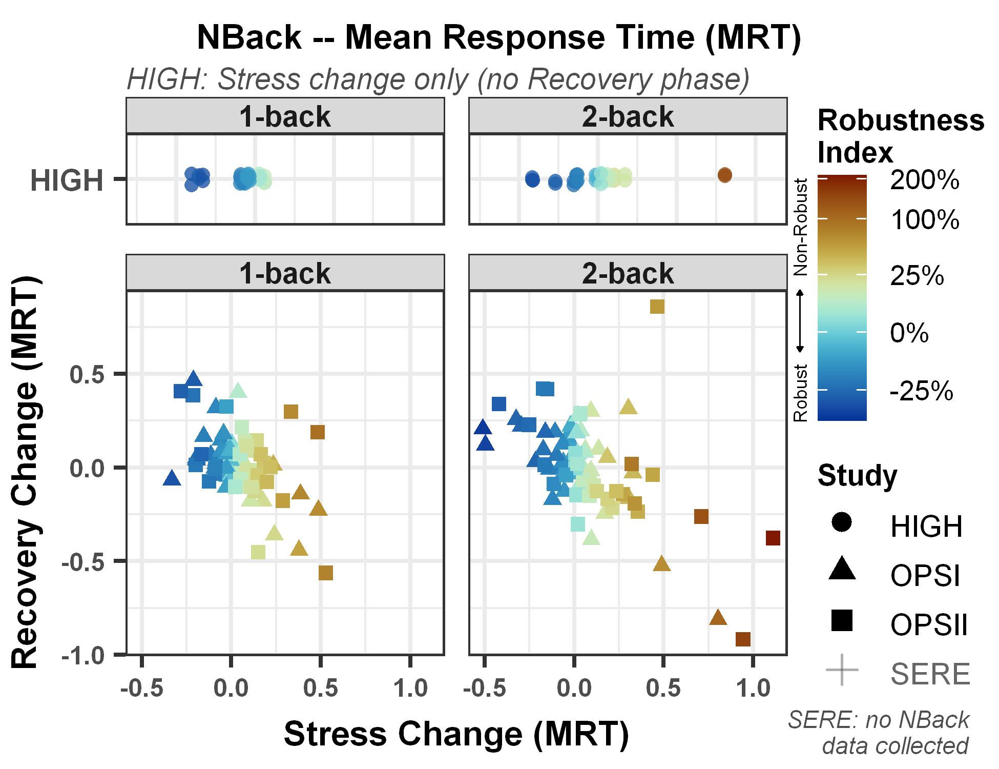

In [109]:
options(repr.plot.width=3.25, repr.plot.height=2.5, repr.plot.res=600)

study_levels <- c("HIGH", "OPSI", "OPSII", "SERE")

high_dat <- nback_all_avg_data %>%
  filter(study == "HIGH", !is.na(delta_stress_mrt)) %>%
  mutate(study = factor(study, levels = study_levels))

recovery_dat <- nback_all_avg_data %>%
  filter(study != "HIGH", !is.na(delta_stress_mrt), !is.na(delta_recovery_mrt)) %>%
  mutate(study = factor(study, levels = study_levels))

study_legend_dat <- tibble::tibble(study = factor(c("HIGH", "OPSI", "OPSII", "SERE"), levels = study_levels),x = 0,y = 0)

x_lims <- range(nback_all_avg_data$delta_stress_mrt, na.rm = TRUE)
rob_lims <- range(nback_all_avg_data$Robustness_mrt[is.finite(nback_all_avg_data$Robustness_mrt)], na.rm = TRUE)

trans_obj <- pseudolog10_trans

rob_lims_t <- trans_obj$transform(rob_lims)
zero_t     <- trans_obj$transform(0)

zero_pos <- scales::rescale(
  zero_t,
  from = rob_lims_t,
  to = c(0, 1)
)

pal_vals <- seq(rob_lims[1], rob_lims[2], length.out = 256)

pal_pos <- ifelse(
  pal_vals <= 0,
  scales::rescale(pal_vals, from = c(rob_lims[1], 0), to = c(0, 0.5)),
  scales::rescale(pal_vals, from = c(0, rob_lims[2]), to = c(0.5, 1))
)

high_plot <- ggplot(high_dat,
                    aes(x = delta_stress_mrt,
                        y = study,
                        shape = study,
                        color = Robustness_mrt
                       )
                   ) +
    labs(x = NULL,
         y = NULL,
         subtitle = "HIGH: Stress change only (no Recovery phase)"
        ) +
    geom_point(size = 1.25, alpha = 0.8, position = position_jitter(height = 0.08)) +
    facet_grid(. ~ SessBlockID,labeller = labeller(SessBlockID = c("1"="1-back","2"="2-back"))) +
    scale_color_scico(palette = "roma",
                      trans = ssqrt_trans%of% pseudolog10_trans,
                      labels = label_percent(),
                      limits = rob_lims,
                      direction = -1
                     ) +
    scale_x_continuous(limits = x_lims
                      ) +
    #scale_y_discrete(
    #  labels = c(
    #    "HIGH" = "HIGH\n(No Recovery Phase)"
    #  )) +
    theme_bw() +
    theme(text = element_text(size = 8, face = "bold"),
          plot.title = element_text(size = 7, hjust = 0),
          plot.subtitle = element_text(size = 7, face = "italic", color="gray30", hjust = 0, vjust = 0,margin = margin(0, 0, 2, 0)),
          axis.text.x = element_blank(),
          axis.ticks.x = element_blank(),
          axis.text.y = element_text(size = 7),
          strip.text = element_text(size = 7, margin = margin(t = 0.75, r = 0, b = 0.75, l = 0)),
          strip.background = element_rect(linewidth = 0.3),
          legend.position = "none",
          plot.margin = margin(0, 2, 2, 2)
         )

recovery_plot <- ggplot(recovery_dat,
                        aes(x = delta_stress_mrt,
                            y = delta_recovery_mrt,
                            group = interaction(study, subjectid),
                            shape = study,
                            color = Robustness_mrt
                           )
                       ) +
    #ggtitle("OPSI, OPSII, and SERE: Stress and Recovery change") +
    labs(x = "Stress Change (MRT)",
         y = "Recovery Change (MRT)",
         shape = "Study",
         color = "Robustness\nIndex", #"Stress\n%Δ of BL",#"Stress\nDelta",
         #subtitle = "OPSI, OPSII, and SERE: Stress and Recovery change"
        ) +
    geom_point(size = 1.25, alpha = 0.8) +
    geom_point(data = study_legend_dat,
               aes(x = x, y = y, shape = study),
               inherit.aes = FALSE,
               color = "black",
               alpha = 0,
               size = 2,
               show.legend = TRUE
              ) +
    facet_grid(. ~ SessBlockID,labeller = labeller(SessBlockID = c("1"="1-back","2"="2-back"))) +
    scale_color_scico(palette = "roma",
                      trans = ssqrt_trans%of% pseudolog10_trans,
                      labels = label_percent(),
                      limits = rob_lims,
                      breaks = c(-0.25, 0, 0.25, 1, 2),
                      direction = -1
                     ) +
    #scale_color_gradientn(colours = scico::scico(256, palette = "roma", direction = -1),
    #                      values = c(0, zero_pos / 2, zero_pos, zero_pos + (1 - zero_pos) / 2, 1), #pal_pos,
    #                      limits = rob_lims,
    #                      trans = pseudolog10_trans,
    #                      breaks = c(0, 3, 6, 9),
    #                      labels = scales::label_percent(),
    #                      name = "Stress\n%Δ of BL"
    #                     ) +
    #scale_x_continuous(limits = x_lims
    #                  ) +
    scale_y_continuous(breaks = c(-1, -0.5, 0, 0.5, 1)
                      ) +
    scale_shape_manual(values = c("HIGH"  = 16,
                                  "OPSI"  = 17,
                                  "OPSII" = 15,
                                  "SERE"  = 3
                                 ),
                       limits = c("HIGH", "OPSI", "OPSII", "SERE"),
                       breaks = c("HIGH", "OPSI", "OPSII", "SERE"),
                       labels = c("HIGH",
                                  "OPSI",
                                  "OPSII",
                                  "<span style='color:grey40;'>SERE</span>"
                                 ),
                       drop = FALSE
                      ) +
    guides(color = guide_colorbar(order = 1),
           shape = guide_legend(order = 2,
                                label.theme = ggtext::element_markdown(size = 7, face = "plain", vjust=0.3),
                                override.aes = list(shape = c(16, 17, 15, 3),
                                                    #color = "black",
                                                    color = c("black", "black", "black", "grey30"),
                                                    alpha = c(1, 1, 1, 0.45),
                                                    size = 2
                                                    #alpha = 1
                                                   ))
          ) +
    theme_bw() +
    theme(text = element_text(size = 8, face = "bold"),
          plot.title = element_text(size = 7, hjust = 0),
          plot.subtitle = element_text(size = 5, face = "bold", hjust = 0, vjust = 0.1),
          axis.text.x = element_text(size = 6),
          axis.title.x = element_text(size = 8, margin = margin(3, 0, -5, 0)),
          axis.text.y = element_text(size = 6, margin = margin(0, 2, 0, 0)),
          axis.title.y = element_text(size = 8, margin = margin(0, -5, 0, -5)),
          strip.text = element_text(size = 7, margin = margin(t = 0.75, r = 0, b = 0.75, l = 0)),
          strip.background = element_rect(linewidth = 0.3),
          legend.text = element_text(size = 6.5, face = "plain"),
          legend.title = element_text(size = 7, margin = margin(0, 0, 2, 0)),
          legend.position = "right",
          legend.box = "vertical",
          legend.justification = c(0.0, 0.21),
          legend.box.just = "left",
          legend.key.size = unit(0.8, "lines"),
          legend.margin = margin(-5, -2, 0, -2),
          legend.box.margin = margin(-5, -2, 0, -2),
          legend.spacing = unit(0, "pt"),
          legend.spacing.y = unit(14, "pt"),
          plot.margin = margin(2, 2, 2, 2)
         )

# 1. Create a grob or a blank ggplot containing your text
##Better/Worse text only separated by spaces
#text_box <- ggplot() + 
#    annotate("text", x = 0.5, y = 0.5, hjust=0.5,vjust=0.5,color="white",angle=90, label = "Better               Worse", size = 2) +
#    coord_cartesian(xlim = c(0, 1),
#                    ylim = c(0, 1),
#                    clip = "off") +
#    theme_void() +
#    theme(plot.margin = margin(0, 0, 0, 0))
##Individual words with an arrow
text_box <- ggplot() + 
    annotate("segment",
             x = 0.35,
             xend = 0.35,
             y = 0.29,
             yend = 0.78,
             arrow = arrow(ends = "both", type="closed", length = unit(0.02, "inches")),
             linewidth = 0.2,
             color = "black") +
    annotate("text",
             x = 0.35,
             y = 0.19,
             hjust = 1.0,
             vjust = 0.5,
             color = "black",
             angle = 90,
             label = "Robust",
             size = 1.5) +
    annotate("text",
             x = 0.35,
             y = 0.88,
             hjust = 0.0,
             vjust = 0.5,
             color = "black",
             angle = 90,
             label = "Non-Robust",
             size = 1.5) +
    coord_cartesian(xlim = c(0, 1),
                    ylim = c(0, 1),
                    clip = "off") +
    theme_void() +
    theme(plot.margin = margin(0, 0, 0, 0))

sere_note <- ggplot() +
    annotate("text",
             x = 1.11,
             y = 0.00,
             label = "SERE: no NBack\ndata collected",
             hjust = 0.98,
             vjust = 0.5,
             size = 2.0,
             color = "gray30",
             fontface = "italic",
             lineheight = 0.9
            ) +
    coord_cartesian(xlim = c(0, 1), 
                    ylim = c(0, 1), 
                    clip = "off") +
    theme_void() +
    theme(plot.margin = ggplot2::margin(0, 0, 0, 0))

nback_all_scat_plot_mrt <- high_plot / recovery_plot +
    plot_layout(heights = c(1, 4)) +
    plot_annotation(title = "NBack -- Mean Response Time (MRT)",
                    theme = theme(plot.title = element_text(size = 8, face = "bold", hjust = 0.5))
                   ) +
    inset_element(text_box, 
                  left = 0.71, bottom = 0.7, right = 1, top = 0.98, 
                  align_to = "full",
                  clip = FALSE) +
    inset_element(sere_note,
                  left = 0.8,
                  bottom = 0.02,
                  right = 0.98,
                  top = 0.18,
                  align_to = "full",
                  clip = FALSE)

nback_all_scat_plot_mrt

In [110]:
ggsave("nback_mrt.png", nback_all_scat_plot_mrt, width = 3.25, height = 2.5, dpi = 600)

### Mean Reciprocal Response Time (MRRT)

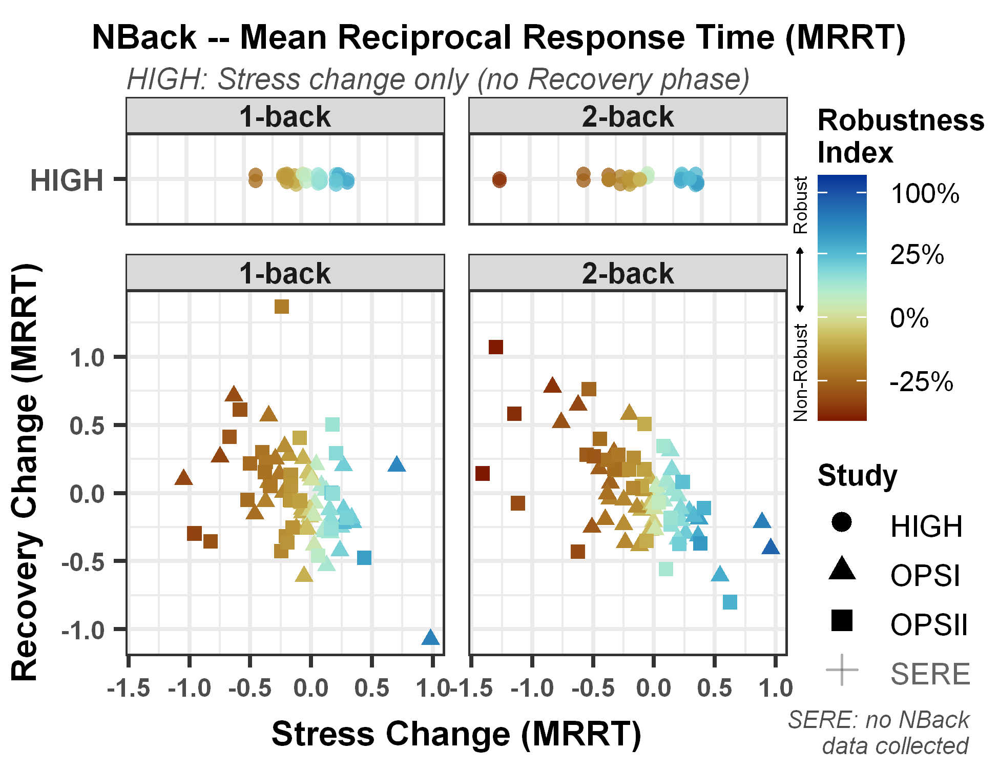

In [114]:
options(repr.plot.width=3.25, repr.plot.height=2.5, repr.plot.res=600)

study_levels <- c("HIGH", "OPSI", "OPSII", "SERE")

high_dat <- nback_all_avg_data %>%
  filter(study == "HIGH", !is.na(delta_stress_mrrt)) %>%
  mutate(study = factor(study, levels = study_levels))

recovery_dat <- nback_all_avg_data %>%
  filter(study != "HIGH", !is.na(delta_stress_mrrt), !is.na(delta_recovery_mrrt)) %>%
  mutate(study = factor(study, levels = study_levels))

study_legend_dat <- tibble::tibble(study = factor(c("HIGH", "OPSI", "OPSII", "SERE"), levels = study_levels),x = 0,y = 0)

x_lims <- range(nback_all_avg_data$delta_stress_mrrt, na.rm = TRUE)
rob_lims <- range(nback_all_avg_data$Robustness_mrrt[is.finite(nback_all_avg_data$Robustness_mrrt)], na.rm = TRUE)

trans_obj <- pseudolog10_trans

rob_lims_t <- trans_obj$transform(rob_lims)
zero_t     <- trans_obj$transform(0)

zero_pos <- scales::rescale(
  zero_t,
  from = rob_lims_t,
  to = c(0, 1)
)

pal_vals <- seq(rob_lims[1], rob_lims[2], length.out = 256)

pal_pos <- ifelse(
  pal_vals <= 0,
  scales::rescale(pal_vals, from = c(rob_lims[1], 0), to = c(0, 0.5)),
  scales::rescale(pal_vals, from = c(0, rob_lims[2]), to = c(0.5, 1))
)

high_plot <- ggplot(high_dat,
                    aes(x = delta_stress_mrrt,
                        y = study,
                        shape = study,
                        color = Robustness_mrrt
                       )
                   ) +
    labs(x = NULL,
         y = NULL,
         subtitle = "HIGH: Stress change only (no Recovery phase)"
        ) +
    geom_point(size = 1.25, alpha = 0.8, position = position_jitter(height = 0.08)) +
    facet_grid(. ~ SessBlockID,labeller = labeller(SessBlockID = c("1"="1-back","2"="2-back"))) +
    scale_color_scico(palette = "roma",
                      trans = ssqrt_trans%of% pseudolog10_trans,
                      labels = label_percent(),
                      limits = rob_lims,
                     ) +
    scale_x_continuous(limits = x_lims
                      ) +
    #scale_y_discrete(
    #  labels = c(
    #    "HIGH" = "HIGH\n(No Recovery Phase)"
    #  )) +
    theme_bw() +
    theme(text = element_text(size = 8, face = "bold"),
          plot.title = element_text(size = 7, hjust = 0),
          plot.subtitle = element_text(size = 7, face = "italic", color="gray30", hjust = 0, vjust = 0,margin = margin(0, 0, 2, 0)),
          axis.text.x = element_blank(),
          axis.ticks.x = element_blank(),
          axis.text.y = element_text(size = 7),
          strip.text = element_text(size = 7, margin = margin(t = 0.75, r = 0, b = 0.75, l = 0)),
          strip.background = element_rect(linewidth = 0.3),
          legend.position = "none",
          plot.margin = margin(0, 2, 2, 2)
         )

recovery_plot <- ggplot(recovery_dat,
                        aes(x = delta_stress_mrrt,
                            y = delta_recovery_mrrt,
                            group = interaction(study, subjectid),
                            shape = study,
                            color = Robustness_mrrt
                           )
                       ) +
    #ggtitle("OPSI, OPSII, and SERE: Stress and Recovery change") +
    labs(x = "Stress Change (MRRT)",
         y = "Recovery Change (MRRT)",
         shape = "Study",
         color = "Robustness\nIndex", #"Stress\n%Δ of BL",#"Stress\nDelta",
         #subtitle = "OPSI, OPSII, and SERE: Stress and Recovery change"
        ) +
    geom_point(size = 1.25, alpha = 0.8) +
    geom_point(data = study_legend_dat,
               aes(x = x, y = y, shape = study),
               inherit.aes = FALSE,
               color = "black",
               alpha = 0,
               size = 2,
               show.legend = TRUE
              ) +
    facet_grid(. ~ SessBlockID,labeller = labeller(SessBlockID = c("1"="1-back","2"="2-back"))) +
    scale_color_scico(palette = "roma",
                      trans = ssqrt_trans%of% pseudolog10_trans,
                      labels = label_percent(),
                      limits = rob_lims,
                      breaks = c(-0.25, 0, 0.25, 1)
                     ) +
    #scale_color_gradientn(colours = scico::scico(256, palette = "roma", direction = -1),
    #                      values = c(0, zero_pos / 2, zero_pos, zero_pos + (1 - zero_pos) / 2, 1), #pal_pos,
    #                      limits = rob_lims,
    #                      trans = pseudolog10_trans,
    #                      breaks = c(0, 3, 6, 9),
    #                      labels = scales::label_percent(),
    #                      name = "Stress\n%Δ of BL"
    #                     ) +
    #scale_x_continuous(limits = x_lims
    #                  ) +
    #scale_y_continuous(breaks = c(-0.5, 0, 0.5)
    #                  ) +
    scale_shape_manual(values = c("HIGH"  = 16,
                                  "OPSI"  = 17,
                                  "OPSII" = 15,
                                  "SERE"  = 3
                                 ),
                       limits = c("HIGH", "OPSI", "OPSII", "SERE"),
                       breaks = c("HIGH", "OPSI", "OPSII", "SERE"),
                       labels = c("HIGH",
                                  "OPSI",
                                  "OPSII",
                                  "<span style='color:grey40;'>SERE</span>"
                                 ),
                       drop = FALSE
                      ) +
    guides(color = guide_colorbar(order = 1),
           shape = guide_legend(order = 2,
                                label.theme = ggtext::element_markdown(size = 7, face = "plain", vjust = 0.3),
                                override.aes = list(shape = c(16, 17, 15, 3),
                                                    #color = "black",
                                                    color = c("black", "black", "black", "grey30"),
                                                    alpha = c(1, 1, 1, 0.45),
                                                    size = 2
                                                    #alpha = 1
                                                   ))
          ) +
    theme_bw() +
    theme(text = element_text(size = 8, face = "bold"),
          plot.title = element_text(size = 7, hjust = 0),
          plot.subtitle = element_text(size = 5, face = "bold", hjust = 0, vjust = 0.1),
          axis.text.x = element_text(size = 6),
          axis.title.x = element_text(size = 8, margin = margin(3, 0, -5, 0)),
          axis.text.y = element_text(size = 6, margin = margin(0, 2, 0, 0)),
          axis.title.y = element_text(size = 8, margin = margin(0, -5, 0, -5)),
          strip.text = element_text(size = 7, margin = margin(t = 0.75, r = 0, b = 0.75, l = 0)),
          strip.background = element_rect(linewidth = 0.3),
          legend.text = element_text(size = 6.5, face = "plain"),
          legend.title = element_text(size = 7, margin = margin(0, 0, 2, 0)),
          legend.position = "right",
          legend.box = "vertical",
          legend.justification = c(0.0, 0.21),
          legend.box.just = "left",
          legend.key.size = unit(0.8, "lines"),
          legend.margin = margin(-5, -2, 0, -2),
          legend.box.margin = margin(-5, -2, 0, -2),
          legend.spacing = unit(0, "pt"),
          legend.spacing.y = unit(14, "pt"),
          plot.margin = margin(2, 2, 2, 2)
         )

# 1. Create a grob or a blank ggplot containing your text
##Better/Worse text only separated by spaces
#text_box <- ggplot() + 
#    annotate("text", x = 0.5, y = 0.5, hjust=0.5,vjust=0.5,color="white",angle=90, label = "Better               Worse", size = 2) +
#    coord_cartesian(xlim = c(0, 1),
#                    ylim = c(0, 1),
#                    clip = "off") +
#    theme_void() +
#    theme(plot.margin = margin(0, 0, 0, 0))
##Individual words with an arrow
text_box <- ggplot() + 
    annotate("segment",
             x = 0.35,
             xend = 0.35,
             y = 0.61,
             yend = 1.11,
             arrow = arrow(ends = "both", type="closed", length = unit(0.02, "inches")),
             linewidth = 0.2,
             color = "black") +
    annotate("text",
             x = 0.35,
             y = 0.51,
             hjust = 1.0,
             vjust = 0.5,
             color = "black",
             angle = 90,
             label = "Non-Robust",
             size = 1.5) +
    annotate("text",
             x = 0.35,
             y = 1.21,
             hjust = 0.0,
             vjust = 0.5,
             color = "black",
             angle = 90,
             label = "Robust",
             size = 1.5) +
    coord_cartesian(xlim = c(0, 1),
                    ylim = c(0, 1),
                    clip = "off") +
    theme_void() +
    theme(plot.margin = margin(0, 0, 0, 0))

sere_note <- ggplot() +
    annotate("text",
             x = 1.11,
             y = 0.00,
             label = "SERE: no NBack\ndata collected",
             hjust = 0.98,
             vjust = 0.5,
             size = 2.0,
             color = "gray30",
             fontface = "italic",
             lineheight = 0.9
            ) +
    coord_cartesian(xlim = c(0, 1), 
                    ylim = c(0, 1), 
                    clip = "off") +
    theme_void() +
    theme(plot.margin = ggplot2::margin(0, 0, 0, 0))

nback_all_scat_plot_mrrt <- high_plot / recovery_plot +
    plot_layout(heights = c(1, 4)) +
    plot_annotation(title = "NBack -- Mean Reciprocal Response Time (MRRT)",
                    theme = theme(plot.title = element_text(size = 8, face = "bold", hjust = 0.5))
                   ) +
    inset_element(text_box, 
                  left = 0.71, bottom = 0.7, right = 1, top = 0.98, 
                  align_to = "full",
                  clip = FALSE) +
    inset_element(sere_note,
                  left = 0.8,
                  bottom = 0.02,
                  right = 0.98,
                  top = 0.18,
                  align_to = "full",
                  clip = FALSE)

nback_all_scat_plot_mrrt

In [115]:
ggsave("nback_mrrt.png", nback_all_scat_plot_mrrt, width = 3.25, height = 2.5, dpi = 600)

### D-prime

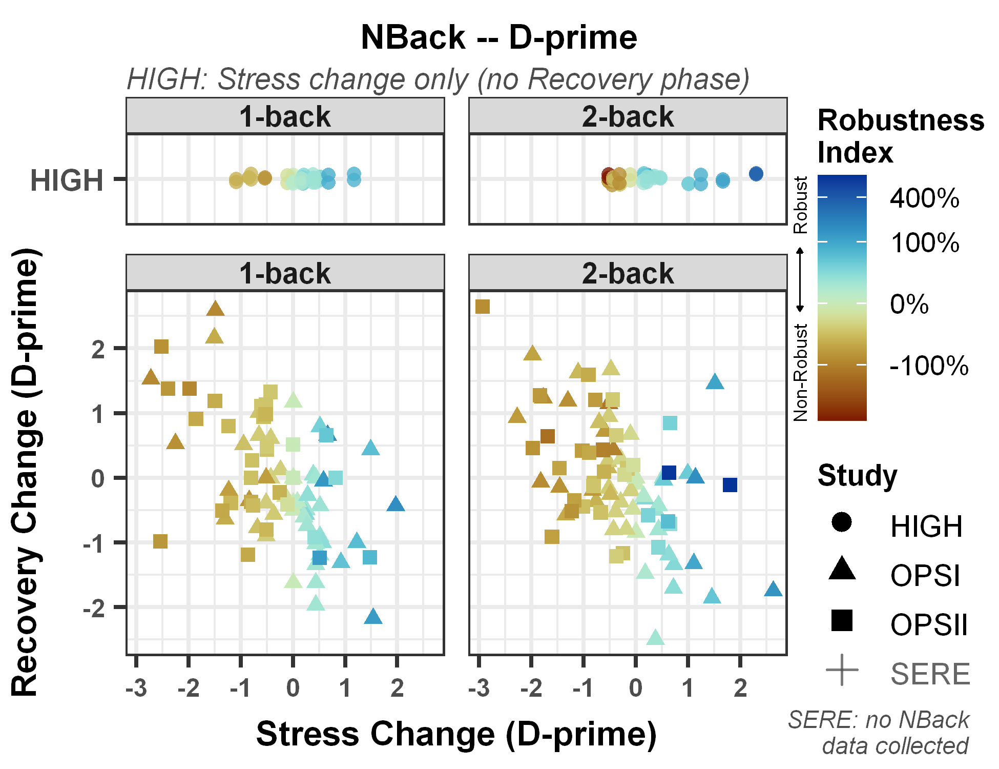

In [116]:
options(repr.plot.width=3.25, repr.plot.height=2.5, repr.plot.res=600)

study_levels <- c("HIGH", "OPSI", "OPSII", "SERE")

high_dat <- nback_all_avg_data %>%
  filter(study == "HIGH", !is.na(delta_stress_dprime)) %>%
  mutate(study = factor(study, levels = study_levels))

recovery_dat <- nback_all_avg_data %>%
  filter(study != "HIGH", !is.na(delta_stress_dprime), !is.na(delta_recovery_dprime)) %>%
  mutate(study = factor(study, levels = study_levels))

study_legend_dat <- tibble::tibble(study = factor(c("HIGH", "OPSI", "OPSII", "SERE"), levels = study_levels),x = 0,y = 0)

x_lims <- range(nback_all_avg_data$delta_stress_dprime, na.rm = TRUE)
rob_lims <- range(nback_all_avg_data$Robustness_dprime[is.finite(nback_all_avg_data$Robustness_dprime)], na.rm = TRUE)

trans_obj <- pseudolog10_trans

rob_lims_t <- trans_obj$transform(rob_lims)
zero_t     <- trans_obj$transform(0)

zero_pos <- scales::rescale(
  zero_t,
  from = rob_lims_t,
  to = c(0, 1)
)

pal_vals <- seq(rob_lims[1], rob_lims[2], length.out = 256)

pal_pos <- ifelse(
  pal_vals <= 0,
  scales::rescale(pal_vals, from = c(rob_lims[1], 0), to = c(0, 0.5)),
  scales::rescale(pal_vals, from = c(0, rob_lims[2]), to = c(0.5, 1))
)

high_plot <- ggplot(high_dat,
                    aes(x = delta_stress_dprime,
                        y = study,
                        shape = study,
                        color = Robustness_dprime
                       )
                   ) +
    labs(x = NULL,
         y = NULL,
         subtitle = "HIGH: Stress change only (no Recovery phase)"
        ) +
    geom_point(size = 1.25, alpha = 0.8, position = position_jitter(height = 0.08)) +
    facet_grid(. ~ SessBlockID,labeller = labeller(SessBlockID = c("1"="1-back","2"="2-back"))) +
    scale_color_scico(palette = "roma",
                      trans = ssqrt_trans%of% pseudolog10_trans,
                      labels = label_percent(),
                      limits = rob_lims,
                     ) +
    scale_x_continuous(limits = x_lims
                      ) +
    #scale_y_discrete(
    #  labels = c(
    #    "HIGH" = "HIGH\n(No Recovery Phase)"
    #  )) +
    theme_bw() +
    theme(text = element_text(size = 8, face = "bold"),
          plot.title = element_text(size = 7, hjust = 0),
          plot.subtitle = element_text(size = 7, face = "italic", color="gray30", hjust = 0, vjust = 0,margin = margin(0, 0, 2, 0)),
          axis.text.x = element_blank(),
          axis.ticks.x = element_blank(),
          axis.text.y = element_text(size = 7),
          strip.text = element_text(size = 7, margin = margin(t = 0.75, r = 0, b = 0.75, l = 0)),
          strip.background = element_rect(linewidth = 0.3),
          legend.position = "none",
          plot.margin = margin(0, 2, 2, 2)
         )

recovery_plot <- ggplot(recovery_dat,
                        aes(x = delta_stress_dprime,
                            y = delta_recovery_dprime,
                            group = interaction(study, subjectid),
                            shape = study,
                            color = Robustness_dprime
                           )
                       ) +
    #ggtitle("OPSI, OPSII, and SERE: Stress and Recovery change") +
    labs(x = "Stress Change (D-prime)",
         y = "Recovery Change (D-prime)",
         shape = "Study",
         color = "Robustness\nIndex", #"Stress\n%Δ of BL",#"Stress\nDelta",
         #subtitle = "OPSI, OPSII, and SERE: Stress and Recovery change"
        ) +
    geom_point(size = 1.25, alpha = 0.8) +
    geom_point(data = study_legend_dat,
               aes(x = x, y = y, shape = study),
               inherit.aes = FALSE,
               color = "black",
               alpha = 0,
               size = 2,
               show.legend = TRUE
              ) +
    facet_grid(. ~ SessBlockID,labeller = labeller(SessBlockID = c("1"="1-back","2"="2-back"))) +
    scale_color_scico(palette = "roma",
                      trans = ssqrt_trans%of% pseudolog10_trans,
                      labels = label_percent(),
                      limits = rob_lims,
                      breaks=c(-1,0,1,4)
                     ) +
    #scale_color_gradientn(colours = scico::scico(256, palette = "roma", direction = -1),
    #                      values = c(0, zero_pos / 2, zero_pos, zero_pos + (1 - zero_pos) / 2, 1), #pal_pos,
    #                      limits = rob_lims,
    #                      trans = pseudolog10_trans,
    #                      breaks = c(0, 3, 6, 9),
    #                      labels = scales::label_percent(),
    #                      name = "Stress\n%Δ of BL"
    #                     ) +
    #scale_x_continuous(limits = x_lims
    #                  ) +
    #scale_y_continuous(breaks = c(-0.5, 0, 0.5)
    #                  ) +
    scale_shape_manual(values = c("HIGH"  = 16,
                                  "OPSI"  = 17,
                                  "OPSII" = 15,
                                  "SERE"  = 3
                                 ),
                       limits = c("HIGH", "OPSI", "OPSII", "SERE"),
                       breaks = c("HIGH", "OPSI", "OPSII", "SERE"),
                       labels = c("HIGH",
                                  "OPSI",
                                  "OPSII",
                                  "<span style='color:grey40;'>SERE</span>"
                                 ),
                       drop = FALSE
                      ) +
    guides(color = guide_colorbar(order = 1),
           shape = guide_legend(order = 2,
                                label.theme = ggtext::element_markdown(size = 7, face = "plain", vjust = 0.3),
                                override.aes = list(shape = c(16, 17, 15, 3),
                                                    #color = "black",
                                                    color = c("black", "black", "black", "grey30"),
                                                    alpha = c(1, 1, 1, 0.75),
                                                    size = 2
                                                    #alpha = 1
                                                   ))
          ) +
    theme_bw() +
    theme(text = element_text(size = 8, face = "bold"),
          plot.title = element_text(size = 7, hjust = 0),
          plot.subtitle = element_text(size = 5, face = "bold", hjust = 0, vjust = 0.1),
          axis.text.x = element_text(size = 6),
          axis.title.x = element_text(size = 8, margin = margin(3, 0, -5, 0)),
          axis.text.y = element_text(size = 6, margin = margin(0, 2, 0, 0)),
          axis.title.y = element_text(size = 8, margin = margin(0, -5, 0, -5)),
          strip.text = element_text(size = 7, margin = margin(t = 0.75, r = 0, b = 0.75, l = 0)),
          strip.background = element_rect(linewidth = 0.3),
          legend.text = element_text(size = 6.5, face = "plain"),
          legend.title = element_text(size = 7, margin = margin(0, 0, 2, 0)),
          legend.position = "right",
          legend.box = "vertical",
          legend.justification = c(0.0, 0.21),
          legend.box.just = "left",
          legend.key.size = unit(0.8, "lines"),
          legend.margin = margin(-5, -2, 0, -2),
          legend.box.margin = margin(-5, -2, 0, -2),
          legend.spacing = unit(0, "pt"),
          legend.spacing.y = unit(14, "pt"),
          plot.margin = margin(2, 2, 2, 2)
         )

# 1. Create a grob or a blank ggplot containing your text
##Better/Worse text only separated by spaces
#text_box <- ggplot() + 
#    annotate("text", x = 0.5, y = 0.5, hjust=0.5,vjust=0.5,color="white",angle=90, label = "Better               Worse", size = 2) +
#    coord_cartesian(xlim = c(0, 1),
#                    ylim = c(0, 1),
#                    clip = "off") +
#    theme_void() +
#    theme(plot.margin = margin(0, 0, 0, 0))
##Individual words with an arrow
text_box <- ggplot() + 
    annotate("segment",
             x = 0.35,
             xend = 0.35,
             y = 0.61,
             yend = 1.11,
             arrow = arrow(ends = "both", type="closed", length = unit(0.02, "inches")),
             linewidth = 0.2,
             color = "black") +
    annotate("text",
             x = 0.35,
             y = 0.51,
             hjust = 1.0,
             vjust = 0.5,
             color = "black",
             angle = 90,
             label = "Non-Robust",
             size = 1.5) +
    annotate("text",
             x = 0.35,
             y = 1.21,
             hjust = 0.0,
             vjust = 0.5,
             color = "black",
             angle = 90,
             label = "Robust",
             size = 1.5) +
    coord_cartesian(xlim = c(0, 1),
                    ylim = c(0, 1),
                    clip = "off") +
    theme_void() +
    theme(plot.margin = margin(0, 0, 0, 0))

sere_note <- ggplot() +
    annotate("text",
             x = 1.11,
             y = 0.00,
             label = "SERE: no NBack\ndata collected",
             hjust = 0.98,
             vjust = 0.5,
             size = 2.0,
             color = "gray30",
             fontface = "italic",
             lineheight = 0.9
            ) +
    coord_cartesian(xlim = c(0, 1), 
                    ylim = c(0, 1), 
                    clip = "off") +
    theme_void() +
    theme(plot.margin = ggplot2::margin(0, 0, 0, 0))

nback_all_scat_plot_dprime <- high_plot / recovery_plot +
    plot_layout(heights = c(1, 4)) +
    plot_annotation(title = "NBack -- D-prime",
                    theme = theme(plot.title = element_text(size = 8, face = "bold", hjust = 0.5))
                   ) +
    inset_element(text_box, 
                  left = 0.71, bottom = 0.7, right = 1, top = 0.98, 
                  align_to = "full",
                  clip = FALSE) +
    inset_element(sere_note,
                  left = 0.8,
                  bottom = 0.02,
                  right = 0.98,
                  top = 0.18,
                  align_to = "full",
                  clip = FALSE)


nback_all_scat_plot_dprime

In [117]:
ggsave("nback_dprime.png", nback_all_scat_plot_dprime, width = 3.25, height = 2.5, dpi = 600)

## PVT

In [118]:
pvt_ops1_avg_data <- pvt_ops1_data_cleaned %>% group_by(subjectid) %>% filter(study_event_id%in%c("Day 13","Day 41","EOS")) %>% filter(n_distinct(phase) == 3) %>%
            group_by(study,subjectid,phase,study_event_id) %>%
            summarize(npresented = n(),
                      nvalid = sum(RecType=="V" & rt>=150),
                      validp = sum(RecType=="V" & rt>=150)/n(),
                      nfalsestart = sum(RecType=="FS" | (RecType=="V" & rt<150)),
                      nlapses = sum(RecType=="L"),
                      ntimeouts = sum(RecType=="T"),
                      nfslapse = sum(RecType=="FS" | (RecType=="V" & rt<150) | RecType=="L"),
                      nlapseto = sum(RecType=="L" | RecType=="T"),
                      ntotalerr = n() - sum(RecType=="V" & rt>=150),
                      mrtime = mean(rt[(RecType=="V" | RecType=="L") & rt>=150]),
                      variancert = sd(rt[(RecType=="V" | RecType=="L") & rt>=150]),
                      medianrt = quantile(rt[(RecType=="V" | RecType=="L") & rt>=150],0.5,type=1),
                      mrtimeslow10 = mean(rt[(RecType=="V" | RecType=="L") & rt>=quantile(rt[(RecType=="V" | RecType=="L") & rt>=150], 0.9)]),
                      mrtimefast10 = mean(rt[(RecType=="V" | RecType=="L") & rt>=150 & rt<=quantile(rt[(RecType=="V" | RecType=="L") & rt>=150], 0.1)]),
                      meanrrt = mean(1/(rt[(RecType=="V" | RecType=="L") & rt>=150]/1000)),
                      variancerrt = sd(1/(rt[(RecType=="V" | RecType=="L") & rt>=150]/1000)),
                      medianrrt = quantile(1/(rt[(RecType=="V" | RecType=="L") & rt>=150]/1000),0.5,type=1),
                      meanrrtslow10 = mean(1/(rt[(RecType=="V" | RecType=="L") & rt>=quantile(rt[(RecType=="V" | RecType=="L") & rt>=150], 0.9)]/1000)),
                      meanrrtfast10 = mean(1/(rt[(RecType=="V" | RecType=="L") & rt>=150 & rt<=quantile(rt[(RecType=="V" | RecType=="L") & rt>=150], 0.1)]/1000)),
                      )

#head(pvt_ops1_avg_data)

pvt_ops1_avg_data <- pvt_ops1_avg_data %>% group_by(study,subjectid, phase) %>%
                summarize(nfalsestart = mean(nfalsestart, na.rm=TRUE),
                          nlapses = mean(nlapses, na.rm=TRUE),
                          ntimeouts = mean(ntimeouts, na.rm=TRUE),
                          nfslapse = mean(nfslapse, na.rm=TRUE),
                          nlapseto = mean(nlapseto, na.rm=TRUE),
                          ntotalerr = mean(ntotalerr),
                          mrtime = mean(mrtime, na.rm=TRUE),
                          meanrrt = mean(meanrrt, na.rm=TRUE),
                          .groups = 'drop') %>%
                group_by(subjectid) %>%
                mutate(nfalsestart, nlapses, ntimeouts, nfslapse, nlapseto, ntotalerr, mrtime, meanrrt,
                       delta_stress_mrrt = (meanrrt[phase=="Stress"]-meanrrt[phase=="Baseline"]),
                       delta_recovery_mrrt = (meanrrt[phase=="Recovery"]-meanrrt[phase=="Stress"]),
                       Robustness_mrrt = (meanrrt[phase=="Stress"]-meanrrt[phase=="Baseline"])/abs(meanrrt[phase=="Baseline"]), 
                       Resilience_mrrt = (meanrrt[phase=="Recovery"]-meanrrt[phase=="Stress"])/abs(meanrrt[phase=="Baseline"]), #abs(meanrrt[phase=="Baseline"]-meanrrt[phase=="Stress"]),
                       delta_stress_fsl = (nfslapse[phase=="Stress"]-nfslapse[phase=="Baseline"]),
                       delta_recovery_fsl = (nfslapse[phase=="Recovery"]-nfslapse[phase=="Stress"]),
                       Robustness_fsl = (nfslapse[phase=="Stress"]-nfslapse[phase=="Baseline"])/abs(nfslapse[phase=="Baseline"]), 
                       Resilience_fsl = (nfslapse[phase=="Recovery"]-nfslapse[phase=="Stress"])/abs(nfslapse[phase=="Baseline"])) #abs(nfslapse[phase=="Baseline"]-nfslapse[phase=="Stress"]))

#head(pvt_ops1_avg_data)

pvt_ops2_avg_data <- pvt_ops2_data_cleaned %>% group_by(subjectid) %>% filter(study_event_id%in%c("6","22","38")) %>% filter(n_distinct(phase) == 3) %>%
            group_by(study,subjectid,phase,study_event_id) %>%
            summarize(npresented = n(),
                      nvalid = sum(RecType=="V" & rt>=150),
                      validp = sum(RecType=="V" & rt>=150)/n(),
                      nfalsestart = sum(RecType=="FS" | (RecType=="V" & rt<150)),
                      nlapses = sum(RecType=="L"),
                      ntimeouts = sum(RecType=="T"),
                      nfslapse = sum(RecType=="FS" | (RecType=="V" & rt<150) | RecType=="L"),
                      nlapseto = sum(RecType=="L" | RecType=="T"),
                      ntotalerr = n() - sum(RecType=="V" & rt>=150),
                      mrtime = mean(rt[(RecType=="V" | RecType=="L") & rt>=150]),
                      variancert = sd(rt[(RecType=="V" | RecType=="L") & rt>=150]),
                      medianrt = quantile(rt[(RecType=="V" | RecType=="L") & rt>=150],0.5,type=1),
                      mrtimeslow10 = mean(rt[(RecType=="V" | RecType=="L") & rt>=quantile(rt[(RecType=="V" | RecType=="L") & rt>=150], 0.9)]),
                      mrtimefast10 = mean(rt[(RecType=="V" | RecType=="L") & rt>=150 & rt<=quantile(rt[(RecType=="V" | RecType=="L") & rt>=150], 0.1)]),
                      meanrrt = mean(1/(rt[(RecType=="V" | RecType=="L") & rt>=150]/1000)),
                      variancerrt = sd(1/(rt[(RecType=="V" | RecType=="L") & rt>=150]/1000)),
                      medianrrt = quantile(1/(rt[(RecType=="V" | RecType=="L") & rt>=150]/1000),0.5,type=1),
                      meanrrtslow10 = mean(1/(rt[(RecType=="V" | RecType=="L") & rt>=quantile(rt[(RecType=="V" | RecType=="L") & rt>=150], 0.9)]/1000)),
                      meanrrtfast10 = mean(1/(rt[(RecType=="V" | RecType=="L") & rt>=150 & rt<=quantile(rt[(RecType=="V" | RecType=="L") & rt>=150], 0.1)]/1000)),
                      )

#head(pvt_ops2_avg_data)

pvt_ops2_avg_data <- pvt_ops2_avg_data %>% group_by(study,subjectid, phase) %>%
                summarize(nfalsestart = mean(nfalsestart, na.rm=TRUE),
                          nlapses = mean(nlapses, na.rm=TRUE),
                          ntimeouts = mean(ntimeouts, na.rm=TRUE),
                          nfslapse = mean(nfslapse, na.rm=TRUE),
                          nlapseto = mean(nlapseto, na.rm=TRUE),
                          ntotalerr = mean(ntotalerr),
                          mrtime = mean(mrtime, na.rm=TRUE),
                          meanrrt = mean(meanrrt, na.rm=TRUE),
                          .groups = 'drop') %>%
                group_by(subjectid) %>%
                mutate(nfalsestart, nlapses, ntimeouts, nfslapse, nlapseto, ntotalerr, mrtime, meanrrt,
                       delta_stress_mrrt = (meanrrt[phase=="Stress"]-meanrrt[phase=="Baseline"]),
                       delta_recovery_mrrt = (meanrrt[phase=="Recovery"]-meanrrt[phase=="Stress"]),
                       Robustness_mrrt = (meanrrt[phase=="Stress"]-meanrrt[phase=="Baseline"])/abs(meanrrt[phase=="Baseline"]), 
                       Resilience_mrrt = (meanrrt[phase=="Recovery"]-meanrrt[phase=="Stress"])/abs(meanrrt[phase=="Baseline"]), #abs(meanrrt[phase=="Baseline"]-meanrrt[phase=="Stress"]),
                       delta_stress_fsl = (nfslapse[phase=="Stress"]-nfslapse[phase=="Baseline"]),
                       delta_recovery_fsl = (nfslapse[phase=="Recovery"]-nfslapse[phase=="Stress"]),
                       Robustness_fsl = (nfslapse[phase=="Stress"]-nfslapse[phase=="Baseline"])/abs(nfslapse[phase=="Baseline"]), 
                       Resilience_fsl = (nfslapse[phase=="Recovery"]-nfslapse[phase=="Stress"])/abs(nfslapse[phase=="Baseline"])) #abs(nfslapse[phase=="Baseline"]-nfslapse[phase=="Stress"]))

#head(pvt_ops2_avg_data)

pvt_sere_avg_data <- pvt_sere_data_cleaned %>% group_by(subjectid) %>% filter(study_event_id%in%c("bt","pt","rt")) %>% filter(n_distinct(phase) == 3) %>%
            group_by(study,subjectid,phase,study_event_id) %>%
            summarize(npresented = n(),
                      nvalid = sum(RecType=="V" & rt>=150),
                      validp = sum(RecType=="V" & rt>=150)/n(),
                      nfalsestart = sum(RecType=="FS" | (RecType=="V" & rt<150)),
                      nlapses = sum(RecType=="L"),
                      ntimeouts = sum(RecType=="T"),
                      nfslapse = sum(RecType=="FS" | (RecType=="V" & rt<150) | RecType=="L"),
                      nlapseto = sum(RecType=="L" | RecType=="T"),
                      ntotalerr = n() - sum(RecType=="V" & rt>=150),
                      mrtime = mean(rt[(RecType=="V" | RecType=="L") & rt>=150]),
                      variancert = sd(rt[(RecType=="V" | RecType=="L") & rt>=150]),
                      medianrt = quantile(rt[(RecType=="V" | RecType=="L") & rt>=150],0.5,type=1),
                      mrtimeslow10 = mean(rt[(RecType=="V" | RecType=="L") & rt>=quantile(rt[(RecType=="V" | RecType=="L") & rt>=150], 0.9)]),
                      mrtimefast10 = mean(rt[(RecType=="V" | RecType=="L") & rt>=150 & rt<=quantile(rt[(RecType=="V" | RecType=="L") & rt>=150], 0.1)]),
                      meanrrt = mean(1/(rt[(RecType=="V" | RecType=="L") & rt>=150]/1000)),
                      variancerrt = sd(1/(rt[(RecType=="V" | RecType=="L") & rt>=150]/1000)),
                      medianrrt = quantile(1/(rt[(RecType=="V" | RecType=="L") & rt>=150]/1000),0.5,type=1),
                      meanrrtslow10 = mean(1/(rt[(RecType=="V" | RecType=="L") & rt>=quantile(rt[(RecType=="V" | RecType=="L") & rt>=150], 0.9)]/1000)),
                      meanrrtfast10 = mean(1/(rt[(RecType=="V" | RecType=="L") & rt>=150 & rt<=quantile(rt[(RecType=="V" | RecType=="L") & rt>=150], 0.1)]/1000)),
                      )

#head(pvt_sere_avg_data)

pvt_sere_avg_data <- pvt_sere_avg_data %>% group_by(study,subjectid, phase) %>%
                summarize(nfalsestart = mean(nfalsestart, na.rm=TRUE),
                          nlapses = mean(nlapses, na.rm=TRUE),
                          ntimeouts = mean(ntimeouts, na.rm=TRUE),
                          nfslapse = mean(nfslapse, na.rm=TRUE),
                          nlapseto = mean(nlapseto, na.rm=TRUE),
                          ntotalerr = mean(ntotalerr),
                          mrtime = mean(mrtime, na.rm=TRUE),
                          meanrrt = mean(meanrrt, na.rm=TRUE),
                          .groups = 'drop') %>%
                group_by(subjectid) %>%
                mutate(nfalsestart, nlapses, ntimeouts, nfslapse, nlapseto, ntotalerr, mrtime, meanrrt,
                       delta_stress_mrrt = (meanrrt[phase=="Stress"]-meanrrt[phase=="Baseline"]),
                       delta_recovery_mrrt = (meanrrt[phase=="Recovery"]-meanrrt[phase=="Stress"]),
                       Robustness_mrrt = (meanrrt[phase=="Stress"]-meanrrt[phase=="Baseline"])/abs(meanrrt[phase=="Baseline"]), 
                       Resilience_mrrt = (meanrrt[phase=="Recovery"]-meanrrt[phase=="Stress"])/abs(meanrrt[phase=="Baseline"]), #abs(meanrrt[phase=="Baseline"]-meanrrt[phase=="Stress"]),
                       delta_stress_fsl = (nfslapse[phase=="Stress"]-nfslapse[phase=="Baseline"]),
                       delta_recovery_fsl = (nfslapse[phase=="Recovery"]-nfslapse[phase=="Stress"]),
                       Robustness_fsl = (nfslapse[phase=="Stress"]-nfslapse[phase=="Baseline"])/abs(nfslapse[phase=="Baseline"]), 
                       Resilience_fsl = (nfslapse[phase=="Recovery"]-nfslapse[phase=="Stress"])/abs(nfslapse[phase=="Baseline"])) #abs(nfslapse[phase=="Baseline"]-nfslapse[phase=="Stress"]))

#head(pvt_sere_avg_data)

pvt_high_avg_data <- pvt_high_data_cleaned %>% group_by(subjectid) %>% filter(study_event_id%in%c("B1","A1","A2","A3")) %>% filter(n_distinct(phase) == 2) %>%
            group_by(study,subjectid,phase,study_event_id) %>%
            summarize(npresented = n(),
                      nvalid = sum(RecType=="V" & rt>=150),
                      validp = sum(RecType=="V" & rt>=150)/n(),
                      nfalsestart = sum(RecType=="FS" | (RecType=="V" & rt<150)),
                      nlapses = sum(RecType=="L"),
                      ntimeouts = sum(RecType=="T"),
                      nfslapse = sum(RecType=="FS" | (RecType=="V" & rt<150) | RecType=="L"),
                      nlapseto = sum(RecType=="L" | RecType=="T"),
                      ntotalerr = n() - sum(RecType=="V" & rt>=150),
                      mrtime = mean(rt[(RecType=="V" | RecType=="L") & rt>=150]),
                      variancert = sd(rt[(RecType=="V" | RecType=="L") & rt>=150]),
                      medianrt = quantile(rt[(RecType=="V" | RecType=="L") & rt>=150],0.5,type=1),
                      mrtimeslow10 = mean(rt[(RecType=="V" | RecType=="L") & rt>=quantile(rt[(RecType=="V" | RecType=="L") & rt>=150], 0.9)]),
                      mrtimefast10 = mean(rt[(RecType=="V" | RecType=="L") & rt>=150 & rt<=quantile(rt[(RecType=="V" | RecType=="L") & rt>=150], 0.1)]),
                      meanrrt = mean(1/(rt[(RecType=="V" | RecType=="L") & rt>=150]/1000)),
                      variancerrt = sd(1/(rt[(RecType=="V" | RecType=="L") & rt>=150]/1000)),
                      medianrrt = quantile(1/(rt[(RecType=="V" | RecType=="L") & rt>=150]/1000),0.5,type=1),
                      meanrrtslow10 = mean(1/(rt[(RecType=="V" | RecType=="L") & rt>=quantile(rt[(RecType=="V" | RecType=="L") & rt>=150], 0.9)]/1000)),
                      meanrrtfast10 = mean(1/(rt[(RecType=="V" | RecType=="L") & rt>=150 & rt<=quantile(rt[(RecType=="V" | RecType=="L") & rt>=150], 0.1)]/1000)),
                      )

#head(pvt_high_avg_data)

pvt_high_avg_data <- pvt_high_avg_data %>% group_by(study,subjectid, phase) %>%
                summarize(nfalsestart = mean(nfalsestart, na.rm=TRUE),
                          nlapses = mean(nlapses, na.rm=TRUE),
                          ntimeouts = mean(ntimeouts, na.rm=TRUE),
                          nfslapse = mean(nfslapse, na.rm=TRUE),
                          nlapseto = mean(nlapseto, na.rm=TRUE),
                          ntotalerr = mean(ntotalerr),
                          mrtime = mean(mrtime, na.rm=TRUE),
                          meanrrt = mean(meanrrt, na.rm=TRUE),
                          .groups = 'drop') %>%
                group_by(subjectid) %>%
                mutate(nfalsestart, nlapses, ntimeouts, nfslapse, nlapseto, ntotalerr, mrtime, meanrrt,
                       delta_stress_mrrt = (meanrrt[phase=="Stress"]-meanrrt[phase=="Baseline"]),
                       delta_recovery_mrrt = NA,
                       Robustness_mrrt = (meanrrt[phase=="Stress"]-meanrrt[phase=="Baseline"])/abs(meanrrt[phase=="Baseline"]), 
                       Resilience_mrrt = NA,
                       delta_stress_fsl = (nfslapse[phase=="Stress"]-nfslapse[phase=="Baseline"]),
                       delta_recovery_fsl = NA,
                       Robustness_fsl = (nfslapse[phase=="Stress"]-nfslapse[phase=="Baseline"])/abs(nfslapse[phase=="Baseline"]), 
                       Resilience_fsl = NA)

#head(pvt_high_avg_data)

pvt_all_avg_data <- rbind(pvt_ops1_avg_data,pvt_ops2_avg_data,pvt_sere_avg_data,pvt_high_avg_data)
pvt_all_avg_data$study = factor(pvt_all_avg_data$study, levels = c("HIGH","OPSI", "OPSII", "SERE"))
unique(pvt_all_avg_data$study)
head(pvt_all_avg_data)

`summarise()` has grouped output by 'study', 'subjectid', 'phase'. You can override using the `.groups` argument.
`summarise()` has grouped output by 'study', 'subjectid', 'phase'. You can override using the `.groups` argument.
`summarise()` has grouped output by 'study', 'subjectid', 'phase'. You can override using the `.groups` argument.
`summarise()` has grouped output by 'study', 'subjectid', 'phase'. You can override using the `.groups` argument.


[1] OPSI  OPSII SERE  HIGH 
Levels: HIGH OPSI OPSII SERE

study,subjectid,phase,nfalsestart,nlapses,ntimeouts,nfslapse,nlapseto,ntotalerr,mrtime,meanrrt,delta_stress_mrrt,delta_recovery_mrrt,Robustness_mrrt,Resilience_mrrt,delta_stress_fsl,delta_recovery_fsl,Robustness_fsl,Resilience_fsl
<fct>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
OPSI,ROP166,Baseline,1,41,24,42,65,94,507.4667,2.195648,-0.24080839,0.2043652,-0.10967531,0.09307738,17,-16,0.4047619,-0.3809524
OPSI,ROP166,Recovery,0,43,23,43,66,103,514.3007,2.159205,-0.24080839,0.2043652,-0.10967531,0.09307738,17,-16,0.4047619,-0.3809524
OPSI,ROP166,Stress,0,59,34,59,93,111,578.3280,1.954840,-0.24080839,0.2043652,-0.10967531,0.09307738,17,-16,0.4047619,-0.3809524
OPSI,ROP167,Baseline,0,3,0,3,3,7,344.1955,3.009092,-0.03107773,-0.2692449,-0.01032794,-0.08947713,-2,16,-0.6666667,5.3333333
OPSI,ROP167,Recovery,0,17,10,17,27,39,401.9325,2.708770,-0.03107773,-0.2692449,-0.01032794,-0.08947713,-2,16,-0.6666667,5.3333333
OPSI,ROP167,Stress,0,1,0,1,1,4,343.3427,2.978015,-0.03107773,-0.2692449,-0.01032794,-0.08947713,-2,16,-0.6666667,5.3333333


### Mean Reciprocal Response Time (MRRT)

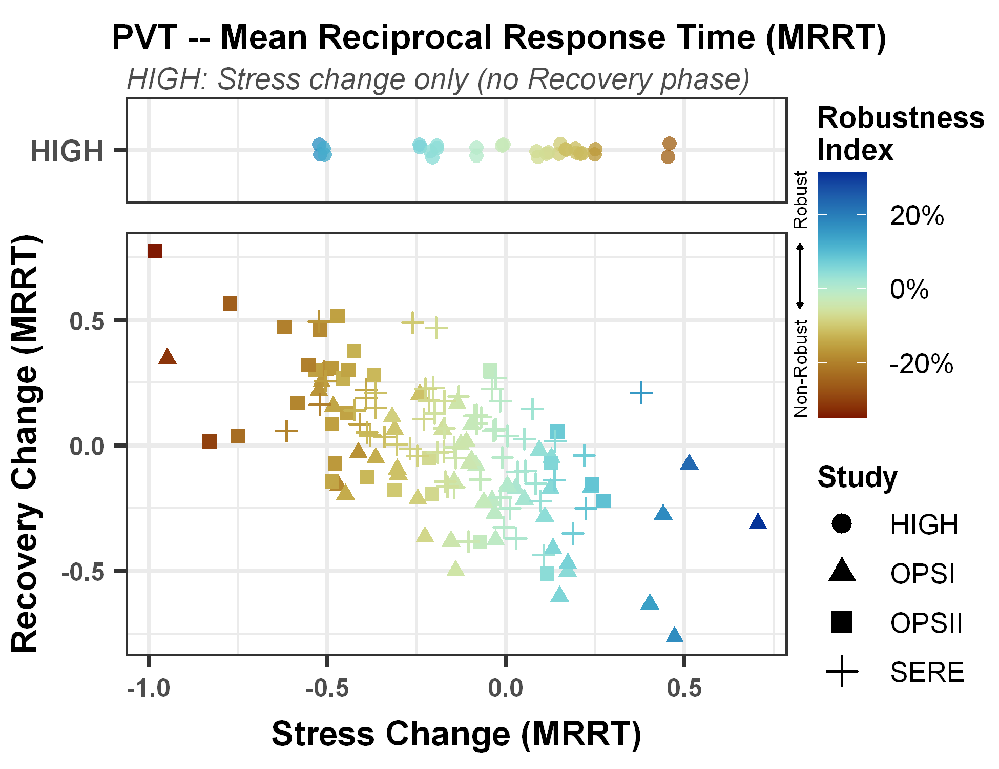

In [119]:
options(repr.plot.width=3.25, repr.plot.height=2.5, repr.plot.res=600)

study_levels <- c("HIGH", "OPSI", "OPSII", "SERE")

high_dat <- pvt_all_avg_data %>%
  filter(study == "HIGH", !is.na(delta_stress_mrrt)) %>%
  mutate(study = factor(study, levels = study_levels))

recovery_dat <- pvt_all_avg_data %>%
  filter(study != "HIGH", !is.na(delta_stress_mrrt), !is.na(delta_recovery_mrrt)) %>%
  mutate(study = factor(study, levels = study_levels))

study_legend_dat <- tibble::tibble(study = factor(c("HIGH", "OPSI", "OPSII", "SERE"), levels = study_levels),x = 0,y = 0)

x_lims <- range(pvt_all_avg_data$delta_stress_mrrt, na.rm = TRUE)
rob_lims <- range(pvt_all_avg_data$Robustness_mrrt[is.finite(pvt_all_avg_data$Robustness_mrrt)], na.rm = TRUE)

trans_obj <- pseudolog10_trans

rob_lims_t <- trans_obj$transform(rob_lims)
zero_t     <- trans_obj$transform(0)

zero_pos <- scales::rescale(
  zero_t,
  from = rob_lims_t,
  to = c(0, 1)
)

pal_vals <- seq(rob_lims[1], rob_lims[2], length.out = 256)

pal_pos <- ifelse(
  pal_vals <= 0,
  scales::rescale(pal_vals, from = c(rob_lims[1], 0), to = c(0, 0.5)),
  scales::rescale(pal_vals, from = c(0, rob_lims[2]), to = c(0.5, 1))
)

high_plot <- ggplot(high_dat,
                    aes(x = delta_stress_mrrt,
                        y = study,
                        shape = study,
                        color = Robustness_mrrt
                       )
                   ) +
    labs(x = NULL,
         y = NULL,
         subtitle = "HIGH: Stress change only (no Recovery phase)"
        ) +
    geom_point(size = 1.25, alpha = 0.8, position = position_jitter(height = 0.08)) +
    scale_color_scico(palette = "roma",
                      trans = pseudolog10_trans,
                      labels = label_percent(),
                      limits = rob_lims,
                      direction = -1) +
    scale_x_continuous(limits = x_lims
                      ) +
    #scale_y_discrete(
    #  labels = c(
    #    "HIGH" = "HIGH\n(No Recovery Phase)"
    #  )) +
    theme_bw() +
    theme(text = element_text(size = 8, face = "bold"),
          plot.title = element_text(size = 7, hjust = 0),
          plot.subtitle = element_text(size = 7, face = "italic", color="gray30", hjust = 0, vjust = 0,margin = margin(0, 0, 2, 0)),
          axis.text.x = element_blank(),
          axis.ticks.x = element_blank(),
          axis.text.y = element_text(size = 7),
          strip.text = element_text(size = 8,
                                    margin = margin(t = 1, r = 2, b = 1, l = 2)
                                   ),
          strip.background = element_rect(linewidth = 0.3),
          legend.position = "none",
          plot.margin = margin(0, 2, 2, 2)
         )

recovery_plot <- ggplot(recovery_dat,
                        aes(x = delta_stress_mrrt,
                            y = delta_recovery_mrrt,
                            group = interaction(study, subjectid),
                            shape = study,
                            color = Robustness_mrrt
                           )
                       ) +
    #ggtitle("OPSI, OPSII, and SERE: Stress and Recovery change") +
    labs(x = "Stress Change (MRRT)",
         y = "Recovery Change (MRRT)",
         shape = "Study",
         color = "Robustness\nIndex", #"Stress\n%Δ of BL",#"Stress\nDelta",
         #subtitle = "OPSI, OPSII, and SERE: Stress and Recovery change"
        ) +
    geom_point(size = 1.25, alpha = 0.8) +
    geom_point(data = study_legend_dat,
               aes(x = x, y = y, shape = study),
               inherit.aes = FALSE,
               color = "black",
               alpha = 0,
               size = 2,
               show.legend = TRUE
              ) +
    scale_color_scico(palette = "roma",
                      trans = pseudolog10_trans,
                      labels = label_percent(),
                      limits = rob_lims
                     ) +
    #scale_color_gradientn(colours = scico::scico(256, palette = "roma", direction = -1),
    #                      values = c(0, zero_pos / 2, zero_pos, zero_pos + (1 - zero_pos) / 2, 1), #pal_pos,
    #                      limits = rob_lims,
    #                      trans = pseudolog10_trans,
    #                      breaks = c(0, 3, 6, 9),
    #                      labels = scales::label_percent(),
    #                      name = "Stress\n%Δ of BL"
    #                     ) +
    #scale_x_continuous(limits = x_lims
    #                  ) +
    scale_y_continuous(breaks = c(-0.5, 0, 0.5)
                      ) +
    scale_shape_manual(values = c("HIGH"  = 16,
                                  "OPSI"  = 17,
                                  "OPSII" = 15,
                                  "SERE"  = 3
                                 ),
                       limits = c("HIGH", "OPSI", "OPSII", "SERE"),
                       breaks = c("HIGH", "OPSI", "OPSII", "SERE"),
                       drop = FALSE
                      ) +
    guides(color = guide_colorbar(order = 1),
           shape = guide_legend(order = 2, 
                                override.aes = list(shape = c(16, 17, 15, 3),
                                                    color = "black",
                                                    size = 2,
                                                    alpha = 1))
          ) +
    theme_bw() +
    theme(text = element_text(size = 8, face = "bold"),
          plot.title = element_text(size = 7, hjust = 0),
          plot.subtitle = element_text(size = 5, face = "bold", hjust = 0, vjust = 0.1),
          axis.text.x = element_text(size = 6),
          axis.title.x = element_text(size = 8, margin = margin(3, 0, -5, 0)),
          axis.text.y = element_text(size = 6, margin = margin(0, 2, 0, 0)),
          axis.title.y = element_text(size = 8, margin = margin(0, -5, 0, -5)),
          strip.text = element_text(size = 8,
                                    margin = margin(t = 1, r = 2, b = 1, l = 2)
                                   ),
          strip.background = element_rect(linewidth = 0.3),
          legend.text = element_text(size = 6.5, face = "plain"),
          legend.title = element_text(size = 7, margin = margin(0, 0, 2, 0)),
          legend.position = "right",
          legend.box = "vertical",
          legend.justification = c(0.0, 0.31),
          #legend.box.just = "top",
          legend.box.just = "left",
          legend.key.size = unit(0.8, "lines"),
          legend.margin = margin(-5, -2, 0, -2),
          legend.box.margin = margin(-5, -2, 0, -2),
          legend.spacing = unit(0, "pt"),
          legend.spacing.y = unit(15, "pt"),
          plot.margin = margin(2, 2, 2, 2)
         )

# 1. Create a grob or a blank ggplot containing your text
##Better/Worse text only separated by spaces
#text_box <- ggplot() + 
#    annotate("text", x = 0.5, y = 0.5, hjust=0.5,vjust=0.5,color="white",angle=90, label = "Better               Worse", size = 2) +
#    coord_cartesian(xlim = c(0, 1),
#                    ylim = c(0, 1),
#                    clip = "off") +
#    theme_void() +
#    theme(plot.margin = margin(0, 0, 0, 0))
##Individual words with an arrow
text_box <- ggplot() + 
    annotate("segment",
             x = 0.35,
             xend = 0.35,
             y = 0.49,
             yend = 0.98,
             arrow = arrow(ends = "both", type="closed", length = unit(0.02, "inches")),
             linewidth = 0.2,
             color = "black") +
    annotate("text",
             x = 0.35,
             y = 0.40,
             hjust = 1.0,
             vjust = 0.5,
             color = "black",
             angle = 90,
             label = "Non-Robust",
             size = 1.5) +
    annotate("text",
             x = 0.35,
             y = 1.08,
             hjust = 0.0,
             vjust = 0.5,
             color = "black",
             angle = 90,
             label = "Robust",
             size = 1.5) +
    coord_cartesian(
        xlim = c(0, 1),
        ylim = c(0, 1),
        clip = "off") +
    theme_void() +
    theme(plot.margin = margin(0, 0, 0, 0))


pvt_all_scat_plot_mrrt <- high_plot / recovery_plot +
    plot_layout(heights = c(1, 4)) +
    plot_annotation(title = "PVT -- Mean Reciprocal Response Time (MRRT)",
                    theme = theme(plot.title = element_text(size = 8, face = "bold", hjust = 0.5))
                   ) +
    inset_element(text_box, 
                  left = 0.71, bottom = 0.7, right = 1, top = 0.98, 
                  align_to = "full",
                  clip = FALSE)

pvt_all_scat_plot_mrrt

In [120]:
ggsave("pvt_mrrt.png", pvt_all_scat_plot_mrrt, width = 3.25, height = 2.5, dpi = 600)

### False Starts + Lapses (FS+L)

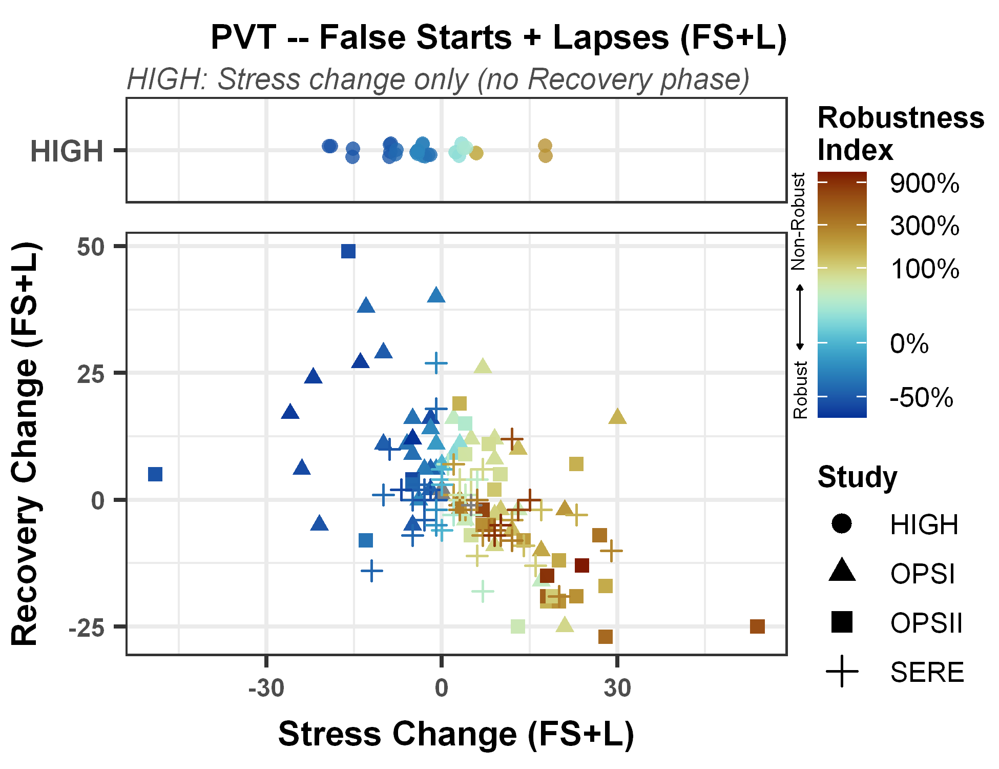

In [122]:
options(repr.plot.width=3.25, repr.plot.height=2.5, repr.plot.res=600)

study_levels <- c("HIGH", "OPSI", "OPSII", "SERE")

high_dat <- pvt_all_avg_data %>%
  filter(study == "HIGH", !is.na(delta_stress_fsl)) %>%
  mutate(study = factor(study, levels = study_levels))

recovery_dat <- pvt_all_avg_data %>%
  filter(study != "HIGH", !is.na(delta_stress_fsl), !is.na(delta_recovery_fsl)) %>%
  mutate(study = factor(study, levels = study_levels))

study_legend_dat <- tibble::tibble(study = factor(c("HIGH", "OPSI", "OPSII", "SERE"), levels = study_levels),x = 0,y = 0)

x_lims <- range(pvt_all_avg_data$delta_stress_fsl, na.rm = TRUE)
rob_lims <- range(pvt_all_avg_data$Robustness_fsl[is.finite(pvt_all_avg_data$Robustness_fsl)], na.rm = TRUE)

trans_obj <- pseudolog10_trans

rob_lims_t <- trans_obj$transform(rob_lims)
zero_t     <- trans_obj$transform(0)

zero_pos <- scales::rescale(
  zero_t,
  from = rob_lims_t,
  to = c(0, 1)
)

pal_vals <- seq(rob_lims[1], rob_lims[2], length.out = 256)

pal_pos <- ifelse(
  pal_vals <= 0,
  scales::rescale(pal_vals, from = c(rob_lims[1], 0), to = c(0, 0.5)),
  scales::rescale(pal_vals, from = c(0, rob_lims[2]), to = c(0.5, 1))
)

high_plot <- ggplot(high_dat,
                    aes(x = delta_stress_fsl,
                        y = study,
                        shape = study,
                        color = Robustness_fsl
                       )
                   ) +
    labs(x = NULL,
         y = NULL,
         subtitle = "HIGH: Stress change only (no Recovery phase)"
        ) +
    geom_point(size = 1.25, alpha = 0.8, position = position_jitter(height = 0.08)) +
    scale_color_scico(palette = "roma",
                      trans = ssqrt_trans%of% pseudolog10_trans,
                      labels = label_percent(),
                      limits = rob_lims,
                      direction = -1) +
    scale_x_continuous(limits = x_lims
                      ) +
    #scale_y_discrete(
    #  labels = c(
    #    "HIGH" = "HIGH\n(No Recovery Phase)"
    #  )) +
    theme_bw() +
    theme(text = element_text(size = 8, face = "bold"),
          plot.title = element_text(size = 7, hjust = 0),
          plot.subtitle = element_text(size = 7, face = "italic", color="gray30", hjust = 0, vjust = 0,margin = margin(0, 0, 2, 0)),
          axis.text.x = element_blank(),
          axis.ticks.x = element_blank(),
          axis.text.y = element_text(size = 7),
          strip.text = element_text(size = 8,
                                    margin = margin(t = 1, r = 2, b = 1, l = 2)
                                   ),
          strip.background = element_rect(linewidth = 0.3),
          legend.position = "none",
          plot.margin = margin(0, 2, 2, 2)
         )

recovery_plot <- ggplot(recovery_dat,
                        aes(x = delta_stress_fsl,
                            y = delta_recovery_fsl,
                            group = interaction(study, subjectid),
                            shape = study,
                            color = Robustness_fsl
                           )
                       ) +
    #ggtitle("OPSI, OPSII, and SERE: Stress and Recovery change") +
    labs(x = "Stress Change (FS+L)",
         y = "Recovery Change (FS+L)",
         shape = "Study",
         color = "Robustness\nIndex", #"Stress\n%Δ of BL",#"Stress\nDelta",
         #subtitle = "OPSI, OPSII, and SERE: Stress and Recovery change"
        ) +
    geom_point(size = 1.25, alpha = 0.8) +
    geom_point(data = study_legend_dat,
               aes(x = x, y = y, shape = study),
               inherit.aes = FALSE,
               color = "black",
               alpha = 0,
               size = 2,
               show.legend = TRUE
              ) +
    scale_color_scico(palette = "roma",
                      trans = ssqrt_trans%of% pseudolog10_trans,
                      labels = label_percent(),
                      limits = rob_lims,
                      breaks = c(-0.5, 0, 1, 3, 9),
                      direction = -1
                     ) +
    #scale_color_gradientn(colours = scico::scico(256, palette = "roma", direction = -1),
    #                      values = c(0, zero_pos / 2, zero_pos, zero_pos + (1 - zero_pos) / 2, 1), #pal_pos,
    #                      limits = rob_lims,
    #                      trans = pseudolog10_trans,
    #                      breaks = c(0, 3, 6, 9),
    #                      labels = scales::label_percent(),
    #                      name = "Stress\n%Δ of BL"
    #                     ) +
    #scale_x_continuous(limits = x_lims
    #                  ) +
    scale_y_continuous(breaks = c(-25, 0, 25, 50)
                      ) +
    scale_shape_manual(values = c("HIGH"  = 16,
                                  "OPSI"  = 17,
                                  "OPSII" = 15,
                                  "SERE"  = 3
                                 ),
                       limits = c("HIGH", "OPSI", "OPSII", "SERE"),
                       breaks = c("HIGH", "OPSI", "OPSII", "SERE"),
                       drop = FALSE
                      ) +
    guides(color = guide_colorbar(order = 1),
           shape = guide_legend(order = 2, 
                                override.aes = list(shape = c(16, 17, 15, 3),
                                                    color = "black",
                                                    size = 2,
                                                    alpha = 1))
          ) +
    theme_bw() +
    theme(text = element_text(size = 8, face = "bold"),
          plot.title = element_text(size = 7, hjust = 0),
          plot.subtitle = element_text(size = 5, face = "bold", hjust = 0, vjust = 0.1),
          axis.text.x = element_text(size = 6),
          axis.title.x = element_text(size = 8, margin = margin(3, 0, -5, 0)),
          axis.text.y = element_text(size = 6, margin = margin(0, 2, 0, 0)),
          axis.title.y = element_text(size = 8, margin = margin(0, -5, 0, -5)),
          strip.text = element_text(size = 8,
                                    margin = margin(t = 1, r = 2, b = 1, l = 2)
                                   ),
          strip.background = element_rect(linewidth = 0.3),
          legend.text = element_text(size = 6.5, face = "plain"),
          legend.title = element_text(size = 7, margin = margin(0, 0, 2, 0)),
          legend.position = "right",
          legend.box = "vertical",
          legend.justification = c(0.0, 0.31),
          legend.box.just = "left",
          legend.key.size = unit(0.8, "lines"),
          legend.margin = margin(-5, -2, 0, -2),
          legend.box.margin = margin(-5, -2, 0, -2),
          legend.spacing = unit(0, "pt"),
          legend.spacing.y = unit(15, "pt"),
          plot.margin = margin(2, 2, 2, 2)
         )

# 1. Create a grob or a blank ggplot containing your text
##Better/Worse text only separated by spaces
#text_box <- ggplot() + 
#    annotate("text", x = 0.5, y = 0.5, hjust=0.5,vjust=0.5,color="white",angle=90, label = "Better               Worse", size = 2) +
#    coord_cartesian(xlim = c(0, 1),
#                    ylim = c(0, 1),
#                    clip = "off") +
#    theme_void() +
#    theme(plot.margin = margin(0, 0, 0, 0))
##Individual words with an arrow
text_box <- ggplot() + 
    annotate("segment",
             x = 0.35,
             xend = 0.35,
             y = 0.18,
             yend = 0.67,
             arrow = arrow(ends = "both", type="closed", length = unit(0.02, "inches")),
             linewidth = 0.2,
             color = "black") +
    annotate("text",
             x = 0.35,
             y = 0.09,
             hjust = 1.0,
             vjust = 0.5,
             color = "black",
             angle = 90,
             label = "Robust",
             size = 1.5) +
    annotate("text",
             x = 0.34,
             y = 0.77,
             hjust = 0.0,
             vjust = 0.5,
             color = "black",
             angle = 90,
             label = "Non-Robust",
             size = 1.5) +
    coord_cartesian(
        xlim = c(0, 1),
        ylim = c(0, 1),
        clip = "off") +
    theme_void() +
    theme(plot.margin = margin(0, 0, 0, 0))


pvt_all_scat_plot_fsl <- high_plot / recovery_plot +
    plot_layout(heights = c(1, 4)) +
    plot_annotation(title = "PVT -- False Starts + Lapses (FS+L)",
                    theme = theme(plot.title = element_text(size = 8, face = "bold", hjust = 0.5))
                   ) +
    inset_element(text_box, 
                  left = 0.71, bottom = 0.7, right = 1, top = 0.98, 
                  align_to = "full",
                  clip = FALSE)

pvt_all_scat_plot_fsl

In [123]:
ggsave("pvt_fsl.png", pvt_all_scat_plot_fsl, width = 3.25, height = 2.5, dpi = 600)

## Combined Plots

In [124]:
library(cowplot)


Attaching package: 'cowplot'


The following object is masked from 'package:patchwork':

    align_plots


The following object is masked from 'package:ggpubr':

    get_legend


The following object is masked from 'package:lubridate':

    stamp




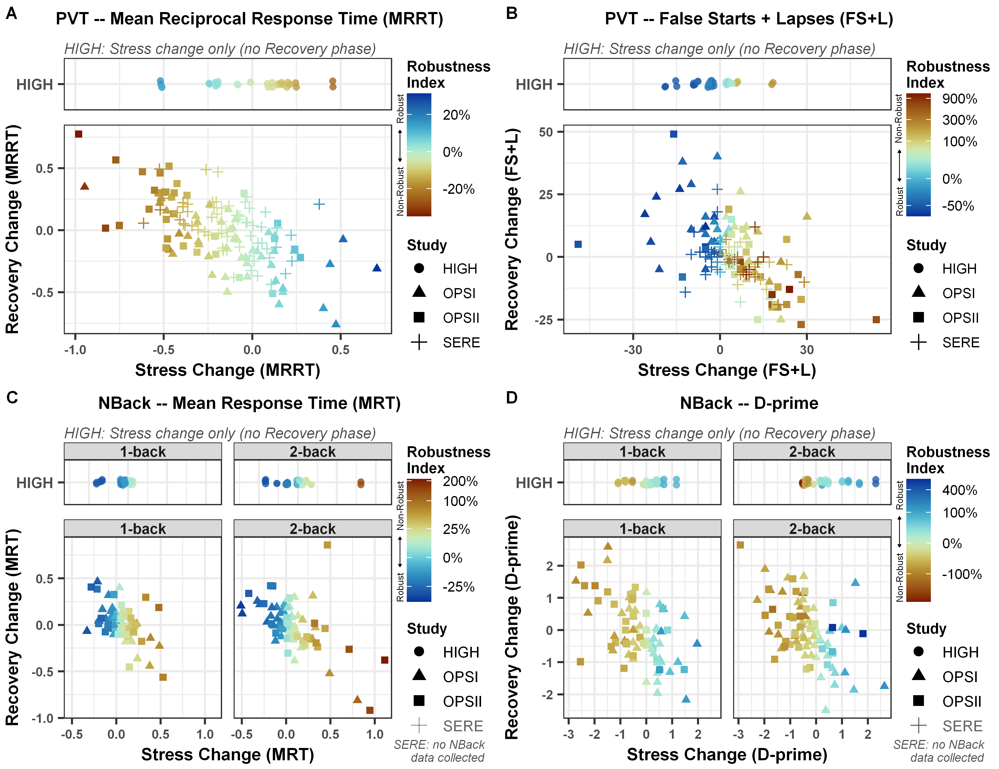

In [125]:
options(repr.plot.width=6.5, repr.plot.height=5.0, repr.plot.res=600)
all_scat_plot <- cowplot::plot_grid(
  pvt_all_scat_plot_mrrt,
  pvt_all_scat_plot_fsl,
  nback_all_scat_plot_mrt,
  nback_all_scat_plot_dprime,
  ncol = 2,
  labels = c("A", "B", "C", "D"),
  label_size = 8,
  align = "none"
)

all_scat_plot

In [126]:
ggsave("all_scat_plot.png", all_scat_plot, width = 6.5, height = 5, dpi = 600)

In [127]:
ggsave(
  "all_scat_plot.svg",
  all_scat_plot,
  width = 6.5,
  height = 5,
  device = "svg"
)

In [128]:
ggsave(
  "all_scat_plot.pdf",
  all_scat_plot,
  width = 6.5,
  height = 5,
  device = cairo_pdf
)

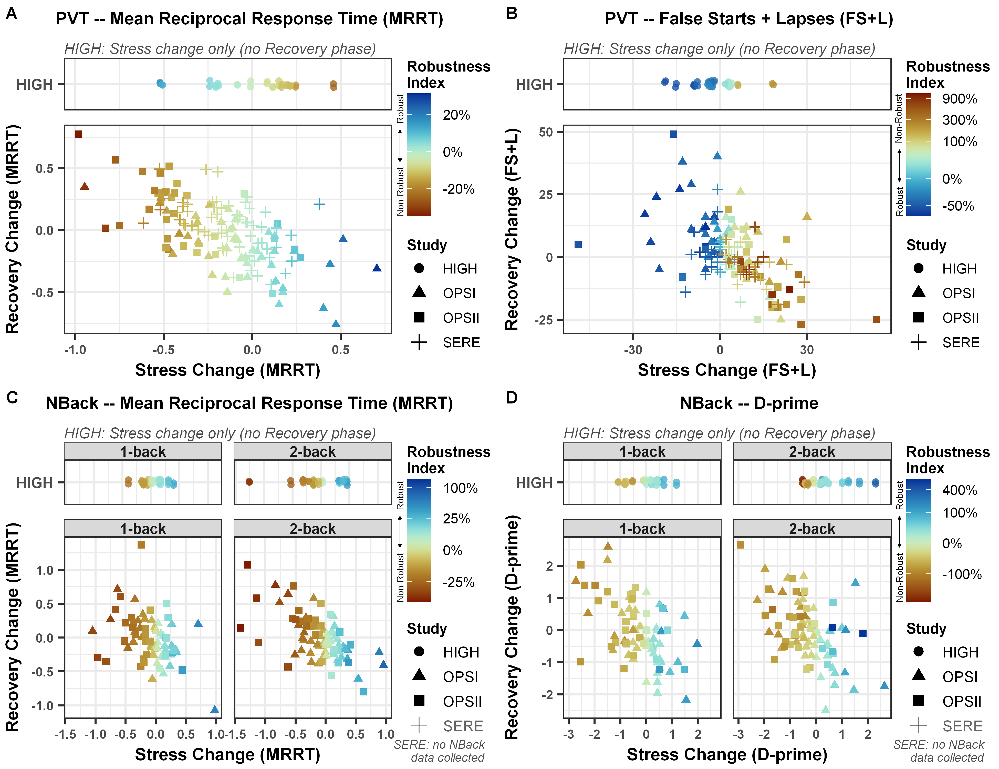

In [129]:
options(repr.plot.width=6.5, repr.plot.height=5.0, repr.plot.res=600)
all_scat_plot_mrrt <- cowplot::plot_grid(
  pvt_all_scat_plot_mrrt,
  pvt_all_scat_plot_fsl,
  nback_all_scat_plot_mrrt,
  nback_all_scat_plot_dprime,
  ncol = 2,
  labels = c("A", "B", "C", "D"),
  label_size = 8,
  align = "none"
)

all_scat_plot_mrrt

# Get Robustness/Resilience Extremophiles

In [130]:
head(dxa_data)
head(poms_data)
head(pvt_all_avg_data %>% filter(phase=="Baseline"))

study,subjectid,Stress,Baseline,Recovery,dxa_delta_stress,dxa_delta_recovery,Robustness_dxa,Resilience_dxa
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HIGH,ROP072,48549,51348,NA,-2799,NA,-0.05451040,NA
HIGH,ROP073,61975,70859,NA,-8884,NA,-0.12537575,NA
HIGH,ROP074,72679,78515,NA,-5836,NA,-0.07432975,NA
HIGH,ROP075,57258,60131,NA,-2873,NA,-0.04777902,NA
HIGH,ROP076,58540,62834,NA,-4294,NA,-0.06833880,NA
HIGH,ROP077,55102,59190,NA,-4088,NA,-0.06906572,NA


study,subjectid,Baseline,Stress,Recovery,poms_delta_stress,poms_delta_recovery,Robustness_poms,Resilience_poms,Rob_poms_v2,Rob_poms_v3
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HIGH,ROP072,-9,6,NA,15,NA,1.6666667,NA,0.6250000,-1.6666667
HIGH,ROP073,20,14,NA,-6,NA,-0.3000000,NA,-0.1132075,-0.3000000
HIGH,ROP074,5,52,NA,47,NA,9.4000000,NA,1.2368421,9.4000000
HIGH,ROP075,7,10,NA,3,NA,0.4285714,NA,0.0750000,0.4285714
HIGH,ROP076,11,24,NA,13,NA,1.1818182,NA,0.2954545,1.1818182
HIGH,ROP077,9,44,NA,35,NA,3.8888889,NA,0.8333333,3.8888889


study,subjectid,phase,nfalsestart,nlapses,ntimeouts,nfslapse,nlapseto,ntotalerr,mrtime,meanrrt,delta_stress_mrrt,delta_recovery_mrrt,Robustness_mrrt,Resilience_mrrt,delta_stress_fsl,delta_recovery_fsl,Robustness_fsl,Resilience_fsl
<fct>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
OPSI,ROP166,Baseline,1,41,24,42,65,94,507.4667,2.195648,-0.24080839,0.20436519,-0.10967531,0.093077382,17,-16,0.4047619,-0.3809524
OPSI,ROP167,Baseline,0,3,0,3,3,7,344.1955,3.009092,-0.03107773,-0.26924493,-0.01032794,-0.089477129,-2,16,-0.6666667,5.3333333
OPSI,ROP168,Baseline,0,8,0,8,8,11,347.1167,3.065804,-0.14505453,-0.14277029,-0.04731369,-0.046568623,-1,6,-0.1250000,0.7500000
OPSI,ROP169,Baseline,0,17,1,17,18,20,417.5480,2.533636,0.09266685,-0.01881286,0.03657465,-0.007425241,-5,9,-0.2941176,0.5294118
OPSI,ROP170,Baseline,0,20,3,20,23,27,434.6307,2.479382,-0.46895429,-0.15907798,-0.18914164,-0.064160345,30,16,1.5000000,0.8000000
OPSI,ROP171,Baseline,0,1,0,1,1,7,300.8715,3.416442,-0.08330035,-0.07950626,-0.02438219,-0.023271656,3,0,3.0000000,0.0000000


In [131]:
add_extreme_group <- function(
    dat,
    score_col,
    new_col,
    tail_prop = 0.25,
    positive_is_better = TRUE
) {
  
  dat %>%
    group_by(study) %>%
    mutate(
      adaptation_score = if (positive_is_better) {
        .data[[score_col]]
      } else {
        -.data[[score_col]]
      },
      
      lower_cut = quantile(
        adaptation_score,
        probs = tail_prop,
        na.rm = TRUE
      ),
      
      upper_cut = quantile(
        adaptation_score,
        probs = 1 - tail_prop,
        na.rm = TRUE
      ),
      
      "{new_col}" := case_when(
        !is.finite(adaptation_score) ~ NA_integer_,
        adaptation_score <= lower_cut ~ 0L,
        adaptation_score >= upper_cut ~ 1L,
        TRUE ~ NA_integer_
      )
    ) %>%
    ungroup() %>%
    select(-adaptation_score, -lower_cut, -upper_cut)
}

In [132]:
dxa_extreme_data <- dxa_data %>%
  add_extreme_group(
    score_col = "dxa_delta_stress",
    new_col = "dxa_robustness_extreme",
    tail_prop = 0.25,
    positive_is_better = TRUE
  ) %>%
  add_extreme_group(
    score_col = "dxa_delta_recovery",
    new_col = "dxa_resilience_extreme",
    tail_prop = 0.25,
    positive_is_better = TRUE
  )

head(dxa_extreme_data)
dxa_extreme_data %>%
  count(study, dxa_robustness_extreme, .drop = FALSE)
dxa_extreme_data %>%
  count(study, dxa_resilience_extreme, .drop = FALSE)

study,subjectid,Stress,Baseline,Recovery,dxa_delta_stress,dxa_delta_recovery,Robustness_dxa,Resilience_dxa,dxa_robustness_extreme,dxa_resilience_extreme
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>
HIGH,ROP072,48549,51348,NA,-2799,NA,-0.05451040,NA,NA,NA
HIGH,ROP073,61975,70859,NA,-8884,NA,-0.12537575,NA,0,NA
HIGH,ROP074,72679,78515,NA,-5836,NA,-0.07432975,NA,0,NA
HIGH,ROP075,57258,60131,NA,-2873,NA,-0.04777902,NA,NA,NA
HIGH,ROP076,58540,62834,NA,-4294,NA,-0.06833880,NA,NA,NA
HIGH,ROP077,55102,59190,NA,-4088,NA,-0.06906572,NA,NA,NA


study,dxa_robustness_extreme,n
<chr>,<int>,<int>
HIGH,0,5
HIGH,1,5
HIGH,NA,11
OPSI,0,13
OPSI,1,13
OPSI,NA,24
OPSII,0,8
OPSII,1,8
OPSII,NA,15


study,dxa_resilience_extreme,n
<chr>,<int>,<int>
HIGH,NA,21
OPSI,0,13
OPSI,1,13
OPSI,NA,24
OPSII,0,8
OPSII,1,8
OPSII,NA,15
SERE,0,16
SERE,1,16


In [133]:
poms_extreme_data <- poms_data %>%
  add_extreme_group(
    score_col = "poms_delta_stress",
    new_col = "poms_robustness_extreme",
    tail_prop = 0.25,
    positive_is_better = FALSE
  ) %>%
  add_extreme_group(
    score_col = "poms_delta_recovery",
    new_col = "poms_resilience_extreme",
    tail_prop = 0.25,
    positive_is_better = FALSE
  )

head(poms_extreme_data)
poms_extreme_data %>%
  count(study, poms_robustness_extreme, .drop = FALSE)
poms_extreme_data %>%
  count(study, poms_resilience_extreme, .drop = FALSE)

study,subjectid,Baseline,Stress,Recovery,poms_delta_stress,poms_delta_recovery,Robustness_poms,Resilience_poms,Rob_poms_v2,Rob_poms_v3,poms_robustness_extreme,poms_resilience_extreme
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>
HIGH,ROP072,-9,6,NA,15,NA,1.6666667,NA,0.6250000,-1.6666667,NA,NA
HIGH,ROP073,20,14,NA,-6,NA,-0.3000000,NA,-0.1132075,-0.3000000,1,NA
HIGH,ROP074,5,52,NA,47,NA,9.4000000,NA,1.2368421,9.4000000,0,NA
HIGH,ROP075,7,10,NA,3,NA,0.4285714,NA,0.0750000,0.4285714,NA,NA
HIGH,ROP076,11,24,NA,13,NA,1.1818182,NA,0.2954545,1.1818182,NA,NA
HIGH,ROP077,9,44,NA,35,NA,3.8888889,NA,0.8333333,3.8888889,0,NA


study,poms_robustness_extreme,n
<chr>,<int>,<int>
HIGH,0,5
HIGH,1,5
HIGH,NA,7
OPSI,0,13
OPSI,1,15
OPSI,NA,22
OPSII,0,8
OPSII,1,9
OPSII,NA,17


study,poms_resilience_extreme,n
<chr>,<int>,<int>
HIGH,NA,17
OPSI,0,14
OPSI,1,13
OPSI,NA,23
OPSII,0,8
OPSII,1,8
OPSII,NA,18
SERE,0,17
SERE,1,20


In [134]:
pvt_extreme_data <- pvt_all_avg_data %>% filter(phase=="Baseline") %>% select(study, subjectid, delta_stress_mrrt, delta_recovery_mrrt, Robustness_mrrt, Resilience_mrrt, delta_stress_fsl, delta_recovery_fsl, Robustness_fsl, Resilience_fsl) %>%
  add_extreme_group(
    score_col = "delta_stress_mrrt",
    new_col = "pvt_mrrt_robustness_extreme",
    tail_prop = 0.25,
    positive_is_better = TRUE
  ) %>%
  add_extreme_group(
    score_col = "delta_recovery_mrrt",
    new_col = "pvt_mrrt_resilience_extreme",
    tail_prop = 0.25,
    positive_is_better = TRUE
  ) %>%
  add_extreme_group(
    score_col = "delta_stress_fsl",
    new_col = "pvt_fsl_robustness_extreme",
    tail_prop = 0.25,
    positive_is_better = FALSE
  ) %>%
  add_extreme_group(
    score_col = "delta_recovery_fsl",
    new_col = "pvt_fsl_resilience_extreme",
    tail_prop = 0.25,
    positive_is_better = FALSE
  )

head(pvt_extreme_data)
pvt_extreme_data %>%
  count(study, pvt_mrrt_robustness_extreme, .drop = FALSE)
pvt_extreme_data %>%
  count(study, pvt_mrrt_resilience_extreme, .drop = FALSE)
pvt_extreme_data %>%
  count(study, pvt_fsl_robustness_extreme, .drop = FALSE)
pvt_extreme_data %>%
  count(study, pvt_fsl_resilience_extreme, .drop = FALSE)

study,subjectid,delta_stress_mrrt,delta_recovery_mrrt,Robustness_mrrt,Resilience_mrrt,delta_stress_fsl,delta_recovery_fsl,Robustness_fsl,Resilience_fsl,pvt_mrrt_robustness_extreme,pvt_mrrt_resilience_extreme,pvt_fsl_robustness_extreme,pvt_fsl_resilience_extreme
<fct>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<int>
OPSI,ROP166,-0.24080839,0.20436519,-0.10967531,0.093077382,17,-16,0.4047619,-0.3809524,NA,1,0,1
OPSI,ROP167,-0.03107773,-0.26924493,-0.01032794,-0.089477129,-2,16,-0.6666667,5.3333333,NA,NA,NA,0
OPSI,ROP168,-0.14505453,-0.14277029,-0.04731369,-0.046568623,-1,6,-0.1250000,0.7500000,NA,NA,NA,NA
OPSI,ROP169,0.09266685,-0.01881286,0.03657465,-0.007425241,-5,9,-0.2941176,0.5294118,NA,NA,1,NA
OPSI,ROP170,-0.46895429,-0.15907798,-0.18914164,-0.064160345,30,16,1.5000000,0.8000000,0,NA,0,0
OPSI,ROP171,-0.08330035,-0.07950626,-0.02438219,-0.023271656,3,0,3.0000000,0.0000000,NA,NA,NA,NA


study,pvt_mrrt_robustness_extreme,n
<fct>,<int>,<int>
HIGH,0,4
HIGH,1,4
HIGH,NA,7
OPSI,0,12
OPSI,1,12
OPSI,NA,24
OPSII,0,8
OPSII,1,8
OPSII,NA,14


study,pvt_mrrt_resilience_extreme,n
<fct>,<int>,<int>
HIGH,NA,15
OPSI,0,12
OPSI,1,12
OPSI,NA,24
OPSII,0,8
OPSII,1,8
OPSII,NA,14
SERE,0,16
SERE,1,16


study,pvt_fsl_robustness_extreme,n
<fct>,<int>,<int>
HIGH,0,4
HIGH,1,4
HIGH,NA,7
OPSI,0,14
OPSI,1,13
OPSI,NA,21
OPSII,0,9
OPSII,1,8
OPSII,NA,13


study,pvt_fsl_resilience_extreme,n
<fct>,<int>,<int>
HIGH,NA,15
OPSI,0,12
OPSI,1,14
OPSI,NA,22
OPSII,0,8
OPSII,1,8
OPSII,NA,14
SERE,0,18
SERE,1,16


# Sleep Fatigue Module Plots

In [135]:
head(ops2_sleep_data)
head(high_sleep_data)

subjectid,date,days,FS_Id,Name,Identifier,Location,UTC_Offset,Average_Alertness,Latency,⋯,Slp_15,Slp_16,Slp_17,Slp_18,Slp_19,Slp_20,Slp_21,Slp_22,Slp_23,phase
<chr>,<date>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ROP216,2021-01-08,1,48164,A00-02-9405 TURMA,TURMA,Baton Rouge,-6,NA,13,⋯,0,0,0,0,0,0,0,0,0,1
ROP216,2021-01-09,2,48164,A00-02-9405 TURMA,TURMA,Baton Rouge,-6,NA,314,⋯,0,0,0,0,0,0,0,0,35,1
ROP216,2021-01-10,3,48164,A00-02-9405 TURMA,TURMA,Baton Rouge,-6,84.6,22,⋯,0,0,0,0,0,0,0,0,5,1
ROP216,2021-01-11,4,48164,A00-02-9405 TURMA,TURMA,Baton Rouge,-6,87.1,10,⋯,0,0,0,0,0,0,0,20,60,1
ROP216,2021-01-12,5,48164,A00-02-9405 TURMA,TURMA,Baton Rouge,-6,84.5,253,⋯,0,0,0,0,0,0,0,0,0,1
ROP216,2021-01-13,6,48164,A00-02-9405 TURMA,TURMA,Baton Rouge,-6,86.0,61,⋯,0,0,0,0,0,0,0,0,50,1


subjectid,date,location,week,days,session_id,sleep_onset,wake_onset,average_variance,minutes_resting,minutes_sleeping,minutes_sleep_latency,sleep_efficiency,wake_episodes,mean_wake_episode_duration
<chr>,<date>,<dbl>,<dbl>,<dbl>,<chr>,<dttm>,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ROP072,2016-05-16,1,1,1,0,NA,NA,NA,NA,NA,NA,NA,NA,NA
ROP072,2016-05-17,1,1,2,1,NA,NA,NA,NA,NA,NA,NA,NA,NA
ROP072,2016-05-18,1,1,3,2,2016-05-18 23:49:00,2016-05-19 05:13:00,78,338,280,11,82.8,6,9.3
ROP072,2016-05-19,1,1,4,3,2016-05-19 22:14:00,2016-05-20 05:53:00,-17,517,335,51,64.8,7,25.1
ROP072,2016-05-20,1,1,5,4,2016-05-20 23:54:00,2016-05-21 05:43:00,83,369,275,9,74.5,5,16.8
ROP072,2016-05-21,1,1,6,5,NA,NA,NA,NA,NA,NA,NA,NA,NA


In [136]:
ops1_bouts <- c(322,994,1450)
ops2_bouts <- c(130, 514, 898)
sere_bouts <- c(37,421,1069)
high_bouts <- c(181,541,781,1045)

ops1_bouts
ops2_bouts
sere_bouts
high_bouts

[1]  322  994 1450

[1] 130 514 898

[1]   37  421 1069

[1]  181  541  781 1045

In [137]:
OPSI_SS <- '((6 23) (30 47) (54 71) (78 95) (102 119) (126 143) (150 167) (174 191) (198 215) (222 239) (246 263) (270 287) (294 311) (318 335) (342 359) (366 383) (390 407) (414 431) (438 455) (462 479) (486 503) (510 527) (534 551) (558 575) (582 599) (606 623) (630 647) (654 671) (678 695) (702 719) (726 743) (750 767) (774 791) (798 815) (822 839) (846 863) (870 887) (894 911) (918 935) (942 959) (966 983) (990 1007) (1014 1031) (1038 1055) (1062 1079) (1086 1103) (1110 1127) (1134 1151) (1158 1175) (1182 1199) (1206 1223) (1230 1247) (1254 1271) (1278 1295) (1302 1319) (1326 1343) (1350 1367) (1374 1391) (1398 1415) (1422 1439) (1446 1463) (1470 1487) (1494 1511) (1518 1535) (1542 1559) (1566 1583) (1590 1607) (1614 1631) (1638 1655) (1662 1679) (1686 1703) (1710 1727) (1734 1751) (1758 1775) (1782 1799) (1806 1823) (1830 1847) (1854 1871) (1878 1895) (1902 1919) (1926 1943) (1950 1967) (1974 1991) (1998 2015) (2022 2039))'
OPSI_SS
OPSII_SS <- '((5 21) (29 45) (53 69) (77 93) (101 117) (125 141) (149 165) (173 189) (197 216) (220 240) (244 264) (268 285) (293 309) (317 336) (340 360) (364 384) (388 405) (413 429) (437 456) (460 480) (484 504) (508 525) (533 549) (557 576) (580 600) (604 624) (628 645) (653 669) (677 693) (701 717) (725 741) (749 765) (773 789) (797 813) (821 837) (845 861) (869 885) (893 909))'
OPSII_SS
SERE_SS <- '((6 23) (30 47) (54 71) (77 97) (101 121) (125 145) (149 169) (173 193) (197 217) (221 241) (245 265) (269 289) (293 313) (317 337) (341 361) (365 385) (389 409) (413 433) (438 455) (462 479) (486 503) (510 527) (534 551) (558 575) (582 599) (606 623) (630 647) (654 671) (678 695) (702 719) (726 743) (750 767) (774 791) (798 815) (822 839) (846 863) (870 887) (894 911) (918 935) (942 959) (966 983) (990 1007) (1014 1031) (1038 1055) (1062 1079))'
SERE_SS
HIGH_SS <- '((6 23) (30 47) (54 71) (78 95) (102 119) (126 143) (150 167) (174 191) (198 215) (222 239) (246 263) (270 287) (294 311) (318 335) (342 359) (366 383) (390 407) (414 431) (438 455) (462 479) (486 503) (510 527) (534 551) (558 575) (582 599) (606 623) (630 647) (654 671) (678 695) (702 719) (726 743) (750 767) (774 791) (798 815) (822 839) (846 863) (870 887) (894 911) (918 935) (942 959) (966 983) (990 1007))'
HIGH_SS

[1] "((6 23) (30 47) (54 71) (78 95) (102 119) (126 143) (150 167) (174 191) (198 215) (222 239) (246 263) (270 287) (294 311) (318 335) (342 359) (366 383) (390 407) (414 431) (438 455) (462 479) (486 503) (510 527) (534 551) (558 575) (582 599) (606 623) (630 647) (654 671) (678 695) (702 719) (726 743) (750 767) (774 791) (798 815) (822 839) (846 863) (870 887) (894 911) (918 935) (942 959) (966 983) (990 1007) (1014 1031) (1038 1055) (1062 1079) (1086 1103) (1110 1127) (1134 1151) (1158 1175) (1182 1199) (1206 1223) (1230 1247) (1254 1271) (1278 1295) (1302 1319) (1326 1343) (1350 1367) (1374 1391) (1398 1415) (1422 1439) (1446 1463) (1470 1487) (1494 1511) (1518 1535) (1542 1559) (1566 1583) (1590 1607) (1614 1631) (1638 1655) (1662 1679) (1686 1703) (1710 1727) (1734 1751) (1758 1775) (1782 1799) (1806 1823) (1830 1847) (1854 1871) (1878 1895) (1902 1919) (1926 1943) (1950 1967) (1974 1991) (1998 2015) (2022 2039))"

[1] "((5 21) (29 45) (53 69) (77 93) (101 117) (125 141) (149 165) (173 189) (197 216) (220 240) (244 264) (268 285) (293 309) (317 336) (340 360) (364 384) (388 405) (413 429) (437 456) (460 480) (484 504) (508 525) (533 549) (557 576) (580 600) (604 624) (628 645) (653 669) (677 693) (701 717) (725 741) (749 765) (773 789) (797 813) (821 837) (845 861) (869 885) (893 909))"

[1] "((6 23) (30 47) (54 71) (77 97) (101 121) (125 145) (149 169) (173 193) (197 217) (221 241) (245 265) (269 289) (293 313) (317 337) (341 361) (365 385) (389 409) (413 433) (438 455) (462 479) (486 503) (510 527) (534 551) (558 575) (582 599) (606 623) (630 647) (654 671) (678 695) (702 719) (726 743) (750 767) (774 791) (798 815) (822 839) (846 863) (870 887) (894 911) (918 935) (942 959) (966 983) (990 1007) (1014 1031) (1038 1055) (1062 1079))"

[1] "((6 23) (30 47) (54 71) (78 95) (102 119) (126 143) (150 167) (174 191) (198 215) (222 239) (246 263) (270 287) (294 311) (318 335) (342 359) (366 383) (390 407) (414 431) (438 455) (462 479) (486 503) (510 527) (534 551) (558 575) (582 599) (606 623) (630 647) (654 671) (678 695) (702 719) (726 743) (750 767) (774 791) (798 815) (822 839) (846 863) (870 887) (894 911) (918 935) (942 959) (966 983) (990 1007))"

In [138]:
# -------------------------------------------------------------------------
# 1. Parse existing design-based sleep schedule strings
# -------------------------------------------------------------------------

parse_sleep_string <- function(ss, studyid) {
  m <- stringr::str_match_all(
    ss,
    "\\((-?\\d+(?:\\.\\d+)?)\\s+(-?\\d+(?:\\.\\d+)?)\\)"
  )[[1]]
  
  tibble(
    study = studyid,
    study_day = seq_len(nrow(m)),
    wake_design = as.numeric(m[, 2]),
    sleep_design = as.numeric(m[, 3])
  )
}

design_sleep_sched <- bind_rows(
  parse_sleep_string(OPSI_SS,  "OPSI"),
  parse_sleep_string(OPSII_SS, "OPSII"),
  parse_sleep_string(SERE_SS,  "SERE"),
  parse_sleep_string(HIGH_SS,  "HIGH")
)

get_design_pair <- function(studyid, study_day) {
  row <- design_sleep_sched %>%
    filter(.data$study == .env$studyid,
           .data$study_day == .env$study_day)
  
  if (nrow(row) == 0) {
    # fallback if observed participant days exceed design schedule length
    return(c(
      wake = (study_day - 1) * 24 + 6,
      sleep = (study_day - 1) * 24 + 23
    ))
  }
  
  c(
    wake = row$wake_design[1],
    sleep = row$sleep_design[1]
  )
}

make_design_day <- function(studyid, subjectid, study_day) {
  d <- get_design_pair(studyid, study_day)
  
  tibble(
    study = studyid,
    subjectid = subjectid,
    study_day = study_day,
    wake = d["wake"],
    sleep = d["sleep"],
    wake_source = "design",
    sleep_source = "design"
  )
}

In [139]:
# Clock hour, preserving fractional time.
# Example: 06:30 becomes 6.5.
clock_hour <- function(x) {
  if (length(x) == 0 || is.na(x)) return(NA_real_)
  
  as.numeric(format(x, "%H")) +
    as.numeric(format(x, "%M")) / 60 +
    as.numeric(format(x, "%S")) / 3600
}

# Sleep onset as hours since that date's midnight.
# This allows post-midnight sleep times to be > 24 if stored that way.
hours_after_midnight <- function(dt, date) {
  if (length(dt) == 0 || length(date) == 0 || is.na(dt) || is.na(date)) {
    return(NA_real_)
  }
  
  as.numeric(
    difftime(
      dt,
      as.POSIXct(date),
      units = "hours"
    )
  )
}

get_n_days_tbl <- function(start_times, end_event, day_col) {
  split(start_times, start_times$subjectid) %>%
    purrr::imap_dfr(function(df, pid) {
      
      end_vals <- suppressWarnings(
        as.integer(df[[day_col]][df$study_event_id == end_event])
      )
      end_vals <- end_vals[!is.na(end_vals)]
      
      all_vals <- suppressWarnings(as.integer(df[[day_col]]))
      all_vals <- all_vals[!is.na(all_vals)]
      
      n_days <- if (length(end_vals) > 0) {
        max(end_vals)
      } else if (length(all_vals) > 0) {
        max(all_vals)
      } else {
        NA_integer_
      }
      
      tibble(
        subjectid = as.character(pid),
        n_days = n_days
      )
    })
}

In [140]:
# -------------------------------------------------------------------------
# 2. OPSI: design schedule, but limited by each participant's actual study days
# -------------------------------------------------------------------------

opsi_start_times <- nback_ops1_data_cleaned %>%
  select(subjectid, study_event_id, days_fix, StartDT, SessBlockID) %>%
  filter(!is.na(StartDT), SessBlockID == 1)

opsi_n_days <- get_n_days_tbl(
  start_times = opsi_start_times,
  end_event = "EOS",
  day_col = "days_fix"
)

opsi_subject_schedules <- purrr::map2_dfr(
  opsi_n_days$subjectid,
  opsi_n_days$n_days,
  function(pid, n_days_i) {
    
    if (is.na(n_days_i)) {
      total_days <- design_sleep_sched %>%
        filter(study == "OPSI") %>%
        nrow()
    } else {
      # Matches your original OPSI logic: n_days + 1
      total_days <- n_days_i + 1L
    }
    
    purrr::map_dfr(
      seq_len(total_days),
      function(d) make_design_day("OPSI", pid, d)
    )
  }
)

In [141]:
# -------------------------------------------------------------------------
# 3. OPSII: use actigraphy when present, otherwise design schedule
# -------------------------------------------------------------------------

make_opsii_subject_schedule <- function(pid, n_days_i, use_actigraphy = TRUE) {
  
  # Matches your original special-case skip logic
  skips <- if (pid %in% c("A00-07-2030", "A00-07-4258")) 4L else 0L
  
  if (is.na(n_days_i)) {
    n_days_i <- design_sleep_sched %>%
      filter(study == "OPSII") %>%
      nrow()
  }
  
  total_days <- n_days_i + skips
  
  purrr::map_dfr(seq_len(total_days), function(study_day) {
    
    d <- get_design_pair("OPSII", study_day)
    
    wake <- d["wake"]
    sleep <- d["sleep"]
    wake_source <- "design"
    sleep_source <- "design"
    
    if (use_actigraphy && study_day > skips) {
      
      act_day <- study_day - skips
      
      wake_data_day <- act_day - 1L
      sleep_data_day <- act_day
      
      w <- ops2_sleep_data %>%
        filter(.data$subjectid == .env$pid,
               .data$days == .env$wake_data_day) %>%
        slice(1)
      
      s <- ops2_sleep_data %>%
        filter(.data$subjectid == .env$pid,
               .data$days == .env$sleep_data_day) %>%
        slice(1)
      
      if (nrow(w) > 0 && !is.na(w$Wake__local_[1])) {
        wake_actual <- (study_day - 1) * 24 + clock_hour(w$Wake__local_[1])
        
        if (!is.na(wake_actual)) {
          wake <- wake_actual
          wake_source <- "actigraphy"
        }
      }
      
      if (nrow(s) > 0 &&
          !is.na(s$Sleep_onset__local_[1]) &&
          !is.na(s$date[1])) {
        
        sleep_actual <- (study_day - 1) * 24 +
          hours_after_midnight(s$Sleep_onset__local_[1], s$date[1])
        
        if (!is.na(sleep_actual)) {
          sleep <- sleep_actual
          sleep_source <- "actigraphy"
        }
      }
    }
    
    tibble(
      study = "OPSII",
      subjectid = pid,
      study_day = study_day,
      wake = wake,
      sleep = sleep,
      wake_source = wake_source,
      sleep_source = sleep_source
    )
  })
}

opsii_start_times <- nback_ops2_data_cleaned %>%
  select(subjectid, study_event_id, days, days_fix, StartDT, SessBlockID) %>%
  filter(!is.na(StartDT), SessBlockID == 1)

opsii_n_days <- get_n_days_tbl(
  start_times = opsii_start_times,
  end_event = "38",
  day_col = "days_fix"
)

opsii_subject_schedules <- purrr::map2_dfr(
  opsii_n_days$subjectid,
  opsii_n_days$n_days,
  make_opsii_subject_schedule
)

In [142]:
# -------------------------------------------------------------------------
# 4. SERE: design schedule only
# -------------------------------------------------------------------------

make_sere_design_schedule <- function(subjectid = "STUDY_DESIGN", n_days = 45) {
  
  purrr::map_dfr(seq_len(n_days), function(study_day) {
    
    wake <- ifelse(
      study_day %in% 11:18,
      (study_day - 1) * 24 + 4,
      (study_day - 1) * 24 + 5
    )
    
    sleep <- ifelse(
      study_day %in% 11:17,
      (study_day - 1) * 24 + 25,
      (study_day - 1) * 24 + 22
    )
    
    tibble(
      study = "SERE",
      subjectid = subjectid,
      study_day = study_day,
      wake = wake,
      sleep = sleep,
      wake_source = "design_original_code",
      sleep_source = "design_original_code"
    )
  })
}

sere_subject_schedules <- make_sere_design_schedule()

In [143]:
# -------------------------------------------------------------------------
# 5. HIGH: use actigraphy when present, otherwise design schedule
# -------------------------------------------------------------------------

make_high_subject_schedule <- function(pid, n_days_i = 44, use_actigraphy = TRUE) {
  
  purrr::map_dfr(seq_len(n_days_i), function(study_day) {
    
    d <- get_design_pair("HIGH", study_day)
    
    wake <- d["wake"]
    sleep <- d["sleep"]
    wake_source <- "design"
    sleep_source <- "design"
    
    if (use_actigraphy) {
      
      wake_data_day <- study_day - 1L
      sleep_data_day <- study_day
      
      w <- high_sleep_data %>%
        filter(.data$subjectid == .env$pid,
               .data$days == .env$wake_data_day) %>%
        slice(1)
      
      s <- high_sleep_data %>%
        filter(.data$subjectid == .env$pid,
               .data$days == .env$sleep_data_day) %>%
        slice(1)
      
      if (nrow(w) > 0 && !is.na(w$wake_onset[1])) {
        wake_actual <- (study_day - 1) * 24 + clock_hour(w$wake_onset[1])
        
        if (!is.na(wake_actual)) {
          wake <- wake_actual
          wake_source <- "actigraphy"
        }
      }
      
      if (nrow(s) > 0 &&
          !is.na(s$sleep_onset[1]) &&
          !is.na(s$date[1])) {
        
        sleep_actual <- (study_day - 1) * 24 +
          hours_after_midnight(s$sleep_onset[1], s$date[1])
        
        if (!is.na(sleep_actual)) {
          sleep <- sleep_actual
          sleep_source <- "actigraphy"
        }
      }
    }
    
    tibble(
      study = "HIGH",
      subjectid = pid,
      study_day = study_day,
      wake = wake,
      sleep = sleep,
      wake_source = wake_source,
      sleep_source = sleep_source
    )
  })
}

high_pids <- sort(unique(high_sleep_data$subjectid))

high_subject_schedules <- purrr::map_dfr(
  high_pids,
  make_high_subject_schedule
)

In [144]:
high_sleep_data

subjectid,date,location,week,days,session_id,sleep_onset,wake_onset,average_variance,minutes_resting,minutes_sleeping,minutes_sleep_latency,sleep_efficiency,wake_episodes,mean_wake_episode_duration
<chr>,<date>,<dbl>,<dbl>,<dbl>,<chr>,<dttm>,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
ROP072,2016-05-16,1,1,1,0,NA,NA,NA,NA,NA,NA,NA,NA,NA
ROP072,2016-05-17,1,1,2,1,NA,NA,NA,NA,NA,NA,NA,NA,NA
ROP072,2016-05-18,1,1,3,2,2016-05-18 23:49:00,2016-05-19 05:13:00,78,338,280,11,82.8,6,9.3
ROP072,2016-05-19,1,1,4,3,2016-05-19 22:14:00,2016-05-20 05:53:00,-17,517,335,51,64.8,7,25.1
ROP072,2016-05-20,1,1,5,4,2016-05-20 23:54:00,2016-05-21 05:43:00,83,369,275,9,74.5,5,16.8
ROP072,2016-05-21,1,1,6,5,NA,NA,NA,NA,NA,NA,NA,NA,NA
ROP072,2016-05-22,1,1,7,6,2016-05-22 23:14:00,2016-05-23 09:33:00,43,675,360,5,53.3,9,29.4
ROP072,2016-05-23,1,2,8,7,2016-05-23 21:34:00,2016-05-24 05:48:00,-57,516,435,16,84.3,3,25.3
ROP072,2016-05-24,1,2,9,8,NA,NA,NA,NA,NA,NA,NA,NA,NA


In [145]:
high_subject_schedules

study,subjectid,study_day,wake,sleep,wake_source,sleep_source
<chr>,<chr>,<int>,<dbl>,<dbl>,<chr>,<chr>
HIGH,ROP072,1,6.00000,23.00000,design,design
HIGH,ROP072,2,30.00000,47.00000,design,design
HIGH,ROP072,3,54.00000,71.81667,design,actigraphy
HIGH,ROP072,4,77.21667,94.23333,actigraphy,actigraphy
HIGH,ROP072,5,101.88333,119.90000,actigraphy,actigraphy
HIGH,ROP072,6,125.71667,143.00000,actigraphy,design
HIGH,ROP072,7,150.00000,167.23333,design,actigraphy
HIGH,ROP072,8,177.55000,189.56667,actigraphy,actigraphy
HIGH,ROP072,9,197.80000,215.00000,actigraphy,design


In [146]:
# -------------------------------------------------------------------------
# 6. Combine subject-level schedules and compute average study schedules
# -------------------------------------------------------------------------

all_subject_sleep_schedules <- bind_rows(
  opsi_subject_schedules,
  opsii_subject_schedules,
  sere_subject_schedules,
  high_subject_schedules
)

average_sleep_schedule <- all_subject_sleep_schedules %>%
  filter(!is.na(wake), !is.na(sleep)) %>%
  group_by(study, study_day) %>%
  summarise(
    wake_mean = mean(wake),
    sleep_mean = mean(sleep),
    wake_sd = sd(wake),
    sleep_sd = sd(sleep),
    sleep_duration_mean = mean(sleep - wake),
    n_subjects = n_distinct(subjectid),
    wake_n_actual = sum(wake_source == "actigraphy"),
    sleep_n_actual = sum(sleep_source == "actigraphy"),
    .groups = "drop"
  ) %>%
  mutate(
    wake_final = as.integer(round(wake_mean)),
    sleep_final = as.integer(round(sleep_mean))
  ) %>%
  arrange(study, study_day)

average_sleep_schedule

study,study_day,wake_mean,sleep_mean,wake_sd,sleep_sd,sleep_duration_mean,n_subjects,wake_n_actual,sleep_n_actual,wake_final,sleep_final
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<int>
HIGH,1,6.00000,23.42549,0.0000000,0.9113314,17.42549,17,0,8,6,23
HIGH,2,29.84412,47.56765,0.8095125,0.7621577,17.72353,17,8,10,30,48
HIGH,3,54.38627,71.30098,0.6239501,1.2339170,16.91471,17,10,8,54,71
HIGH,4,77.71765,95.41078,0.6116198,1.4186131,17.69314,17,8,11,78,95
HIGH,5,102.56471,118.92353,0.9210856,0.3911370,16.35882,17,11,7,103,119
HIGH,6,125.63725,143.12157,0.5004349,0.8051433,17.48431,17,7,10,126,143
HIGH,7,150.04608,166.88039,0.7039208,0.8393995,16.83431,17,10,11,150,167
HIGH,8,173.58431,190.78627,1.7689889,0.9484680,17.20196,17,11,11,174,191
HIGH,9,198.07941,215.15490,0.7479493,0.3863003,17.07549,17,11,6,198,215


In [147]:
to_sleep_string <- function(avg_tbl, studyid, use_rounded = TRUE, digits = 1) {
  
  tmp <- avg_tbl %>%
    filter(.data$study == .env$studyid) %>%
    arrange(study_day)
  
  if (use_rounded) {
    pairs <- sprintf("(%d %d)", tmp$wake_final, tmp$sleep_final)
  } else {
    fmt <- paste0("(%.", digits, "f %.", digits, "f)")
    pairs <- sprintf(fmt, tmp$wake_mean, tmp$sleep_mean)
  }
  
  paste0("(", paste(pairs, collapse = " "), ")")
}

OPSI_SS_avg  <- to_sleep_string(average_sleep_schedule, "OPSI")
OPSII_SS_avg <- to_sleep_string(average_sleep_schedule, "OPSII")
SERE_SS_avg  <- to_sleep_string(average_sleep_schedule, "SERE")
HIGH_SS_avg  <- to_sleep_string(average_sleep_schedule, "HIGH")

OPSI_SS_avg
OPSII_SS_avg
SERE_SS_avg
HIGH_SS_avg

[1] "((6 23) (30 47) (54 71) (78 95) (102 119) (126 143) (150 167) (174 191) (198 215) (222 239) (246 263) (270 287) (294 311) (318 335) (342 359) (366 383) (390 407) (414 431) (438 455) (462 479) (486 503) (510 527) (534 551) (558 575) (582 599) (606 623) (630 647) (654 671) (678 695) (702 719) (726 743) (750 767) (774 791) (798 815) (822 839) (846 863) (870 887) (894 911) (918 935) (942 959) (966 983) (990 1007) (1014 1031) (1038 1055) (1062 1079) (1086 1103) (1110 1127) (1134 1151) (1158 1175) (1182 1199) (1206 1223) (1230 1247) (1254 1271) (1278 1295) (1302 1319) (1326 1343) (1350 1367) (1374 1391) (1398 1415) (1422 1439) (1446 1463) (1470 1487) (1494 1511) (1518 1535) (1542 1559) (1566 1583) (1590 1607) (1614 1631) (1638 1655) (1662 1679) (1686 1703) (1710 1727) (1734 1751) (1758 1775) (1782 1799) (1806 1823) (1830 1847) (1854 1871) (1878 1895) (1902 1919) (1926 1943) (1950 1967) (1974 1991) (1998 2015) (2022 2039) (2046 2063))"

[1] "((5 23) (30 48) (55 72) (78 95) (102 119) (126 143) (150 167) (174 189) (196 212) (220 239) (244 264) (268 288) (292 309) (316 333) (340 360) (364 384) (388 407) (412 429) (436 452) (460 479) (484 503) (508 527) (532 548) (556 573) (580 599) (604 623) (628 647) (654 671) (678 695) (703 718) (726 743) (751 766) (774 790) (798 815) (822 839) (846 864) (871 887) (895 911))"

[1] "((5 22) (29 46) (53 70) (77 94) (101 118) (125 142) (149 166) (173 190) (197 214) (221 238) (244 265) (268 289) (292 313) (316 337) (340 361) (364 385) (388 409) (412 430) (437 454) (461 478) (485 502) (509 526) (533 550) (557 574) (581 598) (605 622) (629 646) (653 670) (677 694) (701 718) (725 742) (749 766) (773 790) (797 814) (821 838) (845 862) (869 886) (893 910) (917 934) (941 958) (965 982) (989 1006) (1013 1030) (1037 1054) (1061 1078))"

[1] "((6 23) (30 48) (54 71) (78 95) (103 119) (126 143) (150 167) (174 191) (198 215) (222 240) (246 264) (270 287) (294 311) (318 335) (342 359) (366 383) (390 407) (414 431) (438 456) (462 479) (486 503) (510 527) (534 550) (557 574) (582 599) (606 623) (630 647) (653 671) (678 695) (702 719) (727 743) (751 767) (775 792) (799 816) (823 839) (846 863) (870 887) (895 911) (919 935) (943 959) (966 982) (990 1007) (1015 1031) (1037 1055))"

In [148]:
OPSI_SS_avg_nr  <- to_sleep_string(average_sleep_schedule, "OPSI", use_rounded=FALSE, digits=2)
OPSII_SS_avg_nr <- to_sleep_string(average_sleep_schedule, "OPSII", use_rounded=FALSE, digits=2)
SERE_SS_avg_nr  <- to_sleep_string(average_sleep_schedule, "SERE", use_rounded=FALSE, digits=2)
HIGH_SS_avg_nr  <- to_sleep_string(average_sleep_schedule, "HIGH", use_rounded=FALSE, digits=2)

OPSI_SS_avg_nr
OPSII_SS_avg_nr
SERE_SS_avg_nr
HIGH_SS_avg_nr

[1] "((6.00 23.00) (30.00 47.00) (54.00 71.00) (78.00 95.00) (102.00 119.00) (126.00 143.00) (150.00 167.00) (174.00 191.00) (198.00 215.00) (222.00 239.00) (246.00 263.00) (270.00 287.00) (294.00 311.00) (318.00 335.00) (342.00 359.00) (366.00 383.00) (390.00 407.00) (414.00 431.00) (438.00 455.00) (462.00 479.00) (486.00 503.00) (510.00 527.00) (534.00 551.00) (558.00 575.00) (582.00 599.00) (606.00 623.00) (630.00 647.00) (654.00 671.00) (678.00 695.00) (702.00 719.00) (726.00 743.00) (750.00 767.00) (774.00 791.00) (798.00 815.00) (822.00 839.00) (846.00 863.00) (870.00 887.00) (894.00 911.00) (918.00 935.00) (942.00 959.00) (966.00 983.00) (990.00 1007.00) (1014.00 1031.00) (1038.00 1055.00) (1062.00 1079.00) (1086.00 1103.00) (1110.00 1127.00) (1134.00 1151.00) (1158.00 1175.00) (1182.00 1199.00) (1206.00 1223.00) (1230.00 1247.00) (1254.00 1271.00) (1278.00 1295.00) (1302.00 1319.00) (1326.00 1343.00) (1350.00 1367.00) (1374.00 1391.00) (1398.00 1415.00) (1422.00 1439.00) (1446.00 1463.00) (1470.00 1487.00) (1494.00 1511.00) (1518.00 1535.00) (1542.00 1559.00) (1566.00 1583.00) (1590.00 1607.00) (1614.00 1631.00) (1638.00 1655.00) (1662.00 1679.00) (1686.00 1703.00) (1710.00 1727.00) (1734.00 1751.00) (1758.00 1775.00) (1782.00 1799.00) (1806.00 1823.00) (1830.00 1847.00) (1854.00 1871.00) (1878.00 1895.00) (1902.00 1919.00) (1926.00 1943.00) (1950.00 1967.00) (1974.00 1991.00) (1998.00 2015.00) (2022.00 2039.00) (2046.00 2063.00))"

[1] "((5.00 23.26) (30.07 48.28) (54.57 72.08) (78.45 95.31) (102.12 118.96) (126.10 143.21) (149.84 166.83) (173.86 188.86) (195.87 212.37) (219.74 239.26) (243.85 263.68) (267.89 287.91) (292.13 308.69) (315.87 332.83) (339.80 359.74) (363.93 383.55) (387.91 407.36) (411.90 428.57) (435.90 452.47) (459.84 479.48) (483.82 503.18) (507.97 527.22) (532.00 548.44) (555.86 572.58) (579.93 599.38) (603.94 622.80) (628.06 646.75) (654.00 671.30) (678.43 695.24) (702.52 718.48) (725.98 743.03) (750.55 766.34) (773.85 790.49) (798.39 814.58) (821.89 839.04) (846.09 863.71) (870.78 887.03) (894.57 910.86))"

[1] "((5.00 22.00) (29.00 46.00) (53.00 70.00) (77.00 94.00) (101.00 118.00) (125.00 142.00) (149.00 166.00) (173.00 190.00) (197.00 214.00) (221.00 238.00) (244.00 265.00) (268.00 289.00) (292.00 313.00) (316.00 337.00) (340.00 361.00) (364.00 385.00) (388.00 409.00) (412.00 430.00) (437.00 454.00) (461.00 478.00) (485.00 502.00) (509.00 526.00) (533.00 550.00) (557.00 574.00) (581.00 598.00) (605.00 622.00) (629.00 646.00) (653.00 670.00) (677.00 694.00) (701.00 718.00) (725.00 742.00) (749.00 766.00) (773.00 790.00) (797.00 814.00) (821.00 838.00) (845.00 862.00) (869.00 886.00) (893.00 910.00) (917.00 934.00) (941.00 958.00) (965.00 982.00) (989.00 1006.00) (1013.00 1030.00) (1037.00 1054.00) (1061.00 1078.00))"

[1] "((6.00 23.43) (29.84 47.57) (54.39 71.30) (77.72 95.41) (102.56 118.92) (125.64 143.12) (150.05 166.88) (173.58 190.79) (198.08 215.15) (222.00 239.58) (246.21 263.52) (270.13 287.36) (293.57 311.25) (318.38 335.15) (342.07 359.22) (366.10 383.19) (389.94 407.10) (413.92 431.23) (438.20 455.78) (462.20 479.43) (485.89 503.00) (510.00 527.00) (534.00 549.91) (557.40 573.77) (581.71 598.70) (605.92 622.74) (629.91 646.78) (653.32 671.03) (678.40 694.85) (702.00 719.06) (726.86 743.48) (750.86 767.47) (774.71 791.50) (799.09 815.55) (823.38 839.16) (846.06 863.02) (870.45 886.80) (894.76 911.04) (919.01 935.24) (943.25 959.04) (966.15 982.00) (990.16 1007.07) (1014.82 1030.93) (1036.78 1055.00))"

In [149]:
OPSII_SS
OPSII_SS_avg_nr

[1] "((5 21) (29 45) (53 69) (77 93) (101 117) (125 141) (149 165) (173 189) (197 216) (220 240) (244 264) (268 285) (293 309) (317 336) (340 360) (364 384) (388 405) (413 429) (437 456) (460 480) (484 504) (508 525) (533 549) (557 576) (580 600) (604 624) (628 645) (653 669) (677 693) (701 717) (725 741) (749 765) (773 789) (797 813) (821 837) (845 861) (869 885) (893 909))"

[1] "((5.00 23.26) (30.07 48.28) (54.57 72.08) (78.45 95.31) (102.12 118.96) (126.10 143.21) (149.84 166.83) (173.86 188.86) (195.87 212.37) (219.74 239.26) (243.85 263.68) (267.89 287.91) (292.13 308.69) (315.87 332.83) (339.80 359.74) (363.93 383.55) (387.91 407.36) (411.90 428.57) (435.90 452.47) (459.84 479.48) (483.82 503.18) (507.97 527.22) (532.00 548.44) (555.86 572.58) (579.93 599.38) (603.94 622.80) (628.06 646.75) (654.00 671.30) (678.43 695.24) (702.52 718.48) (725.98 743.03) (750.55 766.34) (773.85 790.49) (798.39 814.58) (821.89 839.04) (846.09 863.71) (870.78 887.03) (894.57 910.86))"

In [150]:
avg_sleep_sched_by_study <- average_sleep_schedule %>%
  arrange(study, study_day) %>%
  group_by(study) %>%
  summarise(
    sleep_sched = list(
      purrr::map2(wake_final, sleep_final, ~ c(.x, .y))
    ),
    .groups = "drop"
  ) %>%
  tibble::deframe()

avg_sleep_sched_by_study$OPSI
avg_sleep_sched_by_study$OPSII
avg_sleep_sched_by_study$SERE
avg_sleep_sched_by_study$HIGH

[[1]]
[1]  6 23

[[2]]
[1] 30 47

[[3]]
[1] 54 71

[[4]]
[1] 78 95

[[5]]
[1] 102 119

[[6]]
[1] 126 143

[[7]]
[1] 150 167

[[8]]
[1] 174 191

[[9]]
[1] 198 215

[[10]]
[1] 222 239

[[11]]
[1] 246 263

[[12]]
[1] 270 287

[[13]]
[1] 294 311

[[14]]
[1] 318 335

[[15]]
[1] 342 359

[[16]]
[1] 366 383

[[17]]
[1] 390 407

[[18]]
[1] 414 431

[[19]]
[1] 438 455

[[20]]
[1] 462 479

[[21]]
[1] 486 503

[[22]]
[1] 510 527

[[23]]
[1] 534 551

[[24]]
[1] 558 575

[[25]]
[1] 582 599

[[26]]
[1] 606 623

[[27]]
[1] 630 647

[[28]]
[1] 654 671

[[29]]
[1] 678 695

[[30]]
[1] 702 719

[[31]]
[1] 726 743

[[32]]
[1] 750 767

[[33]]
[1] 774 791

[[34]]
[1] 798 815

[[35]]
[1] 822 839

[[36]]
[1] 846 863

[[37]]
[1] 870 887

[[38]]
[1] 894 911

[[39]]
[1] 918 935

[[40]]
[1] 942 959

[[41]]
[1] 966 983

[[42]]
[1]  990 1007

[[43]]
[1] 1014 1031

[[44]]
[1] 1038 1055

[[45]]
[1] 1062 1079

[[46]]
[1] 1086 1103

[[47]]
[1] 1110 1127

[[48]]
[1] 1134 1151

[[49]]
[1] 1158 1175

[[50]]
[1] 1182 1199

[[51]]
[1] 1206 1223

[[52]]
[1] 1230 1247

[[53]]
[1] 1254 1271

[[54]]
[1] 1278 1295

[[55]]
[1] 1302 1319

[[56]]
[1] 1326 1343

[[57]]
[1] 1350 1367

[[58]]
[1] 1374 1391

[[59]]
[1] 1398 1415

[[60]]
[1] 1422 1439

[[61]]
[1] 1446 1463

[[62]]
[1] 1470 1487

[[63]]
[1] 1494 1511

[[64]]
[1] 1518 1535

[[65]]
[1] 1542 1559

[[66]]
[1] 1566 1583

[[67]]
[1] 1590 1607

[[68]]
[1] 1614 1631

[[69]]
[1] 1638 1655

[[70]]
[1] 1662 1679

[[71]]
[1] 1686 1703

[[72]]
[1] 1710 1727

[[73]]
[1] 1734 1751

[[74]]
[1] 1758 1775

[[75]]
[1] 1782 1799

[[76]]
[1] 1806 1823

[[77]]
[1] 1830 1847

[[78]]
[1] 1854 1871

[[79]]
[1] 1878 1895

[[80]]
[1] 1902 1919

[[81]]
[1] 1926 1943

[[82]]
[1] 1950 1967

[[83]]
[1] 1974 1991

[[84]]
[1] 1998 2015

[[85]]
[1] 2022 2039

[[86]]
[1] 2046 2063

[[1]]
[1]  5 23

[[2]]
[1] 30 48

[[3]]
[1] 55 72

[[4]]
[1] 78 95

[[5]]
[1] 102 119

[[6]]
[1] 126 143

[[7]]
[1] 150 167

[[8]]
[1] 174 189

[[9]]
[1] 196 212

[[10]]
[1] 220 239

[[11]]
[1] 244 264

[[12]]
[1] 268 288

[[13]]
[1] 292 309

[[14]]
[1] 316 333

[[15]]
[1] 340 360

[[16]]
[1] 364 384

[[17]]
[1] 388 407

[[18]]
[1] 412 429

[[19]]
[1] 436 452

[[20]]
[1] 460 479

[[21]]
[1] 484 503

[[22]]
[1] 508 527

[[23]]
[1] 532 548

[[24]]
[1] 556 573

[[25]]
[1] 580 599

[[26]]
[1] 604 623

[[27]]
[1] 628 647

[[28]]
[1] 654 671

[[29]]
[1] 678 695

[[30]]
[1] 703 718

[[31]]
[1] 726 743

[[32]]
[1] 751 766

[[33]]
[1] 774 790

[[34]]
[1] 798 815

[[35]]
[1] 822 839

[[36]]
[1] 846 864

[[37]]
[1] 871 887

[[38]]
[1] 895 911

[[1]]
[1]  5 22

[[2]]
[1] 29 46

[[3]]
[1] 53 70

[[4]]
[1] 77 94

[[5]]
[1] 101 118

[[6]]
[1] 125 142

[[7]]
[1] 149 166

[[8]]
[1] 173 190

[[9]]
[1] 197 214

[[10]]
[1] 221 238

[[11]]
[1] 244 265

[[12]]
[1] 268 289

[[13]]
[1] 292 313

[[14]]
[1] 316 337

[[15]]
[1] 340 361

[[16]]
[1] 364 385

[[17]]
[1] 388 409

[[18]]
[1] 412 430

[[19]]
[1] 437 454

[[20]]
[1] 461 478

[[21]]
[1] 485 502

[[22]]
[1] 509 526

[[23]]
[1] 533 550

[[24]]
[1] 557 574

[[25]]
[1] 581 598

[[26]]
[1] 605 622

[[27]]
[1] 629 646

[[28]]
[1] 653 670

[[29]]
[1] 677 694

[[30]]
[1] 701 718

[[31]]
[1] 725 742

[[32]]
[1] 749 766

[[33]]
[1] 773 790

[[34]]
[1] 797 814

[[35]]
[1] 821 838

[[36]]
[1] 845 862

[[37]]
[1] 869 886

[[38]]
[1] 893 910

[[39]]
[1] 917 934

[[40]]
[1] 941 958

[[41]]
[1] 965 982

[[42]]
[1]  989 1006

[[43]]
[1] 1013 1030

[[44]]
[1] 1037 1054

[[45]]
[1] 1061 1078

[[1]]
[1]  6 23

[[2]]
[1] 30 48

[[3]]
[1] 54 71

[[4]]
[1] 78 95

[[5]]
[1] 103 119

[[6]]
[1] 126 143

[[7]]
[1] 150 167

[[8]]
[1] 174 191

[[9]]
[1] 198 215

[[10]]
[1] 222 240

[[11]]
[1] 246 264

[[12]]
[1] 270 287

[[13]]
[1] 294 311

[[14]]
[1] 318 335

[[15]]
[1] 342 359

[[16]]
[1] 366 383

[[17]]
[1] 390 407

[[18]]
[1] 414 431

[[19]]
[1] 438 456

[[20]]
[1] 462 479

[[21]]
[1] 486 503

[[22]]
[1] 510 527

[[23]]
[1] 534 550

[[24]]
[1] 557 574

[[25]]
[1] 582 599

[[26]]
[1] 606 623

[[27]]
[1] 630 647

[[28]]
[1] 653 671

[[29]]
[1] 678 695

[[30]]
[1] 702 719

[[31]]
[1] 727 743

[[32]]
[1] 751 767

[[33]]
[1] 775 792

[[34]]
[1] 799 816

[[35]]
[1] 823 839

[[36]]
[1] 846 863

[[37]]
[1] 870 887

[[38]]
[1] 895 911

[[39]]
[1] 919 935

[[40]]
[1] 943 959

[[41]]
[1] 966 982

[[42]]
[1]  990 1007

[[43]]
[1] 1015 1031

[[44]]
[1] 1037 1055

In [151]:
average_sleep_schedule %>%
  filter(sleep_final <= wake_final)

study,study_day,wake_mean,sleep_mean,wake_sd,sleep_sd,sleep_duration_mean,n_subjects,wake_n_actual,sleep_n_actual,wake_final,sleep_final
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<int>


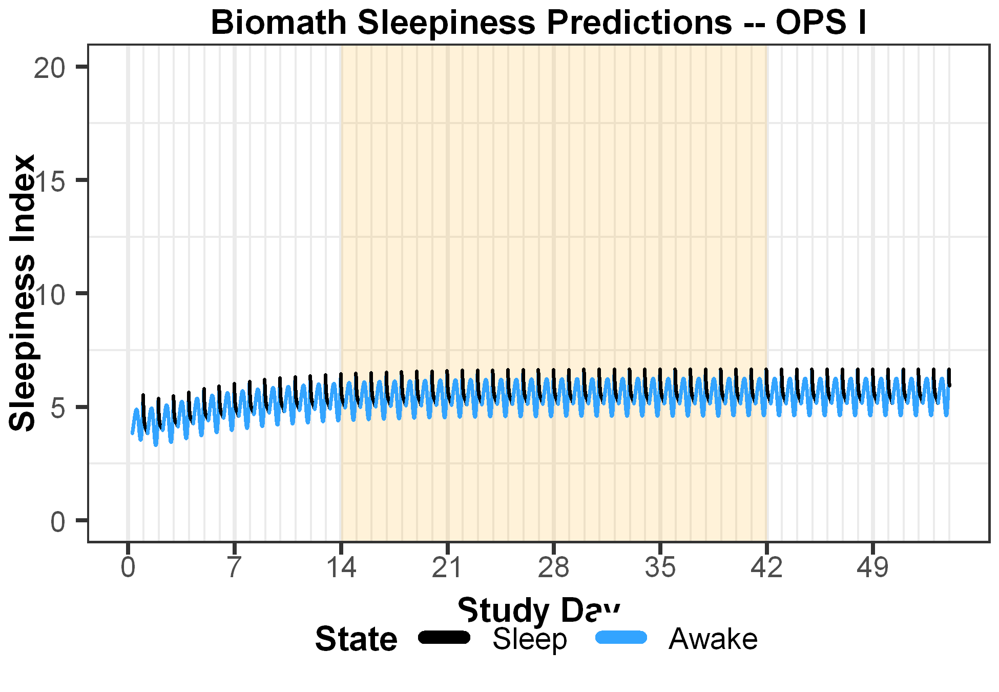

In [152]:
#(print-hash-table-ordered (set-schedule '((6.00 23.00) (30.00 47.00) (54.00 71.00) (78.00 95.00) (102.00 119.00) (126.00 143.00) (150.00 167.00) (174.00 191.00) (198.00 215.00) (222.00 239.00) (246.00 263.00) (270.00 287.00) (294.00 311.00) (318.00 335.00) (342.00 359.00) (366.00 383.00) (390.00 407.00) (414.00 431.00) (438.00 455.00) (462.00 479.00) (486.00 503.00) (510.00 527.00) (534.00 551.00) (558.00 575.00) (582.00 599.00) (606.00 623.00) (630.00 647.00) (654.00 671.00) (678.00 695.00) (702.00 719.00) (726.00 743.00) (750.00 767.00) (774.00 791.00) (798.00 815.00) (822.00 839.00) (846.00 863.00) (870.00 887.00) (894.00 911.00) (918.00 935.00) (942.00 959.00) (966.00 983.00) (990.00 1007.00) (1014.00 1031.00) (1038.00 1055.00) (1062.00 1079.00) (1086.00 1103.00) (1110.00 1127.00) (1134.00 1151.00) (1158.00 1175.00) (1182.00 1199.00) (1206.00 1223.00) (1230.00 1247.00) (1254.00 1271.00) (1278.00 1295.00) (1302.00 1319.00) (1326.00 1343.00) (1350.00 1367.00) (1374.00 1391.00) (1398.00 1415.00) (1422.00 1439.00) (1446.00 1463.00) (1470.00 1487.00) (1494.00 1511.00) (1518.00 1535.00) (1542.00 1559.00) (1566.00 1583.00) (1590.00 1607.00) (1614.00 1631.00) (1638.00 1655.00) (1662.00 1679.00) (1686.00 1703.00) (1710.00 1727.00) (1734.00 1751.00) (1758.00 1775.00) (1782.00 1799.00) (1806.00 1823.00) (1830.00 1847.00) (1854.00 1871.00) (1878.00 1895.00) (1902.00 1919.00) (1926.00 1943.00) (1950.00 1967.00) (1974.00 1991.00) (1998.00 2015.00) (2022.00 2039.00) (2046.00 2063.00))) "fatigue_alertness_OPSI_avg.txt")

sleep <- read.table("fatigue_alertness_OPSI_avg.txt", header = TRUE)

sleep <- sleep %>%
  filter(hour <= 1296) %>%
  arrange(hour) %>%
  mutate(
    day = hour / 24,
    state = factor(
      awake,
      levels = c(0, 1),
      labels = c("Sleep", "Awake")
    ),
    state_run = cumsum(state != lag(state, default = first(state)))
  )

ds_sleep <- function(dat, every_n = 5) {
  dat %>%
    group_by(state_run) %>%
    mutate(row_in_run = row_number()) %>%
    filter(
      row_in_run == 1 |
      row_in_run == n() |
      row_in_run %% every_n == 0
    ) %>%
    ungroup() %>%
    select(-row_in_run)
}

sleep_ds <- sleep %>%
  ds_sleep(every_n = 5)

options(repr.plot.width = 3.25, repr.plot.height = 2.25, repr.plot.res = 600)

ops1_sleep_ds_plot <- ggplot(
  sleep_ds,
  aes(x = day, y = alertness)
) +
  annotate("rect", xmin = 14, xmax = 42, ymin = -Inf, ymax = Inf, alpha = 0.15, fill = "orange") +
  geom_line(
    aes(color = state, group = state_run),
    linewidth = 0.4,
    lineend = "round"
  ) +
  labs(
    y = "Sleepiness Index",
    x = "Study Day",
    color = "State",
    title = "Biomath Sleepiness Predictions -- OPS I"
  ) +
  scale_x_continuous(
    breaks = seq(0, 54, by = 7),
    minor_breaks = seq(0, 54, by = 1),
    limits = c(0, 54)
  ) +
  scale_color_manual(
    values = c("Sleep" = "#000000", "Awake" = "#33A4FF")
  ) +
  guides(
    color = guide_legend(override.aes = list(linewidth = 1.5))
  ) +
  coord_cartesian(ylim = c(0, 20)) +
  theme_bw() +
  theme(
    text = element_text(size = 8, face = "bold"),
    plot.title = element_text(size = 8, hjust = 0.5),
    axis.text.x = element_text(size = 7, face = "plain", margin=margin(0,0,0,0)),
    axis.title.x = element_text(size = 8),
    axis.text.y = element_text(size = 7, face = "plain"),
    axis.title.y = element_text(size = 8),
    strip.text = element_text(face = "bold", size = 7),
    legend.position = "bottom",
    panel.grid.major.y = element_blank(),
    legend.title = element_text(size = 8, face = "bold"),
    legend.text = element_text(size = 7, face = "plain"),
    legend.key.size = unit(0.8, "lines"),
    legend.margin = margin(-10, 0, 5, 0),
    legend.box.margin = margin(0, 0, 0, 0),
    plot.margin = margin(2, 2, 2, 2)
  )

ops1_sleep_ds_plot

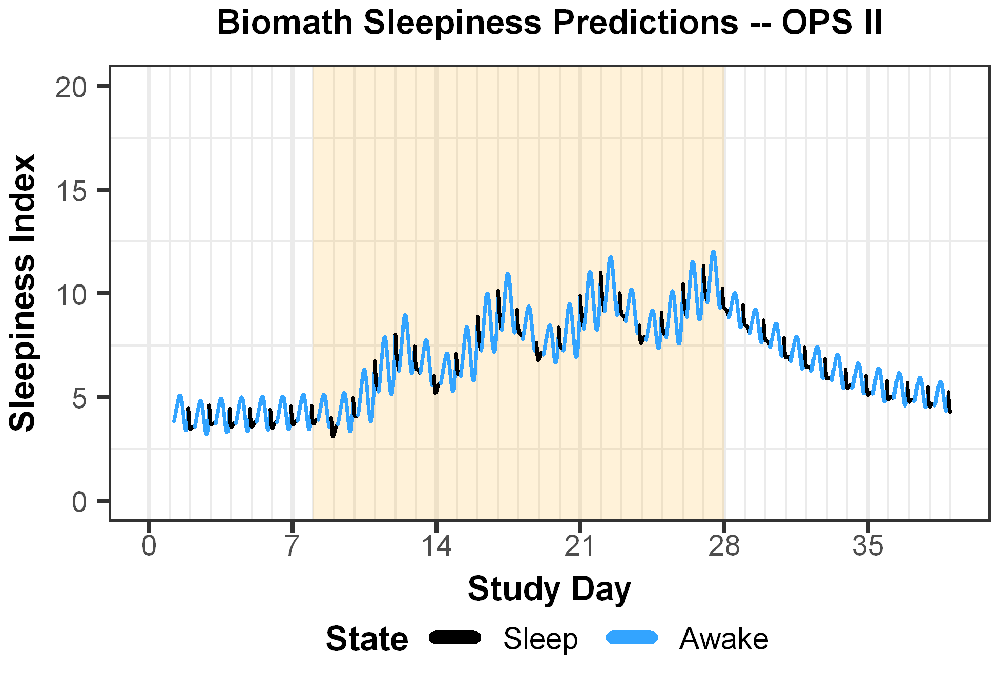

In [153]:


#(print-hash-table-ordered (set-schedule '((5.00 21.92) (29.46 46.34) (53.63 70.00) (77.45 93.92) (101.49 117.75) (125.39 141.97) (149.38 165.99) (173.53 188.90) (196.53 214.54) (220.01 239.73) (244.03 263.77) (267.96 286.21) (292.65 308.86) (316.55 334.73) (339.91 359.89) (363.97 383.84) (387.94 405.94) (412.54 428.77) (436.56 454.63) (459.94 479.78) (483.93 503.66) (507.99 525.89) (532.59 548.74) (556.54 574.65) (579.97 599.72) (603.98 623.50) (628.02 645.71) (653.35 669.88) (677.52 693.91) (701.55 717.65) (725.42 741.85) (749.62 765.71) (773.35 789.68) (797.58 813.65) (821.33 837.82) (845.47 861.94) (869.74 885.83) (893.72 909.72) (916.59 935.96) (942.03 960.42) (966.08 982.92) (987.53 1007.29))) "fatigue_alertness_OPSII_avg.txt")

sleep = read.table('fatigue_alertness_OPSII_avg.txt', header=T)

sleep <- sleep %>%
  filter(hour <= 912) %>%
  arrange(hour) %>%
  mutate(
    day = 1 + (hour / 24),
    state = factor(
      awake,
      levels = c(0, 1),
      labels = c("Sleep", "Awake")
    ),
    state_run = cumsum(state != lag(state, default = first(state)))
  )

ds_sleep <- function(dat, every_n = 5) {
  dat %>%
    group_by(state_run) %>%
    mutate(row_in_run = row_number()) %>%
    filter(
      row_in_run == 1 |
      row_in_run == n() |
      row_in_run %% every_n == 0
    ) %>%
    ungroup() %>%
    select(-row_in_run)
}

sleep_ds <- sleep %>%
  ds_sleep(every_n = 5)

options(repr.plot.width = 3.25, repr.plot.height = 2.25, repr.plot.res = 600)

ops2_sleep_ds_plot <- ggplot(
  sleep_ds,
  aes(x = day, y = alertness)
) +
  annotate("rect", xmin = 8, xmax = 28, ymin = -Inf, ymax = Inf, alpha = 0.15, fill = "orange") +
  geom_line(
    aes(color = state, group = state_run),
    linewidth = 0.4,
    lineend = "round"
  ) +
  labs(
    y = "Sleepiness Index",
    x = "Study Day",
    color = "State",
    title = "Biomath Sleepiness Predictions -- OPS II"
  ) +
  scale_x_continuous(
    breaks = seq(0, 39, by = 7),
    minor_breaks = seq(0, 39, by = 1),
    limits = c(0, 39)
  ) +
  scale_color_manual(
    values = c("Sleep" = "#000000", "Awake" = "#33A4FF")
  ) +
  guides(
    color = guide_legend(override.aes = list(linewidth = 1.5))
  ) +
  coord_cartesian(ylim = c(0, 20)) +
  theme_bw() +
  theme(
    text = element_text(size = 8, face = "bold"),
    plot.title = element_text(size = 8, hjust = 0.5),
    axis.text.x = element_text(size = 7, face = "plain", margin=margin(0,0,0,0)),
    axis.title.x = element_text(size = 8),
    axis.text.y = element_text(size = 7, face = "plain"),
    axis.title.y = element_text(size = 8),
    strip.text = element_text(face = "bold", size = 7),
    legend.position = "bottom",
    panel.grid.major.y = element_blank(),
    legend.title = element_text(size = 8, face = "bold"),
    legend.text = element_text(size = 7, face = "plain"),
    legend.key.size = unit(0.8, "lines"),
    legend.margin = margin(-10, 0, 5, 0),
    legend.box.margin = margin(0, 0, 0, 0),
    plot.margin = margin(2, 2, 2, 2)
  )

ops2_sleep_ds_plot

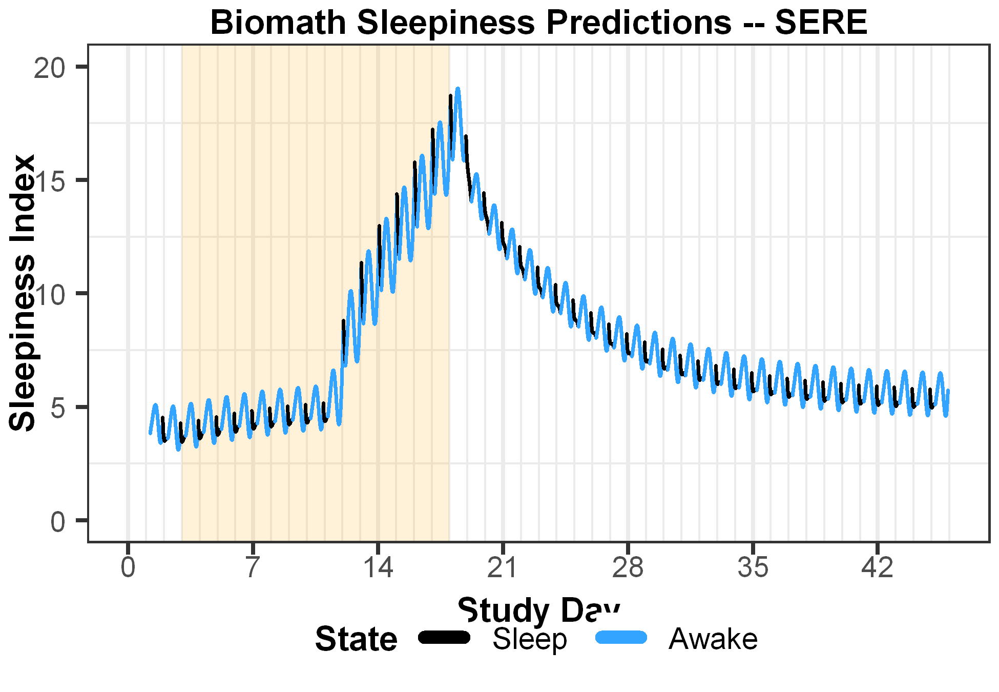

In [154]:


#(print-hash-table-ordered (set-schedule '((5.00 22.00) (29.00 46.00) (53.00 70.00) (77.00 94.00) (101.00 118.00) (125.00 142.00) (149.00 166.00) (173.00 190.00) (197.00 214.00) (221.00 238.00) (244.00 265.00) (268.00 289.00) (292.00 313.00) (316.00 337.00) (340.00 361.00) (364.00 385.00) (388.00 409.00) (412.00 430.00) (437.00 454.00) (461.00 478.00) (485.00 502.00) (509.00 526.00) (533.00 550.00) (557.00 574.00) (581.00 598.00) (605.00 622.00) (629.00 646.00) (653.00 670.00) (677.00 694.00) (701.00 718.00) (725.00 742.00) (749.00 766.00) (773.00 790.00) (797.00 814.00) (821.00 838.00) (845.00 862.00) (869.00 886.00) (893.00 910.00) (917.00 934.00) (941.00 958.00) (965.00 982.00) (989.00 1006.00) (1013.00 1030.00) (1037.00 1054.00) (1061.00 1078.00))) "fatigue_alertness_SERE_avg.txt")

sleep <- read.table("fatigue_alertness_SERE_avg.txt", header = TRUE)

sleep <- sleep %>%
  filter(hour <= 1080) %>%
  arrange(hour) %>%
  mutate(
    day = 1 + (hour / 24),
    state = factor(
      awake,
      levels = c(0, 1),
      labels = c("Sleep", "Awake")
    ),
    state_run = cumsum(state != lag(state, default = first(state)))
  )

ds_sleep <- function(dat, every_n = 5) {
  dat %>%
    group_by(state_run) %>%
    mutate(row_in_run = row_number()) %>%
    filter(
      row_in_run == 1 |
      row_in_run == n() |
      row_in_run %% every_n == 0
    ) %>%
    ungroup() %>%
    select(-row_in_run)
}

sleep_ds <- sleep %>%
  ds_sleep(every_n = 5)

options(repr.plot.width = 3.25, repr.plot.height = 2.25, repr.plot.res = 600)

sere_sleep_ds_plot <- ggplot(
  sleep_ds,
  aes(x = day, y = alertness)
) +
  annotate("rect", xmin = 3, xmax = 18, ymin = -Inf, ymax = Inf, alpha = 0.15, fill = "orange") +
  geom_line(
    aes(color = state, group = state_run),
    linewidth = 0.4,
    lineend = "round"
  ) +
  labs(
    y = "Sleepiness Index",
    x = "Study Day",
    color = "State",
    title = "Biomath Sleepiness Predictions -- SERE"
  ) +
  scale_x_continuous(
    breaks = seq(0, 46, by = 7),
    minor_breaks = seq(0, 46, by = 1),
    limits = c(0, 46)
  ) +
  scale_color_manual(
    values = c("Sleep" = "#000000", "Awake" = "#33A4FF")
  ) +
  guides(
    color = guide_legend(override.aes = list(linewidth = 1.5))
  ) +
  coord_cartesian(ylim = c(0, 20)) +
  theme_bw() +
  theme(
    text = element_text(size = 8, face = "bold"),
    plot.title = element_text(size = 8, hjust = 0.5),
    axis.text.x = element_text(size = 7, face = "plain", margin=margin(0,0,0,0)),
    axis.title.x = element_text(size = 8),
    axis.text.y = element_text(size = 7, face = "plain"),
    axis.title.y = element_text(size = 8),
    strip.text = element_text(face = "bold", size = 7),
    legend.position = "bottom",
    panel.grid.major.y = element_blank(),
    legend.title = element_text(size = 8, face = "bold"),
    legend.text = element_text(size = 7, face = "plain"),
    legend.key.size = unit(0.8, "lines"),
    legend.margin = margin(-10, 0, 5, 0),
    legend.box.margin = margin(0, 0, 0, 0),
    plot.margin = margin(2, 2, 2, 2)
  )

sere_sleep_ds_plot

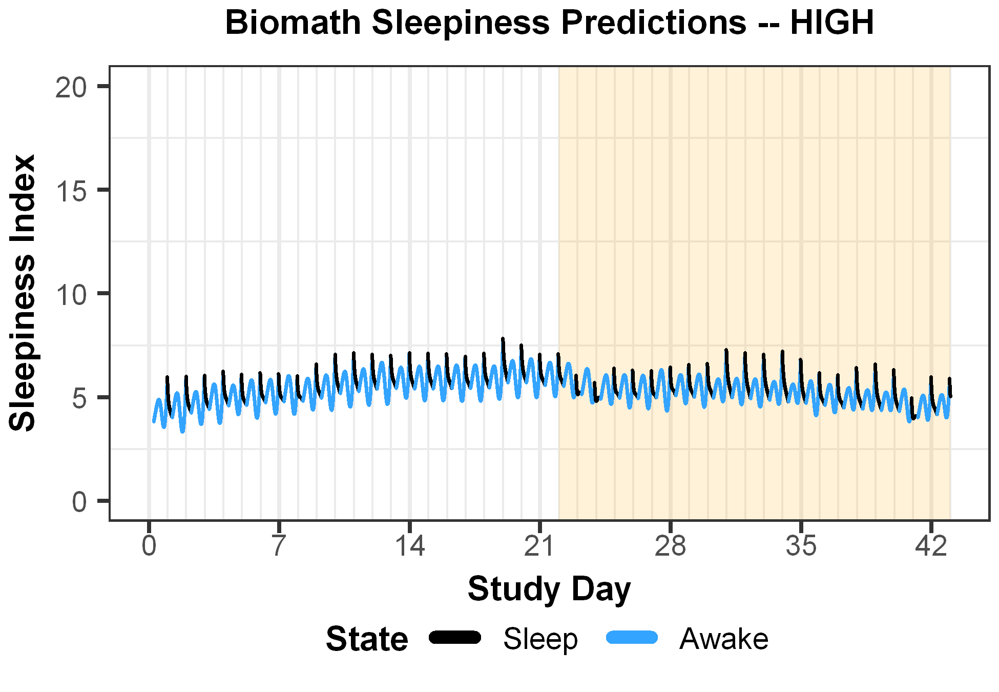

In [155]:
sleep <- read.table("fatigue_alertness_HIGH_avg.txt", header = TRUE)

sleep <- sleep %>%
  filter(hour <= 1032) %>%
  arrange(hour) %>%
  mutate(
    day = hour / 24,
    state = factor(
      awake,
      levels = c(0, 1),
      labels = c("Sleep", "Awake")
    ),
    state_run = cumsum(state != lag(state, default = first(state)))
  )

ds_sleep <- function(dat, every_n = 5) {
  dat %>%
    group_by(state_run) %>%
    mutate(row_in_run = row_number()) %>%
    filter(
      row_in_run == 1 |
      row_in_run == n() |
      row_in_run %% every_n == 0
    ) %>%
    ungroup() %>%
    select(-row_in_run)
}

sleep_ds <- sleep %>%
  ds_sleep(every_n = 5)

options(repr.plot.width = 3.25, repr.plot.height = 2.25, repr.plot.res = 600)

high_sleep_ds_plot <- ggplot(
  sleep_ds,
  aes(x = day, y = alertness)
) +
  annotate("rect", xmin = 22, xmax = 43, ymin = -Inf, ymax = Inf, alpha = 0.15, fill = "orange") +
  geom_line(
    aes(color = state, group = state_run),
    linewidth = 0.4,
    lineend = "round"
  ) +
  labs(
    y = "Sleepiness Index",
    x = "Study Day",
    color = "State",
    title = "Biomath Sleepiness Predictions -- HIGH"
  ) +
  scale_x_continuous(
    breaks = seq(0, 43, by = 7),
    minor_breaks = seq(0, 43, by = 1),
    limits = c(0, 43)
  ) +
  scale_color_manual(
    values = c("Sleep" = "#000000", "Awake" = "#33A4FF")
  ) +
  guides(
    color = guide_legend(override.aes = list(linewidth = 1.5))
  ) +
  coord_cartesian(ylim = c(0, 20)) +
  theme_bw() +
  theme(
    text = element_text(size = 8, face = "bold"),
    plot.title = element_text(size = 8, hjust = 0.5),
    axis.text.x = element_text(size = 7, face = "plain", margin=margin(0,0,0,0)),
    axis.title.x = element_text(size = 8),
    axis.text.y = element_text(size = 7, face = "plain"),
    axis.title.y = element_text(size = 8),
    strip.text = element_text(face = "bold", size = 7),
    legend.position = "bottom",
    panel.grid.major.y = element_blank(),
    legend.title = element_text(size = 8, face = "bold"),
    legend.text = element_text(size = 7, face = "plain"),
    legend.key.size = unit(0.8, "lines"),
    legend.margin = margin(-10, 0, 5, 0),
    legend.box.margin = margin(0, 0, 0, 0),
    plot.margin = margin(2, 2, 2, 2)
  )

high_sleep_ds_plot

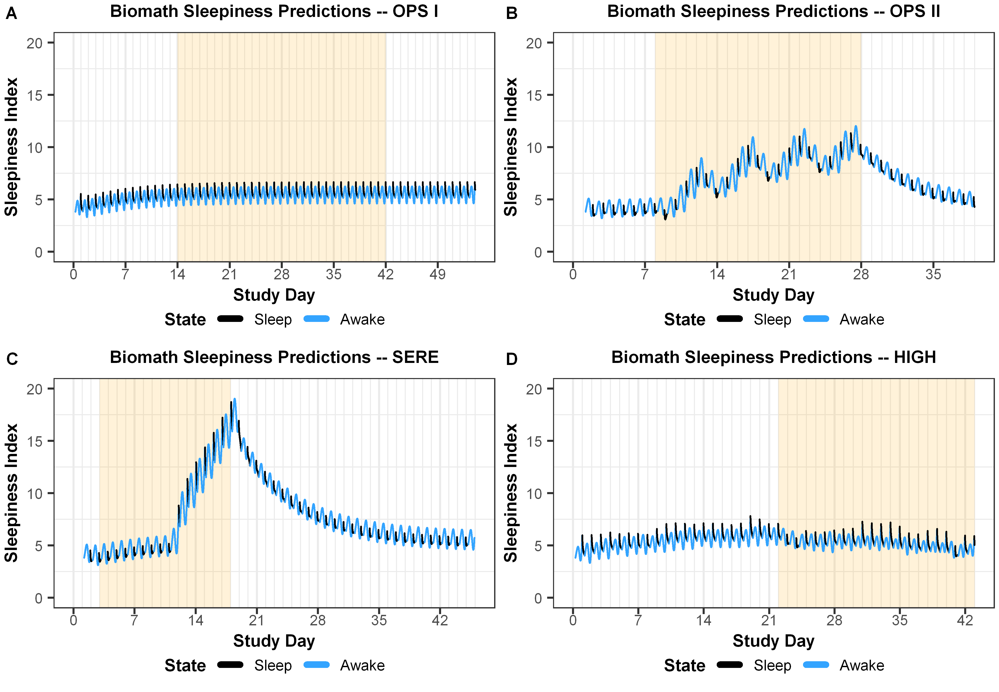

In [156]:
options(repr.plot.width=6.5, repr.plot.height=4.5, repr.plot.res=600)
all_sleep_ds_plot <- cowplot::plot_grid(
  ops1_sleep_ds_plot,
  ops2_sleep_ds_plot,
  sere_sleep_ds_plot,
  high_sleep_ds_plot,
  ncol = 2,
  labels = c("A", "B", "C", "D"),
  label_size = 8,
  align = "none"
)

all_sleep_ds_plot

In [157]:
ggsave("all_sleep_ds_plot.png", all_sleep_ds_plot, width = 6.5, height = 4.5, dpi = 600)

In [158]:
ggsave(
  "all_sleep_ds_plot.svg",
  all_sleep_ds_plot,
  width = 6.5,
  height = 4.5,
  device = "svg"
)

In [159]:
ggsave(
  "all_sleep_ds_plot.pdf",
  all_sleep_ds_plot,
  width = 6.5,
  height = 4.5,
  device = cairo_pdf
)

# Analyze Compu-Cognome

In [180]:
# Read compucognome data -- all studies ----------------------------------------------------------------------------
cc_dat_all <- read_csv("./ROPER_CompuCognome_FullData_AllStudies_Merged.csv")


# Read compucognome data -- only OPSI OPSII and SERE  --------------------------------------------------------------
cc_dat <- read_csv("./ROPER_CompuCognome_FullData.csv")

Rows: 503 Columns: 23
── Column specification ────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: ","
chr  (4): study, subjectid, phase, study_event_id
dbl (19): bout, kl_val, mle_val, dat, egs, ut, iu, utmc, utbmc, fpdec, fpmc,...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 435 Columns: 22
── Column specification ────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: ","
chr  (4): study, subjectid, phase, study_event_id
dbl (18): bout, kl_val, dat, egs, ut, iu, utmc, utbmc, fpdec, fpmc, fpbmc, f...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [181]:
head(cc_dat_all)
head(cc_dat)

study,subjectid,phase,study_event_id,bout,kl_val,mle_val,dat,egs,ut,⋯,fpdec,fpmc,fpbmc,fdbmc,fdc,fddec,ans,bll,mp,lf
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HIGH,ROP072,Baseline,B1,181,0.07221468,-16.443619,0.05,0.31,2.82,⋯,0.98,-0.01,0.03,-0.015,0.95,1.00,0.35,0.43,1.11,1.05
HIGH,ROP072,Stress,A1,541,0.06394576,-18.736629,0.06,0.28,2.53,⋯,0.99,-0.09,0.01,-0.015,0.92,0.97,0.32,0.45,0.92,0.88
HIGH,ROP072,Stress,A2,781,0.02917387,-18.419635,0.06,0.23,2.48,⋯,1.00,-0.09,0.03,-0.025,0.91,0.96,0.40,0.56,1.14,0.81
HIGH,ROP072,Stress,A3,1045,0.16473468,-18.316889,0.06,0.27,2.66,⋯,1.00,-0.03,0.01,-0.035,0.91,0.97,0.40,0.40,1.06,1.01
HIGH,ROP081,Baseline,B1,181,0.20620817,-9.778598,0.06,0.28,2.54,⋯,1.00,-0.02,0.02,-0.005,0.97,0.99,0.21,0.57,1.05,0.81
HIGH,ROP081,Stress,A1,541,0.15807974,-12.040918,0.05,0.36,2.21,⋯,0.98,-0.10,0.04,-0.045,0.97,1.00,0.33,0.42,1.00,1.07


study,subjectid,phase,study_event_id,bout,kl_val,dat,egs,ut,iu,⋯,fpdec,fpmc,fpbmc,fdbmc,fdc,fddec,ans,bll,mp,lf
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
OPSI,ROP166,Baseline,Day 13,322,-7.176697,0.06,0.36,2.29,2.51,⋯,1.00,-0.10,0.03,-0.005,0.98,0.97,0.35,0.56,1.01,0.86
OPSI,ROP166,Stress,Day 41,998,-3.220628,0.06,0.40,2.98,2.10,⋯,1.00,-0.07,0.02,-0.045,0.93,0.97,0.37,0.51,0.99,1.06
OPSI,ROP166,Recovery,EOS,1450,-11.930742,0.06,0.37,2.66,2.11,⋯,1.00,-0.04,0.03,-0.035,0.99,0.99,0.11,0.49,0.98,0.82
OPSI,ROP167,Baseline,Day 13,322,-10.216961,0.06,0.27,2.11,2.58,⋯,1.00,-0.06,0.03,-0.005,0.91,0.99,0.15,0.52,1.07,0.82
OPSI,ROP167,Stress,Day 41,996,-20.131307,0.06,0.20,2.41,2.48,⋯,0.99,-0.02,0.04,-0.035,0.94,0.97,0.13,0.48,0.82,1.05
OPSI,ROP167,Recovery,EOS,1642,-11.832063,0.06,0.32,2.30,2.79,⋯,0.99,-0.10,0.03,-0.045,0.98,0.97,0.14,0.55,1.10,0.86


In [183]:
cc_dat_all <- cc_dat_all %>%
  filter(!(study == "HIGH" & study_event_id %in% c("A1", "A2")))

study,parameter,value
<chr>,<fct>,<dbl>
HIGH,dat,0.050
HIGH,egs,0.310
HIGH,ut,2.820
HIGH,iu,2.220
HIGH,utmc,-0.100
HIGH,utbmc,0.030
HIGH,fpdec,0.980
HIGH,fpmc,-0.010
HIGH,fpbmc,0.030


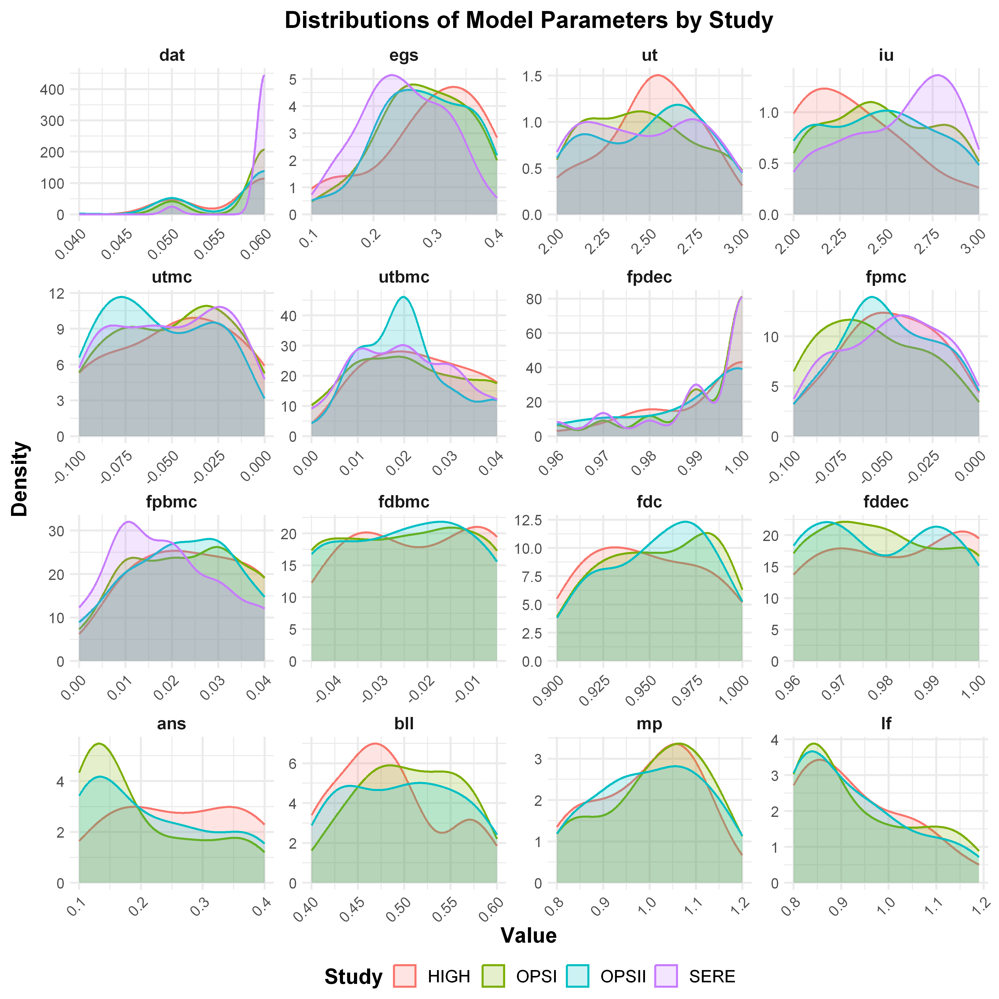

In [45]:
options(repr.plot.width=6.5, repr.plot.height=6.5, repr.plot.res=600)

# Reshape to long format for ggplot ----------------------------------------
vars_of_interest <- c("dat", "egs", "ut", "iu", 
                      "utmc", "utbmc", "fpdec", "fpmc", "fpbmc",
                      "fdbmc", "fdc", "fddec", 
                      "ans", "bll", "mp", "lf")

plot_dat <- cc_dat_all %>%
  select(study, all_of(vars_of_interest)) %>%
  pivot_longer(
    cols = -study,
    names_to = "parameter",
    values_to = "value"
  ) %>%
  drop_na(value) %>%
  mutate(
    parameter = factor(parameter, levels = vars_of_interest)
  )

subset(plot_dat, study=="HIGH")


# Plot distributions comparing studies -------------------------------------
p <- ggplot(plot_dat, aes(x = value, colour = study, fill = study)) +
  geom_density(alpha = 0.2, adjust = 1.2, na.rm = TRUE) +
  facet_wrap(~ parameter, scales = "free", ncol = 4) +
  labs(
    title = "Distributions of Model Parameters by Study",
    x = "Value",
    y = "Density",
    colour = "Study",
    fill = "Study"
  ) +
  theme_minimal(base_size = 10) +
  theme(plot.title = element_text(size=11, hjust = 0.5, face = "bold"),
        axis.text.x = element_text(size=7, vjust = 1, hjust = 1, angle=45, margin = margin(t = 0, b = 0)),
        axis.title.x = element_text(size=10, margin=margin(0,0,0,0), face = "bold"),
        axis.text.y = element_text(size=7, margin=margin(0,0,0,0)),
        axis.title.y = element_text(size=10, margin=margin(0,4,0,0), face = "bold"),
        legend.text = element_text(size=8, face="plain"),
        legend.title = element_text(size=10, face="bold"),
        strip.text = element_text(face = "bold", margin = margin(t = 1, b=2)),
        legend.position = "bottom",
        legend.margin = margin(t = -2),
        legend.key.size   = unit(0.8, "lines"),
        panel.spacing.x = unit(0.2, "lines"), panel.spacing.y = unit(0.0, "lines")
       )

p

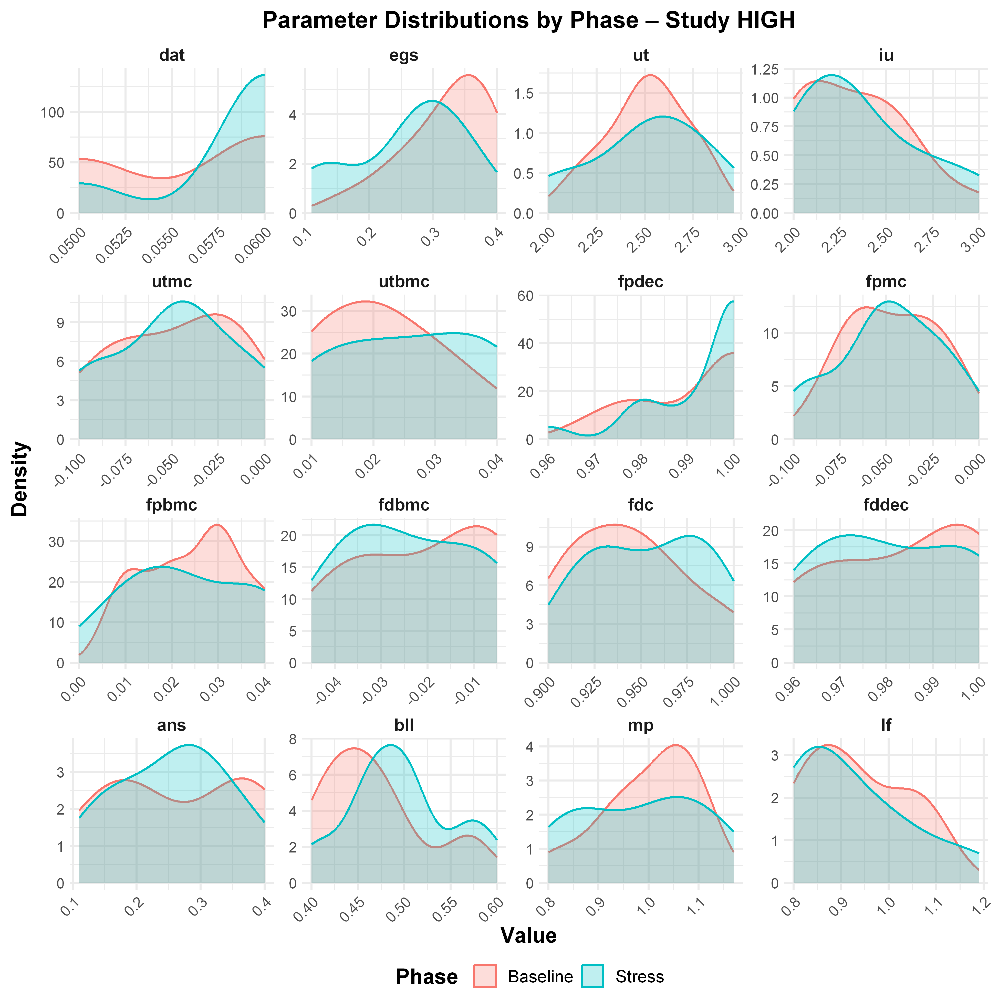

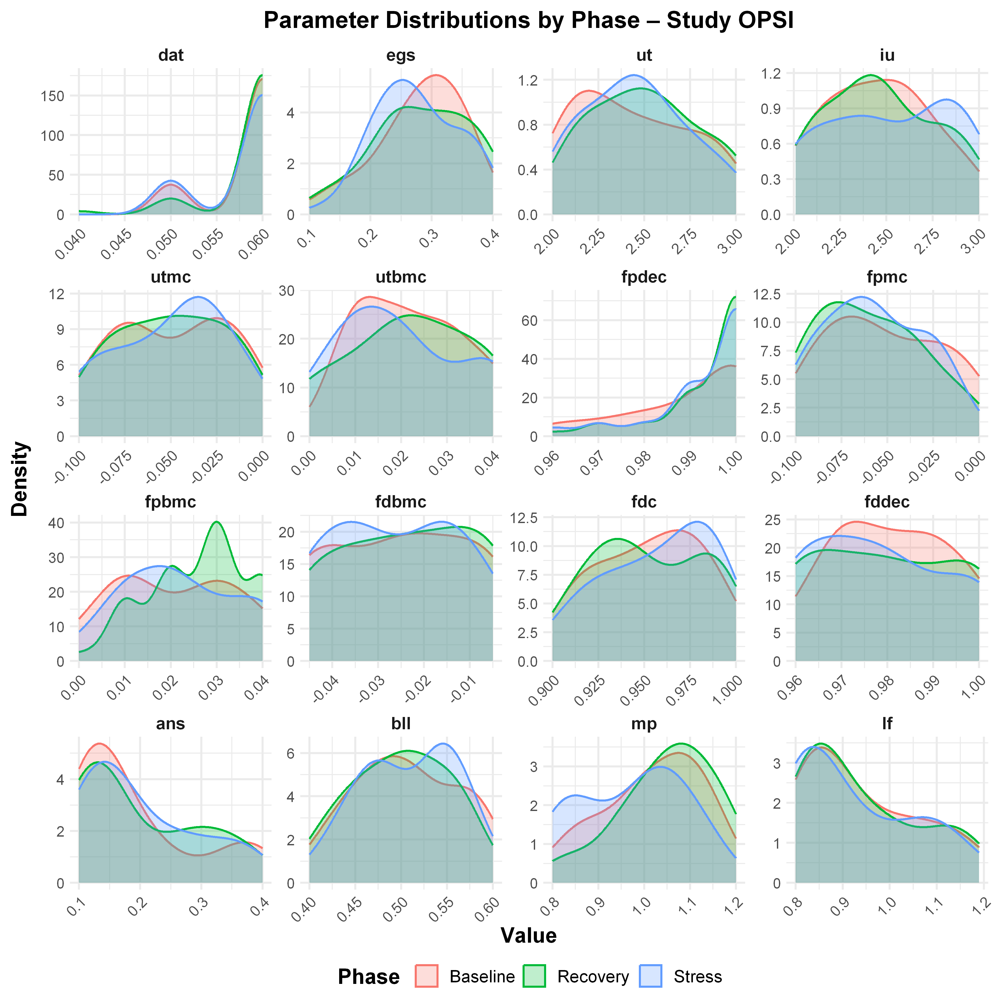

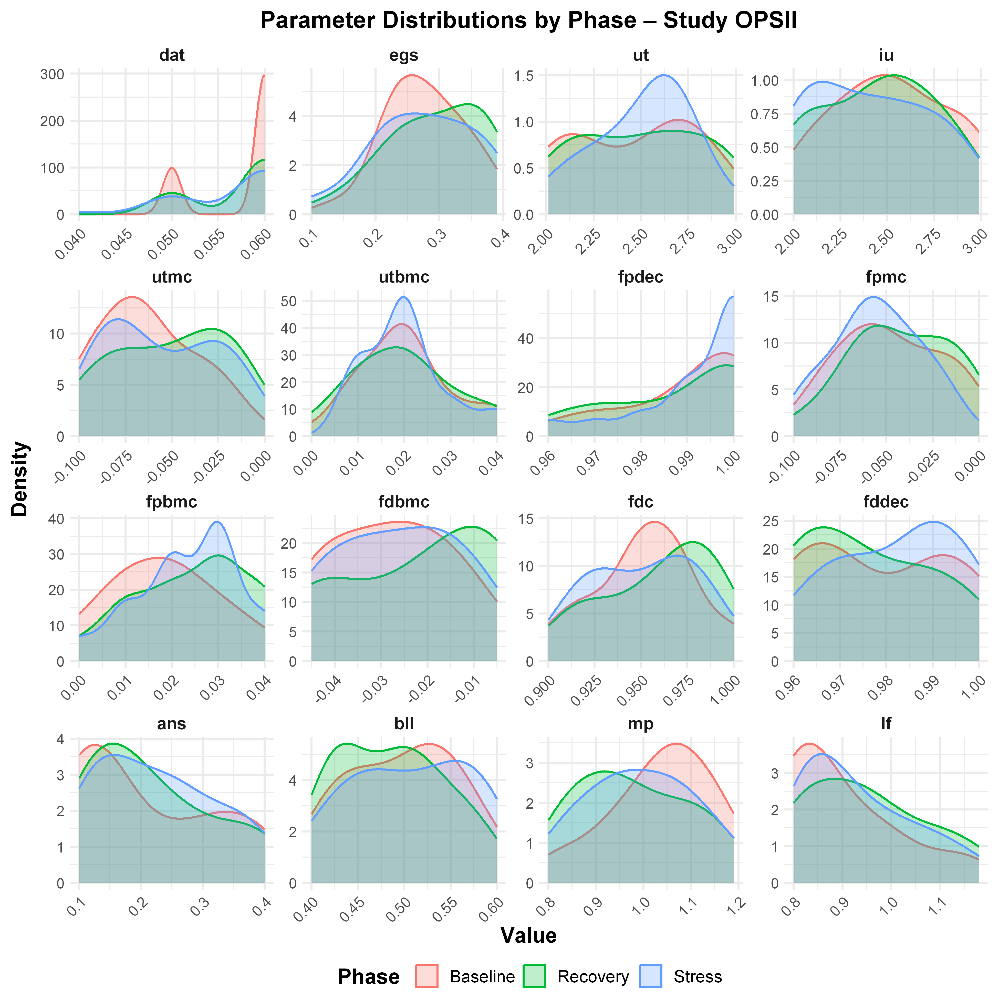

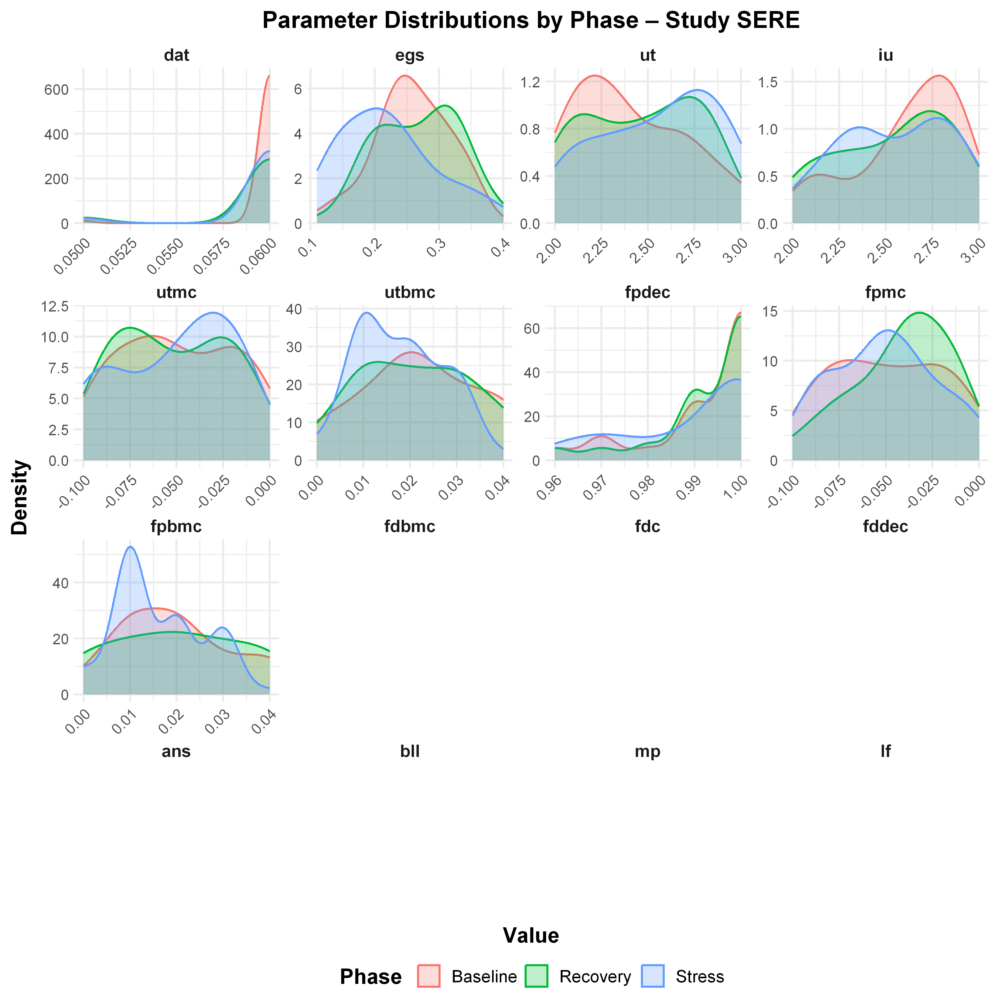

In [46]:
options(repr.plot.width=6.5, repr.plot.height=6.5, repr.plot.res=600)

# Variables to visualize
vars_of_interest <- c("dat", "egs", "ut", "iu", 
                      "utmc", "utbmc", "fpdec", "fpmc", "fpbmc",
                      "fdbmc", "fdc", "fddec", 
                      "ans", "bll", "mp", "lf")

# Long format with study + phase ------------------------------------------
plot_dat <- cc_dat_all %>%
  select(study, phase, all_of(vars_of_interest)) %>%
  pivot_longer(
    cols = all_of(vars_of_interest),
    names_to = "parameter",
    values_to = "value"
  ) %>%
  #drop_na(value) %>%
  mutate(
    parameter = factor(parameter, levels = vars_of_interest)
  )

# Create one plot per study, comparing phases ------------------------------
plots_by_study <- plot_dat %>%
  group_by(study) %>%
  group_map(~ {
    ggplot(.x, aes(x = value, colour = phase, fill = phase)) +
      geom_density(alpha = 0.25, adjust = 1.2, na.rm = TRUE) +
      facet_wrap(~ parameter, scales = "free", ncol = 4) +
      labs(
        title = paste0("Parameter Distributions by Phase – Study ", .y$study),
        x = "Value",
        y = "Density",
        colour = "Phase",
        fill = "Phase"
      ) +
      theme_minimal(base_size = 10) +
      theme(plot.title = element_text(size=11, hjust = 0.5, face = "bold"),
        axis.text.x = element_text(size=7, vjust = 1, hjust = 1, angle=45, margin = margin(t = 0, b = 0)),
        axis.title.x = element_text(size=10, margin=margin(0,0,0,0), face = "bold"),
        axis.text.y = element_text(size=7, margin=margin(0,0,0,0)),
        axis.title.y = element_text(size=10, margin=margin(0,4,0,0), face = "bold"),
        legend.text = element_text(size=8, face="plain"),
        legend.title = element_text(size=10, face="bold"),
        strip.text = element_text(face = "bold", margin = margin(t = 1, b=2)),
        legend.position = "bottom",
        legend.margin = margin(t = -2),
        legend.key.size   = unit(0.8, "lines"),
        panel.spacing.x = unit(0.2, "lines"), panel.spacing.y = unit(0.0, "lines")
       )
  })

# Print plots to the graphics device --------------------------------------
# This will print each study’s plot one after another
for (p in plots_by_study) {
  print(p)
}

# Correlation Plots

In [182]:
head(pvt_all_avg_data)
colnames(pvt_all_avg_data)
head(nback_all_avg_data)
colnames(nback_all_avg_data)

study,subjectid,phase,nfalsestart,nlapses,ntimeouts,nfslapse,nlapseto,ntotalerr,mrtime,meanrrt,delta_stress_mrrt,delta_recovery_mrrt,Robustness_mrrt,Resilience_mrrt,delta_stress_fsl,delta_recovery_fsl,Robustness_fsl,Resilience_fsl
<fct>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
OPSI,ROP166,Baseline,1,41,24,42,65,94,507.4667,2.195648,-0.24080839,0.2043652,-0.10967531,0.09307738,17,-16,0.4047619,-0.3809524
OPSI,ROP166,Recovery,0,43,23,43,66,103,514.3007,2.159205,-0.24080839,0.2043652,-0.10967531,0.09307738,17,-16,0.4047619,-0.3809524
OPSI,ROP166,Stress,0,59,34,59,93,111,578.3280,1.954840,-0.24080839,0.2043652,-0.10967531,0.09307738,17,-16,0.4047619,-0.3809524
OPSI,ROP167,Baseline,0,3,0,3,3,7,344.1955,3.009092,-0.03107773,-0.2692449,-0.01032794,-0.08947713,-2,16,-0.6666667,5.3333333
OPSI,ROP167,Recovery,0,17,10,17,27,39,401.9325,2.708770,-0.03107773,-0.2692449,-0.01032794,-0.08947713,-2,16,-0.6666667,5.3333333
OPSI,ROP167,Stress,0,1,0,1,1,4,343.3427,2.978015,-0.03107773,-0.2692449,-0.01032794,-0.08947713,-2,16,-0.6666667,5.3333333


[1] "study"               "subjectid"           "phase"              
 [4] "nfalsestart"         "nlapses"             "ntimeouts"          
 [7] "nfslapse"            "nlapseto"            "ntotalerr"          
[10] "mrtime"              "meanrrt"             "delta_stress_mrrt"  
[13] "delta_recovery_mrrt" "Robustness_mrrt"     "Resilience_mrrt"    
[16] "delta_stress_fsl"    "delta_recovery_fsl"  "Robustness_fsl"     
[19] "Resilience_fsl"

study,subjectid,phase,SessBlockID,n,mrt,mrt_hit,mrt_fa,meanrrt,totalAcc,⋯,Robustness_mrt,Resilience_mrt,delta_stress_mrrt,delta_recovery_mrrt,Robustness_mrrt,Resilience_mrrt,delta_stress_dprime,delta_recovery_dprime,Robustness_dprime,Resilience_dprime
<fct>,<chr>,<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
OPSI,ROP166,Baseline,1,81,0.5911765,0.5846154,0.6125000,1.828670,0.8518519,⋯,0.1764677,-0.30495566,-0.3488922,0.5650985,-0.1907901,0.3090216,-1.485893,2.5850199,-0.8664855,1.5074322
OPSI,ROP166,Baseline,2,82,0.6633333,0.6977778,0.6375000,2.158970,0.7073171,⋯,0.1385877,-0.02542185,-0.7644056,0.5176728,-0.3540603,0.2397776,0.175783,-0.3299374,0.2615855,-0.4909852
OPSI,ROP166,Recovery,1,81,0.5152174,0.4715789,0.7225000,2.044876,0.9259259,⋯,0.1764677,-0.30495566,-0.3488922,0.5650985,-0.1907901,0.3090216,-1.485893,2.5850199,-0.8664855,1.5074322
OPSI,ROP166,Recovery,2,82,0.7384000,0.7355556,0.7400000,1.912237,0.6707317,⋯,0.1385877,-0.02542185,-0.7644056,0.5176728,-0.3540603,0.2397776,0.175783,-0.3299374,0.2615855,-0.4909852
OPSI,ROP166,Stress,1,81,0.6955000,0.6683333,0.7071429,1.479778,0.6543210,⋯,0.1764677,-0.30495566,-0.3488922,0.5650985,-0.1907901,0.3090216,-1.485893,2.5850199,-0.8664855,1.5074322
OPSI,ROP166,Stress,2,82,0.7552632,0.7700000,0.7420000,1.394564,0.7439024,⋯,0.1385877,-0.02542185,-0.7644056,0.5176728,-0.3540603,0.2397776,0.175783,-0.3299374,0.2615855,-0.4909852


[1] "study"                 "subjectid"             "phase"                
 [4] "SessBlockID"           "n"                     "mrt"                  
 [7] "mrt_hit"               "mrt_fa"                "meanrrt"              
[10] "totalAcc"              "accFoil"               "accTarget"            
[13] "nhit"                  "nmiss"                 "nfa"                  
[16] "ncr"                   "hr"                    "far"                  
[19] "hr_adj"                "far_adj"               "zhr"                  
[22] "zfar"                  "dprime"                "delta_stress_mrt"     
[25] "delta_recovery_mrt"    "Robustness_mrt"        "Resilience_mrt"       
[28] "delta_stress_mrrt"     "delta_recovery_mrrt"   "Robustness_mrrt"      
[31] "Resilience_mrrt"       "delta_stress_dprime"   "delta_recovery_dprime"
[34] "Robustness_dprime"     "Resilience_dprime"

In [184]:
join_keys <- c("study", "subjectid", "phase")

pvt_dv_cols <- c(
  "nfslapse",
  "meanrrt",
  "delta_stress_mrrt",
  "delta_recovery_mrrt",
  "Robustness_mrrt",
  "Resilience_mrrt",
  "delta_stress_fsl",
  "delta_recovery_fsl",
  "Robustness_fsl",
  "Resilience_fsl"
)

nback_dv_cols <- c(
  "mrt",
  "meanrrt",
  "dprime",
  "delta_stress_mrt",
  "delta_recovery_mrt",
  "Robustness_mrt",
  "Resilience_mrt",
  "delta_stress_mrrt",
  "delta_recovery_mrrt",
  "Robustness_mrrt",
  "Resilience_mrrt",
  "delta_stress_dprime",
  "delta_recovery_dprime",
  "Robustness_dprime",
  "Resilience_dprime"
)

In [185]:
nback_selected <- nback_all_avg_data %>%
  ungroup() %>%
  mutate(
    nback_level = case_when(
      as.character(SessBlockID) == "1" ~ "1",
      as.character(SessBlockID) == "2" ~ "2",
      TRUE ~ paste0("block", SessBlockID)
    )
  ) %>%
  select(all_of(join_keys), nback_level, all_of(nback_dv_cols)) %>%
  pivot_wider(
    names_from = nback_level,
    values_from = all_of(nback_dv_cols),
    names_glue = "nback_{nback_level}_{.value}"
  )

pvt_selected <- pvt_all_avg_data %>%
  ungroup() %>%
  select(all_of(join_keys), all_of(pvt_dv_cols)) %>%
  rename_with(
    ~ paste0("pvt_", .x),
    .cols = all_of(pvt_dv_cols)
  )

In [186]:
merged_outcome_data <- full_join(
  pvt_selected,
  nback_selected,
  by = join_keys
)

In [187]:
head(subset(merged_outcome_data, study=="HIGH"))

study,subjectid,phase,pvt_nfslapse,pvt_meanrrt,pvt_delta_stress_mrrt,pvt_delta_recovery_mrrt,pvt_Robustness_mrrt,pvt_Resilience_mrrt,pvt_delta_stress_fsl,⋯,nback_1_Resilience_mrrt,nback_2_Resilience_mrrt,nback_1_delta_stress_dprime,nback_2_delta_stress_dprime,nback_1_delta_recovery_dprime,nback_2_delta_recovery_dprime,nback_1_Robustness_dprime,nback_2_Robustness_dprime,nback_1_Resilience_dprime,nback_2_Resilience_dprime
<fct>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HIGH,ROP072,Baseline,19,2.645845,-0.007943908,NA,-0.003002408,NA,-3,⋯,NA,NA,0.0000000,1.0133308,NA,NA,0.0000000,0.3723012,NA,NA
HIGH,ROP072,Stress,16,2.637901,-0.007943908,NA,-0.003002408,NA,-3,⋯,NA,NA,0.0000000,1.0133308,NA,NA,0.0000000,0.3723012,NA,NA
HIGH,ROP073,Baseline,18,2.650238,0.149765761,NA,0.056510301,NA,-9,⋯,NA,NA,0.5236290,0.2284842,NA,NA,0.3846068,1.3603523,NA,NA
HIGH,ROP073,Stress,9,2.800004,0.149765761,NA,0.056510301,NA,-9,⋯,NA,NA,0.5236290,0.2284842,NA,NA,0.3846068,1.3603523,NA,NA
HIGH,ROP074,Baseline,14,2.778496,-0.084559297,NA,-0.030433476,NA,2,⋯,NA,NA,-0.7981361,-0.2999757,NA,NA,-0.2879186,-0.1566762,NA,NA
HIGH,ROP074,Stress,16,2.693937,-0.084559297,NA,-0.030433476,NA,2,⋯,NA,NA,-0.7981361,-0.2999757,NA,NA,-0.2879186,-0.1566762,NA,NA


In [188]:
# Merge on common keys (adjust if your join keys differ)
dat_full <- cc_dat_all %>%
  inner_join(
    merged_outcome_data,
    by = c("study", "subjectid", "phase")
  )

# CompuCognome parameters
cc_params <- c("dat", "egs", "ut", "iu", 
              "utmc", "utbmc", "fpdec", "fpmc", "fpbmc",
              "fdbmc", "fdc", "fddec", 
              "ans", "bll", "mp", "lf")

outcome_delta_cols <- c(
  "pvt_delta_stress_mrrt",
  "pvt_delta_recovery_mrrt",
  "pvt_delta_stress_fsl",
  "pvt_delta_recovery_fsl",
  "nback_1_delta_stress_mrt",
  "nback_2_delta_stress_mrt",
  "nback_1_delta_recovery_mrt",
  "nback_2_delta_recovery_mrt",
  "nback_1_delta_stress_dprime",
  "nback_2_delta_stress_dprime",
  "nback_1_delta_recovery_dprime",
  "nback_2_delta_recovery_dprime"
)

In [189]:
colnames(dat_full)

[1] "study"                         "subjectid"                    
 [3] "phase"                         "study_event_id"               
 [5] "bout"                          "kl_val"                       
 [7] "mle_val"                       "dat"                          
 [9] "egs"                           "ut"                           
[11] "iu"                            "utmc"                         
[13] "utbmc"                         "fpdec"                        
[15] "fpmc"                          "fpbmc"                        
[17] "fdbmc"                         "fdc"                          
[19] "fddec"                         "ans"                          
[21] "bll"                           "mp"                           
[23] "lf"                            "pvt_nfslapse"                 
[25] "pvt_meanrrt"                   "pvt_delta_stress_mrrt"        
[27] "pvt_delta_recovery_mrrt"       "pvt_Robustness_mrrt"          
[29] "pvt_Resilience_mrrt"           "pvt_delta_stress_fsl"         
[31] "pvt_delta_recovery_fsl"        "pvt_Robustness_fsl"           
[33] "pvt_Resilience_fsl"            "nback_1_mrt"                  
[35] "nback_2_mrt"                   "nback_1_meanrrt"              
[37] "nback_2_meanrrt"               "nback_1_dprime"               
[39] "nback_2_dprime"                "nback_1_delta_stress_mrt"     
[41] "nback_2_delta_stress_mrt"      "nback_1_delta_recovery_mrt"   
[43] "nback_2_delta_recovery_mrt"    "nback_1_Robustness_mrt"       
[45] "nback_2_Robustness_mrt"        "nback_1_Resilience_mrt"       
[47] "nback_2_Resilience_mrt"        "nback_1_delta_stress_mrrt"    
[49] "nback_2_delta_stress_mrrt"     "nback_1_delta_recovery_mrrt"  
[51] "nback_2_delta_recovery_mrrt"   "nback_1_Robustness_mrrt"      
[53] "nback_2_Robustness_mrrt"       "nback_1_Resilience_mrrt"      
[55] "nback_2_Resilience_mrrt"       "nback_1_delta_stress_dprime"  
[57] "nback_2_delta_stress_dprime"   "nback_1_delta_recovery_dprime"
[59] "nback_2_delta_recovery_dprime" "nback_1_Robustness_dprime"    
[61] "nback_2_Robustness_dprime"     "nback_1_Resilience_dprime"    
[63] "nback_2_Resilience_dprime"

In [190]:
wide <- dat_full %>%
  select(
    study, subjectid, phase,
    all_of(cc_params),
    all_of(outcome_delta_cols)
  ) %>%
  pivot_wider(
    names_from  = phase,
    values_from = all_of(cc_params),
    names_glue  = "{.value}_{phase}"
  )

In [191]:
head(wide)

study,subjectid,pvt_delta_stress_mrrt,pvt_delta_recovery_mrrt,pvt_delta_stress_fsl,pvt_delta_recovery_fsl,nback_1_delta_stress_mrt,nback_2_delta_stress_mrt,nback_1_delta_recovery_mrt,nback_2_delta_recovery_mrt,⋯,ans_Recovery,bll_Baseline,bll_Stress,bll_Recovery,mp_Baseline,mp_Stress,mp_Recovery,lf_Baseline,lf_Stress,lf_Recovery
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HIGH,ROP072,-0.007943908,NA,-3,NA,-0.06318182,-0.152296651,NA,NA,⋯,NA,0.43,0.40,NA,1.11,1.06,NA,1.05,1.01,NA
HIGH,ROP081,0.169225389,NA,-15,NA,0.03141176,-0.003245614,NA,NA,⋯,NA,0.57,0.51,NA,1.05,1.17,NA,0.81,0.81,NA
HIGH,ROP084,NA,NA,NA,NA,-0.40436364,0.171481481,NA,NA,⋯,NA,0.42,0.60,NA,1.07,1.09,NA,0.92,1.19,NA
HIGH,ROP085,-0.509450288,NA,6,NA,0.02718427,0.042828283,NA,NA,⋯,NA,0.57,0.49,NA,1.10,1.01,NA,0.88,0.83,NA
HIGH,ROP087,-0.191716085,NA,3,NA,0.02632799,-0.012783883,NA,NA,⋯,NA,0.46,0.47,NA,1.01,0.97,NA,0.80,1.15,NA
HIGH,ROP089,0.197489892,NA,-4,NA,-0.04218615,0.057857143,NA,NA,⋯,NA,0.41,0.46,NA,0.95,0.84,NA,0.88,0.81,NA


In [194]:
head(poms_data)
head(dxa_data)

wide <- wide %>% 
    left_join(select(poms_data, study, subjectid, poms_delta_stress, poms_delta_recovery), by=c("study", "subjectid")) %>%
    left_join(select(dxa_data, study, subjectid, dxa_delta_stress, dxa_delta_recovery), by=c("study", "subjectid"))

head(wide)

study,subjectid,Baseline,Stress,Recovery,poms_delta_stress,poms_delta_recovery,Robustness_poms,Resilience_poms,Rob_poms_v2,Rob_poms_v3
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HIGH,ROP072,-9,6,NA,15,NA,1.6666667,NA,0.6250000,-1.6666667
HIGH,ROP073,20,14,NA,-6,NA,-0.3000000,NA,-0.1132075,-0.3000000
HIGH,ROP074,5,52,NA,47,NA,9.4000000,NA,1.2368421,9.4000000
HIGH,ROP075,7,10,NA,3,NA,0.4285714,NA,0.0750000,0.4285714
HIGH,ROP076,11,24,NA,13,NA,1.1818182,NA,0.2954545,1.1818182
HIGH,ROP077,9,44,NA,35,NA,3.8888889,NA,0.8333333,3.8888889


study,subjectid,Stress,Baseline,Recovery,dxa_delta_stress,dxa_delta_recovery,Robustness_dxa,Resilience_dxa
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HIGH,ROP072,48549,51348,NA,-2799,NA,-0.05451040,NA
HIGH,ROP073,61975,70859,NA,-8884,NA,-0.12537575,NA
HIGH,ROP074,72679,78515,NA,-5836,NA,-0.07432975,NA
HIGH,ROP075,57258,60131,NA,-2873,NA,-0.04777902,NA
HIGH,ROP076,58540,62834,NA,-4294,NA,-0.06833880,NA
HIGH,ROP077,55102,59190,NA,-4088,NA,-0.06906572,NA


study,subjectid,pvt_delta_stress_mrrt,pvt_delta_recovery_mrrt,pvt_delta_stress_fsl,pvt_delta_recovery_fsl,nback_1_delta_stress_mrt,nback_2_delta_stress_mrt,nback_1_delta_recovery_mrt,nback_2_delta_recovery_mrt,⋯,mp_Baseline,mp_Stress,mp_Recovery,lf_Baseline,lf_Stress,lf_Recovery,poms_delta_stress,poms_delta_recovery,dxa_delta_stress,dxa_delta_recovery
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HIGH,ROP072,-0.007943908,NA,-3,NA,-0.06318182,-0.152296651,NA,NA,⋯,1.11,1.06,NA,1.05,1.01,NA,15,NA,-2799,NA
HIGH,ROP081,0.169225389,NA,-15,NA,0.03141176,-0.003245614,NA,NA,⋯,1.05,1.17,NA,0.81,0.81,NA,-28,NA,-1954,NA
HIGH,ROP084,NA,NA,NA,NA,-0.40436364,0.171481481,NA,NA,⋯,1.07,1.09,NA,0.92,1.19,NA,-8,NA,-2143,NA
HIGH,ROP085,-0.509450288,NA,6,NA,0.02718427,0.042828283,NA,NA,⋯,1.10,1.01,NA,0.88,0.83,NA,21,NA,-5909,NA
HIGH,ROP087,-0.191716085,NA,3,NA,0.02632799,-0.012783883,NA,NA,⋯,1.01,0.97,NA,0.80,1.15,NA,10,NA,-2134,NA
HIGH,ROP089,0.197489892,NA,-4,NA,-0.04218615,0.057857143,NA,NA,⋯,0.95,0.84,NA,0.88,0.81,NA,20,NA,-4023,NA


In [195]:
stress_param_delta <- wide %>%
  select(study, subjectid) %>%
  bind_cols(
    map_dfc(cc_params, function(p) {
      tibble(
        !!paste0(p, "_delta") := wide[[paste0(p, "_Stress")]] -
                                 wide[[paste0(p, "_Baseline")]]
      )
    })
  ) %>%
  mutate(
    pvt_mrrt_delta = wide$pvt_delta_stress_mrrt,
    pvt_fsl_delta = wide$pvt_delta_stress_fsl,
    nback_1_mrt_delta = wide$nback_1_delta_stress_mrt,
    nback_2_mrt_delta = wide$nback_2_delta_stress_mrt,
    nback_1_dprime_delta = wide$nback_1_delta_stress_dprime,
    nback_2_dprime_delta = wide$nback_2_delta_stress_dprime,
    poms_delta = wide$poms_delta_stress,
    dxa_delta = wide$dxa_delta_stress
  )

In [196]:
recovery_param_delta <- wide %>%
  select(study, subjectid) %>%
  bind_cols(
    map_dfc(cc_params, function(p) {
      tibble(
        !!paste0(p, "_delta") := wide[[paste0(p, "_Recovery")]] -
                                 wide[[paste0(p, "_Stress")]]
      )
    })
  ) %>%
  mutate(
    pvt_mrrt_delta = wide$pvt_delta_recovery_mrrt,
    pvt_fsl_delta = wide$pvt_delta_recovery_fsl,
    nback_1_mrt_delta = wide$nback_1_delta_recovery_mrt,
    nback_2_mrt_delta = wide$nback_2_delta_recovery_mrt,
    nback_1_dprime_delta = wide$nback_1_delta_recovery_dprime,
    nback_2_dprime_delta = wide$nback_2_delta_recovery_dprime,
    poms_delta = wide$poms_delta_recovery,
    dxa_delta = wide$dxa_delta_recovery
  )

In [197]:
make_param_outcome_cor_plot <- function(
    df,
    transition_label = "Baseline to Stress",
    study_filter = "All"
) {
  
  # Optionally filter to one study
  if (study_filter != "All") {
    df_slice <- df %>%
      filter(study == study_filter)
  } else {
    df_slice <- df
  }
  
  study_label <- ifelse(study_filter == "All", "All Studies", study_filter)
  
  # Parameter delta columns
  param_cols <- paste0(cc_params, "_delta")
  param_cols <- intersect(param_cols, names(df_slice))
  
  # Outcome delta columns
  outcome_cols <- c(
    "pvt_mrrt_delta",
    "pvt_fsl_delta",
    "nback_1_mrt_delta",
    "nback_2_mrt_delta",
    "nback_1_dprime_delta",
    "nback_2_dprime_delta",
    "poms_delta",
    "dxa_delta"
  )
  outcome_cols <- intersect(outcome_cols, names(df_slice))
  
  keep_cols <- c(param_cols, outcome_cols)
  
  # Subset to relevant numeric columns
  num_data <- df_slice %>%
    select(all_of(keep_cols)) %>%
    mutate(across(everything(), ~ ifelse(!is.finite(.), NA_real_, .)))
  
  # Drop columns with too little data or zero variance
  num_data <- num_data %>%
    select(where(~ sum(!is.na(.)) > 1)) %>%
    select(where(~ stats::var(., na.rm = TRUE) > 0))
  
  # Re-identify usable variables after dropping columns
  param_cols_use <- intersect(param_cols, names(num_data))
  outcome_cols_use <- intersect(outcome_cols, names(num_data))
  
  if (nrow(num_data) < 3 || length(param_cols_use) < 1 || length(outcome_cols_use) < 1) {
    warning("Not enough usable data for ", study_label, " / ", transition_label)
    return(NULL)
  }
  
  # Correlations + p-values
  rcorr_result <- Hmisc::rcorr(as.matrix(num_data), type = "pearson")
  corr_mat <- rcorr_result$r
  p_mat    <- rcorr_result$P
  
  corr_df <- reshape2::melt(
    corr_mat,
    varnames = c("Var1", "Var2"),
    value.name = "correlation"
  )
  
  pval_df <- reshape2::melt(
    p_mat,
    varnames = c("Var1", "Var2"),
    value.name = "p_value"
  )
  
  cor_full <- merge(corr_df, pval_df, by = c("Var1", "Var2")) %>%
    filter(
      Var1 %in% outcome_cols_use,
      Var2 %in% param_cols_use
    ) %>%
    mutate(
      outcome = Var1,
      parameter = Var2,
      sig_label = case_when(
        p_value < 0.001 ~ "***",
        p_value < 0.01  ~ "**",
        p_value < 0.05  ~ "*",
        TRUE ~ ""
      ),
      label = ifelse(
        sig_label == "",
        sprintf("%.2f", correlation),
        sprintf("%.2f\n%s", correlation, sig_label)
      ),
      parameter_label = str_remove(parameter, "_delta$"),
      outcome_label   = str_remove(outcome, "_delta$")
    )
  
  # Preserve display order
  cor_full$parameter_label <- factor(
    cor_full$parameter_label,
    levels = str_remove(param_cols_use, "_delta$")
  )
  
  cor_full$outcome_label <- factor(
    cor_full$outcome_label,
    levels = str_remove(outcome_cols_use, "_delta$")
  )
  
  pearson_cor_plot <- ggplot(
    cor_full,
    aes(x = parameter_label, y = outcome_label, fill = correlation)
  ) +
    geom_tile(color = "white") +
    geom_text(aes(label = label), size = 2, lineheight = 0.8) +
    scale_fill_gradient2(
      low = "blue",
      high = "red",
      mid = "white",
      midpoint = 0,
      limit = c(-1, 1),
      name = "Pearson\nCorrelation",
      guide = guide_colorbar(title.position = "top", title.hjust = 0.0)
    ) +
    coord_fixed() +
    labs(
      title = paste0("Parameter–Outcome Correlations — ", study_label, " | Delta ", transition_label),
      x = "Parameter Delta",
      y = "Outcome Delta"
    ) +
    theme_minimal() +
    theme(text = element_text(size = 8, face = "bold"),
          plot.title = element_text(size = 8, hjust = 0.5),
          axis.text.x = element_text(angle = 45, vjust = 1, size = 7, hjust = 1, margin = margin(0, 0, 0, 0)),
          axis.text.y = element_text(size = 7, margin = margin(0, 0, 0, 0)),
          axis.title.x = element_text(size = 8, margin = margin(5, 0, 0, 0)),
          axis.title.y = element_text(size = 8, margin = margin(0, 5, 0, 0)),
          legend.title = element_text(size = 8, face = "bold"),
          legend.text = element_text(size = 7, face = "plain"),
          #legend.position = "inside",
          #legend.position.inside = c(-0.01, 0.99),
          #legend.justification = c("left", "top"),
          #legend.direction = "horizontal",
          legend.key.width = unit(0.55, "cm"),
          legend.margin = margin(0, 0, 0, 0),
          legend.box.margin = margin(0, 0, 0, 0),
          panel.grid.major = element_blank(),
          panel.grid.minor = element_blank(),
          #panel.background = element_blank(),
          panel.background = element_rect(fill = "white", color = NA),
          plot.background  = element_rect(fill = "white", color = NA),
          legend.background = element_rect(fill = "white", color = NA),
          axis.line = element_blank(),
          plot.margin = margin(2, 2, 2, 2)
         )
    
  list(cor_full = cor_full, plot = pearson_cor_plot)
}

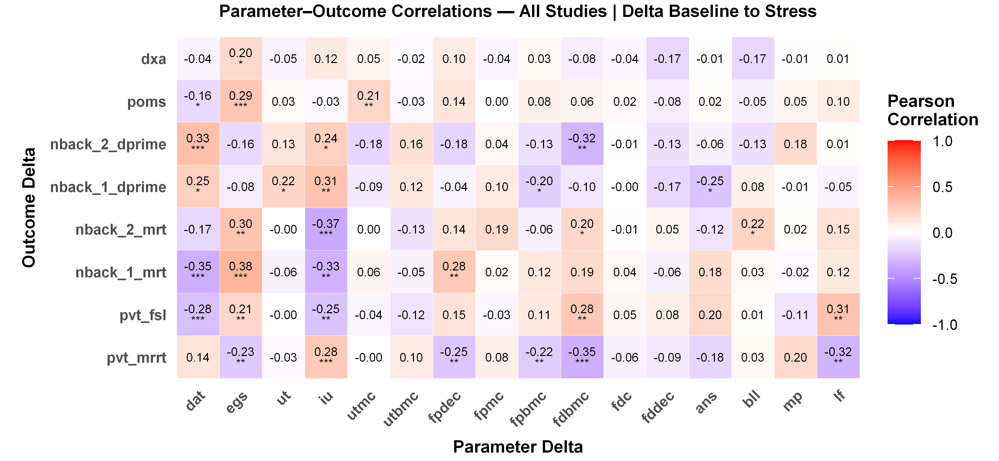

In [198]:
options(repr.plot.width=6.5, repr.plot.height=3.0, repr.plot.res=600)
stress_cor_all <- make_param_outcome_cor_plot(
  stress_param_delta,
  transition_label = "Baseline to Stress",
  study_filter = "All"
)

stress_cor_all$plot

In [990]:
ggsave("stress_delta_cor_all_v2.png", stress_cor_all$plot, width = 6.5, height = 3.1, dpi = 600)

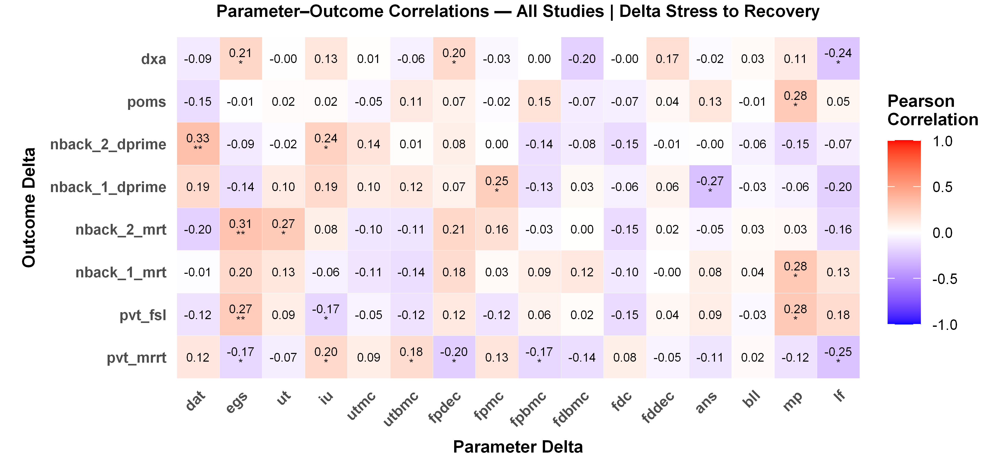

In [199]:
recovery_cor_all <- make_param_outcome_cor_plot(
  recovery_param_delta,
  transition_label = "Stress to Recovery",
  study_filter = "All"
)

recovery_cor_all$plot

In [993]:
ggsave("recovery_delta_cor_all_v2.png", recovery_cor_all$plot, width = 6.5, height = 3.1, dpi = 600)

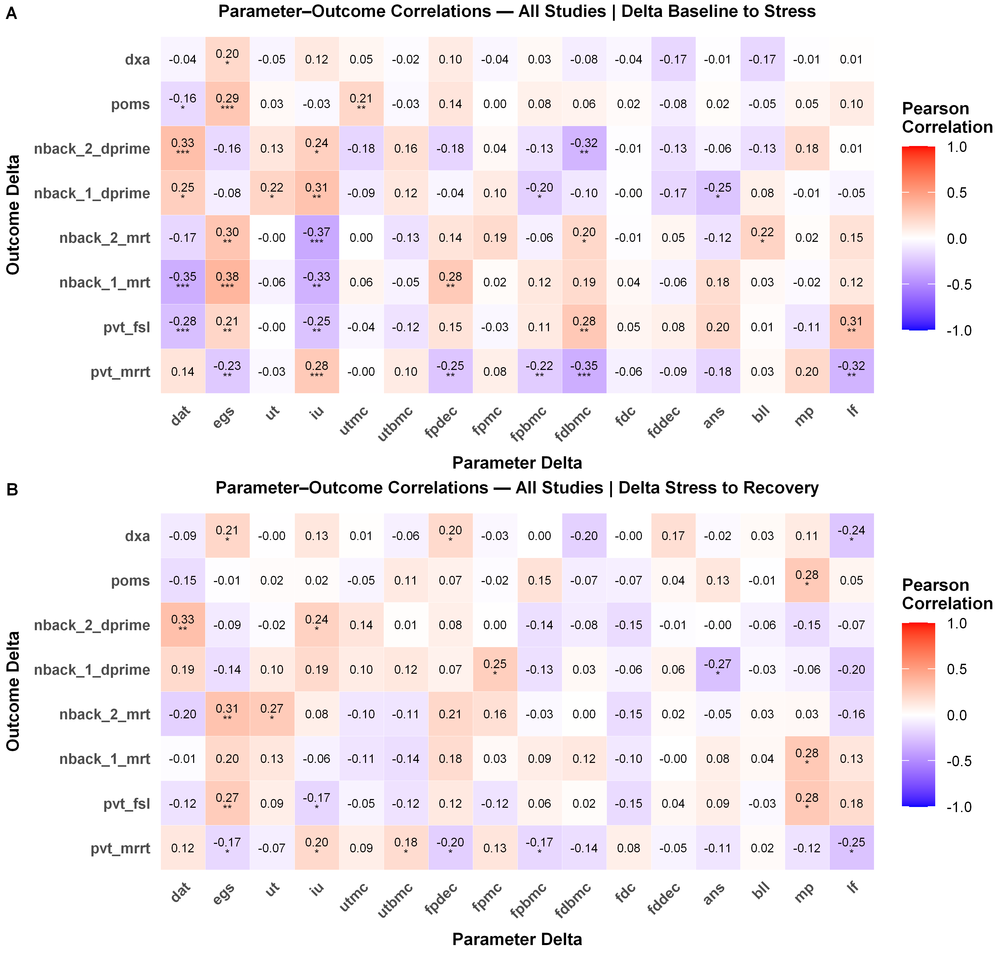

In [200]:
options(repr.plot.width=6.5, repr.plot.height=6.2, repr.plot.res=600)
delta_cor_all <- cowplot::plot_grid(
  stress_cor_all$plot,
  recovery_cor_all$plot,
  ncol = 1,
  labels = c("A", "B"),
  label_size = 8,
  align = "none"
)

delta_cor_all

In [995]:
ggsave("delta_cor_all_v2.png", delta_cor_all, width = 6.5, height = 6.2, dpi = 600)

In [997]:
ggsave(
  "delta_cor_all_v2.svg",
  delta_cor_all,
  width = 6.5,
  height = 6.2,
  device = "svg"
)

In [998]:
ggsave(
  "delta_cor_all_v2.pdf",
  delta_cor_all,
  width = 6.5,
  height = 6.2,
  device = cairo_pdf
)

In [202]:
stress_study_list <- c("All", sort(unique(stress_param_delta$study)))

stress_cor_plots <- lapply(
  stress_study_list,
  function(s) make_param_outcome_cor_plot(
    stress_param_delta,
    transition_label = "Baseline to Stress",
    study_filter = s
  )
)

names(stress_cor_plots) <- stress_study_list

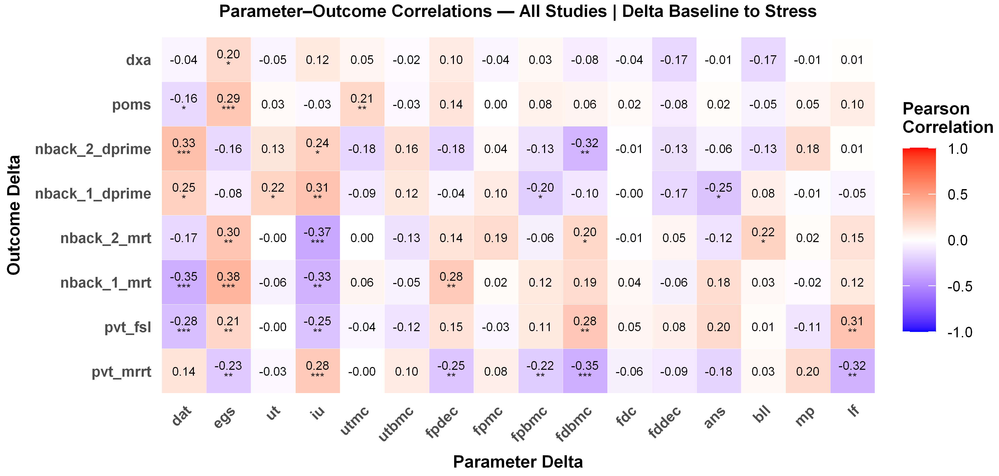

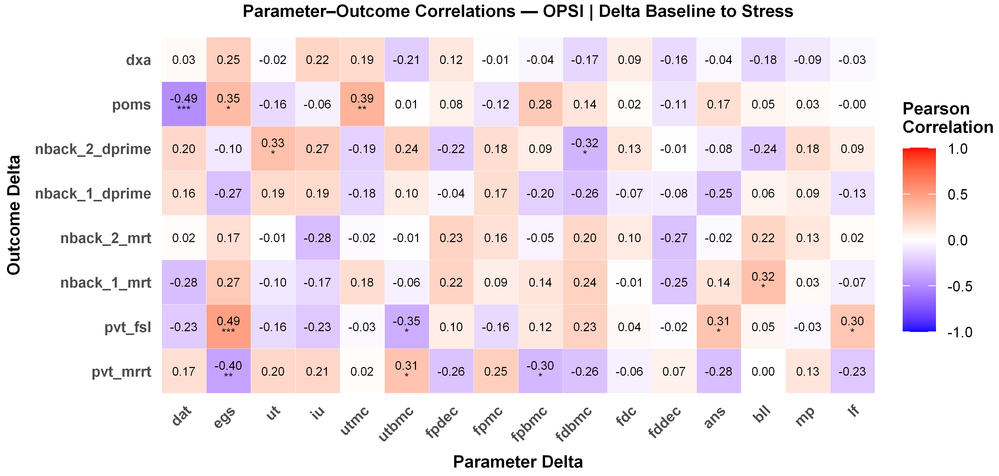

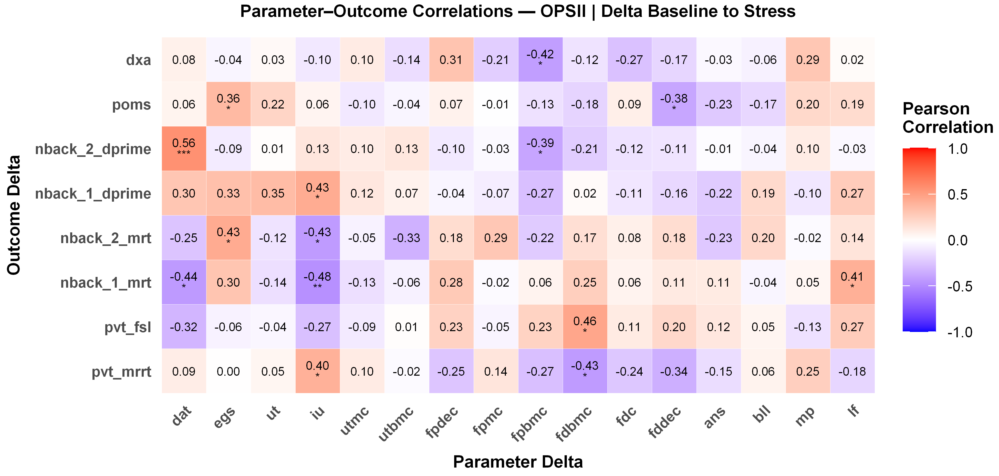

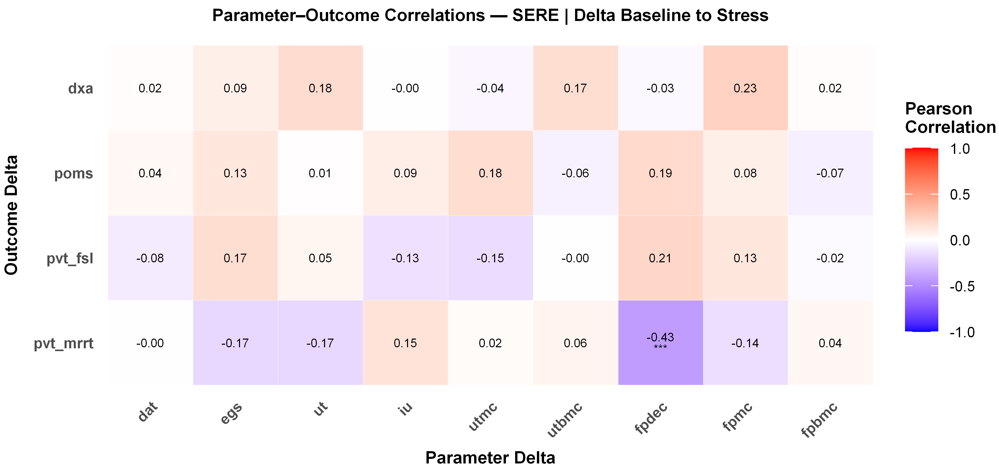

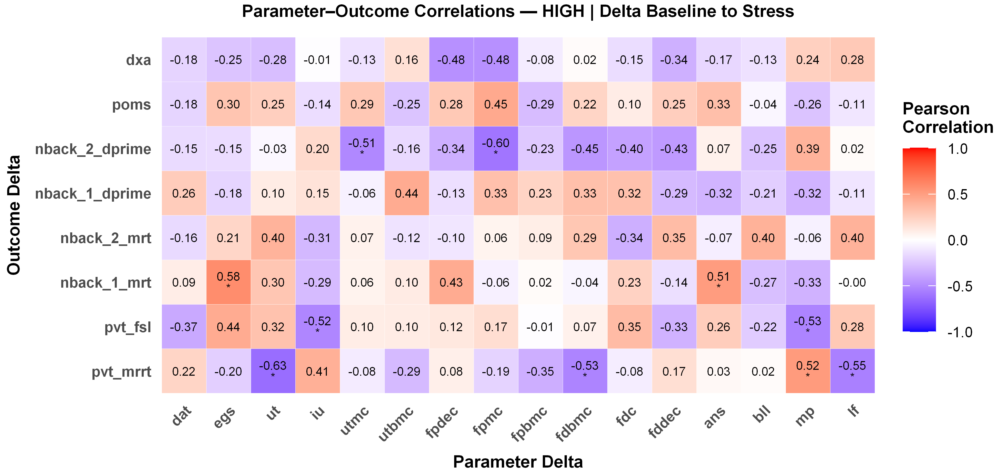

In [203]:
options(repr.plot.width=6.5, repr.plot.height=3.1, repr.plot.res=600)
stress_cor_plots[["All"]]$plot
stress_cor_plots[["OPSI"]]$plot
stress_cor_plots[["OPSII"]]$plot
stress_cor_plots[["SERE"]]$plot
stress_cor_plots[["HIGH"]]$plot

In [204]:
recovery_study_list <- c("All", sort(unique(recovery_param_delta$study)))

recovery_cor_plots <- lapply(
  recovery_study_list,
  function(s) make_param_outcome_cor_plot(
    recovery_param_delta,
    transition_label = "Stress to Recovery",
    study_filter = s
  )
)

names(recovery_cor_plots) <- recovery_study_list

Warning message in make_param_outcome_cor_plot(recovery_param_delta, transition_label = "Stress to Recovery", :
"Not enough usable data for HIGH / Stress to Recovery"


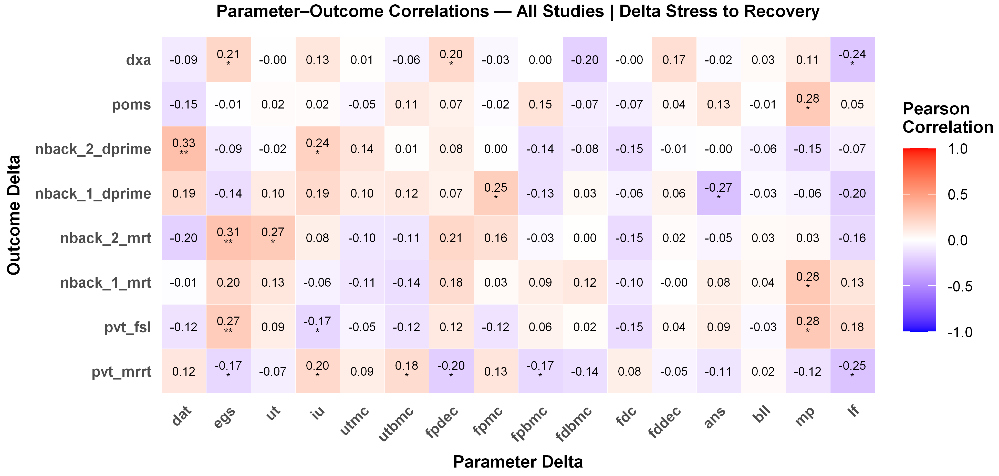

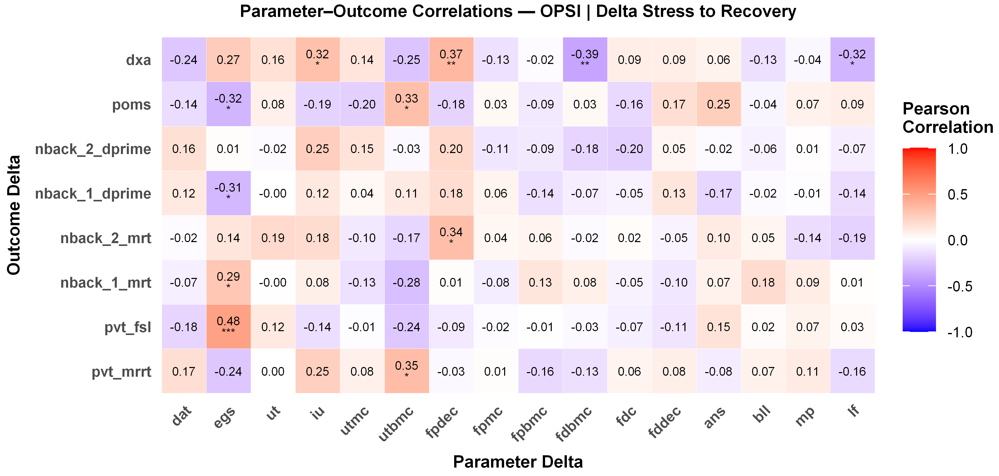

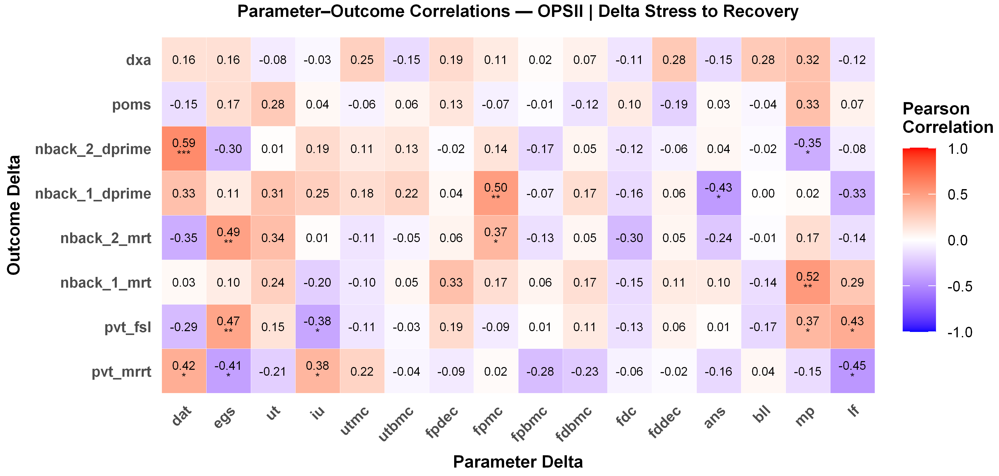

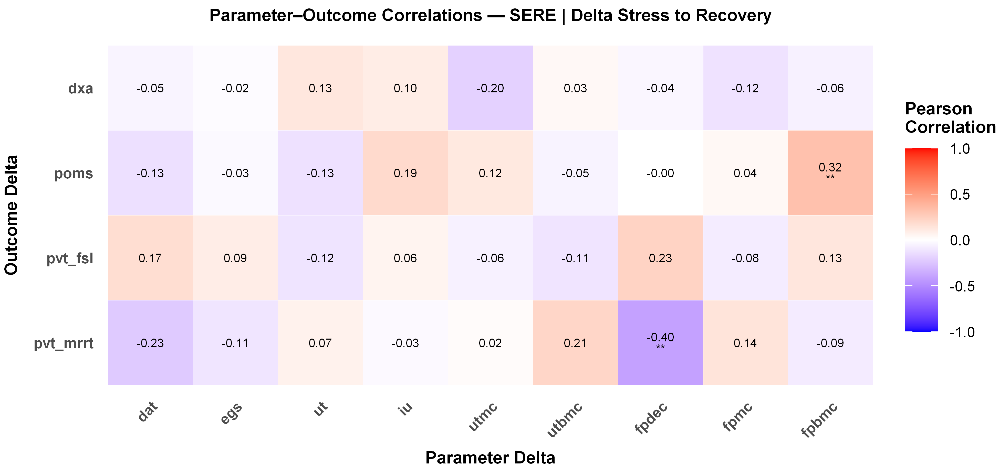

In [205]:
options(repr.plot.width=6.5, repr.plot.height=3.1, repr.plot.res=600)
recovery_cor_plots[["All"]]$plot
recovery_cor_plots[["OPSI"]]$plot
recovery_cor_plots[["OPSII"]]$plot
recovery_cor_plots[["SERE"]]$plot

# Parameters X Resilience Groups Analysis

# Data Table

In [206]:
mean(cc_dat_all$dat)
summary_by(cc_dat_all, dat ~ study + phase)

[1] 0.05840085

study,phase,dat.mean
<chr>,<chr>,<dbl>
HIGH,Baseline,0.05588235
HIGH,Stress,0.05823529
OPSI,Baseline,0.05820000
OPSI,Recovery,0.05860000
OPSI,Stress,0.05780000
OPSII,Baseline,0.05750000
OPSII,Recovery,0.05718750
OPSII,Stress,0.05656250
SERE,Baseline,0.05984127


In [207]:
head(cc_dat_all)
head(poms_data)
head(dxa_data)
head(pvt_all_avg_data)
colnames(pvt_all_avg_data)
head(nback_all_avg_data)
colnames(nback_all_avg_data)

study,subjectid,phase,study_event_id,bout,kl_val,mle_val,dat,egs,ut,⋯,fpdec,fpmc,fpbmc,fdbmc,fdc,fddec,ans,bll,mp,lf
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HIGH,ROP072,Baseline,B1,181,0.07221468,-16.443619,0.05,0.31,2.82,⋯,0.98,-0.01,0.03,-0.015,0.95,1.00,0.35,0.43,1.11,1.05
HIGH,ROP072,Stress,A3,1045,0.16473468,-18.316889,0.06,0.27,2.66,⋯,1.00,-0.03,0.01,-0.035,0.91,0.97,0.40,0.40,1.06,1.01
HIGH,ROP081,Baseline,B1,181,0.20620817,-9.778598,0.06,0.28,2.54,⋯,1.00,-0.02,0.02,-0.005,0.97,0.99,0.21,0.57,1.05,0.81
HIGH,ROP081,Stress,A3,1045,0.55755174,-9.237957,0.06,0.22,2.51,⋯,1.00,-0.09,0.03,-0.045,0.91,0.99,0.29,0.51,1.17,0.81
HIGH,ROP084,Baseline,B1,181,NA,-1.868362,0.05,0.39,2.65,⋯,1.00,-0.07,0.03,-0.005,1.00,1.00,0.39,0.42,1.07,0.92
HIGH,ROP084,Stress,A3,1045,NA,-2.918144,0.05,0.11,2.47,⋯,1.00,-0.05,0.04,-0.015,0.93,1.00,0.31,0.60,1.09,1.19


study,subjectid,Baseline,Stress,Recovery,poms_delta_stress,poms_delta_recovery,Robustness_poms,Resilience_poms,Rob_poms_v2,Rob_poms_v3
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HIGH,ROP072,-9,6,NA,15,NA,1.6666667,NA,0.6250000,-1.6666667
HIGH,ROP073,20,14,NA,-6,NA,-0.3000000,NA,-0.1132075,-0.3000000
HIGH,ROP074,5,52,NA,47,NA,9.4000000,NA,1.2368421,9.4000000
HIGH,ROP075,7,10,NA,3,NA,0.4285714,NA,0.0750000,0.4285714
HIGH,ROP076,11,24,NA,13,NA,1.1818182,NA,0.2954545,1.1818182
HIGH,ROP077,9,44,NA,35,NA,3.8888889,NA,0.8333333,3.8888889


study,subjectid,Stress,Baseline,Recovery,dxa_delta_stress,dxa_delta_recovery,Robustness_dxa,Resilience_dxa
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HIGH,ROP072,48549,51348,NA,-2799,NA,-0.05451040,NA
HIGH,ROP073,61975,70859,NA,-8884,NA,-0.12537575,NA
HIGH,ROP074,72679,78515,NA,-5836,NA,-0.07432975,NA
HIGH,ROP075,57258,60131,NA,-2873,NA,-0.04777902,NA
HIGH,ROP076,58540,62834,NA,-4294,NA,-0.06833880,NA
HIGH,ROP077,55102,59190,NA,-4088,NA,-0.06906572,NA


study,subjectid,phase,nfalsestart,nlapses,ntimeouts,nfslapse,nlapseto,ntotalerr,mrtime,meanrrt,delta_stress_mrrt,delta_recovery_mrrt,Robustness_mrrt,Resilience_mrrt,delta_stress_fsl,delta_recovery_fsl,Robustness_fsl,Resilience_fsl
<fct>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
OPSI,ROP166,Baseline,1,41,24,42,65,94,507.4667,2.195648,-0.24080839,0.2043652,-0.10967531,0.09307738,17,-16,0.4047619,-0.3809524
OPSI,ROP166,Recovery,0,43,23,43,66,103,514.3007,2.159205,-0.24080839,0.2043652,-0.10967531,0.09307738,17,-16,0.4047619,-0.3809524
OPSI,ROP166,Stress,0,59,34,59,93,111,578.3280,1.954840,-0.24080839,0.2043652,-0.10967531,0.09307738,17,-16,0.4047619,-0.3809524
OPSI,ROP167,Baseline,0,3,0,3,3,7,344.1955,3.009092,-0.03107773,-0.2692449,-0.01032794,-0.08947713,-2,16,-0.6666667,5.3333333
OPSI,ROP167,Recovery,0,17,10,17,27,39,401.9325,2.708770,-0.03107773,-0.2692449,-0.01032794,-0.08947713,-2,16,-0.6666667,5.3333333
OPSI,ROP167,Stress,0,1,0,1,1,4,343.3427,2.978015,-0.03107773,-0.2692449,-0.01032794,-0.08947713,-2,16,-0.6666667,5.3333333


[1] "study"               "subjectid"           "phase"              
 [4] "nfalsestart"         "nlapses"             "ntimeouts"          
 [7] "nfslapse"            "nlapseto"            "ntotalerr"          
[10] "mrtime"              "meanrrt"             "delta_stress_mrrt"  
[13] "delta_recovery_mrrt" "Robustness_mrrt"     "Resilience_mrrt"    
[16] "delta_stress_fsl"    "delta_recovery_fsl"  "Robustness_fsl"     
[19] "Resilience_fsl"

study,subjectid,phase,SessBlockID,n,mrt,mrt_hit,mrt_fa,meanrrt,totalAcc,⋯,Robustness_mrt,Resilience_mrt,delta_stress_mrrt,delta_recovery_mrrt,Robustness_mrrt,Resilience_mrrt,delta_stress_dprime,delta_recovery_dprime,Robustness_dprime,Resilience_dprime
<fct>,<chr>,<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
OPSI,ROP166,Baseline,1,81,0.5911765,0.5846154,0.6125000,1.828670,0.8518519,⋯,0.1764677,-0.30495566,-0.3488922,0.5650985,-0.1907901,0.3090216,-1.485893,2.5850199,-0.8664855,1.5074322
OPSI,ROP166,Baseline,2,82,0.6633333,0.6977778,0.6375000,2.158970,0.7073171,⋯,0.1385877,-0.02542185,-0.7644056,0.5176728,-0.3540603,0.2397776,0.175783,-0.3299374,0.2615855,-0.4909852
OPSI,ROP166,Recovery,1,81,0.5152174,0.4715789,0.7225000,2.044876,0.9259259,⋯,0.1764677,-0.30495566,-0.3488922,0.5650985,-0.1907901,0.3090216,-1.485893,2.5850199,-0.8664855,1.5074322
OPSI,ROP166,Recovery,2,82,0.7384000,0.7355556,0.7400000,1.912237,0.6707317,⋯,0.1385877,-0.02542185,-0.7644056,0.5176728,-0.3540603,0.2397776,0.175783,-0.3299374,0.2615855,-0.4909852
OPSI,ROP166,Stress,1,81,0.6955000,0.6683333,0.7071429,1.479778,0.6543210,⋯,0.1764677,-0.30495566,-0.3488922,0.5650985,-0.1907901,0.3090216,-1.485893,2.5850199,-0.8664855,1.5074322
OPSI,ROP166,Stress,2,82,0.7552632,0.7700000,0.7420000,1.394564,0.7439024,⋯,0.1385877,-0.02542185,-0.7644056,0.5176728,-0.3540603,0.2397776,0.175783,-0.3299374,0.2615855,-0.4909852


[1] "study"                 "subjectid"             "phase"                
 [4] "SessBlockID"           "n"                     "mrt"                  
 [7] "mrt_hit"               "mrt_fa"                "meanrrt"              
[10] "totalAcc"              "accFoil"               "accTarget"            
[13] "nhit"                  "nmiss"                 "nfa"                  
[16] "ncr"                   "hr"                    "far"                  
[19] "hr_adj"                "far_adj"               "zhr"                  
[22] "zfar"                  "dprime"                "delta_stress_mrt"     
[25] "delta_recovery_mrt"    "Robustness_mrt"        "Resilience_mrt"       
[28] "delta_stress_mrrt"     "delta_recovery_mrrt"   "Robustness_mrrt"      
[31] "Resilience_mrrt"       "delta_stress_dprime"   "delta_recovery_dprime"
[34] "Robustness_dprime"     "Resilience_dprime"

In [208]:
params <- c(
  "dat", "egs", "ut", "iu", 
  "utmc", "utbmc", "fpdec", "fpmc", "fpbmc",
  "fdbmc", "fdc", "fddec", 
  "ans", "bll", "mp", "lf"
)

# PVT phase-level outcomes
pvt_phase_vars <- c(
  "meanrrt",
  "nfslapse"
)

# PVT phase variable labels should match delta labels
pvt_phase_label_map <- c(
  meanrrt  = "mrrt",
  nfslapse = "fsl"
)

# PVT delta outcomes
pvt_delta_specs <- tibble::tribble(
  ~variable,              ~measure_stub, ~timepoint,
  "delta_stress_mrrt",    "mrrt",        "Delta-Stress",
  "delta_recovery_mrrt",  "mrrt",        "Delta-Recovery",
  "delta_stress_fsl",     "fsl",         "Delta-Stress",
  "delta_recovery_fsl",   "fsl",         "Delta-Recovery"
)

# NBack phase-level outcomes
nback_phase_vars <- c(
  #"mrrt",
  "mrt",
  "dprime"
)

# NBack delta outcomes
# Important: these should be stubs only, not "nback_mrt"
nback_delta_specs <- tibble::tribble(
  ~variable,                   ~measure_stub, ~timepoint,
  #"delta_stress_mrrt",         "mrrt",        "Delta-Stress",
  #"delta_recovery_mrrt",       "mrrt",        "Delta-Recovery",
  "delta_stress_mrt",          "mrt",         "Delta-Stress",
  "delta_recovery_mrt",        "mrt",         "Delta-Recovery",
  "delta_stress_dprime",       "dprime",      "Delta-Stress",
  "delta_recovery_dprime",     "dprime",      "Delta-Recovery"
)

timepoint_order <- c(
  "Baseline",
  "Delta-Stress",
  "Stress",
  "Delta-Recovery",
  "Recovery"
)

study_order <- c("HIGH", "OPSI", "OPSII", "SERE", "Total")

In [209]:
mean_or_na <- function(x) {
  if (all(is.na(x))) NA_real_ else mean(x, na.rm = TRUE)
}

first_non_missing <- function(x) {
  x <- x[!is.na(x)]
  if (length(x) == 0) NA_real_ else x[1]
}

In [210]:
cc_long <- cc_dat_all %>%
  filter(phase %in% c("Baseline", "Stress", "Recovery")) %>%
  mutate(
    study = as.character(study),
    subjectid = as.character(subjectid),
    phase = as.character(phase)
  ) %>%
  group_by(study, subjectid, phase) %>%
  summarise(
    across(all_of(params), mean_or_na),
    .groups = "drop"
  ) %>%
  pivot_wider(
    id_cols = c(study, subjectid),
    names_from = phase,
    values_from = all_of(params),
    names_glue = "{.value}_{phase}"
  ) %>%
  bind_cols(
    purrr::map_dfc(params, function(p) {
      tibble(
        !!paste0(p, "_Delta-Stress") :=
          .[[paste0(p, "_Stress")]] - .[[paste0(p, "_Baseline")]],
        !!paste0(p, "_Delta-Recovery") :=
          .[[paste0(p, "_Recovery")]] - .[[paste0(p, "_Stress")]]
      )
    })
  ) %>%
  pivot_longer(
    cols = -c(study, subjectid),
    names_to = c("measure", "timepoint"),
    names_pattern = "^(.*)_(Baseline|Stress|Recovery|Delta-Stress|Delta-Recovery)$",
    values_to = "value"
  ) %>%
  mutate(
      domain = "CompuCognome",
      measure = factor(measure, levels = params)
  )

head(cc_long)
unique(cc_long$measure)

study,subjectid,measure,timepoint,value,domain
<chr>,<chr>,<fct>,<chr>,<dbl>,<chr>
HIGH,ROP072,dat,Baseline,0.05,CompuCognome
HIGH,ROP072,dat,Stress,0.06,CompuCognome
HIGH,ROP072,dat,Recovery,NA,CompuCognome
HIGH,ROP072,egs,Baseline,0.31,CompuCognome
HIGH,ROP072,egs,Stress,0.27,CompuCognome
HIGH,ROP072,egs,Recovery,NA,CompuCognome


[1] dat   egs   ut    iu    utmc  utbmc fpdec fpmc  fpbmc fdbmc fdc   fddec
[13] ans   bll   mp    lf   
16 Levels: dat egs ut iu utmc utbmc fpdec fpmc fpbmc fdbmc fdc fddec ... lf

In [211]:
poms_long <- poms_data %>%
  mutate(
    study = as.character(study),
    subjectid = as.character(subjectid)
  ) %>%
  select(
    study,
    subjectid,
    Baseline,
    Stress,
    Recovery,
    poms_delta_stress,
    poms_delta_recovery
  ) %>%
  rename(
    `Delta-Stress` = poms_delta_stress,
    `Delta-Recovery` = poms_delta_recovery
  ) %>%
  pivot_longer(
    cols = c(Baseline, Stress, Recovery, `Delta-Stress`, `Delta-Recovery`),
    names_to = "timepoint",
    values_to = "value"
  ) %>%
  mutate(
    domain = "POMS",
    measure = "poms_tmd"
  )

head(poms_long)
unique(poms_long$measure)

study,subjectid,timepoint,value,domain,measure
<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>
HIGH,ROP072,Baseline,-9,POMS,poms_tmd
HIGH,ROP072,Stress,6,POMS,poms_tmd
HIGH,ROP072,Recovery,NA,POMS,poms_tmd
HIGH,ROP072,Delta-Stress,15,POMS,poms_tmd
HIGH,ROP072,Delta-Recovery,NA,POMS,poms_tmd
HIGH,ROP073,Baseline,20,POMS,poms_tmd


[1] "poms_tmd"

In [212]:
dxa_long <- dxa_data %>%
  mutate(
    study = as.character(study),
    subjectid = as.character(subjectid)
  ) %>%
  select(
    study,
    subjectid,
    Baseline,
    Stress,
    Recovery,
    dxa_delta_stress,
    dxa_delta_recovery
  ) %>%
  rename(
    `Delta-Stress` = dxa_delta_stress,
    `Delta-Recovery` = dxa_delta_recovery
  ) %>%
  pivot_longer(
    cols = c(Baseline, Stress, Recovery, `Delta-Stress`, `Delta-Recovery`),
    names_to = "timepoint",
    values_to = "value"
  ) %>%
  mutate(
    domain = "DXA",
    measure = "dxa_lean_ff_mass"
  )

head(dxa_long)
unique(dxa_long$measure)

study,subjectid,timepoint,value,domain,measure
<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>
HIGH,ROP072,Baseline,51348,DXA,dxa_lean_ff_mass
HIGH,ROP072,Stress,48549,DXA,dxa_lean_ff_mass
HIGH,ROP072,Recovery,NA,DXA,dxa_lean_ff_mass
HIGH,ROP072,Delta-Stress,-2799,DXA,dxa_lean_ff_mass
HIGH,ROP072,Delta-Recovery,NA,DXA,dxa_lean_ff_mass
HIGH,ROP073,Baseline,70859,DXA,dxa_lean_ff_mass


[1] "dxa_lean_ff_mass"

In [213]:
pvt_phase_long <- pvt_all_avg_data %>%
  ungroup() %>%
  filter(phase %in% c("Baseline", "Stress", "Recovery")) %>%
  mutate(
    study = as.character(study),
    subjectid = as.character(subjectid),
    phase = as.character(phase)
  ) %>%
  group_by(study, subjectid, phase) %>%
  summarise(
    across(any_of(pvt_phase_vars), mean_or_na),
    .groups = "drop"
  ) %>%
  pivot_longer(
    cols = any_of(pvt_phase_vars),
    names_to = "measure_stub",
    values_to = "value"
  ) %>%
  mutate(
    domain = "PVT",
    measure_stub = recode(measure_stub, !!!pvt_phase_label_map),
    measure = paste0("pvt_", measure_stub),
    timepoint = phase
  ) %>%
  select(study, subjectid, domain, measure, timepoint, value)


pvt_delta_long <- pvt_all_avg_data %>%
  ungroup() %>%
  mutate(
    study = as.character(study),
    subjectid = as.character(subjectid)
  ) %>%
  group_by(study, subjectid) %>%
  summarise(
    across(any_of(pvt_delta_specs$variable), first_non_missing),
    .groups = "drop"
  ) %>%
  pivot_longer(
    cols = any_of(pvt_delta_specs$variable),
    names_to = "variable",
    values_to = "value"
  ) %>%
  left_join(pvt_delta_specs, by = "variable") %>%
  mutate(
    domain = "PVT",
    measure = paste0("pvt_", measure_stub)
  ) %>%
  select(study, subjectid, domain, measure, timepoint, value)


pvt_long <- bind_rows(pvt_phase_long, pvt_delta_long)

head(pvt_long)
unique(pvt_long$measure)

study,subjectid,domain,measure,timepoint,value
<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>
HIGH,ROP072,PVT,pvt_mrrt,Baseline,2.645845
HIGH,ROP072,PVT,pvt_fsl,Baseline,19.000000
HIGH,ROP072,PVT,pvt_mrrt,Stress,2.637901
HIGH,ROP072,PVT,pvt_fsl,Stress,16.000000
HIGH,ROP073,PVT,pvt_mrrt,Baseline,2.650238
HIGH,ROP073,PVT,pvt_fsl,Baseline,18.000000


[1] "pvt_mrrt" "pvt_fsl"

In [214]:
nback_phase_long <- nback_all_avg_data %>%
  ungroup() %>%
  filter(phase %in% c("Baseline", "Stress", "Recovery")) %>%
  mutate(
    study = as.character(study),
    subjectid = as.character(subjectid),
    phase = as.character(phase),
    SessBlockID = as.character(SessBlockID)
  ) %>%
  group_by(study, subjectid, SessBlockID, phase) %>%
  summarise(
    across(any_of(nback_phase_vars), mean_or_na),
    .groups = "drop"
  ) %>%
  pivot_longer(
    cols = any_of(nback_phase_vars),
    names_to = "measure_stub",
    values_to = "value"
  ) %>%
  mutate(
    domain = "NBack",
    measure = paste0("nback_", SessBlockID, "_", measure_stub),
    timepoint = phase
  ) %>%
  select(study, subjectid, domain, measure, timepoint, value)


nback_delta_long <- nback_all_avg_data %>%
  ungroup() %>%
  mutate(
    study = as.character(study),
    subjectid = as.character(subjectid),
    SessBlockID = as.character(SessBlockID)
  ) %>%
  group_by(study, subjectid, SessBlockID) %>%
  summarise(
    across(any_of(nback_delta_specs$variable), first_non_missing),
    .groups = "drop"
  ) %>%
  pivot_longer(
    cols = any_of(nback_delta_specs$variable),
    names_to = "variable",
    values_to = "value"
  ) %>%
  left_join(nback_delta_specs, by = "variable") %>%
  mutate(
    domain = "NBack",
    measure = paste0("nback_", SessBlockID, "_", measure_stub)
  ) %>%
  select(study, subjectid, domain, measure, timepoint, value)


nback_long <- bind_rows(nback_phase_long, nback_delta_long)

head(nback_long)
unique(nback_long$measure)

study,subjectid,domain,measure,timepoint,value
<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>
HIGH,ROP072,NBack,nback_1_mrt,Baseline,0.6690909
HIGH,ROP072,NBack,nback_1_dprime,Baseline,3.7277073
HIGH,ROP072,NBack,nback_1_mrt,Stress,0.6059091
HIGH,ROP072,NBack,nback_1_dprime,Stress,3.7277073
HIGH,ROP072,NBack,nback_2_mrt,Baseline,0.7568421
HIGH,ROP072,NBack,nback_2_dprime,Baseline,2.7218035


[1] "nback_1_mrt"    "nback_1_dprime" "nback_2_mrt"    "nback_2_dprime"

In [215]:
all_long <- bind_rows(
  cc_long,
  poms_long,
  dxa_long,
  pvt_long,
  nback_long
) %>%
  mutate(
    study = factor(study, levels = study_order),
    timepoint = factor(timepoint, levels = timepoint_order)
  )


all_long_with_total <- bind_rows(
  all_long,
  all_long %>%
    mutate(study = factor("Total", levels = study_order))
)

domain_order <- c("CompuCognome", "PVT", "NBack", "POMS", "DXA")

measure_order <- c(
  params,
  
  # PVT measures
  #"pvt_meanrrt",
  #"pvt_nfslapse",
  "pvt_mrrt",
  "pvt_fsl",
  
  # NBack measures
  "nback_1_mrt",
  "nback_1_dprime",
  #"nback_1_mrrt",
  "nback_2_mrt",
  "nback_2_dprime",
  #"nback_2_mrrt",
  
  # POMS and DXA
  "poms_tmd",
  "dxa_lean_ff_mass"
)

all_long_with_total <- all_long_with_total %>%
  mutate(
    domain = factor(domain, levels = domain_order),
    measure = factor(as.character(measure), levels = measure_order),
    study = factor(study, levels = study_order),
    timepoint = factor(timepoint, levels = timepoint_order)
  )

In [216]:
summary_long <- all_long_with_total %>%
  filter(!is.na(value), is.finite(value)) %>%
  group_by(domain, measure, study, timepoint) %>%
  summarise(
    n = n(),
    mean = mean(value, na.rm = TRUE),
    sd = sd(value, na.rm = TRUE),
    .groups = "drop"
  ) %>%
  mutate(
    domain = factor(domain, levels = domain_order),
    measure = factor(as.character(measure), levels = measure_order),
    study = factor(study, levels = study_order),
    timepoint = factor(timepoint, levels = timepoint_order)
  )

summary_wide <- summary_long %>%
  arrange(domain, measure, study, timepoint) %>%
  pivot_wider(
    id_cols = c(domain, measure),
    names_from = c(study, timepoint),
    values_from = c(n, mean, sd),
    names_glue = "{study}_{timepoint}_{.value}"
  ) %>%
  arrange(domain, measure)

summary_wide

domain,measure,HIGH_Baseline_n,HIGH_Delta-Stress_n,HIGH_Stress_n,OPSI_Baseline_n,OPSI_Delta-Stress_n,OPSI_Stress_n,OPSI_Delta-Recovery_n,OPSI_Recovery_n,⋯,SERE_Baseline_sd,SERE_Delta-Stress_sd,SERE_Stress_sd,SERE_Delta-Recovery_sd,SERE_Recovery_sd,Total_Baseline_sd,Total_Delta-Stress_sd,Total_Stress_sd,Total_Delta-Recovery_sd,Total_Recovery_sd
<fct>,<fct>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
CompuCognome,dat,17,17,17,50,50,50,50,50,⋯,1.259882e-03,2.146694e-03,2.458045e-03,2.835298e-03,2.724789e-03,3.623763e-03,4.851921e-03,4.003775e-03,4.474277e-03,3.722923e-03
CompuCognome,egs,17,17,17,50,50,50,50,50,⋯,5.754359e-02,7.883107e-02,7.270609e-02,7.895081e-02,6.406162e-02,6.543819e-02,7.856764e-02,7.738145e-02,8.218123e-02,7.117399e-02
CompuCognome,ut,17,17,17,50,50,50,50,50,⋯,2.961373e-01,4.108710e-01,3.078393e-01,3.825180e-01,2.985603e-01,2.968237e-01,3.806595e-01,2.867447e-01,3.640528e-01,2.993393e-01
CompuCognome,iu,17,17,17,50,50,50,50,50,⋯,2.740907e-01,3.693038e-01,2.909265e-01,3.666436e-01,3.004314e-01,2.965414e-01,3.844172e-01,3.153317e-01,3.732854e-01,2.981142e-01
CompuCognome,utmc,17,17,17,50,50,50,50,50,⋯,3.051780e-02,3.799372e-02,3.005201e-02,3.837388e-02,2.924901e-02,3.034481e-02,4.137707e-02,3.007499e-02,4.014581e-02,2.942081e-02
CompuCognome,utbmc,17,17,17,50,50,50,50,50,⋯,1.251318e-02,1.476042e-02,9.236052e-03,1.604685e-02,1.200998e-02,1.136157e-02,1.591532e-02,1.106010e-02,1.533408e-02,1.217489e-02
CompuCognome,fpdec,17,17,17,50,50,50,50,50,⋯,1.193514e-02,1.616131e-02,1.396176e-02,1.389191e-02,1.095539e-02,1.250121e-02,1.616486e-02,1.248632e-02,1.329809e-02,1.167775e-02
CompuCognome,fpmc,17,17,17,50,50,50,50,50,⋯,2.955117e-02,4.015523e-02,2.702619e-02,3.923879e-02,2.530409e-02,2.881846e-02,4.064015e-02,2.639876e-02,3.719667e-02,2.782557e-02
CompuCognome,fpbmc,17,17,17,50,50,50,50,50,⋯,1.190937e-02,1.608032e-02,9.576276e-03,1.529703e-02,1.373623e-02,1.207754e-02,1.714016e-02,1.152640e-02,1.408717e-02,1.261157e-02


In [217]:
summary_mean_sd <- summary_long %>%
  mutate(
    mean_sd = case_when(
      is.na(mean) ~ NA_character_,
      is.na(sd)   ~ sprintf("%.3f", mean),
      TRUE        ~ sprintf("%.3f (%.3f)", mean, sd)
    )
  ) %>%
  select(domain, measure, study, timepoint, mean_sd) %>%
  arrange(domain, measure, study, timepoint) %>%
  pivot_wider(
    id_cols = c(domain, measure),
    names_from = c(study, timepoint),
    values_from = mean_sd,
    names_glue = "{study}_{timepoint}"
  ) %>%
  arrange(domain, measure)

# Save current options
old_options <- options()

# Temporarily change print/display options
options(
  repr.matrix.max.rows = 200,
  repr.matrix.max.cols = 100,
  tibble.print_max = 200,
  tibble.width = Inf
)

summary_mean_sd

options(old_options)

domain,measure,HIGH_Baseline,HIGH_Delta-Stress,HIGH_Stress,OPSI_Baseline,OPSI_Delta-Stress,OPSI_Stress,OPSI_Delta-Recovery,OPSI_Recovery,OPSII_Baseline,OPSII_Delta-Stress,OPSII_Stress,OPSII_Delta-Recovery,OPSII_Recovery,SERE_Baseline,SERE_Delta-Stress,SERE_Stress,SERE_Delta-Recovery,SERE_Recovery,Total_Baseline,Total_Delta-Stress,Total_Stress,Total_Delta-Recovery,Total_Recovery
<fct>,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
CompuCognome,dat,0.056 (0.005),0.002 (0.006),0.058 (0.004),0.058 (0.004),-0.000 (0.005),0.058 (0.004),0.001 (0.005),0.059 (0.004),0.057 (0.004),-0.001 (0.007),0.057 (0.005),0.001 (0.006),0.057 (0.005),0.060 (0.001),-0.000 (0.002),0.059 (0.002),-0.000 (0.003),0.059 (0.003),0.058 (0.004),-0.000 (0.005),0.058 (0.004),0.000 (0.004),0.059 (0.004)
CompuCognome,egs,0.322 (0.068),-0.059 (0.089),0.262 (0.087),0.282 (0.069),-0.007 (0.068),0.276 (0.067),0.008 (0.085),0.284 (0.077),0.277 (0.061),-0.002 (0.078),0.275 (0.078),0.018 (0.078),0.292 (0.074),0.259 (0.058),-0.038 (0.079),0.221 (0.073),0.046 (0.079),0.267 (0.064),0.276 (0.065),-0.023 (0.079),0.253 (0.077),0.027 (0.082),0.278 (0.071)
CompuCognome,ut,2.511 (0.213),0.002 (0.300),2.513 (0.294),2.440 (0.307),0.019 (0.321),2.459 (0.278),0.047 (0.317),2.505 (0.289),2.470 (0.322),0.043 (0.432),2.513 (0.251),-0.011 (0.385),2.501 (0.323),2.408 (0.296),0.144 (0.411),2.552 (0.308),-0.087 (0.383),2.465 (0.299),2.441 (0.297),0.070 (0.381),2.511 (0.287),-0.024 (0.364),2.487 (0.299)
CompuCognome,iu,2.321 (0.288),0.041 (0.343),2.362 (0.320),2.463 (0.278),0.055 (0.392),2.518 (0.331),-0.044 (0.357),2.474 (0.288),2.517 (0.309),-0.101 (0.410),2.416 (0.315),0.038 (0.415),2.454 (0.308),2.617 (0.274),-0.072 (0.369),2.545 (0.291),-0.006 (0.367),2.539 (0.300),2.519 (0.297),-0.027 (0.384),2.492 (0.315),-0.009 (0.373),2.498 (0.298)
CompuCognome,utmc,-0.048 (0.033),-0.001 (0.051),-0.048 (0.033),-0.049 (0.031),-0.000 (0.045),-0.049 (0.030),-0.000 (0.042),-0.050 (0.030),-0.063 (0.026),0.008 (0.038),-0.055 (0.029),0.005 (0.041),-0.050 (0.030),-0.049 (0.031),-0.001 (0.038),-0.050 (0.030),-0.001 (0.038),-0.052 (0.029),-0.052 (0.030),0.001 (0.041),-0.051 (0.030),0.000 (0.040),-0.051 (0.029)
CompuCognome,utbmc,0.022 (0.010),0.004 (0.017),0.026 (0.012),0.022 (0.011),-0.002 (0.019),0.020 (0.013),0.002 (0.016),0.022 (0.013),0.021 (0.010),-0.000 (0.012),0.020 (0.009),-0.000 (0.012),0.020 (0.011),0.022 (0.013),-0.004 (0.015),0.018 (0.009),0.003 (0.016),0.021 (0.012),0.022 (0.011),-0.002 (0.016),0.020 (0.011),0.002 (0.015),0.021 (0.012)
CompuCognome,fpdec,0.992 (0.012),0.001 (0.017),0.993 (0.012),0.990 (0.013),0.003 (0.013),0.993 (0.011),0.001 (0.011),0.994 (0.010),0.990 (0.013),0.002 (0.019),0.992 (0.012),-0.004 (0.014),0.988 (0.015),0.992 (0.012),-0.003 (0.016),0.990 (0.014),0.003 (0.014),0.993 (0.011),0.991 (0.013),0.000 (0.016),0.991 (0.012),0.001 (0.013),0.992 (0.012)
CompuCognome,fpmc,-0.046 (0.024),-0.002 (0.031),-0.048 (0.029),-0.051 (0.031),-0.006 (0.044),-0.058 (0.027),-0.002 (0.036),-0.060 (0.028),-0.048 (0.027),-0.007 (0.042),-0.055 (0.024),0.013 (0.033),-0.042 (0.027),-0.049 (0.030),-0.001 (0.040),-0.050 (0.027),0.009 (0.039),-0.041 (0.025),-0.049 (0.029),-0.004 (0.041),-0.053 (0.026),0.006 (0.037),-0.048 (0.028)
CompuCognome,fpbmc,0.025 (0.011),-0.001 (0.017),0.024 (0.013),0.021 (0.013),0.001 (0.019),0.022 (0.012),0.004 (0.012),0.026 (0.011),0.018 (0.012),0.005 (0.015),0.023 (0.011),0.001 (0.014),0.024 (0.012),0.020 (0.012),-0.003 (0.016),0.016 (0.010),0.004 (0.015),0.020 (0.014),0.020 (0.012),-0.000 (0.017),0.020 (0.012),0.003 (0.014),0.023 (0.013)


## Extremophile groups

In [218]:
#poms_extreme_data
#dxa_extreme_data
#pvt_extreme_data

cc_extreme_dat_all <- cc_dat_all %>% 
    left_join(select(poms_extreme_data, study, subjectid, poms_delta_stress, poms_delta_recovery, poms_robustness_extreme, poms_resilience_extreme), by=c("study", "subjectid")) %>%
    left_join(select(dxa_extreme_data, study, subjectid, dxa_delta_stress, dxa_delta_recovery, dxa_robustness_extreme, dxa_resilience_extreme), by=c("study", "subjectid")) %>%
    left_join(select(pvt_extreme_data, study, subjectid, delta_stress_mrrt, delta_recovery_mrrt, delta_stress_fsl, delta_recovery_fsl, pvt_mrrt_robustness_extreme, pvt_mrrt_resilience_extreme, pvt_fsl_robustness_extreme, pvt_fsl_resilience_extreme), by=c("study", "subjectid"))

head(cc_extreme_dat_all)

study,subjectid,phase,study_event_id,bout,kl_val,mle_val,dat,egs,ut,⋯,dxa_robustness_extreme,dxa_resilience_extreme,delta_stress_mrrt,delta_recovery_mrrt,delta_stress_fsl,delta_recovery_fsl,pvt_mrrt_robustness_extreme,pvt_mrrt_resilience_extreme,pvt_fsl_robustness_extreme,pvt_fsl_resilience_extreme
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<int>
HIGH,ROP072,Baseline,B1,181,0.07221468,-16.443619,0.05,0.31,2.82,⋯,NA,NA,-0.007943908,NA,-3,NA,NA,NA,NA,NA
HIGH,ROP072,Stress,A3,1045,0.16473468,-18.316889,0.06,0.27,2.66,⋯,NA,NA,-0.007943908,NA,-3,NA,NA,NA,NA,NA
HIGH,ROP081,Baseline,B1,181,0.20620817,-9.778598,0.06,0.28,2.54,⋯,1,NA,0.169225389,NA,-15,NA,NA,NA,1,NA
HIGH,ROP081,Stress,A3,1045,0.55755174,-9.237957,0.06,0.22,2.51,⋯,1,NA,0.169225389,NA,-15,NA,NA,NA,1,NA
HIGH,ROP084,Baseline,B1,181,NA,-1.868362,0.05,0.39,2.65,⋯,1,NA,NA,NA,NA,NA,NA,NA,NA,NA
HIGH,ROP084,Stress,A3,1045,NA,-2.918144,0.05,0.11,2.47,⋯,1,NA,NA,NA,NA,NA,NA,NA,NA,NA


In [219]:
write.csv(
  cc_extreme_dat_all,
  "./ROPER_CompuCognome_FullData_AllStudies_Merged_wOutcomes_wExtremophiles.csv",
  row.names = FALSE
)

In [220]:
params   <- c("dat", "egs", "ut", "iu", 
              "utmc", "utbmc", "fpdec", "fpmc", "fpbmc",
              "fdbmc", "fdc", "fddec", 
              "ans", "bll", "mp", "lf")
outcomes <- c("dxa_robustness_extreme","dxa_resilience_extreme",
              "pvt_mrrt_robustness_extreme","pvt_mrrt_resilience_extreme","pvt_fsl_robustness_extreme","pvt_fsl_resilience_extreme",
              "poms_robustness_extreme","poms_resilience_extreme")
phases   <- c("Baseline","Stress","Recovery")

facet_order <- c("Baseline","Delta-Stress","Stress","Delta-Recovery","Recovery")

# Presentation-friendly colors
col_nonres <- "#C0392B"  # red
col_res    <- "#2E86AB"  # blue

# ---- read + filter ----
raw <- cc_extreme_dat_all %>%
  filter(!(study == "HIGH" & study_event_id %in% c("A1", "A2"))) %>%
  mutate(
    phase = factor(phase, levels = phases),
    study = as.factor(study),
    subjectid = as.factor(subjectid)
  ) %>%
  filter(phase %in% phases)

# ---- long ----
df_long <- raw %>%
  pivot_longer(cols = all_of(params), names_to = "param", values_to = "value") %>%
  mutate(param = factor(param, levels = params))

# ---- subject-level mean per phase (avoid pseudo-replication if multiple rows per phase) ----
df_phase_mean <- df_long %>%
  group_by(study, subjectid, phase, param, across(all_of(outcomes))) %>%
  summarise(value = mean(value, na.rm = TRUE), .groups = "drop")

# ---- compute deltas per subject (wide -> deltas -> long facets) ----
#df_wide <- df_phase_mean %>%
#  select(study, subjectid, param, all_of(outcomes), phase, value) %>%
#  pivot_wider(names_from = phase, values_from = value)

df_wide <- df_phase_mean %>%
  select(study, subjectid, param, all_of(outcomes), phase, value) %>%
  pivot_wider(
    names_from = phase,
    values_from = value,
    names_expand = TRUE,
    values_fill = NA_real_
  )

df_facets <- df_wide %>%
  mutate(
    `Delta-Stress`   = Stress - Baseline,
    `Delta-Recovery` = Recovery - Stress
  ) %>%
  pivot_longer(
    cols = all_of(facet_order),
    names_to = "facet",
    values_to = "value"
  ) %>%
  mutate(
    facet = factor(facet, levels = facet_order),
    param = factor(param, levels = params)
  )

# ---- z-score within each parameter (across all studies remaining and all facets) ----
#df_facets <- df_facets %>%
#  group_by(param) %>%
#  mutate(z = as.numeric(scale(value))) %>%
#  ungroup()

df_facets <- df_facets %>%
  group_by(param, facet) %>%
  mutate(
    z = if (sum(!is.na(value)) > 1 && sd(value, na.rm = TRUE) > 0) {
      as.numeric(scale(value))
    } else {
      NA_real_
    }
  ) %>%
  ungroup()

In [221]:
# ---- helper to compute Welch t-test p-value per param x facet (0 vs 1) ----
pstars <- function(p) {
  if (is.na(p)) return("")
  if (p < 0.001) return("***")
  if (p < 0.01)  return("**")
  if (p < 0.05)  return("*")
  return("")
}

compute_sig <- function(dat, outcome_col) {
  
  safe_ttest <- function(x0, x1) {
    
    x0 <- x0[is.finite(x0)]
    x1 <- x1[is.finite(x1)]
    
    # Not enough observations
    if (length(x0) < 2 || length(x1) < 2) {
      return(c(
        t_value = NA_real_,
        df = NA_real_,
        p = NA_real_
      ))
    }
    
    # Run Welch t-test safely
    test <- tryCatch(
      t.test(x1, x0, var.equal = FALSE),
      error = function(e) NULL
    )
    
    if (is.null(test)) {
      return(c(
        t_value = NA_real_,
        df = NA_real_,
        p = NA_real_
      ))
    }
    
    c(
      t_value = unname(test$statistic),
      df = unname(test$parameter),
      p = test$p.value
    )
  }
  
  dat %>%
    filter(
      !is.na(.data[[outcome_col]]),
      .data[[outcome_col]] %in% c(0, 1),
      is.finite(z)
    ) %>%
    group_by(param, facet) %>%
    summarise(
      n_0 = sum(.data[[outcome_col]] == 0),
      n_1 = sum(.data[[outcome_col]] == 1),
      
      mean_z_0 = mean(
        z[.data[[outcome_col]] == 0],
        na.rm = TRUE
      ),
      
      mean_z_1 = mean(
        z[.data[[outcome_col]] == 1],
        na.rm = TRUE
      ),
      
      sd_z_0 = sd(
        z[.data[[outcome_col]] == 0],
        na.rm = TRUE
      ),
      
      sd_z_1 = sd(
        z[.data[[outcome_col]] == 1],
        na.rm = TRUE
      ),
      
      test_result = list(
        safe_ttest(
          z[.data[[outcome_col]] == 0],
          z[.data[[outcome_col]] == 1]
        )
      ),
      
      .groups = "drop"
    ) %>%
    mutate(
      mean_diff_z = mean_z_1 - mean_z_0,
      
      t_value = vapply(
        test_result,
        function(x) x["t_value"],
        numeric(1)
      ),
      
      df = vapply(
        test_result,
        function(x) x["df"],
        numeric(1)
      ),
      
      p = vapply(
        test_result,
        function(x) x["p"],
        numeric(1)
      )
    ) %>%
    select(-test_result) %>%
    mutate(
      p_bh = p.adjust(p, method = "BH"),
      star = vapply(p, pstars, character(1)),
      star_bh = vapply(p_bh, pstars, character(1))
    )
}

In [222]:
empty_pvalue_table <- function() {
  tibble(
    param = factor(levels = params),
    facet = factor(levels = facet_order),
    n_0 = integer(),
    n_1 = integer(),
    mean_z_0 = numeric(),
    mean_z_1 = numeric(),
    mean_diff_z = numeric(),
    sd_z_0 = numeric(),
    sd_z_1 = numeric(),
    t_value = numeric(),
    df = numeric(),
    p = numeric(),
    p_bh = numeric(),
    star = character(),
    star_bh = character()
  )
}

In [223]:
# ---- plotting function (one outcome, one study-scope) ----
make_plot <- function(dat, outcome_col, title_text) {

  group_labels <- if (str_detect(outcome_col, "robustness")) {c("Non-robust (0)", "Robust (1)")} 
                  else if (str_detect(outcome_col, "resilience")) {c("Non-resilient (0)", "Resilient (1)")} 
                  else {c("Group 0", "Group 1")}

  dat2 <- dat %>%
    filter(!is.na(.data[[outcome_col]]),
           .data[[outcome_col]] %in% c(0, 1),
           is.finite(z)
          ) %>%
    mutate(group = factor(.data[[outcome_col]],
                          levels = c(0, 1),
                          labels = group_labels)
          ) 
    
  if (nrow(dat2) == 0) {return(list(plot = ggplot() + theme_void() + labs(title = paste0(title_text, " — no plottable data")),
                                    pvalues = empty_pvalue_table()))}
    
  # mean z per param x facet x group for bars
  bar_df <- dat2 %>%
    group_by(param, facet, group) %>%
    summarise(n = sum(!is.na(z)),
              mean_z = mean(z, na.rm = TRUE),
              se_z = ifelse(n > 1, sd(z, na.rm = TRUE) / sqrt(n), NA_real_),
              .groups = "drop") %>%
    filter(is.finite(mean_z)) %>%
    mutate(se_z = ifelse(is.na(se_z), 0, se_z))
    
  # significance (no adjustment)
  sig_df <- compute_sig(dat2, outcome_col)

  star_pos <- bar_df %>%
    group_by(param, facet) %>%
    summarise(min_end  = min(mean_z - se_z, na.rm = TRUE),
              max_end  = max(mean_z + se_z, na.rm = TRUE),
              min_mean = min(mean_z, na.rm = TRUE),
              max_mean = max(mean_z, na.rm = TRUE),
              .groups = "drop") %>%
    filter(is.finite(min_end),
           is.finite(max_end),
           is.finite(min_mean),
           is.finite(max_mean)) %>%
    left_join(sig_df, by = c("param", "facet")) %>%
    mutate(x_star = case_when(max_mean < 0 ~ min_end - 0.10,
                              min_mean > 0 ~ max_end + 0.10,
                              TRUE         ~ max_end + 0.10),
           hjust = case_when(max_mean < 0 ~ 1,
                             TRUE         ~ 0))

  x_vals <- c(bar_df$mean_z - bar_df$se_z,
              bar_df$mean_z,
              bar_df$mean_z + bar_df$se_z,
              star_pos$x_star)

  x_vals <- x_vals[is.finite(x_vals)]
    
  if (length(x_vals) == 0) {return(list(plot = ggplot() + theme_void() + labs(title = paste0(title_text, " — no plottable data")),
                                        pvalues = empty_pvalue_table()))}

  # Symmetric x-axis around zero, but avoid excessive rounding
  x_lim <- max(abs(x_vals), na.rm = TRUE)

  if (!is.finite(x_lim) || x_lim == 0) {
    x_lim <- 0.5
  }

  # Add modest padding
  x_lim <- x_lim * 1.05

  # Round up to nearest 0.1 instead of nearest 0.5
  x_lim <- ceiling(x_lim * 10) / 10
    
  p <- ggplot(bar_df, aes(x = mean_z, y = param, fill = group)) +
  geom_col(position = position_dodge(width = 0.7), width = 0.65) +
  geom_vline(xintercept = 0, linewidth = 0.4) +
  geom_errorbarh(
    aes(xmin = mean_z - se_z, xmax = mean_z + se_z),
    position = position_dodge(width = 0.7),
    height = 0.5,
    linewidth = 0.4
  ) +
  facet_grid(. ~ facet, drop = FALSE) +
  geom_text(
    data = star_pos %>% filter(star != ""),
    aes(x = x_star, y = param, label = star, hjust = hjust),
    inherit.aes = FALSE,
    size = 4,
    fontface = "bold",
    vjust = 0.75
  ) +
  scale_fill_manual(
    values = setNames(c(col_nonres, col_res), group_labels)
  ) +
  labs(
    title = title_text,
    x = "Parameter value (z-scored)",
    y = "Parameter",
    fill = ifelse(
      str_detect(outcome_col, "robustness"),
      "Robustness Group",
      "Resilience Group"
    )
  ) + 
  scale_y_discrete(drop = FALSE) +
  scale_x_continuous(breaks = pretty_breaks(n = 3)) +
  #scale_x_continuous(breaks = c(-x_lim, 0, x_lim), labels = c(paste0("-", x_lim), "0", paste0(x_lim))) +
  theme_bw(base_size = 8) +
  theme(
    legend.position = "bottom",
    strip.placement = "outside",
    strip.background = element_blank(),
    panel.spacing.x = unit(0.9, "lines"),
    text = element_text(size = 8, face = "bold"),
    plot.title = element_text(size = 8, hjust = 0.5, margin = margin(0, 0, 0, 0)),
    axis.text.x = element_text(size = 7, face = "plain", margin = margin(0, 0, 0, 0)),
    axis.title.x = element_text(size = 8, margin = margin(3, 0, 0, 0)),
    axis.text.y = element_text(size = 7, face = "plain", margin = margin(0, 0, 0, 0)),
    axis.title.y = element_text(size = 8, margin = margin(0, 5, 0, 0)),
    legend.title = element_text(size = 8, face = "bold"),
    legend.text = element_text(size = 7, face = "plain"),
    legend.key.size = unit(0.8, "lines"),
    legend.margin = margin(-5, 0, 0, 0),
    legend.box.margin = margin(0, 0, 0, 0),
    plot.margin = margin(2, 2, 2, 2)
  ) +     
 coord_cartesian(xlim = c(-x_lim, x_lim),clip = "on")

list(
  plot = p,
  pvalues = sig_df
)
}

In [224]:
# ---- build the 4 study scopes ----
study_scopes <- list(
  "All Studies" = c("HIGH", "OPSI", "OPSII", "SERE"),
  "HIGH"        = c("HIGH"),
  "OPSI"        = c("OPSI"),
  "OPSII"       = c("OPSII"),
  "SERE"        = c("SERE")
)

outcome_titles <- c(
    dxa_robustness_extreme      = "DXA (Lean/FF Mass)",
    dxa_resilience_extreme      = "DXA (Lean/FF Mass)",
    pvt_mrrt_robustness_extreme = "PVT (MRRT)",
    pvt_mrrt_resilience_extreme = "PVT (MRRT)",
    pvt_fsl_robustness_extreme  = "PVT (FS + L)",
    pvt_fsl_resilience_extreme  = "PVT (FS + L)",
    poms_robustness_extreme     = "POMS (TMD)",
    poms_resilience_extreme     = "POMS (TMD)"
)

c("dxa_robustness_extreme","dxa_resilience_extreme",
              "pvt_mrrt_robustness_extreme","pvt_mrrt_resilience_extreme","pvt_fsl_robustness_extreme","pvt_fsl_resilience_extreme",
              "poms_robustness_extreme","poms_resilience_extreme")
outcome_type <- c(
    dxa_robustness_extreme      = "Robustness",
    dxa_resilience_extreme      = "Resilience",
    pvt_mrrt_robustness_extreme = "Robustness",
    pvt_mrrt_resilience_extreme = "Resilience",
    pvt_fsl_robustness_extreme  = "Robustness",
    pvt_fsl_resilience_extreme  = "Resilience",
    poms_robustness_extreme     = "Robustness",
    poms_resilience_extreme     = "Resilience"
    )

plots <- list()

plots <- list()
pvalue_tables <- list()

for (outcome in outcomes) {
  for (scope_name in names(study_scopes)) {
    
    studies_keep <- study_scopes[[scope_name]]
    
    dat_scope <- df_facets %>%
      filter(study %in% studies_keep)
    
    title_label <- ifelse(
      outcome %in% names(outcome_titles),
      outcome_titles[[outcome]],
      outcome
    )
    
    group_type_label <- ifelse(
      outcome %in% names(outcome_type),
      outcome_type[[outcome]],
      outcome
    )
    
    title_text <- paste0(
      "Parameter Differences by ",
      group_type_label,
      " Group — ",
      scope_name,
      " | ",
      title_label
    )
    
    res <- make_plot(
      dat_scope,
      outcome_col = outcome,
      title_text = title_text
    )
    
    plot_name <- paste(outcome, scope_name, sep = " | ")
    
    plots[[plot_name]] <- res$plot
    
    pval_tbl <- res$pvalues

if (nrow(pval_tbl) == 0) {
  pval_tbl <- empty_pvalue_table()
}

pvalue_tables[[plot_name]] <- pval_tbl %>%
  mutate(
    outcome = outcome,
    outcome_label = title_label,
    group_type = group_type_label,
    study_scope = scope_name
  ) %>%
  select(
    study_scope,
    outcome,
    outcome_label,
    group_type,
    param,
    facet,
    n_0,
    n_1,
    mean_z_0,
    mean_z_1,
    mean_diff_z,
    sd_z_0,
    sd_z_1,
    t_value,
    df,
    p,
    p_bh,
    star,
    star_bh
  )
  }
}

[1] "dxa_robustness_extreme"      "dxa_resilience_extreme"     
[3] "pvt_mrrt_robustness_extreme" "pvt_mrrt_resilience_extreme"
[5] "pvt_fsl_robustness_extreme"  "pvt_fsl_resilience_extreme" 
[7] "poms_robustness_extreme"     "poms_resilience_extreme"

study_scope,outcome,outcome_label,group_type,param,facet,n_0,n_1,mean_z_0,mean_z_1,mean_diff_z,sd_z_0,sd_z_1,t_value,df,p,p_bh,star,star_bh
<chr>,<chr>,<chr>,<chr>,<fct>,<fct>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
All Studies,dxa_robustness_extreme,DXA (Lean/FF Mass),Robustness,egs,Recovery,37,36,0.20738592,-0.2245590,-0.4319449,0.8978464,0.9039437,-2.047964,70.91534,0.04426776,0.6752609,*,
All Studies,dxa_robustness_extreme,DXA (Lean/FF Mass),Robustness,ut,Recovery,37,36,0.28891839,-0.2332276,-0.5221460,0.9849863,0.9437697,-2.312934,70.98412,0.02362866,0.6752609,*,
All Studies,dxa_robustness_extreme,DXA (Lean/FF Mass),Robustness,utbmc,Recovery,37,36,0.31461326,-0.2446779,-0.5592912,1.0886562,1.0540439,-2.230164,70.99855,0.02889917,0.6752609,*,
All Studies,dxa_robustness_extreme,DXA (Lean/FF Mass),Robustness,fdbmc,Baseline,26,26,-0.04666012,0.5173305,0.5639906,0.9034075,1.0367937,2.091235,49.08081,0.04170526,0.6752609,*,


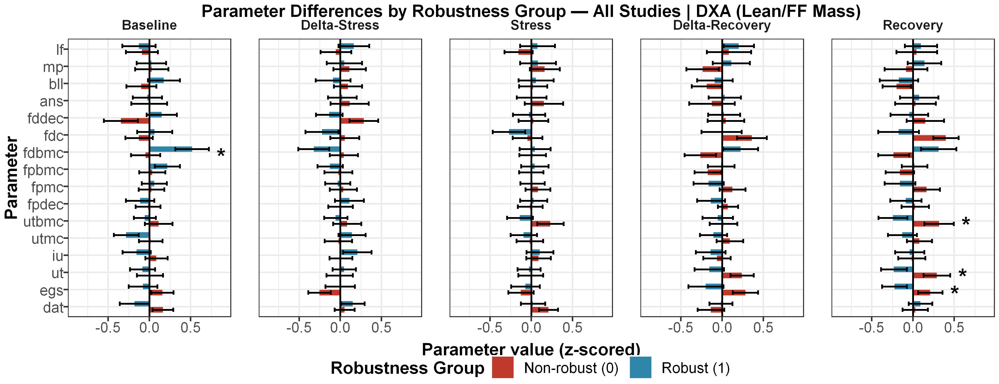

In [225]:
options(repr.plot.width=6.5, repr.plot.height=2.5, repr.plot.res=600)
plots[["dxa_robustness_extreme | All Studies"]]
pvalue_tables[["dxa_robustness_extreme | All Studies"]] %>% filter(star != "")

study_scope,outcome,outcome_label,group_type,param,facet,n_0,n_1,mean_z_0,mean_z_1,mean_diff_z,sd_z_0,sd_z_1,t_value,df,p,p_bh,star,star_bh
<chr>,<chr>,<chr>,<chr>,<fct>,<fct>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
All Studies,dxa_resilience_extreme,DXA (Lean/FF Mass),Resilience,ans,Baseline,21,21,-0.4182193,0.1551392,0.5733585,0.7129335,1.004391,2.133204,36.07331,0.039780914,0.7879543,*,
All Studies,dxa_resilience_extreme,DXA (Lean/FF Mass),Resilience,lf,Delta-Stress,21,21,-0.3305669,0.2420258,0.5725927,0.7871777,1.012211,2.046329,37.71275,0.047742022,0.7879543,*,
All Studies,dxa_resilience_extreme,DXA (Lean/FF Mass),Resilience,lf,Delta-Recovery,21,21,0.4289130,-0.3811225,-0.8100354,0.7639475,1.098325,-2.774567,35.68152,0.008739363,0.6991490,**,


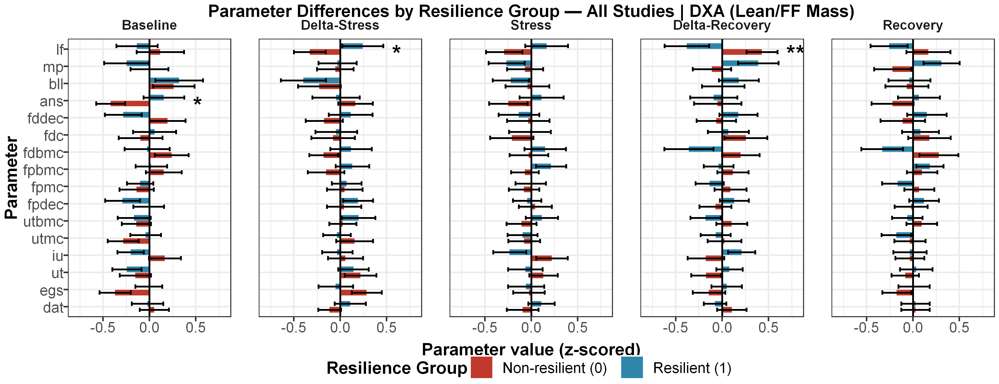

In [226]:
options(repr.plot.width=6.5, repr.plot.height=2.5, repr.plot.res=600)
plots[["dxa_resilience_extreme | All Studies"]]
pvalue_tables[["dxa_resilience_extreme | All Studies"]] %>% filter(star != "")

study_scope,outcome,outcome_label,group_type,param,facet,n_0,n_1,mean_z_0,mean_z_1,mean_diff_z,sd_z_0,sd_z_1,t_value,df,p,p_bh,star,star_bh
<chr>,<chr>,<chr>,<chr>,<fct>,<fct>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
All Studies,poms_robustness_extreme,POMS (TMD),Robustness,dat,Baseline,45,45,0.2418875,-0.1873777,-0.4292652,0.6961340,1.1602233,-2.128241,72.04533,0.036738197,0.5650991,*,
All Studies,poms_robustness_extreme,POMS (TMD),Robustness,dat,Delta-Stress,45,45,-0.2697162,0.2340933,0.5038096,1.1588863,0.8590786,2.342789,81.14196,0.021589751,0.5033923,*,
All Studies,poms_robustness_extreme,POMS (TMD),Robustness,egs,Delta-Stress,45,45,0.3345391,-0.3273110,-0.6618501,1.0345958,0.9805889,-3.114656,87.74826,0.002487836,0.1990269,**,
All Studies,poms_robustness_extreme,POMS (TMD),Robustness,egs,Stress,45,45,0.1593836,-0.3202031,-0.4795867,0.9940181,1.0035103,-2.277668,87.99205,0.025169617,0.5033923,*,
All Studies,poms_robustness_extreme,POMS (TMD),Robustness,ut,Stress,45,45,0.1528008,-0.2788646,-0.4316654,1.0204300,0.9669947,-2.059780,87.74664,0.042382430,0.5650991,*,
All Studies,poms_robustness_extreme,POMS (TMD),Robustness,utmc,Delta-Stress,45,45,0.2607754,-0.1688775,-0.4296529,0.8703047,0.8989825,-2.303476,87.90767,0.023611362,0.5033923,*,


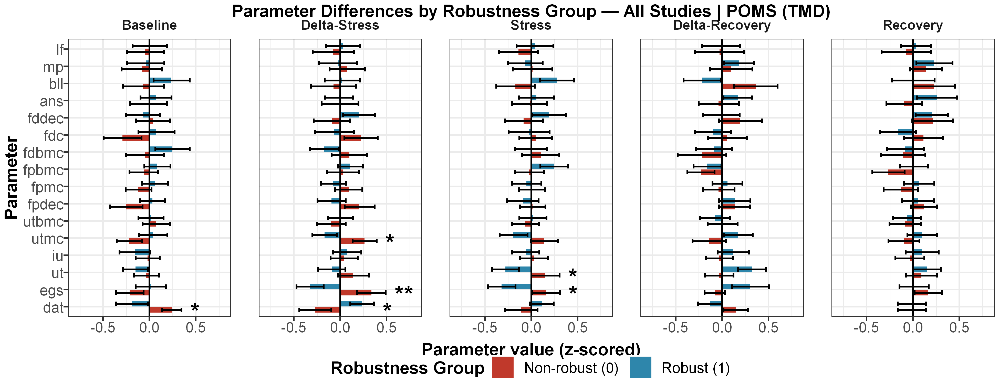

In [227]:
options(repr.plot.width=6.5, repr.plot.height=2.5, repr.plot.res=600)
plots[["poms_robustness_extreme | All Studies"]]
pvalue_tables[["poms_robustness_extreme | All Studies"]] %>% filter(star != "")

study_scope,outcome,outcome_label,group_type,param,facet,n_0,n_1,mean_z_0,mean_z_1,mean_diff_z,sd_z_0,sd_z_1,t_value,df,p,p_bh,star,star_bh
<chr>,<chr>,<chr>,<chr>,<fct>,<fct>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
All Studies,poms_resilience_extreme,POMS (TMD),Resilience,dat,Delta-Recovery,39,41,-0.3636071,0.08646754,0.4500746,1.048243,0.9201902,2.036826,75.55846,0.04517075,0.9870259,*,


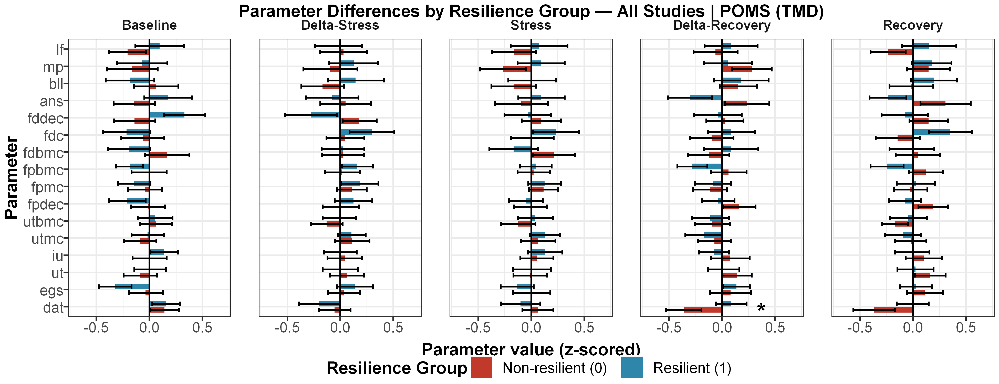

In [228]:
options(repr.plot.width=6.5, repr.plot.height=2.5, repr.plot.res=600)
plots[["poms_resilience_extreme | All Studies"]]
pvalue_tables[["poms_resilience_extreme | All Studies"]] %>% filter(star != "")

study_scope,outcome,outcome_label,group_type,param,facet,n_0,n_1,mean_z_0,mean_z_1,mean_diff_z,sd_z_0,sd_z_1,t_value,df,p,p_bh,star,star_bh
<chr>,<chr>,<chr>,<chr>,<fct>,<fct>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
All Studies,pvt_mrrt_robustness_extreme,PVT (MRRT),Robustness,egs,Delta-Stress,40,40,0.1673089,-0.2686213,-0.4359301,1.0631297,0.8808477,-1.996962,75.39444,0.0494387080,0.35735954,*,
All Studies,pvt_mrrt_robustness_extreme,PVT (MRRT),Robustness,iu,Delta-Stress,40,40,-0.3717187,0.2916231,0.6633418,1.0957021,1.0192398,2.803498,77.59537,0.0063830802,0.14102294,**,
All Studies,pvt_mrrt_robustness_extreme,PVT (MRRT),Robustness,iu,Stress,40,40,-0.4046494,0.2716227,0.6762720,0.9549219,1.0235459,3.055458,77.62733,0.0030796253,0.12318501,**,
All Studies,pvt_mrrt_robustness_extreme,PVT (MRRT),Robustness,iu,Delta-Recovery,36,36,0.3622233,-0.1088194,-0.4710426,0.7810412,0.9366687,-2.317402,67.80960,0.0235080091,0.25775103,*,
All Studies,pvt_mrrt_robustness_extreme,PVT (MRRT),Robustness,fpdec,Delta-Stress,40,40,0.3289790,-0.3824405,-0.7114196,0.8392324,0.9280707,-3.595934,77.22340,0.0005675691,0.04540552,***,*
All Studies,pvt_mrrt_robustness_extreme,PVT (MRRT),Robustness,fpdec,Stress,40,40,0.2716552,-0.2489143,-0.5205695,0.7691898,1.1596939,-2.365894,67.75011,0.0208541735,0.25775103,*,
All Studies,pvt_mrrt_robustness_extreme,PVT (MRRT),Robustness,fdbmc,Baseline,24,24,-0.4875575,0.1816218,0.6691793,0.9762636,1.0346839,2.304513,45.84549,0.0257751035,0.25775103,*,
All Studies,pvt_mrrt_robustness_extreme,PVT (MRRT),Robustness,fdbmc,Delta-Stress,24,24,0.4789786,-0.2727600,-0.7517386,1.1500863,0.9781627,-2.439229,44.84456,0.0187400540,0.25775103,*,
All Studies,pvt_mrrt_robustness_extreme,PVT (MRRT),Robustness,mp,Delta-Stress,24,24,-0.3167256,0.5125098,0.8292355,0.8890607,1.1284167,2.827839,43.61220,0.0070511471,0.14102294,**,


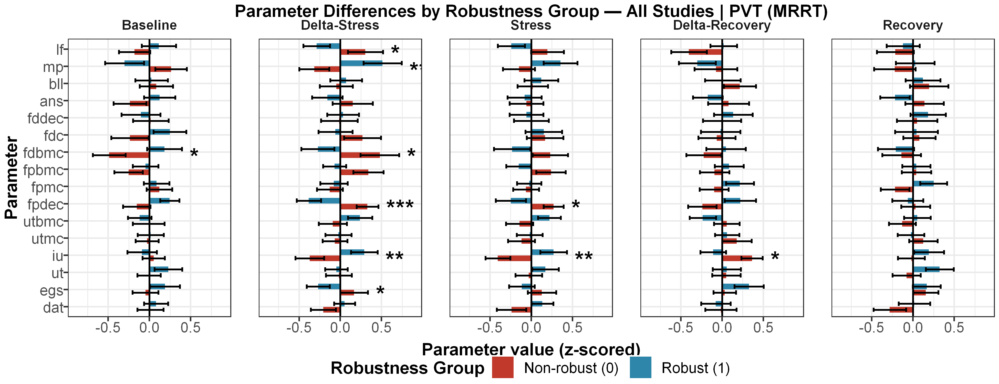

In [229]:
options(repr.plot.width=6.5, repr.plot.height=2.5, repr.plot.res=600)
plots[["pvt_mrrt_robustness_extreme | All Studies"]]
pvalue_tables[["pvt_mrrt_robustness_extreme | All Studies"]] %>% filter(star != "")

study_scope,outcome,outcome_label,group_type,param,facet,n_0,n_1,mean_z_0,mean_z_1,mean_diff_z,sd_z_0,sd_z_1,t_value,df,p,p_bh,star,star_bh
<chr>,<chr>,<chr>,<chr>,<fct>,<fct>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
All Studies,pvt_mrrt_resilience_extreme,PVT (MRRT),Resilience,utbmc,Delta-Recovery,36,36,-0.2346212,0.3631756,0.5977969,1.0042624,0.9402096,2.607250,69.69813,0.01115570,0.529571,*,
All Studies,pvt_mrrt_resilience_extreme,PVT (MRRT),Resilience,fpdec,Stress,36,36,-0.2422403,0.2471840,0.4894244,1.2032197,0.8222032,2.015044,61.83520,0.04825303,0.529571,*,
All Studies,pvt_mrrt_resilience_extreme,PVT (MRRT),Resilience,fpbmc,Delta-Stress,36,36,-0.3691425,0.2304890,0.5996315,0.9054809,1.2180502,2.370487,64.63368,0.02075787,0.529571,*,
All Studies,pvt_mrrt_resilience_extreme,PVT (MRRT),Resilience,fpbmc,Delta-Recovery,36,36,0.4008975,-0.1315020,-0.5323995,0.9565751,1.0752640,-2.219601,69.06375,0.02973216,0.529571,*,
All Studies,pvt_mrrt_resilience_extreme,PVT (MRRT),Resilience,lf,Delta-Recovery,20,20,0.3178067,-0.3335055,-0.6513123,0.5880292,1.0823496,-2.364691,29.31735,0.02487417,0.529571,*,


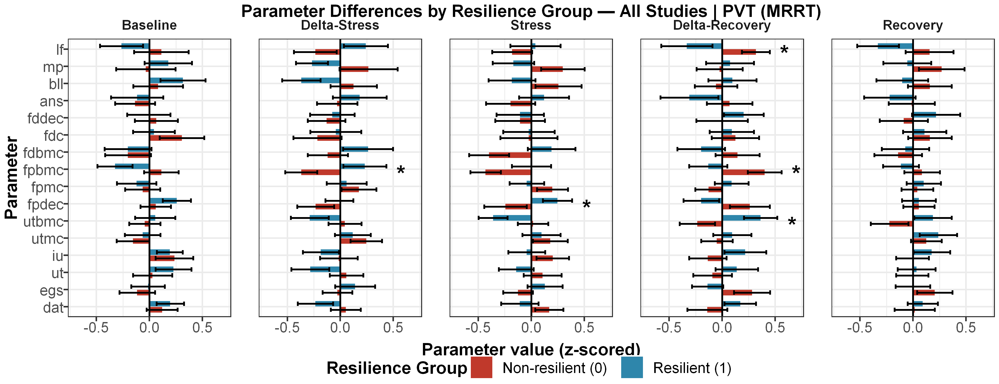

In [230]:
options(repr.plot.width=6.5, repr.plot.height=2.5, repr.plot.res=600)
plots[["pvt_mrrt_resilience_extreme | All Studies"]]
pvalue_tables[["pvt_mrrt_resilience_extreme | All Studies"]] %>% filter(star != "")

study_scope,outcome,outcome_label,group_type,param,facet,n_0,n_1,mean_z_0,mean_z_1,mean_diff_z,sd_z_0,sd_z_1,t_value,df,p,p_bh,star,star_bh
<chr>,<chr>,<chr>,<chr>,<fct>,<fct>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
All Studies,pvt_fsl_robustness_extreme,PVT (FS + L),Robustness,dat,Delta-Stress,43,41,-0.4763527,0.25196686,0.7283196,1.1101791,0.8989626,3.311457,79.93516,0.001394836,0.1115869,**,
All Studies,pvt_fsl_robustness_extreme,PVT (FS + L),Robustness,dat,Stress,43,41,-0.3079924,0.32527269,0.6332651,1.2822567,0.5446979,2.969665,57.24868,0.004349639,0.1159904,**,
All Studies,pvt_fsl_robustness_extreme,PVT (FS + L),Robustness,egs,Delta-Stress,43,41,0.2267303,-0.23928503,-0.4660154,1.1272839,0.7527295,-2.237659,73.57203,0.028271068,0.3230979,*,
All Studies,pvt_fsl_robustness_extreme,PVT (FS + L),Robustness,iu,Baseline,43,41,0.2561108,-0.28103274,-0.5371435,0.8668473,1.0640939,-2.529536,77.19888,0.013458956,0.2153433,*,
All Studies,pvt_fsl_robustness_extreme,PVT (FS + L),Robustness,iu,Delta-Stress,43,41,-0.3978228,0.21894418,0.6167670,0.9252833,0.9137294,3.073331,81.89592,0.002874715,0.1149886,**,
All Studies,pvt_fsl_robustness_extreme,PVT (FS + L),Robustness,fpdec,Delta-Stress,43,41,0.1746823,-0.34358780,-0.5182701,0.6145015,0.9986730,-2.848359,65.91249,0.005855971,0.1171194,**,
All Studies,pvt_fsl_robustness_extreme,PVT (FS + L),Robustness,fdbmc,Baseline,27,25,-0.3032908,0.31429387,0.6175846,1.0840705,0.9683965,2.169463,49.94143,0.034832938,0.3483294,*,
All Studies,pvt_fsl_robustness_extreme,PVT (FS + L),Robustness,fdbmc,Delta-Stress,27,25,0.3229159,-0.27988176,-0.6027977,1.1262233,0.9483769,-2.092925,49.57417,0.041495007,0.3688445,*,
All Studies,pvt_fsl_robustness_extreme,PVT (FS + L),Robustness,lf,Delta-Stress,27,25,0.4856049,-0.06815588,-0.5537608,1.0742478,0.6291228,-2.288094,42.51012,0.027168513,0.3230979,*,


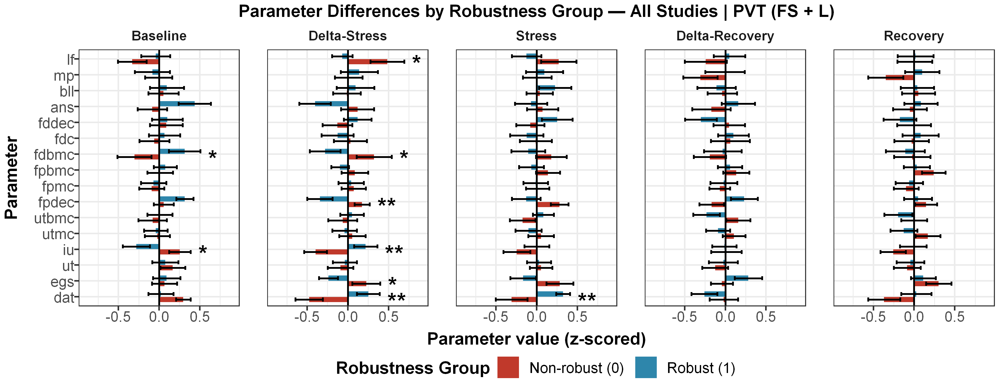

In [231]:
options(repr.plot.width=6.5, repr.plot.height=2.5, repr.plot.res=600)
plots[["pvt_fsl_robustness_extreme | All Studies"]]
pvalue_tables[["pvt_fsl_robustness_extreme | All Studies"]] %>% filter(star != "")

study_scope,outcome,outcome_label,group_type,param,facet,n_0,n_1,mean_z_0,mean_z_1,mean_diff_z,sd_z_0,sd_z_1,t_value,df,p,p_bh,star,star_bh
<chr>,<chr>,<chr>,<chr>,<fct>,<fct>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
All Studies,pvt_fsl_resilience_extreme,PVT (FS + L),Resilience,dat,Delta-Stress,38,38,0.2136035,-0.27453739,-0.4881409,0.7394910,0.8998311,-2.583570,71.32225,0.011828015,0.3154137,*,
All Studies,pvt_fsl_resilience_extreme,PVT (FS + L),Resilience,dat,Stress,38,38,0.3813815,-0.14443809,-0.5258196,0.4051712,1.0761132,-2.818920,47.28375,0.007016116,0.2806446,**,
All Studies,pvt_fsl_resilience_extreme,PVT (FS + L),Resilience,egs,Delta-Recovery,38,38,0.4388733,-0.24639006,-0.6852634,0.9668204,1.0302877,-2.989810,73.70286,0.003792501,0.2806446,**,
All Studies,pvt_fsl_resilience_extreme,PVT (FS + L),Resilience,egs,Recovery,38,38,0.4576092,0.02501474,-0.4325944,0.7756241,1.0792003,-2.006525,67.17309,0.048828272,0.6428278,*,
All Studies,pvt_fsl_resilience_extreme,PVT (FS + L),Resilience,iu,Delta-Stress,38,38,0.1643628,-0.31688516,-0.4812479,1.0074272,1.0289506,-2.060123,73.96695,0.042905038,0.6428278,*,
All Studies,pvt_fsl_resilience_extreme,PVT (FS + L),Resilience,iu,Stress,38,38,0.1585838,-0.29874583,-0.4573296,0.8576260,1.0728001,-2.052587,70.57802,0.043821952,0.6428278,*,


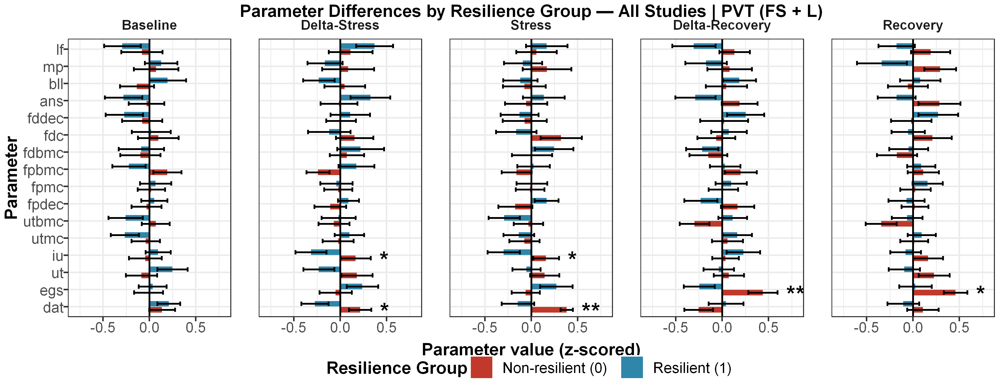

In [232]:
options(repr.plot.width=6.5, repr.plot.height=2.5, repr.plot.res=600)
plots[["pvt_fsl_resilience_extreme | All Studies"]]
pvalue_tables[["pvt_fsl_resilience_extreme | All Studies"]] %>% filter(star != "")

In [233]:
robust_facets <- c("Baseline", "Delta-Stress", "Stress")
resilience_facets <- c("Stress", "Delta-Recovery", "Recovery")

adaptation_levels <- c("Robustness", "Resilience")

# Robustness colors
robust_colors <- c(
  "Non-robust (0)" = "#C0392B",
  "Robust (1)"     = "#2E86AB"
)

# Resilience colors
resilience_colors <- c(
  "Non-resilient (0)" = "#D35400",
  "Resilient (1)"     = "#1B9E77"
)

resilience_colors <- c(
  "Non-resilient (0)" = "#762A83",
  "Resilient (1)"     = "#A6DBA0"
)

# Option 3: Magenta / Olive
resilience_colors <- c(
  "Non-resilient (0)" = "#C51B7D",
  "Resilient (1)"     = "#4D9221"
)

In [234]:
make_combined_adaptation_plot <- function(
    dat,
    robustness_col,
    resilience_col,
    title_text,
    use_bh_stars = FALSE
) {
  
  if (!requireNamespace("ggnewscale", quietly = TRUE)) {
    stop("Package 'ggnewscale' is required for separate robustness and resilience legends.")
  }
  
  # ----------------------------
  # Robustness data
  # ----------------------------
  robust_dat <- dat %>%
    filter(
      facet %in% robust_facets,
      !is.na(.data[[robustness_col]]),
      .data[[robustness_col]] %in% c(0, 1),
      is.finite(z)
    ) %>%
    mutate(
      adaptation_type = factor("Robustness", levels = adaptation_levels),
      group = factor(
        .data[[robustness_col]],
        levels = c(0, 1),
        labels = names(robust_colors)
      ),
      facet = factor(as.character(facet), levels = facet_order),
      param = factor(param, levels = params)
    )
  
  # ----------------------------
  # Resilience data
  # ----------------------------
  resilience_dat <- dat %>%
    filter(
      facet %in% resilience_facets,
      !is.na(.data[[resilience_col]]),
      .data[[resilience_col]] %in% c(0, 1),
      is.finite(z)
    ) %>%
    mutate(
      adaptation_type = factor("Resilience", levels = adaptation_levels),
      group = factor(
        .data[[resilience_col]],
        levels = c(0, 1),
        labels = names(resilience_colors)
      ),
      facet = factor(as.character(facet), levels = facet_order),
      param = factor(param, levels = params)
    )
  
  dat2 <- bind_rows(robust_dat, resilience_dat)
  
  if (nrow(dat2) == 0) {
    return(
      list(
        plot = ggplot() +
          theme_void() +
          labs(title = paste0(title_text, " — no plottable data")),
        pvalues = tibble()
      )
    )
  }
  
  # ----------------------------
  # Mean bars
  # ----------------------------
  bar_df <- dat2 %>%
    group_by(adaptation_type, facet, param, group) %>%
    summarise(
      n = sum(!is.na(z)),
      mean_z = mean(z, na.rm = TRUE),
      se_z = ifelse(n > 1, sd(z, na.rm = TRUE) / sqrt(n), NA_real_),
      .groups = "drop"
    ) %>%
    filter(is.finite(mean_z)) %>%
    mutate(
      se_z = ifelse(is.na(se_z), 0, se_z)
    )
  
  # ----------------------------
  # Significance tables
  # ----------------------------
  sig_robust <- compute_sig(
    dat %>% filter(facet %in% robust_facets),
    robustness_col
  ) %>%
    mutate(
      adaptation_type = factor("Robustness", levels = adaptation_levels),
      outcome = robustness_col,
      group_type = "Robustness"
    )
  
  sig_resilience <- compute_sig(
    dat %>% filter(facet %in% resilience_facets),
    resilience_col
  ) %>%
    mutate(
      adaptation_type = factor("Resilience", levels = adaptation_levels),
      outcome = resilience_col,
      group_type = "Resilience"
    )
  
  sig_df <- bind_rows(sig_robust, sig_resilience) %>%
    mutate(
      facet = factor(as.character(facet), levels = facet_order),
      param = factor(param, levels = params)
    )
  
  # ----------------------------
  # Star positions
  # ----------------------------
  star_pos <- bar_df %>%
    group_by(adaptation_type, facet, param) %>%
    summarise(
      min_end  = min(mean_z - se_z, na.rm = TRUE),
      max_end  = max(mean_z + se_z, na.rm = TRUE),
      min_mean = min(mean_z, na.rm = TRUE),
      max_mean = max(mean_z, na.rm = TRUE),
      .groups = "drop"
    ) %>%
    filter(
      is.finite(min_end),
      is.finite(max_end),
      is.finite(min_mean),
      is.finite(max_mean)
    ) %>%
    left_join(sig_df, by = c("adaptation_type", "facet", "param")) %>%
    mutate(
      x_star = case_when(
        max_mean < 0 ~ min_end - 0.10,
        min_mean > 0 ~ max_end + 0.10,
        TRUE         ~ max_end + 0.10
      ),
      hjust = case_when(
        max_mean < 0 ~ 1,
        TRUE         ~ 0
      )
    )
  
  star_col <- ifelse(use_bh_stars, "star_bh", "star")
  star_pos$star_plot <- star_pos[[star_col]]
  
  # ----------------------------
  # X-axis limits
  # ----------------------------
  x_vals <- c(
    bar_df$mean_z - bar_df$se_z,
    bar_df$mean_z,
    bar_df$mean_z + bar_df$se_z,
    star_pos$x_star
  )
  
  x_vals <- x_vals[is.finite(x_vals)]
  
  if (length(x_vals) == 0) {
    return(
      list(
        plot = ggplot() +
          theme_void() +
          labs(title = paste0(title_text, " — no plottable data")),
        pvalues = sig_df
      )
    )
  }
  
  x_lim <- max(abs(x_vals), na.rm = TRUE)
  
  if (!is.finite(x_lim) || x_lim == 0) {
    x_lim <- 0.5
  }
  
  x_lim <- ceiling((x_lim * 1.05) * 10) / 10
  
  bar_robust <- bar_df %>%
    filter(adaptation_type == "Robustness")
  
  bar_resilience <- bar_df %>%
    filter(adaptation_type == "Resilience")
  
  # Use true nested facets if ggh4x is installed; otherwise use standard ggplot facets
  #facet_layer <- if (requireNamespace("ggh4x", quietly = TRUE)) {
  #  ggh4x::facet_nested(. ~ adaptation_type + facet, drop = TRUE)
  #} else {
  #  facet_grid(. ~ adaptation_type + facet, drop = TRUE)
  #}
  facet_layer <- if (requireNamespace("ggh4x", quietly = TRUE)) {
      ggh4x::facet_nested(
        . ~ adaptation_type + facet,
        drop = TRUE,
        nest_line = element_blank(),
        strip = ggh4x::strip_nested(
          by_layer_x = TRUE,
          background_x = list(
            element_rect(fill = "grey85", colour = "black", linewidth = 0.4),
            element_rect(fill = NA, colour = NA, linewidth = 0)
          ),
          text_x = ggh4x::elem_list_text(
            face = c("bold", "bold"),
            size = c(7, 6),
            lineheight = c(0.8, 0.8),
            margin = list(
              margin(t = 2, r = 2, b = 2, l = 2),
              margin(t = 1, r = 2, b = 0, l = 2)
            )
          )
        )
      )
    } else {
      facet_grid(. ~ adaptation_type + facet, drop = TRUE)
    }
    
  # ----------------------------
  # Plot
  # ----------------------------
  p <- ggplot() +
    geom_vline(xintercept = 0, linewidth = 0.4) +
    
    # Robustness layers
    geom_col(
      data = bar_robust,
      aes(x = mean_z, y = param, fill = group),
      position = position_dodge(width = 0.7),
      width = 0.65
    ) +
    geom_errorbarh(
      data = bar_robust,
      aes(
        y = param,
        xmin = mean_z - se_z,
        xmax = mean_z + se_z,
        group = group
      ),
      position = position_dodge(width = 0.7),
      height = 0.5,
      linewidth = 0.4
    ) +
    scale_fill_manual(
      values = robust_colors,
      name = "Robustness Group",
      drop = FALSE,
      guide = guide_legend(order = 1)
    ) +
    
    ggnewscale::new_scale_fill() +
    
    # Resilience layers
    geom_col(
      data = bar_resilience,
      aes(x = mean_z, y = param, fill = group),
      position = position_dodge(width = 0.7),
      width = 0.65
    ) +
    geom_errorbarh(
      data = bar_resilience,
      aes(
        y = param,
        xmin = mean_z - se_z,
        xmax = mean_z + se_z,
        group = group
      ),
      position = position_dodge(width = 0.7),
      height = 0.5,
      linewidth = 0.4
    ) +
    scale_fill_manual(
      values = resilience_colors,
      name = "Resilience Group",
      drop = FALSE,
      guide = guide_legend(order = 2)
    ) +
    
    geom_text(
      data = star_pos %>% filter(!is.na(star_plot), star_plot != ""),
      aes(x = x_star, y = param, label = star_plot, hjust = hjust),
      inherit.aes = FALSE,
      size = 4,
      fontface = "bold",
      vjust = 0.75
    ) +
    
    facet_layer +
    
    scale_y_discrete(drop = FALSE) +
    scale_x_continuous(breaks = pretty_breaks(n = 3)) +
    coord_cartesian(xlim = c(-x_lim, x_lim), clip = "on") +
    
    labs(
      title = title_text,
      x = "Parameter value (z-scored within parameter × phase)",
      y = "Parameter"
    ) +
    
    theme_bw(base_size = 8) +
    theme(
      legend.position = "bottom",
      legend.box = "horizontal",
      strip.placement = "outside",
      strip.background = element_blank(),
      #strip.background = element_rect(fill = "grey90",color = "black",linewidth = 0.4),
      panel.spacing.x = unit(0.5, "lines"),
      text = element_text(size = 8, face = "bold"),
      plot.title = element_text(size = 8, hjust = 0.5, margin = margin(0, 0, 1, 0)),
      axis.text.x = element_text(size = 7, face = "plain", margin = margin(0, 0, 0, 0)),
      axis.title.x = element_text(size = 8, margin = margin(3, 0, 0, 0)),
      axis.text.y = element_text(size = 7, face = "plain", margin = margin(0, 0, 0, 0)),
      axis.title.y = element_text(size = 8, margin = margin(0, 5, 0, 0)),
      legend.title = element_text(size = 8, face = "bold", margin = margin(r = 10)),
      legend.text = element_text(size = 7, face = "plain"),
      legend.key.size = unit(0.8, "lines"),
      legend.margin = margin(-5, 0, 0, 0),
      legend.box.margin = margin(0, 0, 0, 0),
      legend.spacing.x = unit(1.0, "cm"),
      plot.margin = margin(2, 2, 2, 2)
    )
  
  list(
    plot = p,
    pvalues = sig_df
  )
}

In [235]:
outcome_pairs <- tibble::tribble(
  ~outcome_family, ~outcome_label,           ~robustness_col,              ~resilience_col,
  "dxa",           "DXA (Lean/FF Mass)",     "dxa_robustness_extreme",        "dxa_resilience_extreme",
  "pvt_mrrt",      "PVT (MRRT)",             "pvt_mrrt_robustness_extreme",   "pvt_mrrt_resilience_extreme",
  "pvt_fsl",       "PVT (FS + L)",           "pvt_fsl_robustness_extreme",    "pvt_fsl_resilience_extreme",
  "poms",          "POMS (TMD)",             "poms_robustness_extreme",       "poms_resilience_extreme"
)

In [236]:
combined_plots <- list()
combined_pvalue_tables <- list()

for (i in seq_len(nrow(outcome_pairs))) {
  
  outcome_family_i <- outcome_pairs$outcome_family[i]
  outcome_label_i  <- outcome_pairs$outcome_label[i]
  robustness_col_i <- outcome_pairs$robustness_col[i]
  resilience_col_i <- outcome_pairs$resilience_col[i]
  
  for (scope_name in names(study_scopes)) {
    
    studies_keep <- study_scopes[[scope_name]]
    
    dat_scope <- df_facets %>%
      filter(study %in% studies_keep)
    
    title_text <- paste0(
      "Parameter Differences by Adaptation Group — ",
      scope_name,
      " | ",
      outcome_label_i
    )
    
    res <- make_combined_adaptation_plot(
      dat = dat_scope,
      robustness_col = robustness_col_i,
      resilience_col = resilience_col_i,
      title_text = title_text
    )
    
    plot_name <- paste(outcome_family_i, scope_name, sep = " | ")
    
    combined_plots[[plot_name]] <- res$plot
    
    combined_pvalue_tables[[plot_name]] <- res$pvalues %>%
      mutate(
        study_scope = scope_name,
        outcome_family = outcome_family_i,
        outcome_label = outcome_label_i
      ) %>%
      select(
        study_scope,
        outcome_family,
        outcome,
        outcome_label,
        group_type,
        param,
        facet,
        n_0,
        n_1,
        mean_z_0,
        mean_z_1,
        mean_diff_z,
        sd_z_0,
        sd_z_1,
        t_value,
        df,
        p,
        p_bh,
        star,
        star_bh
      )
  }
}

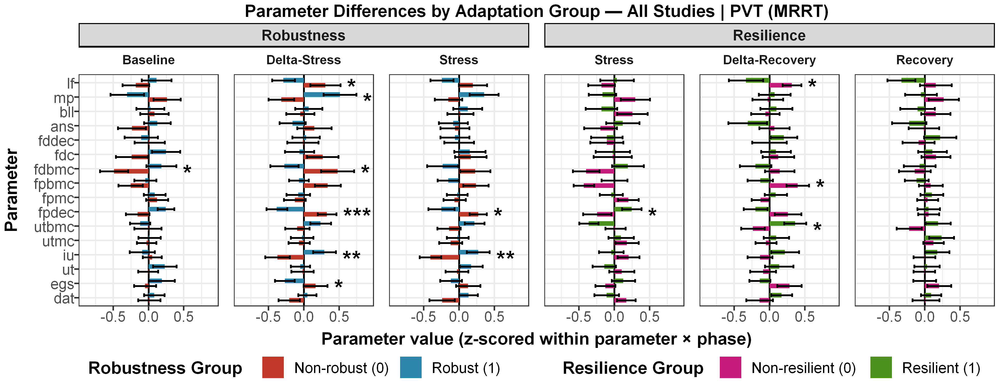

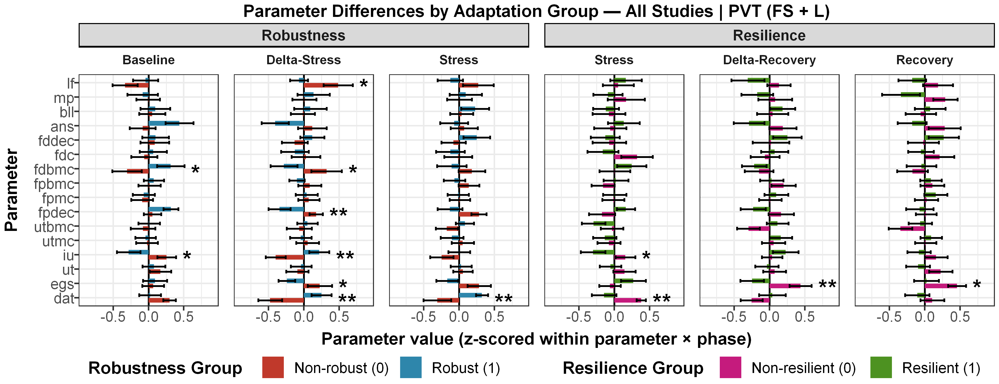

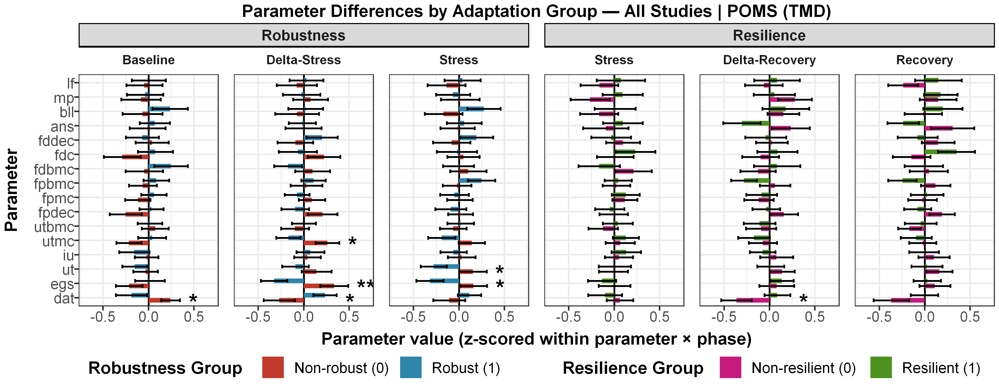

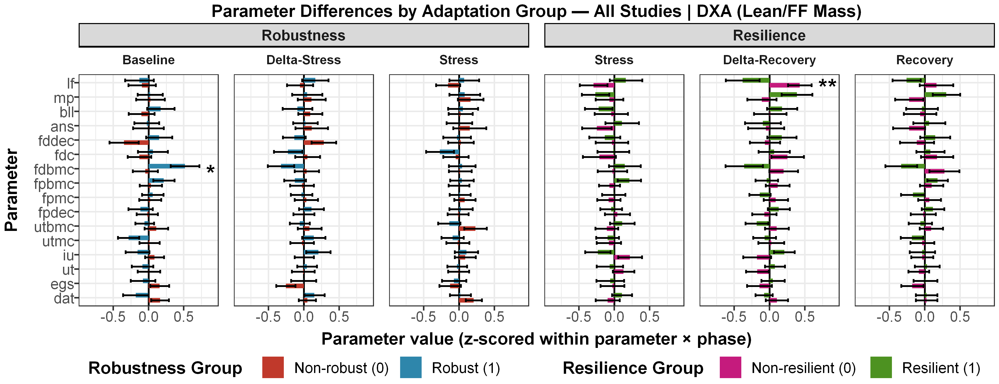

In [237]:
options(repr.plot.width = 6.5, repr.plot.height = 2.5, repr.plot.res = 600)

combined_plots[["pvt_mrrt | All Studies"]]
combined_plots[["pvt_fsl | All Studies"]]
combined_plots[["poms | All Studies"]]
combined_plots[["dxa | All Studies"]]

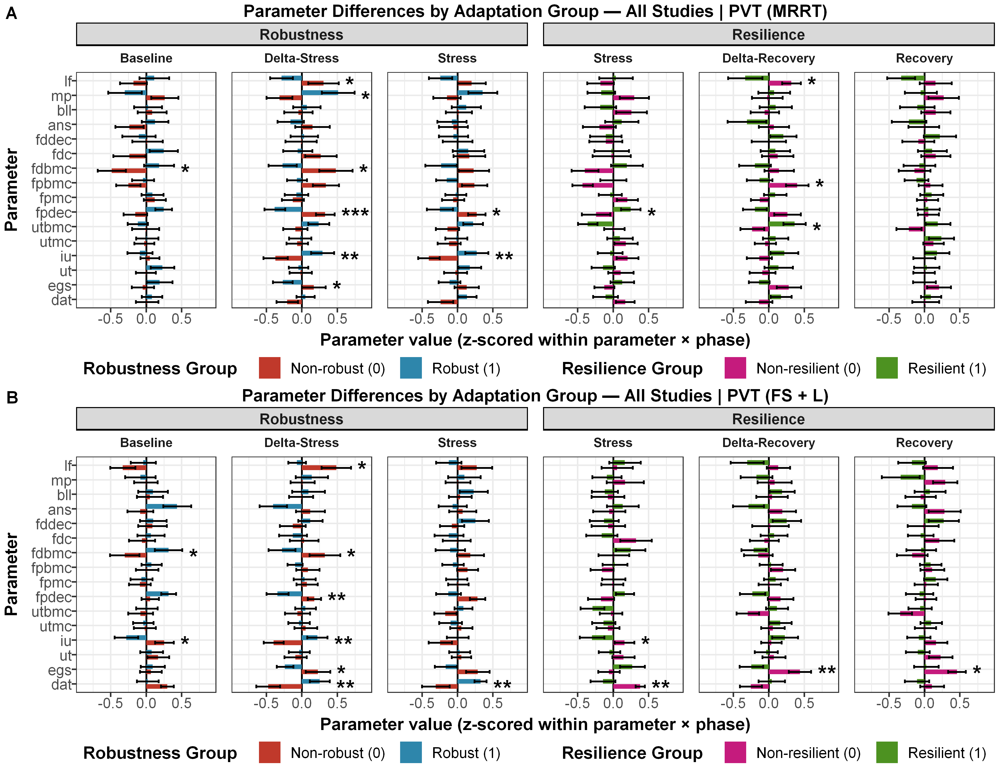

In [238]:
options(repr.plot.width = 6.5, repr.plot.height = 5, repr.plot.res = 600)
extremes_mrrt_fsl <- cowplot::plot_grid(
  combined_plots[["pvt_mrrt | All Studies"]],
  combined_plots[["pvt_fsl | All Studies"]],
  ncol = 1,
  labels = c("A", "B"),
  label_size = 8,
  align = "none"
)
extremes_mrrt_fsl


In [403]:
ggsave("mrrt_fsl_extremophiles_v1.png", extremes_mrrt_fsl, width = 6.5, height = 5, dpi = 600)
ggsave("poms_extremophiles_v1.png", combined_plots[["poms | All Studies"]], width = 6.5, height = 2.5, dpi = 600)
ggsave("dxa_extremophiles_v1.png", combined_plots[["dxa | All Studies"]], width = 6.5, height = 2.5, dpi = 600)

In [404]:
ggsave(
  "mrrt_fsl_extremophiles_v1.svg",
  extremes_mrrt_fsl,
  width = 6.5,
  height = 5,
  device = "svg"
)

ggsave(
  "poms_extremophiles_v1.svg",
  combined_plots[["poms | All Studies"]],
  width = 6.5,
  height = 2.5,
  device = "svg"
)

ggsave(
  "dxa_extremophiles_v1.svg",
  combined_plots[["dxa | All Studies"]],
  width = 6.5,
  height = 2.5,
  device = "svg"
)

In [405]:
ggsave(
  "mrrt_fsl_extremophiles_v1.pdf",
  extremes_mrrt_fsl,
  width = 6.5,
  height = 5,
  device = cairo_pdf
)

ggsave(
  "poms_extremophiles_v1.pdf",
  combined_plots[["poms | All Studies"]],
  width = 6.5,
  height = 2.5,
  device = cairo_pdf
)

ggsave(
  "dxa_extremophiles_v1.pdf",
  combined_plots[["dxa | All Studies"]],
  width = 6.5,
  height = 2.5,
  device = cairo_pdf
)

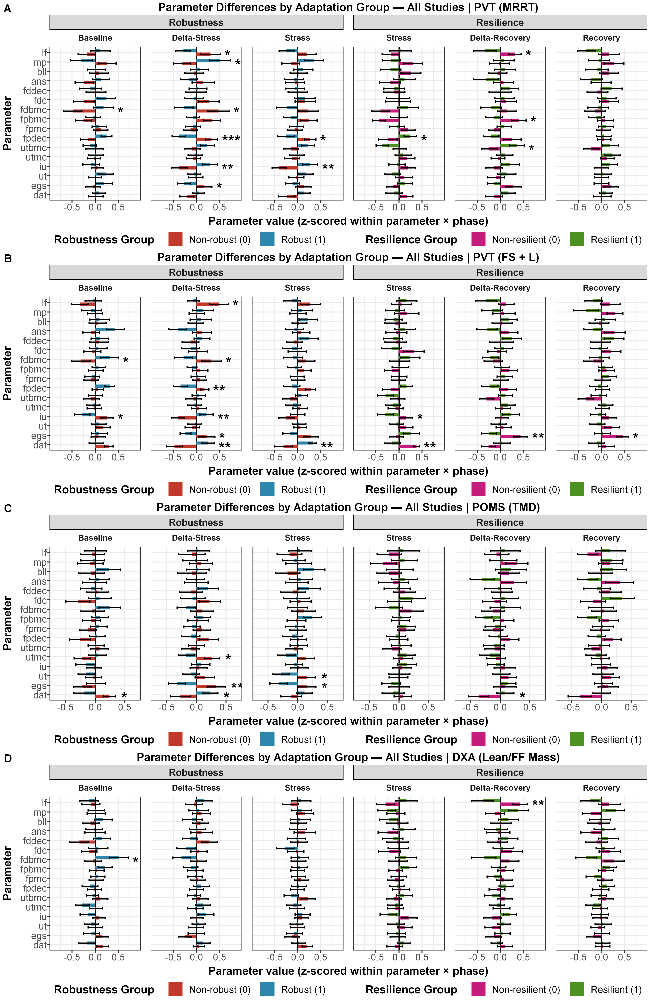

In [191]:
options(repr.plot.width=6.5, repr.plot.height=10, repr.plot.res=600)
extremes_mrrt_fsl_all <- cowplot::plot_grid(
  combined_plots[["pvt_mrrt | All Studies"]],
  combined_plots[["pvt_fsl | All Studies"]],
  combined_plots[["poms | All Studies"]],
  combined_plots[["dxa | All Studies"]],
  ncol = 1,
  labels = c("A", "B", "C", "D"),
  label_size = 8,
  align = "none"
)

extremes_mrrt_fsl_all

In [360]:
ggsave("all_mrrt_extremophiles_v1.png", extremes_mrrt_fsl_all, width = 6.5, height = 10, dpi = 600)

In [361]:
ggsave(
  "all_mrrt_extremophiles_v1.svg",
  extremes_mrrt_fsl_all,
  width = 6.5,
  height = 10,
  device = "svg"
)

In [362]:
ggsave(
  "all_mrrt_extremophiles_v1.pdf",
  extremes_mrrt_fsl_all,
  width = 6.5,
  height = 10,
  device = cairo_pdf
)

# Logistic Extreme Phenotype Group Elastic Net

In [239]:
cc_pred_dat <- cc_extreme_dat_all
colnames(cc_pred_dat)
head(cc_pred_dat)

[1] "study"                       "subjectid"                  
 [3] "phase"                       "study_event_id"             
 [5] "bout"                        "kl_val"                     
 [7] "mle_val"                     "dat"                        
 [9] "egs"                         "ut"                         
[11] "iu"                          "utmc"                       
[13] "utbmc"                       "fpdec"                      
[15] "fpmc"                        "fpbmc"                      
[17] "fdbmc"                       "fdc"                        
[19] "fddec"                       "ans"                        
[21] "bll"                         "mp"                         
[23] "lf"                          "poms_delta_stress"          
[25] "poms_delta_recovery"         "poms_robustness_extreme"    
[27] "poms_resilience_extreme"     "dxa_delta_stress"           
[29] "dxa_delta_recovery"          "dxa_robustness_extreme"     
[31] "dxa_resilience_extreme"      "delta_stress_mrrt"          
[33] "delta_recovery_mrrt"         "delta_stress_fsl"           
[35] "delta_recovery_fsl"          "pvt_mrrt_robustness_extreme"
[37] "pvt_mrrt_resilience_extreme" "pvt_fsl_robustness_extreme" 
[39] "pvt_fsl_resilience_extreme"

study,subjectid,phase,study_event_id,bout,kl_val,mle_val,dat,egs,ut,⋯,dxa_robustness_extreme,dxa_resilience_extreme,delta_stress_mrrt,delta_recovery_mrrt,delta_stress_fsl,delta_recovery_fsl,pvt_mrrt_robustness_extreme,pvt_mrrt_resilience_extreme,pvt_fsl_robustness_extreme,pvt_fsl_resilience_extreme
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<int>
HIGH,ROP072,Baseline,B1,181,0.07221468,-16.443619,0.05,0.31,2.82,⋯,NA,NA,-0.007943908,NA,-3,NA,NA,NA,NA,NA
HIGH,ROP072,Stress,A3,1045,0.16473468,-18.316889,0.06,0.27,2.66,⋯,NA,NA,-0.007943908,NA,-3,NA,NA,NA,NA,NA
HIGH,ROP081,Baseline,B1,181,0.20620817,-9.778598,0.06,0.28,2.54,⋯,1,NA,0.169225389,NA,-15,NA,NA,NA,1,NA
HIGH,ROP081,Stress,A3,1045,0.55755174,-9.237957,0.06,0.22,2.51,⋯,1,NA,0.169225389,NA,-15,NA,NA,NA,1,NA
HIGH,ROP084,Baseline,B1,181,NA,-1.868362,0.05,0.39,2.65,⋯,1,NA,NA,NA,NA,NA,NA,NA,NA,NA
HIGH,ROP084,Stress,A3,1045,NA,-2.918144,0.05,0.11,2.47,⋯,1,NA,NA,NA,NA,NA,NA,NA,NA,NA


In [240]:
params <- c(
  "dat", "egs", "ut", "iu",
  "utmc", "utbmc", "fpdec", "fpmc", "fpbmc",
  "fdbmc", "fdc", "fddec",
  "ans", "bll", "mp", "lf"
)

extreme_outcomes <- c(
  "pvt_mrrt_robustness_extreme",
  "pvt_mrrt_resilience_extreme",
  "pvt_fsl_robustness_extreme",
  "pvt_fsl_resilience_extreme",
  "poms_robustness_extreme",
  "poms_resilience_extreme",
  "dxa_robustness_extreme",
  "dxa_resilience_extreme"
)

mean_or_na <- function(x) {
  if (all(is.na(x))) {
    NA_real_
  } else {
    mean(x, na.rm = TRUE)
  }
}

first_nonmissing <- function(x) {
  x <- x[!is.na(x)]
  if (length(x) == 0) NA_real_ else x[1]
}

In [241]:
cc_phase <- cc_pred_dat %>%
  
  # Keep this line if you want HIGH handled exactly as in your other analyses
  filter(!(study == "HIGH" & study_event_id %in% c("A1", "A2"))) %>%
  
  mutate(
    study = as.character(study),
    subjectid = as.character(subjectid),
    phase = as.character(phase)
  ) %>%
  filter(phase %in% c("Baseline", "Stress", "Recovery")) %>%
  group_by(study, subjectid, phase) %>%
  summarise(
    across(
      all_of(params),
      mean_or_na
    ),
    .groups = "drop"
  )

In [242]:
cc_param_wide <- cc_phase %>%
  pivot_wider(
    names_from = phase,
    values_from = all_of(params),
    names_glue = "{.value}_{phase}"
  )

In [243]:
cc_groups <- cc_pred_dat %>%
  mutate(
    study = as.character(study),
    subjectid = as.character(subjectid)
  ) %>%
  group_by(study, subjectid) %>%
  summarise(
    across(
      all_of(extreme_outcomes),
      first_nonmissing
    ),
    .groups = "drop"
  )

cc_class_base <- cc_groups %>%
  left_join(
    cc_param_wide,
    by = c("study", "subjectid")
  )

In [244]:
for (p in params) {
  
  cc_class_base[[paste0(p, "_dBS")]] <-
    cc_class_base[[paste0(p, "_Stress")]] -
    cc_class_base[[paste0(p, "_Baseline")]]
  
  cc_class_base[[paste0(p, "_dSR")]] <-
    cc_class_base[[paste0(p, "_Recovery")]] -
    cc_class_base[[paste0(p, "_Stress")]]
}

In [245]:
fit_enet_classifier <- function(
    model_base,
    outcome_col,
    predictor_set,
    predictor_cols = params,
    alpha_grid = c(0, 0.25, 0.5, 0.75, 1),
    seed = 123,
    nfolds = 10
) {
  
  # ----------------------------------
  # Select predictor columns
  # ----------------------------------
  
  predictor_names <- switch(
    predictor_set,
    
    baseline =
      paste0(predictor_cols, "_Baseline"),
    
    stress_delta =
      paste0(predictor_cols, "_dBS"),
    
    stress =
      paste0(predictor_cols, "_Stress"),
    
    recovery_delta =
      paste0(predictor_cols, "_dSR"),
    
    stop("Unknown predictor_set: ", predictor_set)
  )
  
  
  # ----------------------------------
  # Keep extreme groups only
  # ----------------------------------
  
  model_dat <- model_base %>%
    filter(
      !is.na(.data[[outcome_col]]),
      .data[[outcome_col]] %in% c(0, 1)
    ) %>%
    mutate(
      study = droplevels(factor(study)),
      y = as.integer(.data[[outcome_col]])
    )
  
  
  if (nrow(model_dat) < 20 ||
      length(unique(model_dat$y)) < 2) {
    
    warning(
      "Skipping ", outcome_col,
      " / ", predictor_set,
      ": too few usable observations."
    )
    
    return(NULL)
  }
  
  
  # ----------------------------------
  # Remove parameters with no variance
  # ----------------------------------
  
  pred_ok <- sapply(
    model_dat[predictor_names],
    function(x) {
      
      x_valid <- x[
        !is.na(x) &
          is.finite(x)
      ]
      
      length(x_valid) >= 2 &&
        is.finite(sd(x_valid)) &&
        sd(x_valid) > 0
    }
  )
  
  predictor_names_use <- predictor_names[pred_ok]
  
  
  # ----------------------------------
  # Standardize parameter predictors
  # ----------------------------------
  
  x_params <- scale(
    as.matrix(
      model_dat[
        ,
        predictor_names_use,
        drop = FALSE
      ]
    )
  )
  
  # Mean imputation after standardization
  x_params[!is.finite(x_params)] <- NA
  x_params[is.na(x_params)] <- 0
  
  
  # ----------------------------------
  # Add unpenalized study effects
  # ----------------------------------
  
  if (n_distinct(model_dat$study) > 1) {
    
    x_study <- model.matrix(
      ~ study,
      data = model_dat
    )[, -1, drop = FALSE]
    
    x <- cbind(
      x_params,
      x_study
    )
    
    penalty_factor <- c(
      rep(1, ncol(x_params)),
      rep(0, ncol(x_study))
    )
    
  } else {
    
    x <- x_params
    
    penalty_factor <- rep(
      1,
      ncol(x_params)
    )
  }
  
  
  y <- model_dat$y
  
  
  # ----------------------------------
  # Same folds for every alpha
  # ----------------------------------
  
  set.seed(seed)
  
  # Stratify folds by extreme group
  foldid <- integer(length(y))
  
  for (g in c(0, 1)) {
    
    idx <- which(y == g)
    
    foldid[idx] <- sample(
      rep(
        1:nfolds,
        length.out = length(idx)
      )
    )
  }
  
  
  # ----------------------------------
  # Cross-validate each alpha
  # ----------------------------------
  
  cv_fits <- lapply(
    alpha_grid,
    function(alpha_i) {
      
      cv.glmnet(
        x = x,
        y = y,
        family = "binomial",
        alpha = alpha_i,
        foldid = foldid,
        type.measure = "auc",
        penalty.factor = penalty_factor,
        standardize = FALSE,
        keep = TRUE
      )
    }
  )
  
  
  # ----------------------------------
  # Find best alpha
  # ----------------------------------
  
  cv_summary <- purrr::map2_dfr(
    cv_fits,
    alpha_grid,
    function(fit, alpha_i) {
      
      best_i <- which.max(fit$cvm)
      
      tibble(
        alpha = alpha_i,
        lambda = fit$lambda[best_i],
        cv_auc = fit$cvm[best_i],
        lambda_index = best_i
      )
    }
  )
  
  best_row <- cv_summary %>%
  slice_max(
    cv_auc,
    n = 1,
    with_ties = FALSE
  )

  best_alpha <- best_row$alpha
  best_lambda <- best_row$lambda

  best_fit <- cv_fits[[which(alpha_grid == best_alpha)]]
  
  
  # ----------------------------------
  # Get cross-validated probabilities
  # ----------------------------------
  
  lambda_i <- which.min(
    abs(best_fit$lambda - best_lambda)
  )
  
  cv_prob <- best_fit$fit.preval[, lambda_i]
  
  
  # ----------------------------------
  # Classification metrics
  # ----------------------------------
  
  cv_pred <- ifelse(
    cv_prob >= 0.5,
    1L,
    0L
  )
  
  sensitivity <- mean(
    cv_pred[y == 1] == 1
  )
  
  specificity <- mean(
    cv_pred[y == 0] == 0
  )
  
  balanced_accuracy <-
    (sensitivity + specificity) / 2
  
  
  # ----------------------------------
  # Final coefficients
  # ----------------------------------
  
  coef_mat <- as.matrix(
    coef(
      best_fit$glmnet.fit,
      s = best_lambda
    )
  )
  
  coef_tbl <- tibble(
    feature = rownames(coef_mat),
    coef = as.numeric(coef_mat[, 1])
  ) %>%
    filter(feature != "(Intercept)") %>%
    mutate(
      term_type = if_else(
        feature %in% predictor_names_use,
        "CompuCognome parameter",
        "Study"
      )
    )
  
  
  # ----------------------------------
  # Return results
  # ----------------------------------
  
  list(
    
    performance = tibble(
      outcome = outcome_col,
      predictor_set = predictor_set,
      n = nrow(model_dat),
      n_0 = sum(y == 0),
      n_1 = sum(y == 1),
      alpha = best_alpha,
      lambda = best_lambda,
      cv_auc = best_row$cv_auc,
      balanced_accuracy = balanced_accuracy,
      sensitivity = sensitivity,
      specificity = specificity
    ),
    
    coefficients = coef_tbl,
    
    predictions = tibble(
      study = model_dat$study,
      subjectid = model_dat$subjectid,
      observed = y,
      cv_probability = cv_prob,
      cv_prediction = cv_pred
    ),
    
    tuning = cv_summary,
    
    fit = best_fit
  )
}

In [246]:
classification_specs <- tribble(
  ~group_type,   ~predictor_set,   ~analysis_label,
  
  "Robustness",  "baseline",
  "Baseline parameters → robustness",
  
  "Robustness",  "stress_delta",
  "Stress Δ parameters → robustness",
  
  "Resilience",  "stress",
  "Stress parameters → resilience",
  
  "Resilience",  "recovery_delta",
  "Recovery Δ parameters → resilience"
)

In [247]:
phenotypes <- tribble(
  ~outcome_family, ~outcome_label,       ~robustness_col,                      ~resilience_col,
  
  "pvt_mrrt",      "PVT MRRT",
  "pvt_mrrt_robustness_extreme",
  "pvt_mrrt_resilience_extreme",
  
  "pvt_fsl",       "PVT FS + L",
  "pvt_fsl_robustness_extreme",
  "pvt_fsl_resilience_extreme",
  
  "poms",          "POMS TMD",
  "poms_robustness_extreme",
  "poms_resilience_extreme",
  
  "dxa",           "DXA Lean/FF Mass",
  "dxa_robustness_extreme",
  "dxa_resilience_extreme"
)

In [248]:
classifier_specs <- tidyr::crossing(
  phenotypes,
  classification_specs
) %>%
  mutate(
    outcome_col = if_else(
      group_type == "Robustness",
      robustness_col,
      resilience_col
    )
  )

In [259]:
classifier_results <- purrr::pmap(
  classifier_specs,
  function(
    outcome_family,
    outcome_label,
    robustness_col,
    resilience_col,
    group_type,
    predictor_set,
    analysis_label,
    outcome_col
  ) {
    
    message(
      outcome_label,
      " | ",
      analysis_label
    )
    
    res <- fit_enet_classifier(
      model_base = cc_class_base,
      outcome_col = outcome_col,
      predictor_set = predictor_set,
      predictor_cols = params,
      alpha_grid = c(0, 0.25, 0.5, 0.75, 1),
      seed = 123,
      nfolds = 10
    )
    
    if (is.null(res)) {
      return(NULL)
    }
    
    res$performance <- res$performance %>%
      mutate(
        outcome_family = outcome_family,
        outcome_label = outcome_label,
        group_type = group_type,
        analysis_label = analysis_label
      )
    
    res$coefficients <- res$coefficients %>%
      mutate(
        outcome_family = outcome_family,
        outcome_label = outcome_label,
        group_type = group_type,
        analysis_label = analysis_label
      )
    
    res$predictions <- res$predictions %>%
      mutate(
        outcome_family = outcome_family,
        outcome_label = outcome_label,
        group_type = group_type,
        analysis_label = analysis_label
      )
    
    res
  }
) %>%
  purrr::compact()

DXA Lean/FF Mass | Recovery Δ parameters → resilience

Warning message:
"Too few (< 10) observations per fold for type.measure='auc' in cv.lognet; changed to type.measure='deviance'. Alternatively, use smaller value for nfolds"
Warning message:
"Too few (< 10) observations per fold for type.measure='auc' in cv.lognet; changed to type.measure='deviance'. Alternatively, use smaller value for nfolds"
Warning message:
"Too few (< 10) observations per fold for type.measure='auc' in cv.lognet; changed to type.measure='deviance'. Alternatively, use smaller value for nfolds"
Warning message:
"Too few (< 10) observations per fold for type.measure='auc' in cv.lognet; changed to type.measure='deviance'. Alternatively, use smaller value for nfolds"
Warning message:
"Too few (< 10) observations per fold for type.measure='auc' in cv.lognet; changed to type.measure='deviance'. Alternatively, use smaller value for nfolds"
DXA Lean/FF Mass | Stress parameters → resilience

Warning message:
"Too few (< 

In [263]:
classifier_performance <- purrr::map_dfr(
  classifier_results,
  "performance"
)

classifier_coefficients <- purrr::map_dfr(
  classifier_results,
  "coefficients"
)

classifier_coefficients <- classifier_coefficients %>%
  left_join(
    classifier_specs %>%
      select(
        outcome_family,
        outcome_label,
        group_type,
        analysis_label,
        predictor_set
      ) %>%
      distinct(),
    by = c(
      "outcome_family",
      "outcome_label",
      "group_type",
      "analysis_label"
    )
  )

classifier_predictions <- purrr::map_dfr(
  classifier_results,
  "predictions"
)

In [264]:
classifier_performance %>%
  arrange(
    outcome_family,
    group_type,
    predictor_set
  )

outcome,predictor_set,n,n_0,n_1,alpha,lambda,cv_auc,balanced_accuracy,sensitivity,specificity,outcome_family,outcome_label,group_type,analysis_label
<chr>,<chr>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
dxa_resilience_extreme,recovery_delta,74,37,37,1.00,0.0003769676,2.180945,0.5270270,0.3783784,0.6756757,dxa,DXA Lean/FF Mass,Resilience,Recovery Δ parameters → resilience
dxa_resilience_extreme,stress,74,37,37,1.00,0.0003896439,2.084899,0.4729730,0.2972973,0.6486486,dxa,DXA Lean/FF Mass,Resilience,Stress parameters → resilience
dxa_robustness_extreme,baseline,83,42,41,1.00,0.0003061550,2.036239,0.5769454,0.4634146,0.6904762,dxa,DXA Lean/FF Mass,Robustness,Baseline parameters → robustness
dxa_robustness_extreme,stress_delta,83,42,41,1.00,0.0004559149,1.904715,0.4915796,0.2926829,0.6904762,dxa,DXA Lean/FF Mass,Robustness,Stress Δ parameters → robustness
poms_resilience_extreme,recovery_delta,80,39,41,1.00,0.0003796119,2.106152,0.4290181,0.2682927,0.5897436,poms,POMS TMD,Resilience,Recovery Δ parameters → resilience
poms_resilience_extreme,stress,80,39,41,1.00,0.0004250973,2.193513,0.3539712,0.1951220,0.5128205,poms,POMS TMD,Resilience,Stress parameters → resilience
poms_robustness_extreme,baseline,90,45,45,0.75,0.0003588641,1.860580,0.4777778,0.2888889,0.6666667,poms,POMS TMD,Robustness,Baseline parameters → robustness
poms_robustness_extreme,stress_delta,90,45,45,1.00,0.0003890382,1.787617,0.5222222,0.4000000,0.6444444,poms,POMS TMD,Robustness,Stress Δ parameters → robustness
pvt_fsl_resilience_extreme,recovery_delta,76,38,38,1.00,0.0002550134,1.970967,0.5789474,0.5263158,0.6315789,pvt_fsl,PVT FS + L,Resilience,Recovery Δ parameters → resilience


In [265]:
classifier_parameter_coefs <- classifier_coefficients %>%
  filter(term_type == "CompuCognome parameter") %>%
  mutate(
    parameter = str_remove(
      feature,
      "_Baseline$|_Stress$|_Recovery$|_dBS$|_dSR$"
    ),
    
    abs_coef = abs(coef),
    
    direction = case_when(
      coef > 0 ~ "Robust/Resilient",
      coef < 0 ~ "Non-robust/Non-resilient",
      TRUE ~ "Zero"
    )
  ) %>%
  group_by(
    outcome_family,
    outcome_label,
    group_type,
    predictor_set,
    analysis_label
  ) %>%
  mutate(
    relative_importance =
      abs_coef / sum(abs_coef, na.rm = TRUE),
    
    relative_importance_pct =
      100 * relative_importance
  ) %>%
  ungroup()

In [266]:
classifier_parameter_coefs %>%
  filter(
    outcome_family == "pvt_mrrt",
    group_type == "Robustness",
    predictor_set == "stress_delta"
  ) %>%
  arrange(desc(abs_coef))

feature,coef,term_type,outcome_family,outcome_label,group_type,analysis_label,predictor_set,parameter,abs_coef,direction,relative_importance,relative_importance_pct
<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
iu_dBS,2.69680454,CompuCognome parameter,pvt_mrrt,PVT MRRT,Robustness,Stress Δ parameters → robustness,stress_delta,iu,2.69680454,Robust/Resilient,0.153955023,15.3955023
fpbmc_dBS,-2.37369110,CompuCognome parameter,pvt_mrrt,PVT MRRT,Robustness,Stress Δ parameters → robustness,stress_delta,fpbmc,2.37369110,Non-robust/Non-resilient,0.135509142,13.5509142
fpdec_dBS,-1.79238008,CompuCognome parameter,pvt_mrrt,PVT MRRT,Robustness,Stress Δ parameters → robustness,stress_delta,fpdec,1.79238008,Non-robust/Non-resilient,0.102323292,10.2323292
mp_dBS,1.70222735,CompuCognome parameter,pvt_mrrt,PVT MRRT,Robustness,Stress Δ parameters → robustness,stress_delta,mp,1.70222735,Robust/Resilient,0.097176657,9.7176657
egs_dBS,-1.57544783,CompuCognome parameter,pvt_mrrt,PVT MRRT,Robustness,Stress Δ parameters → robustness,stress_delta,egs,1.57544783,Non-robust/Non-resilient,0.089939075,8.9939075
lf_dBS,-1.35017031,CompuCognome parameter,pvt_mrrt,PVT MRRT,Robustness,Stress Δ parameters → robustness,stress_delta,lf,1.35017031,Non-robust/Non-resilient,0.077078445,7.7078445
ut_dBS,-1.18097956,CompuCognome parameter,pvt_mrrt,PVT MRRT,Robustness,Stress Δ parameters → robustness,stress_delta,ut,1.18097956,Non-robust/Non-resilient,0.067419693,6.7419693
fdbmc_dBS,-1.05203326,CompuCognome parameter,pvt_mrrt,PVT MRRT,Robustness,Stress Δ parameters → robustness,stress_delta,fdbmc,1.05203326,Non-robust/Non-resilient,0.060058415,6.0058415
utbmc_dBS,0.93038163,CompuCognome parameter,pvt_mrrt,PVT MRRT,Robustness,Stress Δ parameters → robustness,stress_delta,utbmc,0.93038163,Robust/Resilient,0.053113573,5.3113573


In [267]:
plot_classifier_importance <- function(
    dat,
    family_name,
    group_type_name,
    predictor_set_name
) {
  
  plot_dat <- dat %>%
    filter(
      outcome_family == family_name,
      group_type == group_type_name,
      predictor_set == predictor_set_name
    ) %>%
    arrange(relative_importance_pct) %>%
    mutate(
      parameter = factor(
        parameter,
        levels = parameter
      )
    )
  
  ggplot(
    plot_dat,
    aes(
      x = relative_importance_pct,
      y = parameter,
      fill = direction
    )
  ) +
    geom_col(width = 0.7) +
    labs(
      x = "Relative importance (%)",
      y = "CompuCognome parameter",
      fill = "Association"
    ) +
    theme_bw(base_size = 8) +
    theme(
      axis.text = element_text(size = 7, face = "plain"),
      axis.title = element_text(size = 8, face = "bold"),
      legend.position = "bottom",
      legend.title = element_text(size = 8, face = "bold"),
      legend.text = element_text(size = 7, face = "plain")
    )
}

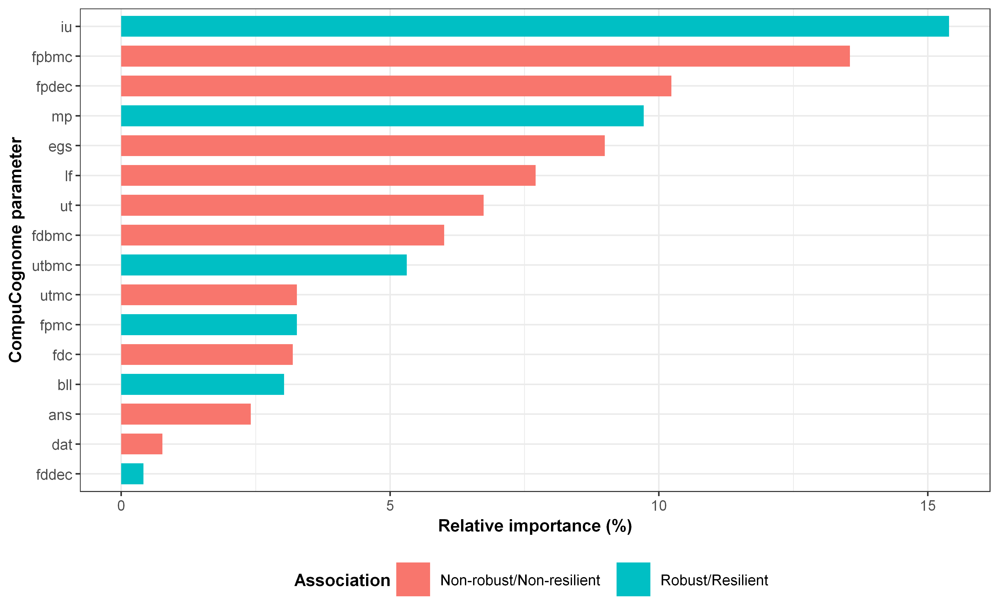

In [268]:
plot_classifier_importance(
  classifier_parameter_coefs,
  family_name = "pvt_mrrt",
  group_type_name = "Robustness",
  predictor_set_name = "stress_delta"
)

In [269]:
plot_classifier_profile <- function(
    dat,
    family_name,
    group_type_name,
    predictor_set_name,
    param_order = params
) {

  plot_dat <- dat %>%
    filter(
      outcome_family == family_name,
      group_type == group_type_name,
      predictor_set == predictor_set_name,
      parameter %in% param_order
    ) %>%
    mutate(
      parameter = factor(
        parameter,
        levels = rev(param_order)
      )
    )

  ggplot(
    plot_dat,
    aes(
      x = coef,
      y = parameter,
      fill = direction
    )
  ) +
    geom_col(width = 0.7) +
    geom_vline(
      xintercept = 0,
      linewidth = 0.4
    ) +
    labs(
      x = "Standardized elastic-net coefficient",
      y = "CompuCognome parameter",
      fill = "Association"
    ) +
    theme_bw(base_size = 8) +
    theme(
      axis.text = element_text(size = 7, face = "plain"),
      axis.title = element_text(size = 8, face = "bold"),
      legend.position = "bottom",
      legend.title = element_text(size = 8, face = "bold"),
      legend.text = element_text(size = 7, face = "plain")
    )
}

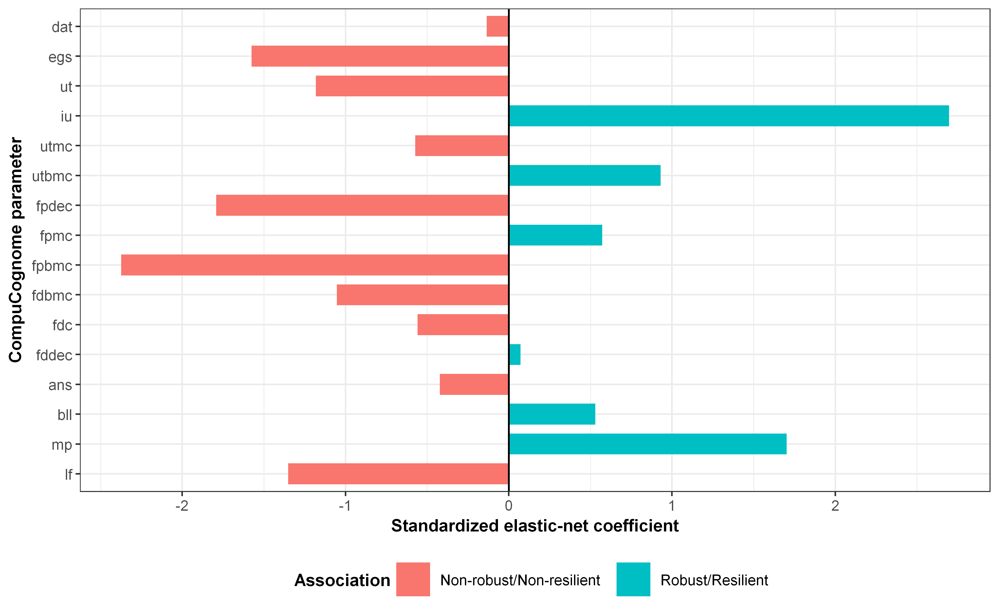

In [270]:
plot_classifier_profile(
  classifier_parameter_coefs,
  family_name = "pvt_mrrt",
  group_type_name = "Robustness",
  predictor_set_name = "stress_delta"
)

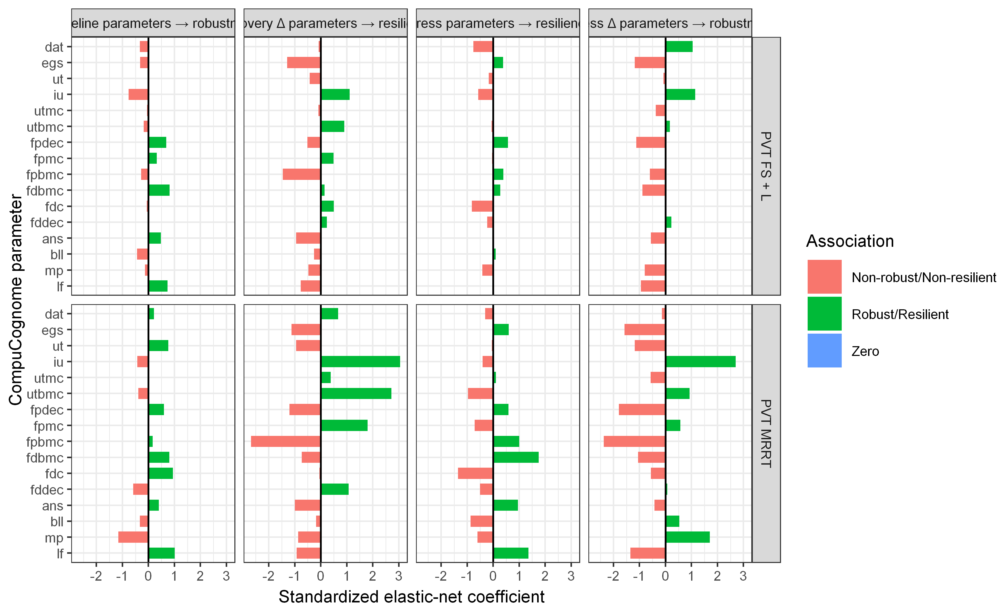

In [271]:
plot_dat <- classifier_parameter_coefs %>%
  filter(
    outcome_family %in% c("pvt_mrrt", "pvt_fsl")
  ) %>%
  mutate(
    parameter = factor(
      parameter,
      levels = rev(params)
    )
  )

ggplot(
  plot_dat,
  aes(
    x = coef,
    y = parameter,
    fill = direction
  )
) +
  geom_col(width = 0.7) +
  geom_vline(xintercept = 0, linewidth = 0.4) +
  facet_grid(
    outcome_label ~ analysis_label
  ) +
  labs(
    x = "Standardized elastic-net coefficient",
    y = "CompuCognome parameter",
    fill = "Association"
  ) +
  theme_bw(base_size = 8)

In [275]:
plot_extreme_profiles <- function(
    dat,
    outcome_col,
    predictor_set,
    group_type = c("Robustness", "Resilience"),
    param_names = params
) {

  group_type <- match.arg(group_type)

  # ---------------------------------------
  # Select parameter representation
  # ---------------------------------------

  predictor_cols <- switch(
    predictor_set,

    baseline =
      paste0(param_names, "_Baseline"),

    stress_delta =
      paste0(param_names, "_dBS"),

    stress =
      paste0(param_names, "_Stress"),

    recovery_delta =
      paste0(param_names, "_dSR"),

    stop("Unknown predictor_set: ", predictor_set)
  )

  # ---------------------------------------
  # Standardize BEFORE excluding middle
  # ---------------------------------------

  plot_dat <- dat %>%
    mutate(
      across(
        all_of(predictor_cols),
        ~ {
          x <- .x[is.finite(.x)]

          if (
            length(x) > 1 &&
            is.finite(sd(x)) &&
            sd(x) > 0
          ) {
            as.numeric(scale(.x))
          } else {
            NA_real_
          }
        },
        .names = "{.col}_z"
      )
    )

  z_cols <- paste0(predictor_cols, "_z")

  # ---------------------------------------
  # Remove middle participants AFTER scaling
  # ---------------------------------------

  plot_dat <- plot_dat %>%
    filter(
      !is.na(.data[[outcome_col]]),
      .data[[outcome_col]] %in% c(0, 1)
    ) %>%
    select(
      study,
      subjectid,
      all_of(outcome_col),
      all_of(z_cols)
    ) %>%
    pivot_longer(
      cols = all_of(z_cols),
      names_to = "feature",
      values_to = "z"
    ) %>%
    mutate(
      parameter = str_remove(
        feature,
        "_Baseline_z$|_Stress_z$|_dBS_z$|_dSR_z$"
      )
    )

  # ---------------------------------------
  # Group labels
  # ---------------------------------------

  if (group_type == "Robustness") {

    group_labels <- c(
      "Non-robust",
      "Robust"
    )

  } else {

    group_labels <- c(
      "Non-resilient",
      "Resilient"
    )
  }

  plot_dat <- plot_dat %>%
    mutate(
      group = factor(
        .data[[outcome_col]],
        levels = c(0, 1),
        labels = group_labels
      ),

      parameter = factor(
        parameter,
        levels = rev(param_names)
      )
    )

  # ---------------------------------------
  # Means + SE
  # ---------------------------------------

  summary_dat <- plot_dat %>%
    group_by(parameter, group) %>%
    summarise(
      n = sum(is.finite(z)),
      mean_z = mean(z, na.rm = TRUE),
      se_z = if_else(
        n > 1,
        sd(z, na.rm = TRUE) / sqrt(n),
        NA_real_
      ),
      .groups = "drop"
    ) %>%
    filter(is.finite(mean_z))

  # ---------------------------------------
  # Plot
  # ---------------------------------------

  ggplot(
    summary_dat,
    aes(
      x = mean_z,
      y = parameter,
      color = group
    )
  ) +
    geom_vline(
      xintercept = 0,
      linewidth = 0.4
    ) +
    geom_errorbarh(
      aes(
        xmin = mean_z - se_z,
        xmax = mean_z + se_z
      ),
      position = position_dodge(width = 0.45),
      height = 0.15,
      linewidth = 0.4
    ) +
    geom_point(
      position = position_dodge(width = 0.45),
      size = 2
    ) +
    labs(
      x = "Mean parameter value (z-scored)",
      y = "CompuCognome parameter",
      color = paste0(group_type, " Group")
    ) +
    scale_y_discrete(drop = FALSE) +
    theme_bw(base_size = 8) +
    theme(
      axis.text = element_text(
        size = 7,
        face = "plain"
      ),
      axis.title = element_text(
        size = 8,
        face = "bold"
      ),
      legend.position = "bottom",
      legend.title = element_text(
        size = 8,
        face = "bold"
      ),
      legend.text = element_text(
        size = 7,
        face = "plain"
      )
    )
}

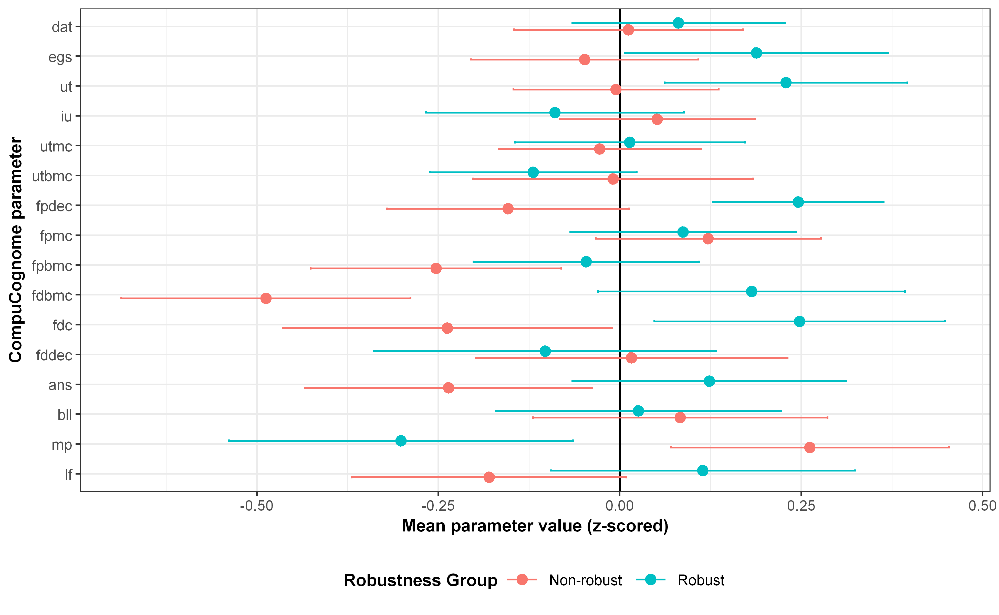

In [276]:
plot_extreme_profiles(
  dat = cc_class_base,
  outcome_col = "pvt_mrrt_robustness_extreme",
  predictor_set = "baseline",
  group_type = "Robustness"
)

# Predictive Analyses

In [192]:
library(glmnet)
library(forcats)

Loaded glmnet 5.0



In [249]:
#cc_pred_dat <- cc_outcome_dat_all
cc_pred_dat <- cc_extreme_dat_all
colnames(cc_pred_dat)
head(cc_pred_dat)

[1] "study"                       "subjectid"                  
 [3] "phase"                       "study_event_id"             
 [5] "bout"                        "kl_val"                     
 [7] "mle_val"                     "dat"                        
 [9] "egs"                         "ut"                         
[11] "iu"                          "utmc"                       
[13] "utbmc"                       "fpdec"                      
[15] "fpmc"                        "fpbmc"                      
[17] "fdbmc"                       "fdc"                        
[19] "fddec"                       "ans"                        
[21] "bll"                         "mp"                         
[23] "lf"                          "poms_delta_stress"          
[25] "poms_delta_recovery"         "poms_robustness_extreme"    
[27] "poms_resilience_extreme"     "dxa_delta_stress"           
[29] "dxa_delta_recovery"          "dxa_robustness_extreme"     
[31] "dxa_resilience_extreme"      "delta_stress_mrrt"          
[33] "delta_recovery_mrrt"         "delta_stress_fsl"           
[35] "delta_recovery_fsl"          "pvt_mrrt_robustness_extreme"
[37] "pvt_mrrt_resilience_extreme" "pvt_fsl_robustness_extreme" 
[39] "pvt_fsl_resilience_extreme"

study,subjectid,phase,study_event_id,bout,kl_val,mle_val,dat,egs,ut,⋯,dxa_robustness_extreme,dxa_resilience_extreme,delta_stress_mrrt,delta_recovery_mrrt,delta_stress_fsl,delta_recovery_fsl,pvt_mrrt_robustness_extreme,pvt_mrrt_resilience_extreme,pvt_fsl_robustness_extreme,pvt_fsl_resilience_extreme
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>,<int>
HIGH,ROP072,Baseline,B1,181,0.07221468,-16.443619,0.05,0.31,2.82,⋯,NA,NA,-0.007943908,NA,-3,NA,NA,NA,NA,NA
HIGH,ROP072,Stress,A3,1045,0.16473468,-18.316889,0.06,0.27,2.66,⋯,NA,NA,-0.007943908,NA,-3,NA,NA,NA,NA,NA
HIGH,ROP081,Baseline,B1,181,0.20620817,-9.778598,0.06,0.28,2.54,⋯,1,NA,0.169225389,NA,-15,NA,NA,NA,1,NA
HIGH,ROP081,Stress,A3,1045,0.55755174,-9.237957,0.06,0.22,2.51,⋯,1,NA,0.169225389,NA,-15,NA,NA,NA,1,NA
HIGH,ROP084,Baseline,B1,181,NA,-1.868362,0.05,0.39,2.65,⋯,1,NA,NA,NA,NA,NA,NA,NA,NA,NA
HIGH,ROP084,Stress,A3,1045,NA,-2.918144,0.05,0.11,2.47,⋯,1,NA,NA,NA,NA,NA,NA,NA,NA,NA


In [250]:
params <- c(
  "dat", "egs", "ut", "iu", 
  "utmc", "utbmc", "fpdec", "fpmc", "fpbmc",
  "fdbmc", "fdc", "fddec", 
  "ans", "bll", "mp", "lf"
)
outcome_specs <- tibble::tribble(
  ~outcome_family, ~outcome_label,          ~stress_delta_outcome, ~recovery_delta_outcome,
  "pvt_mrrt",      "PVT MRRT",              "delta_stress_mrrt",   "delta_recovery_mrrt",
  "pvt_fsl",       "PVT FS + L",            "delta_stress_fsl",    "delta_recovery_fsl",
  "poms",          "POMS TMD",              "poms_delta_stress",   "poms_delta_recovery",
  "dxa",           "DXA Lean/FF Mass",      "dxa_delta_stress",    "dxa_delta_recovery"
)

all_delta_outcomes <- unique(c(
  outcome_specs$stress_delta_outcome,
  outcome_specs$recovery_delta_outcome
))

In [251]:
mean_or_na <- function(x) {
  if (all(is.na(x))) NA_real_ else mean(x, na.rm = TRUE)
}

first_non_missing <- function(x) {
  x <- x[!is.na(x)]
  if (length(x) == 0) NA_real_ else x[1]
}

#all_delta_outcomes <- c(stress_outcomes, recovery_outcomes)

model_base <- cc_pred_dat %>%
  filter(phase %in% c("Baseline", "Stress", "Recovery")) %>%
  group_by(study, subjectid, phase) %>%
  summarise(
    across(all_of(params), mean_or_na),
    across(any_of(all_delta_outcomes), first_non_missing),
    .groups = "drop"
  ) %>%
  mutate(
    phase = factor(phase, levels = c("Baseline", "Stress", "Recovery"))
  ) %>%
  pivot_wider(
    id_cols = c(study, subjectid, any_of(all_delta_outcomes)),
    names_from = phase,
    values_from = all_of(params),
    names_glue = "{.value}_{phase}"
  )

## if we want to normalize the outcome measures so that higher values mean more robust/resilience then run this
#model_base <- model_base %>%
#  mutate(
#    # Higher = more robust from baseline to stress
#    dxa_stress_robust_score  =  dxa_delta_stress,
#    poms_stress_robust_score = -poms_delta_stress,
#    pvt_fsl_stress_robust_score = -delta_stress_fsl,
#    pvt_mrrt_stress_robust_score =  delta_stress_mrrt,
#
#    # Higher = more resilient from stress to recovery
#    dxa_recovery_resilience_score  =  dxa_delta_recovery,
#    poms_recovery_resilience_score = -poms_delta_recovery,
#    pvt_fsl_recovery_resilience_score = -delta_recovery_fsl,
#    pvt_mrrt_recovery_resilience_score =  delta_recovery_mrrt
#  )

head(model_base)

study,subjectid,delta_stress_mrrt,delta_stress_fsl,poms_delta_stress,dxa_delta_stress,delta_recovery_mrrt,delta_recovery_fsl,poms_delta_recovery,dxa_delta_recovery,⋯,ans_Recovery,bll_Baseline,bll_Stress,bll_Recovery,mp_Baseline,mp_Stress,mp_Recovery,lf_Baseline,lf_Stress,lf_Recovery
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HIGH,ROP072,-0.007943908,-3,15,-2799,NA,NA,NA,NA,⋯,NA,0.43,0.40,NA,1.11,1.06,NA,1.05,1.01,NA
HIGH,ROP073,0.149765761,-9,-6,-8884,NA,NA,NA,NA,⋯,NA,0.45,0.46,NA,0.91,0.83,NA,0.92,0.83,NA
HIGH,ROP074,-0.084559297,2,47,-5836,NA,NA,NA,NA,⋯,NA,0.43,0.47,NA,0.95,0.95,NA,1.06,0.87,NA
HIGH,ROP075,-0.242676983,18,3,-2873,NA,NA,NA,NA,⋯,NA,0.46,0.45,NA,1.05,0.85,NA,0.84,0.93,NA
HIGH,ROP076,-0.518777050,-3,13,-4294,NA,NA,NA,NA,⋯,NA,0.40,0.58,NA,1.09,1.09,NA,0.85,1.01,NA
HIGH,ROP077,0.115578349,-2,35,-4088,NA,NA,NA,NA,⋯,NA,0.49,0.41,NA,1.05,1.05,NA,0.97,0.83,NA


In [252]:
analysis_specs <- outcome_specs %>%
  tidyr::crossing(
    tibble::tribble(
      ~predictor_set,      ~analysis_label,                                      ~analysis_order, ~outcome_period,
      "baseline",          "Baseline parameters → Stress Δ outcome",             1,               "stress",
      "stress_delta",      "Stress Δ parameters → Stress Δ outcome",             2,               "stress",
      "stress",            "Stress parameters → Recovery Δ outcome",             3,               "recovery",
      "recovery_delta",    "Recovery Δ parameters → Recovery Δ outcome",         4,               "recovery"
    )
  ) %>%
  mutate(
    outcome_col = if_else(
      outcome_period == "stress",
      stress_delta_outcome,
      recovery_delta_outcome
    )
  ) %>%
  arrange(outcome_family, analysis_order)

In [253]:
analysis_specs

outcome_family,outcome_label,stress_delta_outcome,recovery_delta_outcome,predictor_set,analysis_label,analysis_order,outcome_period,outcome_col
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>
dxa,DXA Lean/FF Mass,dxa_delta_stress,dxa_delta_recovery,baseline,Baseline parameters → Stress Δ outcome,1,stress,dxa_delta_stress
dxa,DXA Lean/FF Mass,dxa_delta_stress,dxa_delta_recovery,stress_delta,Stress Δ parameters → Stress Δ outcome,2,stress,dxa_delta_stress
dxa,DXA Lean/FF Mass,dxa_delta_stress,dxa_delta_recovery,stress,Stress parameters → Recovery Δ outcome,3,recovery,dxa_delta_recovery
dxa,DXA Lean/FF Mass,dxa_delta_stress,dxa_delta_recovery,recovery_delta,Recovery Δ parameters → Recovery Δ outcome,4,recovery,dxa_delta_recovery
poms,POMS TMD,poms_delta_stress,poms_delta_recovery,baseline,Baseline parameters → Stress Δ outcome,1,stress,poms_delta_stress
poms,POMS TMD,poms_delta_stress,poms_delta_recovery,stress_delta,Stress Δ parameters → Stress Δ outcome,2,stress,poms_delta_stress
poms,POMS TMD,poms_delta_stress,poms_delta_recovery,stress,Stress parameters → Recovery Δ outcome,3,recovery,poms_delta_recovery
poms,POMS TMD,poms_delta_stress,poms_delta_recovery,recovery_delta,Recovery Δ parameters → Recovery Δ outcome,4,recovery,poms_delta_recovery
pvt_fsl,PVT FS + L,delta_stress_fsl,delta_recovery_fsl,baseline,Baseline parameters → Stress Δ outcome,1,stress,delta_stress_fsl


In [198]:
make_predictor_data <- function(dat, predictor_set) {
  
  feature_df <- purrr::map_dfc(params, function(p) {
    
    value <- switch(
      predictor_set,
      
      "baseline" = dat[[paste0(p, "_Baseline")]],
      
      "stress_delta" = dat[[paste0(p, "_Stress")]] -
        dat[[paste0(p, "_Baseline")]],
      
      "stress" = dat[[paste0(p, "_Stress")]],
      
      "recovery_delta" = dat[[paste0(p, "_Recovery")]] -
        dat[[paste0(p, "_Stress")]]
    )
    
    tibble(!!p := value)
  })
  
  bind_cols(
    dat %>% select(study, subjectid, any_of(all_delta_outcomes)),
    feature_df
  )
}

In [199]:
fit_enet_one <- function(
    model_base,
    outcome_family,
    outcome_label,
    predictor_set,
    analysis_label,
    analysis_order,
    outcome_col,
    predictor_cols = params,
    alphas = c(0, 0.25, 0.50, 0.75, 1),
    lambda_choice = "lambda.min",
    min_n = 20,
    seed = 123
) {
  
  set.seed(seed)
  
  df <- make_predictor_data(model_base, predictor_set)
  
  model_dat <- df %>%
    select(study, subjectid, all_of(predictor_cols), all_of(outcome_col)) %>%
    rename(outcome = all_of(outcome_col)) %>%
    filter(!is.na(outcome), is.finite(outcome)) %>%
    mutate(
      study = factor(study),
      across(all_of(predictor_cols), as.numeric)
    ) #%>%
    #filter(if_all(all_of(predictor_cols), ~ !is.na(.x) & is.finite(.x)))
  
  if (nrow(model_dat) < min_n) {
    warning("Skipping ", outcome_family, " / ", analysis_label, ": too few rows.")
    return(NULL)
  }
  
  # Identify predictors with at least some valid data and nonzero variance
  pred_ok <- sapply(
    model_dat[predictor_cols],
    function(x) {
      x_valid <- x[!is.na(x) & is.finite(x)]
      length(x_valid) >= 2 && sd(x_valid, na.rm = TRUE) > 0
    }
  )

  predictor_cols_use <- predictor_cols[pred_ok]
  
  if (length(predictor_cols_use) < 2) {
    warning("Skipping ", outcome_family, " / ", analysis_label, ": too few usable predictors.")
    return(NULL)
  }
  
  if (sd(model_dat$outcome, na.rm = TRUE) == 0) {
    warning("Skipping ", outcome_family, " / ", analysis_label, ": outcome has zero variance.")
    return(NULL)
  }
  
  # Standardized parameter predictors    
  x_params <- scale(as.matrix(model_dat[, predictor_cols_use, drop = FALSE]))
  
  x_param_center <- attr(x_params, "scaled:center")
  x_param_scale  <- attr(x_params, "scaled:scale")
  # Replace missing standardized values with 0
  # This is mean imputation in z-score units
  x_params[!is.finite(x_params)] <- NA
  x_params[is.na(x_params)] <- 0

  colnames(x_params) <- predictor_cols_use
    
  # Standardized continuous outcome
  y <- as.numeric(scale(model_dat$outcome))
  y_center <- attr(scale(model_dat$outcome), "scaled:center")
  y_scale  <- attr(scale(model_dat$outcome), "scaled:scale")
  
  # Study fixed effects, unpenalized
  #study_levels <- levels(model_dat$study)
  study_levels <- levels(droplevels(model_dat$study))
  model_dat <- model_dat %>%
    mutate(study = factor(study, levels = study_levels))
  
  if (n_distinct(model_dat$study) > 1) {
    x_study <- model.matrix(~ study, data = model_dat)[, -1, drop = FALSE]
    x <- cbind(x_params, x_study)
    
    penalty_factor <- c(
      rep(1, ncol(x_params)),
      rep(0, ncol(x_study))
    )
  } else {
    x <- x_params
    penalty_factor <- rep(1, ncol(x_params))
  }
  
  x_colnames <- colnames(x)
  
  n <- nrow(x)
  nfolds <- min(10, max(3, floor(n / 5)))
  foldid <- sample(rep(seq_len(nfolds), length.out = n))
  
  fit_one_alpha <- function(a) {
    tryCatch(
      cv.glmnet(
        x = x,
        y = y,
        alpha = a,
        family = "gaussian",
        standardize = FALSE,
        penalty.factor = penalty_factor,
        foldid = foldid,
        keep = TRUE
      ),
      error = function(e) NULL
    )
  }
  
  fits <- purrr::map(alphas, fit_one_alpha)
  valid <- !purrr::map_lgl(fits, is.null)
  
  if (!any(valid)) {
    warning("No valid glmnet fits for ", outcome_family, " / ", analysis_label)
    return(NULL)
  }
  
  fits_valid <- fits[valid]
  alphas_valid <- alphas[valid]
  
  best_i <- which.min(purrr::map_dbl(fits_valid, ~ min(.x$cvm, na.rm = TRUE)))
  cvfit <- fits_valid[[best_i]]
  alpha_best <- alphas_valid[[best_i]]
  
  lambda_value <- if (lambda_choice == "lambda.min") {
    cvfit$lambda.min
  } else {
    cvfit$lambda.1se
  }
  
  lambda_index <- if (lambda_choice == "lambda.min") {
    cvfit$index["min", 1]
  } else {
    cvfit$index["1se", 1]
  }
  
  pred_cv <- cvfit$fit.preval[, lambda_index]
  
  cv_rmse <- sqrt(mean((y - pred_cv)^2, na.rm = TRUE))
  cv_r2 <- 1 - sum((y - pred_cv)^2, na.rm = TRUE) /
    sum((y - mean(y, na.rm = TRUE))^2, na.rm = TRUE)
  
  # ------------------------------------------------------------
  # All model coefficients: CompuCognome + study fixed effects
  # ------------------------------------------------------------
  coef_mat <- as.matrix(coef(cvfit, s = lambda_choice))
  
  coef_all_tbl <- tibble(
    feature = rownames(coef_mat),
    coef = as.numeric(coef_mat[, 1])
  ) %>%
    filter(feature != "(Intercept)") %>%
    mutate(
      term_type = case_when(
        feature %in% predictor_cols_use ~ "CompuCognome parameter",
        str_detect(feature, "^study") ~ "Study fixed effect",
        TRUE ~ "Other"
      ),
      usable = TRUE,
      selected = abs(coef) > 1e-8,
      abs_coef = abs(coef),
      outcome_family = outcome_family,
      outcome_label = outcome_label,
      outcome = outcome_col,
      predictor_set = predictor_set,
      analysis_label = analysis_label,
      analysis_order = analysis_order,
      alpha = alpha_best,
      lambda = lambda_value,
      n = n,
      cv_rmse_z = cv_rmse,
      cv_r2 = cv_r2
    )
  
  # ------------------------------------------------------------
  # CompuCognome-only coefficient table for existing heatmaps
  # Keeps unusable predictors as NA and unused-but-usable as 0
  # ------------------------------------------------------------
  coef_param_raw <- coef_all_tbl %>%
    filter(feature %in% predictor_cols_use) %>%
    select(feature, coef)
  
  coef_tbl <- tibble(feature = predictor_cols) %>%
    left_join(coef_param_raw, by = "feature") %>%
    mutate(
      term_type = "CompuCognome parameter",
      usable = feature %in% predictor_cols_use,
      coef = case_when(
        usable & is.na(coef) ~ 0,
        !usable ~ NA_real_,
        TRUE ~ coef
      ),
      selected = usable & !is.na(coef) & abs(coef) > 1e-8,
      abs_coef = abs(coef),
      outcome_family = outcome_family,
      outcome_label = outcome_label,
      outcome = outcome_col,
      predictor_set = predictor_set,
      analysis_label = analysis_label,
      analysis_order = analysis_order,
      alpha = alpha_best,
      lambda = lambda_value,
      n = n,
      cv_rmse_z = cv_rmse,
      cv_r2 = cv_r2
    )
  
  perf_tbl <- tibble(
    outcome_family = outcome_family,
    outcome_label = outcome_label,
    outcome = outcome_col,
    predictor_set = predictor_set,
    analysis_label = analysis_label,
    analysis_order = analysis_order,
    n = n,
    n_predictors = length(predictor_cols_use),
    alpha = alpha_best,
    lambda = lambda_value,
    cv_rmse_z = cv_rmse,
    cv_r2 = cv_r2
  )
  
  list(
    # Existing outputs
    coef = coef_tbl,
    coef_all = coef_all_tbl,
    performance = perf_tbl,
    
    # Fitted model
    fit = cvfit,
    
    # Information needed for adjusted study predictions
    model_dat = model_dat,
    x_colnames = x_colnames,
    predictor_cols = predictor_cols,
    predictor_cols_use = predictor_cols_use,
    x_param_center = x_param_center,
    x_param_scale = x_param_scale,
    study_levels = study_levels,
    outcome_col = outcome_col,
    y_center = y_center,
    y_scale = y_scale,
    
    # Metadata
    outcome_family = outcome_family,
    outcome_label = outcome_label,
    predictor_set = predictor_set,
    analysis_label = analysis_label,
    analysis_order = analysis_order,
    alpha = alpha_best,
    lambda = lambda_value,
    lambda_choice = lambda_choice,
    n = n,
    cv_rmse_z = cv_rmse,
    cv_r2 = cv_r2
  )
}

In [200]:
model_results <- pmap(
  analysis_specs,
  function(
      outcome_family,
      outcome_label,
      stress_delta_outcome,
      recovery_delta_outcome,
      predictor_set,
      analysis_label,
      analysis_order,
      outcome_period,
      outcome_col
  ) {
    fit_enet_one(
      model_base = model_base,
      outcome_family = outcome_family,
      outcome_label = outcome_label,
      predictor_set = predictor_set,
      analysis_label = analysis_label,
      analysis_order = analysis_order,
      outcome_col = outcome_col,
      predictor_cols = params,
      lambda_choice = "lambda.min"
    )
  }
)

model_results <- purrr::compact(model_results)

coef_results <- purrr::map_dfr(model_results, "coef")
coef_all_results <- purrr::map_dfr(model_results, "coef_all")
perf_results <- purrr::map_dfr(model_results, "performance")

In [201]:
coef_all_results %>%
  filter(outcome_family == "dxa") %>%
  arrange(analysis_order, desc(abs_coef)) %>%
  select(
    outcome_label,
    analysis_label,
    feature,
    term_type,
    coef,
    abs_coef
  ) %>%
  print(n = Inf)

# A tibble: 74 × 6
   outcome_label    analysis_label                             feature   
   <chr>            <chr>                                      <chr>     
 1 DXA Lean/FF Mass Baseline parameters → Stress Δ outcome     studyOPSI 
 2 DXA Lean/FF Mass Baseline parameters → Stress Δ outcome     studyOPSII
 3 DXA Lean/FF Mass Baseline parameters → Stress Δ outcome     studySERE 
 4 DXA Lean/FF Mass Baseline parameters → Stress Δ outcome     fddec     
 5 DXA Lean/FF Mass Baseline parameters → Stress Δ outcome     fpbmc     
 6 DXA Lean/FF Mass Baseline parameters → Stress Δ outcome     fdbmc     
 7 DXA Lean/FF Mass Baseline parameters → Stress Δ outcome     bll       
 8 DXA Lean/FF Mass Baseline parameters → Stress Δ outcome     utmc      
 9 DXA Lean/FF Mass Baseline parameters → Stress Δ outcome     egs       
10 DXA Lean/FF Mass Baseline parameters → Stress Δ outcome     dat       
11 DXA Lean/FF Mass Baseline parameters → Stress Δ outcome     utbmc     
12 DXA Lean/FF Mass

In [202]:
perf_results %>%
  arrange(outcome_family, analysis_order)

outcome_family,outcome_label,outcome,predictor_set,analysis_label,analysis_order,n,n_predictors,alpha,lambda,cv_rmse_z,cv_r2
<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
dxa,DXA Lean/FF Mass,dxa_delta_stress,baseline,Baseline parameters → Stress Δ outcome,1,159,16,0.00,56.195630428,0.7031843,0.50240227
dxa,DXA Lean/FF Mass,dxa_delta_stress,stress_delta,Stress Δ parameters → Stress Δ outcome,2,159,16,0.00,69.963211453,0.7032733,0.50227628
dxa,DXA Lean/FF Mass,dxa_delta_recovery,stress,Stress parameters → Recovery Δ outcome,3,142,16,0.00,98.844096912,0.8875831,0.20660893
dxa,DXA Lean/FF Mass,dxa_delta_recovery,recovery_delta,Recovery Δ parameters → Recovery Δ outcome,4,142,16,0.00,8.798251290,0.8866719,0.20823720
poms,POMS TMD,poms_delta_stress,baseline,Baseline parameters → Stress Δ outcome,1,161,16,0.00,20.521781519,0.9422016,0.10670784
poms,POMS TMD,poms_delta_stress,stress_delta,Stress Δ parameters → Stress Δ outcome,2,161,16,0.00,1.734138040,0.9328114,0.12442456
poms,POMS TMD,poms_delta_recovery,stress,Stress parameters → Recovery Δ outcome,3,142,16,1.00,0.072351717,0.9373674,0.11511082
poms,POMS TMD,poms_delta_recovery,recovery_delta,Recovery Δ parameters → Recovery Δ outcome,4,142,16,0.25,0.189351917,0.9353003,0.11900917
pvt_fsl,PVT FS + L,delta_stress_fsl,baseline,Baseline parameters → Stress Δ outcome,1,156,16,0.25,0.264917214,0.9624892,0.06763789


In [203]:
# Performance table for paper
elastic_net_performance_table <- perf_results %>%
  mutate(
    cv_r2 = round(cv_r2, 3),
    cv_rmse_z = round(cv_rmse_z, 3),
    alpha = round(alpha, 2),
    lambda = signif(lambda, 3)
  ) %>%
  arrange(outcome_family, analysis_order) %>%
  select(
    outcome_family,
    outcome_label,
    analysis_label,
    n,
    n_predictors,
    alpha,
    lambda,
    cv_r2,
    cv_rmse_z
  )

elastic_net_performance_table

outcome_family,outcome_label,analysis_label,n,n_predictors,alpha,lambda,cv_r2,cv_rmse_z
<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
dxa,DXA Lean/FF Mass,Baseline parameters → Stress Δ outcome,159,16,0.00,56.2000,0.502,0.703
dxa,DXA Lean/FF Mass,Stress Δ parameters → Stress Δ outcome,159,16,0.00,70.0000,0.502,0.703
dxa,DXA Lean/FF Mass,Stress parameters → Recovery Δ outcome,142,16,0.00,98.8000,0.207,0.888
dxa,DXA Lean/FF Mass,Recovery Δ parameters → Recovery Δ outcome,142,16,0.00,8.8000,0.208,0.887
poms,POMS TMD,Baseline parameters → Stress Δ outcome,161,16,0.00,20.5000,0.107,0.942
poms,POMS TMD,Stress Δ parameters → Stress Δ outcome,161,16,0.00,1.7300,0.124,0.933
poms,POMS TMD,Stress parameters → Recovery Δ outcome,142,16,1.00,0.0724,0.115,0.937
poms,POMS TMD,Recovery Δ parameters → Recovery Δ outcome,142,16,0.25,0.1890,0.119,0.935
pvt_fsl,PVT FS + L,Baseline parameters → Stress Δ outcome,156,16,0.25,0.2650,0.068,0.962


In [204]:
# Coef table for paper
elastic_net_selected_features_table <- coef_results %>%
  filter(selected) %>%
  mutate(
    coef = round(coef, 3),
    abs_coef = round(abs_coef, 3)
  ) %>%
  select(
    outcome_family,
    outcome_label,
    analysis_label,
    feature,
    coef,
    abs_coef,
    n,
    cv_r2
  ) %>%
  arrange(outcome_family, analysis_label, desc(abs_coef))

elastic_net_selected_features_table

outcome_family,outcome_label,analysis_label,feature,coef,abs_coef,n,cv_r2
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<int>,<dbl>
dxa,DXA Lean/FF Mass,Baseline parameters → Stress Δ outcome,dat,-0.001,0.001,159,0.5024023
dxa,DXA Lean/FF Mass,Baseline parameters → Stress Δ outcome,egs,-0.001,0.001,159,0.5024023
dxa,DXA Lean/FF Mass,Baseline parameters → Stress Δ outcome,utmc,-0.001,0.001,159,0.5024023
dxa,DXA Lean/FF Mass,Baseline parameters → Stress Δ outcome,utbmc,-0.001,0.001,159,0.5024023
dxa,DXA Lean/FF Mass,Baseline parameters → Stress Δ outcome,fpbmc,0.001,0.001,159,0.5024023
dxa,DXA Lean/FF Mass,Baseline parameters → Stress Δ outcome,fdbmc,0.001,0.001,159,0.5024023
dxa,DXA Lean/FF Mass,Baseline parameters → Stress Δ outcome,fddec,0.001,0.001,159,0.5024023
dxa,DXA Lean/FF Mass,Baseline parameters → Stress Δ outcome,bll,0.001,0.001,159,0.5024023
dxa,DXA Lean/FF Mass,Baseline parameters → Stress Δ outcome,ut,0.000,0.000,159,0.5024023


In [205]:
coef_lim <- max(abs(coef_results$coef), na.rm = TRUE)
if (!is.finite(coef_lim) || coef_lim == 0) coef_lim <- 1

analysis_levels <- analysis_specs %>%
  distinct(analysis_label, analysis_order) %>%
  arrange(analysis_order) %>%
  pull(analysis_label)

make_coef_heatmap <- function(family_name) {
  
  plot_df <- coef_results %>%
    filter(outcome_family == family_name) %>%
    mutate(
      feature = factor(feature, levels = params),
      analysis_label = factor(analysis_label, levels = analysis_levels)
    )
  
  ggplot(
    plot_df,
    aes(x = feature, y = fct_rev(analysis_label), fill = coef)
  ) +
    geom_tile(color = "white") +
    geom_text(
      aes(label = ifelse(is.na(coef), "", sprintf("%.2f", coef))),
      size = 2
    ) +
    scale_fill_gradient2(
      low = "blue",
      mid = "white",
      high = "red",
      midpoint = 0,
      limits = c(-coef_lim, coef_lim),
      na.value = "grey90",
      name = "Std.\ncoef."
    ) +
    labs(
      title = paste0(
        unique(plot_df$outcome_label),
        ": Elastic Net Coefficients"
      ),
      x = "Compu-cognome Parameter",
      y = NULL
    ) +
    theme_bw(base_size = 8) +
    #theme(
    #  plot.title = element_text(hjust = 0.5, face = "bold"),
    #  axis.text.x = element_text(angle = 45, hjust = 1),
    #  axis.text.y = element_text(size = 7),
    #  panel.grid = element_blank(),
    #  legend.position = "right"
    #)
    theme(text = element_text(size=8, face="bold"),
          plot.title = element_text(size=8, hjust = 0.5),
          axis.text.x = element_text(size=7, face="plain", angle = 45, hjust = 1),
          axis.title.x = element_text(size=8),
          axis.text.y = element_text(size=7, face="plain"),
          axis.title.y = element_text(size=8),
          legend.position = "right",
          panel.grid = element_blank(),
          legend.title = element_text(size=8, face="bold"), #, margin = margin(0, 0, 0, 0)),
          legend.text = element_text(size=7, face="plain"),
          #legend.margin = margin(t = -2),
          legend.key.size = unit(0.8, "lines"),
          legend.margin = margin(-5, 0, 0, 0),
          legend.box.margin = margin(0, 0, 0, 0),
          plot.margin = margin(2, 2, 2, 2)
    )  
}

coef_heatmaps <- setNames(
  purrr::map(unique(coef_results$outcome_family), make_coef_heatmap),
  unique(coef_results$outcome_family)
)

In [206]:
colnames(model_base)

[1] "study"               "subjectid"           "delta_stress_mrrt"  
 [4] "delta_stress_fsl"    "poms_delta_stress"   "dxa_delta_stress"   
 [7] "delta_recovery_mrrt" "delta_recovery_fsl"  "poms_delta_recovery"
[10] "dxa_delta_recovery"  "dat_Baseline"        "dat_Stress"         
[13] "dat_Recovery"        "egs_Baseline"        "egs_Stress"         
[16] "egs_Recovery"        "ut_Baseline"         "ut_Stress"          
[19] "ut_Recovery"         "iu_Baseline"         "iu_Stress"          
[22] "iu_Recovery"         "utmc_Baseline"       "utmc_Stress"        
[25] "utmc_Recovery"       "utbmc_Baseline"      "utbmc_Stress"       
[28] "utbmc_Recovery"      "fpdec_Baseline"      "fpdec_Stress"       
[31] "fpdec_Recovery"      "fpmc_Baseline"       "fpmc_Stress"        
[34] "fpmc_Recovery"       "fpbmc_Baseline"      "fpbmc_Stress"       
[37] "fpbmc_Recovery"      "fdbmc_Baseline"      "fdbmc_Stress"       
[40] "fdbmc_Recovery"      "fdc_Baseline"        "fdc_Stress"         
[43] "fdc_Recovery"        "fddec_Baseline"      "fddec_Stress"       
[46] "fddec_Recovery"      "ans_Baseline"        "ans_Stress"         
[49] "ans_Recovery"        "bll_Baseline"        "bll_Stress"         
[52] "bll_Recovery"        "mp_Baseline"         "mp_Stress"          
[55] "mp_Recovery"         "lf_Baseline"         "lf_Stress"          
[58] "lf_Recovery"

In [207]:
model_base_lm <- model_base

for (p in params) {
  
  model_base_lm[[paste0(p, "_dBS")]] <-
    model_base_lm[[paste0(p, "_Stress")]] -
    model_base_lm[[paste0(p, "_Baseline")]]
  
  model_base_lm[[paste0(p, "_dSR")]] <-
    model_base_lm[[paste0(p, "_Recovery")]] -
    model_base_lm[[paste0(p, "_Stress")]]
}
colnames(model_base_lm)

[1] "study"               "subjectid"           "delta_stress_mrrt"  
 [4] "delta_stress_fsl"    "poms_delta_stress"   "dxa_delta_stress"   
 [7] "delta_recovery_mrrt" "delta_recovery_fsl"  "poms_delta_recovery"
[10] "dxa_delta_recovery"  "dat_Baseline"        "dat_Stress"         
[13] "dat_Recovery"        "egs_Baseline"        "egs_Stress"         
[16] "egs_Recovery"        "ut_Baseline"         "ut_Stress"          
[19] "ut_Recovery"         "iu_Baseline"         "iu_Stress"          
[22] "iu_Recovery"         "utmc_Baseline"       "utmc_Stress"        
[25] "utmc_Recovery"       "utbmc_Baseline"      "utbmc_Stress"       
[28] "utbmc_Recovery"      "fpdec_Baseline"      "fpdec_Stress"       
[31] "fpdec_Recovery"      "fpmc_Baseline"       "fpmc_Stress"        
[34] "fpmc_Recovery"       "fpbmc_Baseline"      "fpbmc_Stress"       
[37] "fpbmc_Recovery"      "fdbmc_Baseline"      "fdbmc_Stress"       
[40] "fdbmc_Recovery"      "fdc_Baseline"        "fdc_Stress"         
[43] "fdc_Recovery"        "fddec_Baseline"      "fddec_Stress"       
[46] "fddec_Recovery"      "ans_Baseline"        "ans_Stress"         
[49] "ans_Recovery"        "bll_Baseline"        "bll_Stress"         
[52] "bll_Recovery"        "mp_Baseline"         "mp_Stress"          
[55] "mp_Recovery"         "lf_Baseline"         "lf_Stress"          
[58] "lf_Recovery"         "dat_dBS"             "dat_dSR"            
[61] "egs_dBS"             "egs_dSR"             "ut_dBS"             
[64] "ut_dSR"              "iu_dBS"              "iu_dSR"             
[67] "utmc_dBS"            "utmc_dSR"            "utbmc_dBS"          
[70] "utbmc_dSR"           "fpdec_dBS"           "fpdec_dSR"          
[73] "fpmc_dBS"            "fpmc_dSR"            "fpbmc_dBS"          
[76] "fpbmc_dSR"           "fdbmc_dBS"           "fdbmc_dSR"          
[79] "fdc_dBS"             "fdc_dSR"             "fddec_dBS"          
[82] "fddec_dSR"           "ans_dBS"             "ans_dSR"            
[85] "bll_dBS"             "bll_dSR"             "mp_dBS"             
[88] "mp_dSR"              "lf_dBS"              "lf_dSR"

In [208]:
unique(model_base_lm$study)
head(model_base_lm)

[1] "HIGH"  "OPSI"  "OPSII" "SERE"

study,subjectid,delta_stress_mrrt,delta_stress_fsl,poms_delta_stress,dxa_delta_stress,delta_recovery_mrrt,delta_recovery_fsl,poms_delta_recovery,dxa_delta_recovery,⋯,fddec_dBS,fddec_dSR,ans_dBS,ans_dSR,bll_dBS,bll_dSR,mp_dBS,mp_dSR,lf_dBS,lf_dSR
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HIGH,1,-0.007943908,-3,15,-2799,NA,NA,NA,NA,⋯,-0.03,NA,0.05,NA,-0.03,NA,-0.05,NA,-0.04,NA
HIGH,10,0.169225389,-15,-28,-1954,NA,NA,NA,NA,⋯,0.00,NA,0.08,NA,-0.06,NA,0.12,NA,0.00,NA
HIGH,13,NA,NA,-8,-2143,NA,NA,NA,NA,⋯,0.00,NA,-0.08,NA,0.18,NA,0.02,NA,0.27,NA
HIGH,14,-0.509450288,6,21,-5909,NA,NA,NA,NA,⋯,0.00,NA,0.00,NA,-0.08,NA,-0.09,NA,-0.05,NA
HIGH,16,-0.191716085,3,10,-2134,NA,NA,NA,NA,⋯,0.00,NA,-0.11,NA,0.01,NA,-0.04,NA,0.35,NA
HIGH,18,0.197489892,-4,20,-4023,NA,NA,NA,NA,⋯,-0.01,NA,0.06,NA,0.05,NA,-0.11,NA,-0.07,NA


In [209]:
summary(lm(scale(delta_stress_mrrt) ~ scale(dat_Baseline) + scale(egs_Baseline) + scale(ut_Baseline) + scale(iu_Baseline) + scale(utmc_Baseline) + scale(utbmc_Baseline) + scale(fpdec_Baseline) + scale(fpmc_Baseline) + scale(fpbmc_Baseline) + scale(fdbmc_Baseline) + scale(fdc_Baseline) + scale(fddec_Baseline) + scale(ans_Baseline) + scale(bll_Baseline) + scale(mp_Baseline) + scale(lf_Baseline) + study, data = model_base_lm))
summary(lm(scale(delta_stress_mrrt) ~ scale(dat_dBS) + scale(egs_dBS) + scale(ut_dBS) + scale(iu_dBS) + scale(utmc_dBS) + scale(utbmc_dBS) + scale(fpdec_dBS) + scale(fpmc_dBS) + scale(fpbmc_dBS) + scale(fdbmc_dBS) + scale(fdc_dBS) + scale(fddec_dBS) + scale(ans_dBS) + scale(bll_dBS) + scale(mp_dBS) + scale(lf_dBS) + study, data = model_base_lm))
summary(lm(scale(delta_recovery_mrrt) ~ scale(dat_Stress) + scale(egs_Stress) + scale(ut_Stress) + scale(iu_Stress) + scale(utmc_Stress) + scale(utbmc_Stress) + scale(fpdec_Stress) + scale(fpmc_Stress) + scale(fpbmc_Stress) + scale(fdbmc_Stress) + scale(fdc_Stress) + scale(fddec_Stress) + scale(ans_Stress) + scale(bll_Stress) + scale(mp_Stress) + scale(lf_Stress) + study, data = model_base_lm))
summary(lm(scale(delta_recovery_mrrt) ~ scale(dat_dSR) + scale(egs_dSR) + scale(ut_dSR) + scale(iu_dSR) + scale(utmc_dSR) + scale(utbmc_dSR) + scale(fpdec_dSR) + scale(fpmc_dSR) + scale(fpbmc_dSR) + scale(fdbmc_dSR) + scale(fdc_dSR) + scale(fddec_dSR) + scale(ans_dSR) + scale(bll_dSR) + scale(mp_dSR) + scale(lf_dSR) + study, data = model_base_lm))



Call:
lm(formula = scale(delta_stress_mrrt) ~ scale(dat_Baseline) + 
    scale(egs_Baseline) + scale(ut_Baseline) + scale(iu_Baseline) + 
    scale(utmc_Baseline) + scale(utbmc_Baseline) + scale(fpdec_Baseline) + 
    scale(fpmc_Baseline) + scale(fpbmc_Baseline) + scale(fdbmc_Baseline) + 
    scale(fdc_Baseline) + scale(fddec_Baseline) + scale(ans_Baseline) + 
    scale(bll_Baseline) + scale(mp_Baseline) + scale(lf_Baseline) + 
    study, data = model_base_lm)

Residuals:
     Min       1Q   Median       3Q      Max 
-2.11316 -0.56283  0.02712  0.53957  2.02711 

Coefficients:
                       Estimate Std. Error t value Pr(>|t|)   
(Intercept)            0.252218   0.299607   0.842  0.40259   
scale(dat_Baseline)    0.099733   0.103384   0.965  0.33784   
scale(egs_Baseline)    0.125605   0.138121   0.909  0.36610   
scale(ut_Baseline)     0.060551   0.182694   0.331  0.74125   
scale(iu_Baseline)    -0.184868   0.154045  -1.200  0.23393   
scale(utmc_Baseline)   0.027572   0.1


Call:
lm(formula = scale(delta_stress_mrrt) ~ scale(dat_dBS) + scale(egs_dBS) + 
    scale(ut_dBS) + scale(iu_dBS) + scale(utmc_dBS) + scale(utbmc_dBS) + 
    scale(fpdec_dBS) + scale(fpmc_dBS) + scale(fpbmc_dBS) + scale(fdbmc_dBS) + 
    scale(fdc_dBS) + scale(fddec_dBS) + scale(ans_dBS) + scale(bll_dBS) + 
    scale(mp_dBS) + scale(lf_dBS) + study, data = model_base_lm)

Residuals:
     Min       1Q   Median       3Q      Max 
-1.56288 -0.34114  0.01432  0.28408  1.57846 

Coefficients:
                  Estimate Std. Error t value Pr(>|t|)    
(Intercept)       0.158092   0.185414   0.853 0.396610    
scale(dat_dBS)   -0.206180   0.068696  -3.001 0.003663 ** 
scale(egs_dBS)   -0.048122   0.103094  -0.467 0.642034    
scale(ut_dBS)    -0.702785   0.139809  -5.027 3.37e-06 ***
scale(iu_dBS)     0.811398   0.113881   7.125 5.75e-10 ***
scale(utmc_dBS)  -0.308583   0.086101  -3.584 0.000603 ***
scale(utbmc_dBS)  0.609194   0.106121   5.741 1.95e-07 ***
scale(fpdec_dBS) -0.060931   0.08


Call:
lm(formula = scale(delta_recovery_mrrt) ~ scale(dat_Stress) + 
    scale(egs_Stress) + scale(ut_Stress) + scale(iu_Stress) + 
    scale(utmc_Stress) + scale(utbmc_Stress) + scale(fpdec_Stress) + 
    scale(fpmc_Stress) + scale(fpbmc_Stress) + scale(fdbmc_Stress) + 
    scale(fdc_Stress) + scale(fddec_Stress) + scale(ans_Stress) + 
    scale(bll_Stress) + scale(mp_Stress) + scale(lf_Stress) + 
    study, data = model_base_lm)

Residuals:
    Min      1Q  Median      3Q     Max 
-2.3700 -0.5848 -0.1650  0.6126  1.6717 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)   
(Intercept)         -0.48444    0.18038  -2.686  0.00935 **
scale(dat_Stress)   -0.14307    0.11099  -1.289  0.20235   
scale(egs_Stress)   -0.02510    0.22683  -0.111  0.91225   
scale(ut_Stress)     0.15985    0.21141   0.756  0.45253   
scale(iu_Stress)    -0.24117    0.15300  -1.576  0.12023   
scale(utmc_Stress)  -0.01924    0.14623  -0.132  0.89574   
scale(utbmc_Stress) -0.16280    0.1


Call:
lm(formula = scale(delta_recovery_mrrt) ~ scale(dat_dSR) + scale(egs_dSR) + 
    scale(ut_dSR) + scale(iu_dSR) + scale(utmc_dSR) + scale(utbmc_dSR) + 
    scale(fpdec_dSR) + scale(fpmc_dSR) + scale(fpbmc_dSR) + scale(fdbmc_dSR) + 
    scale(fdc_dSR) + scale(fddec_dSR) + scale(ans_dSR) + scale(bll_dSR) + 
    scale(mp_dSR) + scale(lf_dSR) + study, data = model_base_lm)

Residuals:
     Min       1Q   Median       3Q      Max 
-1.08759 -0.42070 -0.03793  0.35798  1.80123 

Coefficients:
                  Estimate Std. Error t value Pr(>|t|)    
(Intercept)      -0.209820   0.119230  -1.760   0.0835 .  
scale(dat_dSR)    0.042108   0.076503   0.550   0.5841    
scale(egs_dSR)   -0.140435   0.112239  -1.251   0.2157    
scale(ut_dSR)    -0.686795   0.146024  -4.703 1.55e-05 ***
scale(iu_dSR)     0.910126   0.113590   8.012 4.67e-11 ***
scale(utmc_dSR)  -0.186617   0.093226  -2.002   0.0498 *  
scale(utbmc_dSR)  0.806954   0.130438   6.186 5.98e-08 ***
scale(fpdec_dSR)  0.143896   0.

In [210]:
summary(lm(scale(delta_stress_fsl) ~ scale(dat_Baseline) + scale(egs_Baseline) + scale(ut_Baseline) + scale(iu_Baseline) + scale(utmc_Baseline) + scale(utbmc_Baseline) + scale(fpdec_Baseline) + scale(fpmc_Baseline) + scale(fpbmc_Baseline) + scale(fdbmc_Baseline) + scale(fdc_Baseline) + scale(fddec_Baseline) + scale(ans_Baseline) + scale(bll_Baseline) + scale(mp_Baseline) + scale(lf_Baseline) + study, data = model_base_lm))
summary(lm(scale(delta_stress_fsl) ~ scale(dat_dBS) + scale(egs_dBS) + scale(ut_dBS) + scale(iu_dBS) + scale(utmc_dBS) + scale(utbmc_dBS) + scale(fpdec_dBS) + scale(fpmc_dBS) + scale(fpbmc_dBS) + scale(fdbmc_dBS) + scale(fdc_dBS) + scale(fddec_dBS) + scale(ans_dBS) + scale(bll_dBS) + scale(mp_dBS) + scale(lf_dBS) + study, data = model_base_lm))
summary(lm(scale(delta_recovery_fsl) ~ scale(dat_Stress) + scale(egs_Stress) + scale(ut_Stress) + scale(iu_Stress) + scale(utmc_Stress) + scale(utbmc_Stress) + scale(fpdec_Stress) + scale(fpmc_Stress) + scale(fpbmc_Stress) + scale(fdbmc_Stress) + scale(fdc_Stress) + scale(fddec_Stress) + scale(ans_Stress) + scale(bll_Stress) + scale(mp_Stress) + scale(lf_Stress) + study, data = model_base_lm))
summary(lm(scale(delta_recovery_fsl) ~ scale(dat_dSR) + scale(egs_dSR) + scale(ut_dSR) + scale(iu_dSR) + scale(utmc_dSR) + scale(utbmc_dSR) + scale(fpdec_dSR) + scale(fpmc_dSR) + scale(fpbmc_dSR) + scale(fdbmc_dSR) + scale(fdc_dSR) + scale(fddec_dSR) + scale(ans_dSR) + scale(bll_dSR) + scale(mp_dSR) + scale(lf_dSR) + study, data = model_base_lm))



Call:
lm(formula = scale(delta_stress_fsl) ~ scale(dat_Baseline) + 
    scale(egs_Baseline) + scale(ut_Baseline) + scale(iu_Baseline) + 
    scale(utmc_Baseline) + scale(utbmc_Baseline) + scale(fpdec_Baseline) + 
    scale(fpmc_Baseline) + scale(fpbmc_Baseline) + scale(fdbmc_Baseline) + 
    scale(fdc_Baseline) + scale(fddec_Baseline) + scale(ans_Baseline) + 
    scale(bll_Baseline) + scale(mp_Baseline) + scale(lf_Baseline) + 
    study, data = model_base_lm)

Residuals:
    Min      1Q  Median      3Q     Max 
-2.9383 -0.6464 -0.0176  0.6321  3.3189 

Coefficients:
                      Estimate Std. Error t value Pr(>|t|)  
(Intercept)           -0.22961    0.31599  -0.727   0.4697  
scale(dat_Baseline)    0.07625    0.10904   0.699   0.4866  
scale(egs_Baseline)   -0.13966    0.14567  -0.959   0.3408  
scale(ut_Baseline)     0.08828    0.19268   0.458   0.6482  
scale(iu_Baseline)     0.20032    0.16247   1.233   0.2215  
scale(utmc_Baseline)   0.10592    0.14046   0.754   0.4532  


Call:
lm(formula = scale(delta_stress_fsl) ~ scale(dat_dBS) + scale(egs_dBS) + 
    scale(ut_dBS) + scale(iu_dBS) + scale(utmc_dBS) + scale(utbmc_dBS) + 
    scale(fpdec_dBS) + scale(fpmc_dBS) + scale(fpbmc_dBS) + scale(fdbmc_dBS) + 
    scale(fdc_dBS) + scale(fddec_dBS) + scale(ans_dBS) + scale(bll_dBS) + 
    scale(mp_dBS) + scale(lf_dBS) + study, data = model_base_lm)

Residuals:
    Min      1Q  Median      3Q     Max 
-3.9434 -0.4307  0.0705  0.4246  2.9926 

Coefficients:
                 Estimate Std. Error t value Pr(>|t|)  
(Intercept)      -0.26834    0.27017  -0.993   0.3238  
scale(dat_dBS)   -0.05688    0.10010  -0.568   0.5716  
scale(egs_dBS)    0.13492    0.15022   0.898   0.3720  
scale(ut_dBS)     0.26222    0.20371   1.287   0.2020  
scale(iu_dBS)    -0.41198    0.16594  -2.483   0.0153 *
scale(utmc_dBS)   0.08441    0.12546   0.673   0.5032  
scale(utbmc_dBS) -0.32838    0.15463  -2.124   0.0370 *
scale(fpdec_dBS)  0.11365    0.12322   0.922   0.3594  
scale(fpmc_d


Call:
lm(formula = scale(delta_recovery_fsl) ~ scale(dat_Stress) + 
    scale(egs_Stress) + scale(ut_Stress) + scale(iu_Stress) + 
    scale(utmc_Stress) + scale(utbmc_Stress) + scale(fpdec_Stress) + 
    scale(fpmc_Stress) + scale(fpbmc_Stress) + scale(fdbmc_Stress) + 
    scale(fdc_Stress) + scale(fddec_Stress) + scale(ans_Stress) + 
    scale(bll_Stress) + scale(mp_Stress) + scale(lf_Stress) + 
    study, data = model_base_lm)

Residuals:
    Min      1Q  Median      3Q     Max 
-2.1273 -0.5626 -0.0399  0.4566  3.3176 

Coefficients:
                     Estimate Std. Error t value Pr(>|t|)  
(Intercept)          0.501965   0.196762   2.551   0.0133 *
scale(dat_Stress)    0.167546   0.121075   1.384   0.1715  
scale(egs_Stress)   -0.232824   0.247439  -0.941   0.3505  
scale(ut_Stress)    -0.134285   0.230615  -0.582   0.5626  
scale(iu_Stress)     0.246389   0.166903   1.476   0.1451  
scale(utmc_Stress)   0.014168   0.159510   0.089   0.9295  
scale(utbmc_Stress)  0.066714   0.17


Call:
lm(formula = scale(delta_recovery_fsl) ~ scale(dat_dSR) + scale(egs_dSR) + 
    scale(ut_dSR) + scale(iu_dSR) + scale(utmc_dSR) + scale(utbmc_dSR) + 
    scale(fpdec_dSR) + scale(fpmc_dSR) + scale(fpbmc_dSR) + scale(fdbmc_dSR) + 
    scale(fdc_dSR) + scale(fddec_dSR) + scale(ans_dSR) + scale(bll_dSR) + 
    scale(mp_dSR) + scale(lf_dSR) + study, data = model_base_lm)

Residuals:
     Min       1Q   Median       3Q      Max 
-1.76699 -0.45071 -0.00612  0.49370  1.70465 

Coefficients:
                 Estimate Std. Error t value Pr(>|t|)    
(Intercept)       0.31821    0.14787   2.152 0.035435 *  
scale(dat_dSR)   -0.05771    0.09488  -0.608 0.545325    
scale(egs_dSR)    0.53507    0.13920   3.844 0.000295 ***
scale(ut_dSR)     0.33474    0.18110   1.848 0.069481 .  
scale(iu_dSR)    -0.75164    0.14088  -5.335 1.53e-06 ***
scale(utmc_dSR)   0.11491    0.11562   0.994 0.324285    
scale(utbmc_dSR) -0.55226    0.16177  -3.414 0.001153 ** 
scale(fpdec_dSR) -0.10028    0.11503  -0

In [211]:
summary(lm(scale(poms_delta_stress) ~ scale(dat_Baseline) + scale(egs_Baseline) + scale(ut_Baseline) + scale(iu_Baseline) + scale(utmc_Baseline) + scale(utbmc_Baseline) + scale(fpdec_Baseline) + scale(fpmc_Baseline) + scale(fpbmc_Baseline) + scale(fdbmc_Baseline) + scale(fdc_Baseline) + scale(fddec_Baseline) + scale(ans_Baseline) + scale(bll_Baseline) + scale(mp_Baseline) + scale(lf_Baseline) + study, data = model_base_lm))
summary(lm(scale(poms_delta_stress) ~ scale(dat_dBS) + scale(egs_dBS) + scale(ut_dBS) + scale(iu_dBS) + scale(utmc_dBS) + scale(utbmc_dBS) + scale(fpdec_dBS) + scale(fpmc_dBS) + scale(fpbmc_dBS) + scale(fdbmc_dBS) + scale(fdc_dBS) + scale(fddec_dBS) + scale(ans_dBS) + scale(bll_dBS) + scale(mp_dBS) + scale(lf_dBS) + study, data = model_base_lm))
summary(lm(scale(poms_delta_recovery) ~ scale(dat_Stress) + scale(egs_Stress) + scale(ut_Stress) + scale(iu_Stress) + scale(utmc_Stress) + scale(utbmc_Stress) + scale(fpdec_Stress) + scale(fpmc_Stress) + scale(fpbmc_Stress) + scale(fdbmc_Stress) + scale(fdc_Stress) + scale(fddec_Stress) + scale(ans_Stress) + scale(bll_Stress) + scale(mp_Stress) + scale(lf_Stress) + study, data = model_base_lm))
summary(lm(scale(poms_delta_recovery) ~ scale(dat_dSR) + scale(egs_dSR) + scale(ut_dSR) + scale(iu_dSR) + scale(utmc_dSR) + scale(utbmc_dSR) + scale(fpdec_dSR) + scale(fpmc_dSR) + scale(fpbmc_dSR) + scale(fdbmc_dSR) + scale(fdc_dSR) + scale(fddec_dSR) + scale(ans_dSR) + scale(bll_dSR) + scale(mp_dSR) + scale(lf_dSR) + study, data = model_base_lm))



Call:
lm(formula = scale(poms_delta_stress) ~ scale(dat_Baseline) + 
    scale(egs_Baseline) + scale(ut_Baseline) + scale(iu_Baseline) + 
    scale(utmc_Baseline) + scale(utbmc_Baseline) + scale(fpdec_Baseline) + 
    scale(fpmc_Baseline) + scale(fpbmc_Baseline) + scale(fdbmc_Baseline) + 
    scale(fdc_Baseline) + scale(fddec_Baseline) + scale(ans_Baseline) + 
    scale(bll_Baseline) + scale(mp_Baseline) + scale(lf_Baseline) + 
    study, data = model_base_lm)

Residuals:
    Min      1Q  Median      3Q     Max 
-2.2328 -0.5850 -0.0502  0.5538  3.8976 

Coefficients:
                       Estimate Std. Error t value Pr(>|t|)  
(Intercept)           -0.144129   0.299801  -0.481   0.6320  
scale(dat_Baseline)    0.131390   0.104183   1.261   0.2110  
scale(egs_Baseline)   -0.291771   0.139305  -2.094   0.0394 *
scale(ut_Baseline)     0.317994   0.178614   1.780   0.0789 .
scale(iu_Baseline)    -0.175024   0.152356  -1.149   0.2541  
scale(utmc_Baseline)  -0.033005   0.129059  -0.256   


Call:
lm(formula = scale(poms_delta_stress) ~ scale(dat_dBS) + scale(egs_dBS) + 
    scale(ut_dBS) + scale(iu_dBS) + scale(utmc_dBS) + scale(utbmc_dBS) + 
    scale(fpdec_dBS) + scale(fpmc_dBS) + scale(fpbmc_dBS) + scale(fdbmc_dBS) + 
    scale(fdc_dBS) + scale(fddec_dBS) + scale(ans_dBS) + scale(bll_dBS) + 
    scale(mp_dBS) + scale(lf_dBS) + study, data = model_base_lm)

Residuals:
    Min      1Q  Median      3Q     Max 
-2.6032 -0.5926  0.0082  0.4831  3.3500 

Coefficients:
                  Estimate Std. Error t value Pr(>|t|)  
(Intercept)       0.075039   0.261751   0.287   0.7751  
scale(dat_dBS)   -0.042823   0.097115  -0.441   0.6605  
scale(egs_dBS)    0.339634   0.130674   2.599   0.0111 *
scale(ut_dBS)     0.155800   0.187776   0.830   0.4092  
scale(iu_dBS)    -0.101484   0.151848  -0.668   0.5059  
scale(utmc_dBS)   0.241972   0.120529   2.008   0.0481 *
scale(utbmc_dBS) -0.119900   0.147565  -0.813   0.4189  
scale(fpdec_dBS) -0.028312   0.114732  -0.247   0.8057  
sc


Call:
lm(formula = scale(poms_delta_recovery) ~ scale(dat_Stress) + 
    scale(egs_Stress) + scale(ut_Stress) + scale(iu_Stress) + 
    scale(utmc_Stress) + scale(utbmc_Stress) + scale(fpdec_Stress) + 
    scale(fpmc_Stress) + scale(fpbmc_Stress) + scale(fdbmc_Stress) + 
    scale(fdc_Stress) + scale(fddec_Stress) + scale(ans_Stress) + 
    scale(bll_Stress) + scale(mp_Stress) + scale(lf_Stress) + 
    study, data = model_base_lm)

Residuals:
    Min      1Q  Median      3Q     Max 
-2.8588 -0.3918  0.0250  0.4179  3.4420 

Coefficients:
                     Estimate Std. Error t value Pr(>|t|)   
(Intercept)          0.083875   0.169142   0.496  0.62176   
scale(dat_Stress)    0.018204   0.103383   0.176  0.86081   
scale(egs_Stress)   -0.141093   0.200529  -0.704  0.48435   
scale(ut_Stress)    -0.027785   0.188842  -0.147  0.88351   
scale(iu_Stress)    -0.021278   0.133468  -0.159  0.87386   
scale(utmc_Stress)   0.316390   0.136032   2.326  0.02337 * 
scale(utbmc_Stress) -0.12915


Call:
lm(formula = scale(poms_delta_recovery) ~ scale(dat_dSR) + scale(egs_dSR) + 
    scale(ut_dSR) + scale(iu_dSR) + scale(utmc_dSR) + scale(utbmc_dSR) + 
    scale(fpdec_dSR) + scale(fpmc_dSR) + scale(fpbmc_dSR) + scale(fdbmc_dSR) + 
    scale(fdc_dSR) + scale(fddec_dSR) + scale(ans_dSR) + scale(bll_dSR) + 
    scale(mp_dSR) + scale(lf_dSR) + study, data = model_base_lm)

Residuals:
    Min      1Q  Median      3Q     Max 
-3.2438 -0.3842 -0.0001  0.4079  4.2358 

Coefficients:
                 Estimate Std. Error t value Pr(>|t|)  
(Intercept)       0.01865    0.16917   0.110   0.9126  
scale(dat_dSR)   -0.12967    0.10978  -1.181   0.2421  
scale(egs_dSR)   -0.10025    0.14153  -0.708   0.4815  
scale(ut_dSR)     0.11753    0.19807   0.593   0.5551  
scale(iu_dSR)     0.02985    0.15998   0.187   0.8526  
scale(utmc_dSR)  -0.10890    0.13286  -0.820   0.4156  
scale(utbmc_dSR)  0.11510    0.17794   0.647   0.5202  
scale(fpdec_dSR) -0.07566    0.13560  -0.558   0.5789  
scale(fpm

In [212]:
summary(lm(scale(dxa_delta_stress) ~ scale(dat_Baseline) + scale(egs_Baseline) + scale(ut_Baseline) + scale(iu_Baseline) + scale(utmc_Baseline) + scale(utbmc_Baseline) + scale(fpdec_Baseline) + scale(fpmc_Baseline) + scale(fpbmc_Baseline) + scale(fdbmc_Baseline) + scale(fdc_Baseline) + scale(fddec_Baseline) + scale(ans_Baseline) + scale(bll_Baseline) + scale(mp_Baseline) + scale(lf_Baseline) + study, data = model_base_lm))
summary(lm(scale(dxa_delta_stress) ~ scale(dat_dBS) + scale(egs_dBS) + scale(ut_dBS) + scale(iu_dBS) + scale(utmc_dBS) + scale(utbmc_dBS) + scale(fpdec_dBS) + scale(fpmc_dBS) + scale(fpbmc_dBS) + scale(fdbmc_dBS) + scale(fdc_dBS) + scale(fddec_dBS) + scale(ans_dBS) + scale(bll_dBS) + scale(mp_dBS) + scale(lf_dBS) + study, data = model_base_lm))
summary(lm(scale(dxa_delta_recovery) ~ scale(dat_Stress) + scale(egs_Stress) + scale(ut_Stress) + scale(iu_Stress) + scale(utmc_Stress) + scale(utbmc_Stress) + scale(fpdec_Stress) + scale(fpmc_Stress) + scale(fpbmc_Stress) + scale(fdbmc_Stress) + scale(fdc_Stress) + scale(fddec_Stress) + scale(ans_Stress) + scale(bll_Stress) + scale(mp_Stress) + scale(lf_Stress) + study, data = model_base_lm))
summary(lm(scale(dxa_delta_recovery) ~ scale(dat_dSR) + scale(egs_dSR) + scale(ut_dSR) + scale(iu_dSR) + scale(utmc_dSR) + scale(utbmc_dSR) + scale(fpdec_dSR) + scale(fpmc_dSR) + scale(fpbmc_dSR) + scale(fdbmc_dSR) + scale(fdc_dSR) + scale(fddec_dSR) + scale(ans_dSR) + scale(bll_dSR) + scale(mp_dSR) + scale(lf_dSR) + study, data = model_base_lm))



Call:
lm(formula = scale(dxa_delta_stress) ~ scale(dat_Baseline) + 
    scale(egs_Baseline) + scale(ut_Baseline) + scale(iu_Baseline) + 
    scale(utmc_Baseline) + scale(utbmc_Baseline) + scale(fpdec_Baseline) + 
    scale(fpmc_Baseline) + scale(fpbmc_Baseline) + scale(fdbmc_Baseline) + 
    scale(fdc_Baseline) + scale(fddec_Baseline) + scale(ans_Baseline) + 
    scale(bll_Baseline) + scale(mp_Baseline) + scale(lf_Baseline) + 
    study, data = model_base_lm)

Residuals:
     Min       1Q   Median       3Q      Max 
-1.69821 -0.46325  0.00319  0.43721  2.23421 

Coefficients:
                       Estimate Std. Error t value Pr(>|t|)    
(Intercept)           -0.926725   0.209030  -4.433 3.04e-05 ***
scale(dat_Baseline)   -0.038995   0.073716  -0.529 0.598337    
scale(egs_Baseline)   -0.105387   0.098113  -1.074 0.286113    
scale(ut_Baseline)     0.156310   0.124885   1.252 0.214494    
scale(iu_Baseline)    -0.156896   0.108063  -1.452 0.150594    
scale(utmc_Baseline)  -0.042442 


Call:
lm(formula = scale(dxa_delta_stress) ~ scale(dat_dBS) + scale(egs_dBS) + 
    scale(ut_dBS) + scale(iu_dBS) + scale(utmc_dBS) + scale(utbmc_dBS) + 
    scale(fpdec_dBS) + scale(fpmc_dBS) + scale(fpbmc_dBS) + scale(fdbmc_dBS) + 
    scale(fdc_dBS) + scale(fddec_dBS) + scale(ans_dBS) + scale(bll_dBS) + 
    scale(mp_dBS) + scale(lf_dBS) + study, data = model_base_lm)

Residuals:
     Min       1Q   Median       3Q      Max 
-1.55277 -0.41930 -0.01648  0.47594  2.19515 

Coefficients:
                  Estimate Std. Error t value Pr(>|t|)    
(Intercept)      -0.792097   0.192651  -4.112 9.74e-05 ***
scale(dat_dBS)   -0.010869   0.071389  -0.152 0.879383    
scale(egs_dBS)    0.071703   0.096058   0.746 0.457663    
scale(ut_dBS)    -0.127232   0.138905  -0.916 0.362547    
scale(iu_dBS)     0.131321   0.112892   1.163 0.248323    
scale(utmc_dBS)   0.031074   0.088578   0.351 0.726690    
scale(utbmc_dBS) -0.039438   0.106166  -0.371 0.711305    
scale(fpdec_dBS) -0.008568   0.083


Call:
lm(formula = scale(dxa_delta_recovery) ~ scale(dat_Stress) + 
    scale(egs_Stress) + scale(ut_Stress) + scale(iu_Stress) + 
    scale(utmc_Stress) + scale(utbmc_Stress) + scale(fpdec_Stress) + 
    scale(fpmc_Stress) + scale(fpbmc_Stress) + scale(fdbmc_Stress) + 
    scale(fdc_Stress) + scale(fddec_Stress) + scale(ans_Stress) + 
    scale(bll_Stress) + scale(mp_Stress) + scale(lf_Stress) + 
    study, data = model_base_lm)

Residuals:
     Min       1Q   Median       3Q      Max 
-1.54988 -0.65375 -0.02499  0.63666  1.64494 

Coefficients:
                    Estimate Std. Error t value Pr(>|t|)  
(Intercept)         -0.36525    0.16413  -2.225   0.0298 *
scale(dat_Stress)    0.05527    0.10252   0.539   0.5918  
scale(egs_Stress)   -0.05318    0.20089  -0.265   0.7921  
scale(ut_Stress)    -0.05612    0.19112  -0.294   0.7700  
scale(iu_Stress)    -0.19181    0.13482  -1.423   0.1599  
scale(utmc_Stress)  -0.11378    0.13465  -0.845   0.4014  
scale(utbmc_Stress)  0.07507    0


Call:
lm(formula = scale(dxa_delta_recovery) ~ scale(dat_dSR) + scale(egs_dSR) + 
    scale(ut_dSR) + scale(iu_dSR) + scale(utmc_dSR) + scale(utbmc_dSR) + 
    scale(fpdec_dSR) + scale(fpmc_dSR) + scale(fpbmc_dSR) + scale(fdbmc_dSR) + 
    scale(fdc_dSR) + scale(fddec_dSR) + scale(ans_dSR) + scale(bll_dSR) + 
    scale(mp_dSR) + scale(lf_dSR) + study, data = model_base_lm)

Residuals:
     Min       1Q   Median       3Q      Max 
-1.51033 -0.58992  0.00717  0.62476  1.77720 

Coefficients:
                  Estimate Std. Error t value Pr(>|t|)   
(Intercept)      -0.459149   0.154496  -2.972  0.00423 **
scale(dat_dSR)   -0.003253   0.102760  -0.032  0.97485   
scale(egs_dSR)    0.131747   0.130386   1.010  0.31628   
scale(ut_dSR)     0.073517   0.189097   0.389  0.69879   
scale(iu_dSR)    -0.051852   0.153769  -0.337  0.73712   
scale(utmc_dSR)   0.125441   0.121886   1.029  0.30747   
scale(utbmc_dSR) -0.124504   0.167161  -0.745  0.45924   
scale(fpdec_dSR)  0.243786   0.127734   

In [213]:
head(model_base)
summary(lm(scale(dxa_delta_stress) ~ study, data = model_base))

study,subjectid,delta_stress_mrrt,delta_stress_fsl,poms_delta_stress,dxa_delta_stress,delta_recovery_mrrt,delta_recovery_fsl,poms_delta_recovery,dxa_delta_recovery,⋯,ans_Recovery,bll_Baseline,bll_Stress,bll_Recovery,mp_Baseline,mp_Stress,mp_Recovery,lf_Baseline,lf_Stress,lf_Recovery
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
HIGH,1,-0.007943908,-3,15,-2799,NA,NA,NA,NA,⋯,NA,0.43,0.40,NA,1.11,1.06,NA,1.05,1.01,NA
HIGH,10,0.169225389,-15,-28,-1954,NA,NA,NA,NA,⋯,NA,0.57,0.51,NA,1.05,1.17,NA,0.81,0.81,NA
HIGH,13,NA,NA,-8,-2143,NA,NA,NA,NA,⋯,NA,0.42,0.60,NA,1.07,1.09,NA,0.92,1.19,NA
HIGH,14,-0.509450288,6,21,-5909,NA,NA,NA,NA,⋯,NA,0.57,0.49,NA,1.10,1.01,NA,0.88,0.83,NA
HIGH,16,-0.191716085,3,10,-2134,NA,NA,NA,NA,⋯,NA,0.46,0.47,NA,1.01,0.97,NA,0.80,1.15,NA
HIGH,18,0.197489892,-4,20,-4023,NA,NA,NA,NA,⋯,NA,0.41,0.46,NA,0.95,0.84,NA,0.88,0.81,NA



Call:
lm(formula = scale(dxa_delta_stress) ~ study, data = model_base)

Residuals:
    Min      1Q  Median      3Q     Max 
-2.0438 -0.4533 -0.1096  0.4267  2.1877 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  -0.7919     0.1692  -4.679 6.23e-06 ***
studyOPSI     1.7667     0.1959   9.018 6.88e-16 ***
studyOPSII    0.9142     0.2132   4.289 3.15e-05 ***
studySERE     0.1758     0.1907   0.922    0.358    
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 0.6978 on 155 degrees of freedom
  (3 observations deleted due to missingness)
Multiple R-squared:  0.5223,	Adjusted R-squared:  0.513 
F-statistic: 56.49 on 3 and 155 DF,  p-value: < 2.2e-16


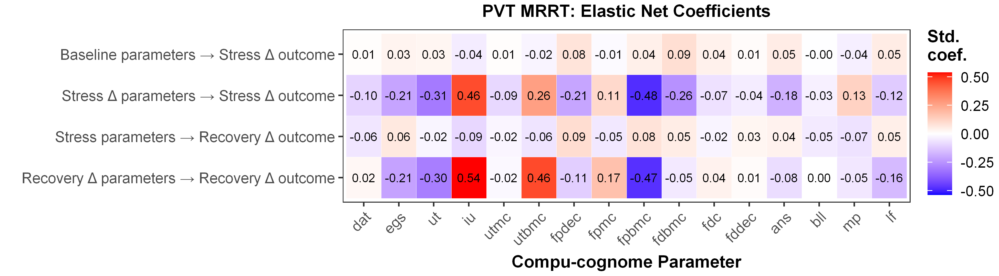

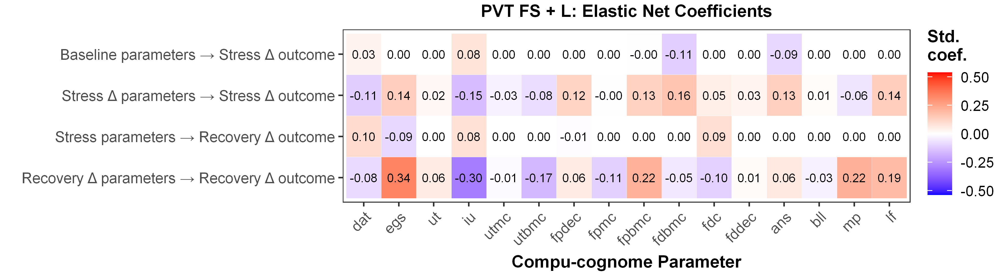

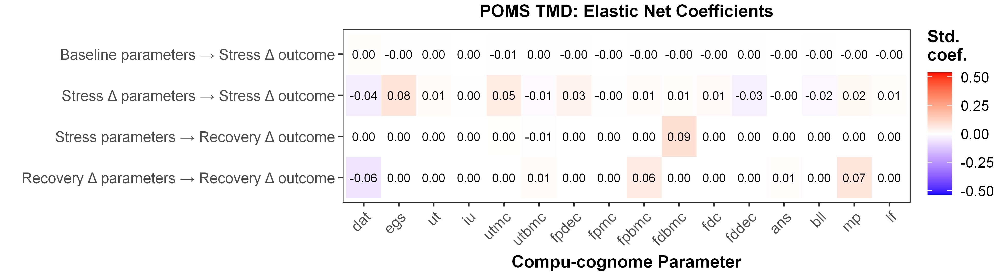

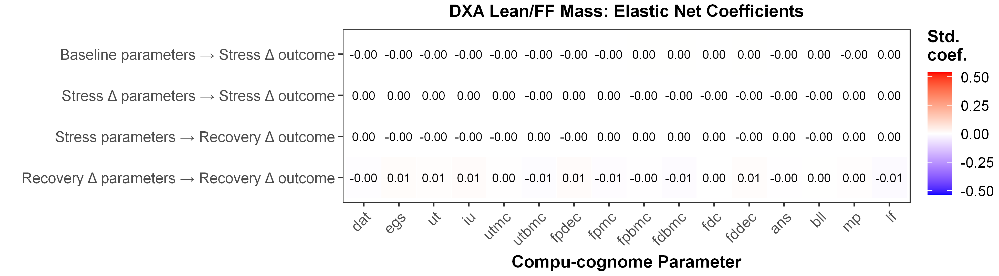

In [214]:
options(repr.plot.width=6.5, repr.plot.height=1.8, repr.plot.res=600)
coef_heatmaps$pvt_mrrt
coef_heatmaps$pvt_fsl
coef_heatmaps$poms
coef_heatmaps$dxa

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Recovery Δ parameters → Recovery Δ outcome' in 'mbcsToSbcs': dot substituted for <ce>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Recovery Δ parameters → Recovery Δ outcome' in 'mbcsToSbcs': dot substituted for <94>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Recovery Δ parameters → Recovery Δ outcome' in 'mbcsToSbcs': dot substituted for <e2>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Recovery Δ parameters → Recovery Δ outcome' in 'mbcsToSbcs': dot substituted for <86>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Recovery Δ parameters → Recovery Δ outcome' in 'mbcsToSbcs': dot substituted for <92>"
Warning message in grid.Call(C_text

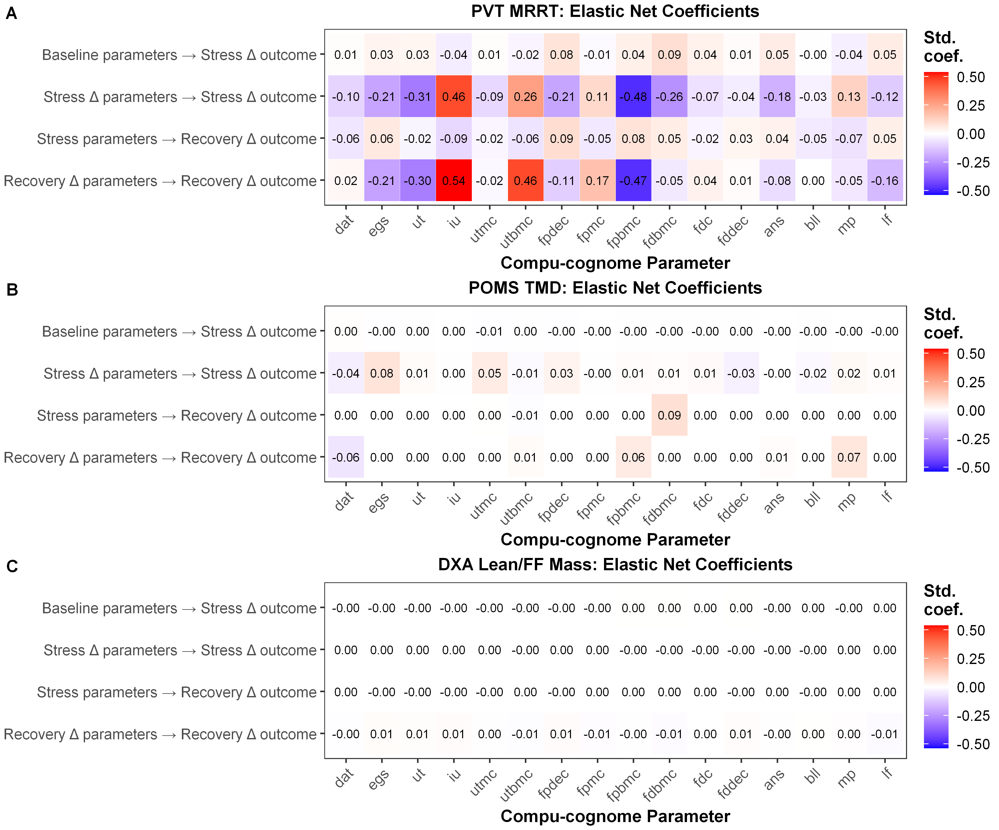

In [215]:
#save plots here
options(repr.plot.width=6.5, repr.plot.height=5.4, repr.plot.res=600)
coeff_plot <- cowplot::plot_grid(
  coef_heatmaps$pvt_mrrt,
  coef_heatmaps$poms,
  coef_heatmaps$dxa,
  ncol = 1,
  labels = c("A", "B", "C"),
  label_size = 8,
  align = "none"
)

coeff_plot

In [198]:
ggsave("elastic_net_coef_plot_mrrt.png", coeff_plot, width = 6.5, height = 5.4, dpi = 600)

In [199]:
ggsave(
  "elastic_net_coef_plot_mrrt.svg",
  coeff_plot,
  width = 6.5,
  height = 5.4,
  device = "svg"
)

In [200]:
ggsave(
  "elastic_net_coef_plot_mrrt.pdf",
  coeff_plot,
  width = 6.5,
  height = 5.4,
  device = cairo_pdf
)

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Recovery Δ parameters → Recovery Δ outcome' in 'mbcsToSbcs': dot substituted for <ce>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Recovery Δ parameters → Recovery Δ outcome' in 'mbcsToSbcs': dot substituted for <94>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Recovery Δ parameters → Recovery Δ outcome' in 'mbcsToSbcs': dot substituted for <e2>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Recovery Δ parameters → Recovery Δ outcome' in 'mbcsToSbcs': dot substituted for <86>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on 'Recovery Δ parameters → Recovery Δ outcome' in 'mbcsToSbcs': dot substituted for <92>"
Warning message in grid.Call(C_text

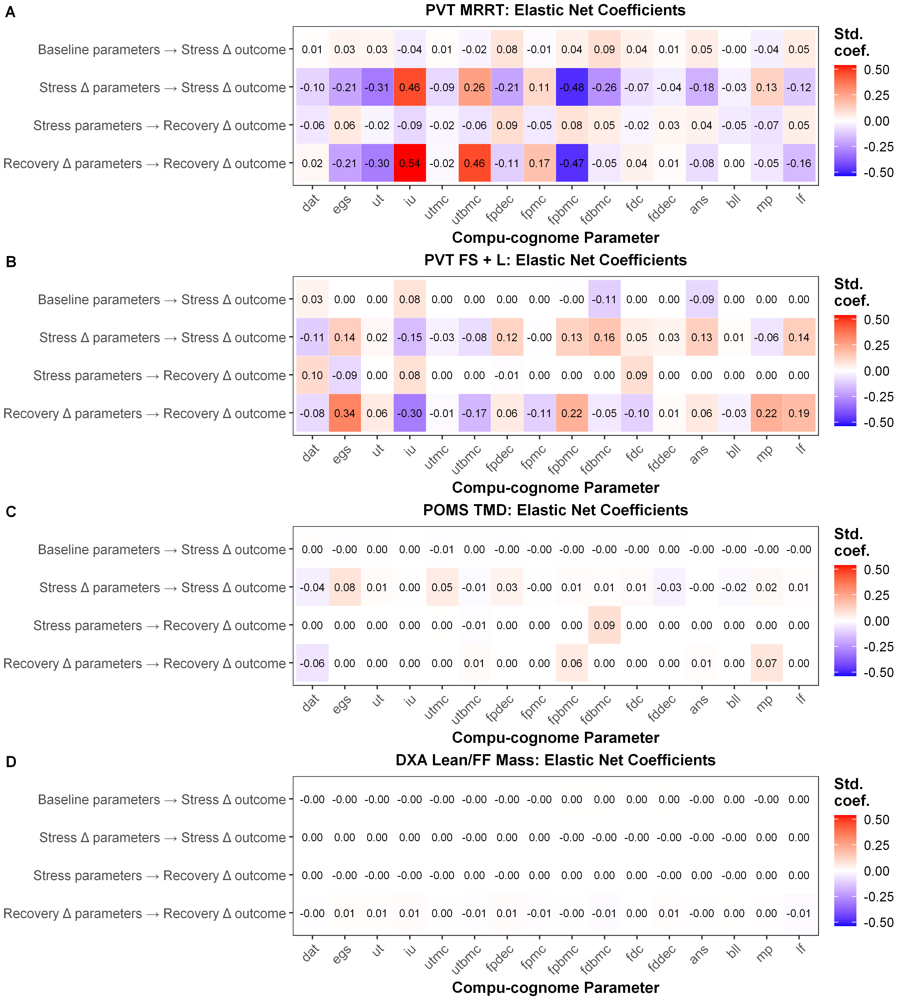

In [216]:
#save plots here
options(repr.plot.width=6.5, repr.plot.height=7.2, repr.plot.res=600)
coeff_plot_all <- cowplot::plot_grid(
  coef_heatmaps$pvt_mrrt,
  coef_heatmaps$pvt_fsl,
  coef_heatmaps$poms,
  coef_heatmaps$dxa,
  ncol = 1,
  labels = c("A", "B", "C","D"),
  label_size = 8,
  align = "none"
)

coeff_plot_all

In [219]:
ggsave("elastic_net_coef_plot_all.png", coeff_plot_all, width = 6.5, height = 7.2, dpi = 600)

In [220]:
ggsave(
  "elastic_net_coef_plot_all.svg",
  coeff_plot_all,
  width = 6.5,
  height = 7.2,
  device = "svg"
)

In [221]:
ggsave(
  "elastic_net_coef_plot_all.pdf",
  coeff_plot_all,
  width = 6.5,
  height = 7.2,
  device = cairo_pdf
)

In [195]:
make_coef_heatmap_all_terms <- function(family_name) {
  
  plot_df <- coef_all_results %>%
    filter(outcome_family == family_name) %>%
    mutate(
      feature = factor(
        feature,
        levels = c(
          coef_all_results %>%
            filter(term_type == "Study fixed effect") %>%
            distinct(feature) %>%
            pull(feature),
          params
        )
      ),
      analysis_label = factor(analysis_label, levels = analysis_levels)
    )
  
  coef_lim_family <- max(abs(plot_df$coef), na.rm = TRUE)
  if (!is.finite(coef_lim_family) || coef_lim_family == 0) coef_lim_family <- 1
  
  ggplot(
    plot_df,
    aes(x = feature, y = fct_rev(analysis_label), fill = coef)
  ) +
    geom_tile(color = "white") +
    geom_text(
      aes(label = ifelse(is.na(coef), "", sprintf("%.2f", coef))),
      size = 2
    ) +
    scale_fill_gradient2(
      low = "blue",
      mid = "white",
      high = "red",
      midpoint = 0,
      limits = c(-coef_lim_family, coef_lim_family),
      na.value = "grey90",
      name = "Std.\ncoef."
    ) +
    labs(
      title = paste0(unique(plot_df$outcome_label), ": Elastic Net Coefficients"),
      x = "Model term",
      y = NULL
    ) +
    theme_bw(base_size = 8) +
    theme(
      plot.title = element_text(size = 8, hjust = 0.5),
      axis.text.x = element_text(size = 7, face = "plain", angle = 45, hjust = 1),
      axis.text.y = element_text(size = 7, face = "plain"),
      panel.grid = element_blank(),
      legend.position = "right"
    )
}

coef_heatmaps_all <- setNames(
  purrr::map(unique(coef_all_results$outcome_family), make_coef_heatmap_all_terms),
  unique(coef_all_results$outcome_family)
)

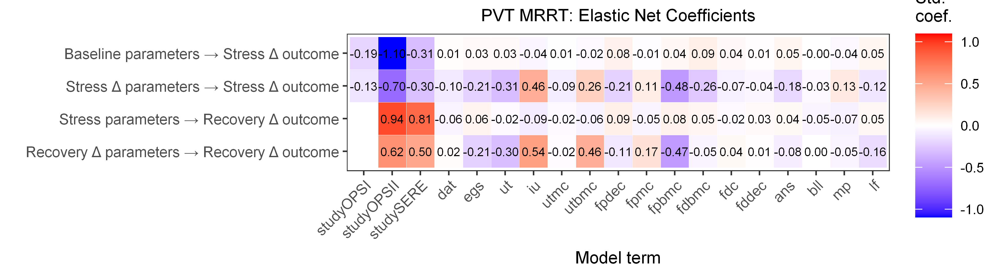

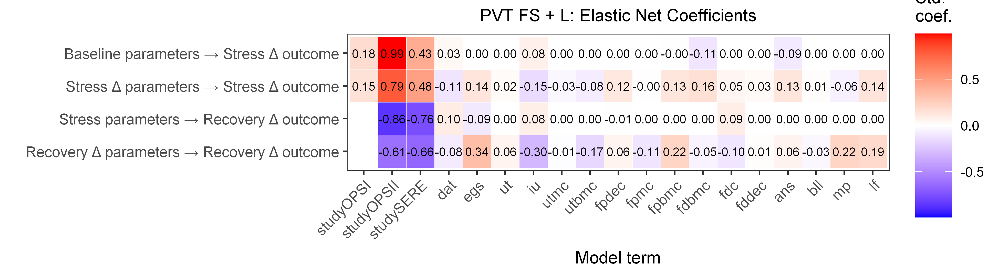

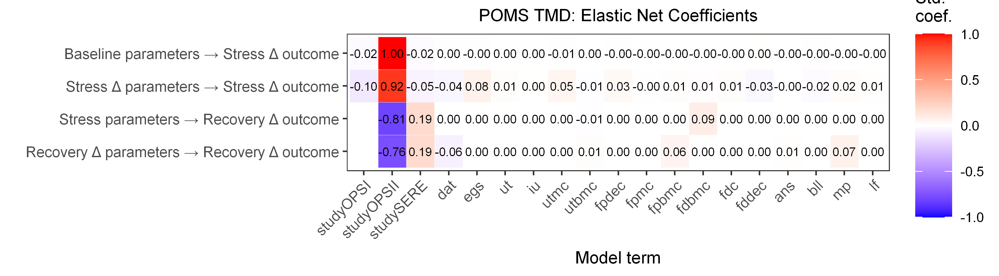

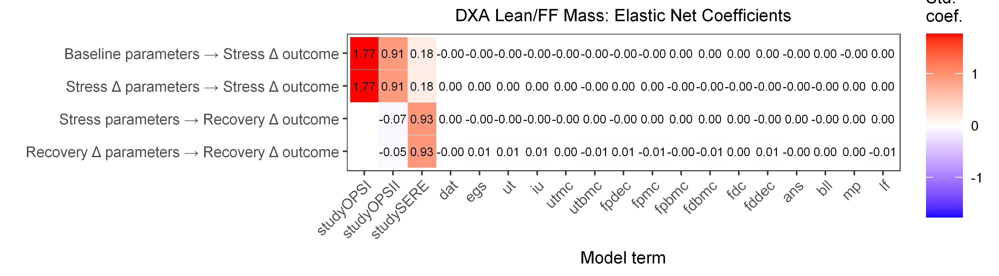

In [196]:
options(repr.plot.width=6.5, repr.plot.height=1.8, repr.plot.res=600)
coef_heatmaps_all$pvt_mrrt
coef_heatmaps_all$pvt_fsl
coef_heatmaps_all$poms
coef_heatmaps_all$dxa

In [167]:
model_results[[5]]

$coef
# A tibble: 16 × 17
   feature       coef term_type              usable selected  abs_coef
   <chr>        <dbl> <chr>                  <lgl>  <lgl>        <dbl>
 1 dat      0.000909  CompuCognome parameter TRUE   TRUE     0.000909 
 2 egs     -0.00125   CompuCognome parameter TRUE   TRUE     0.00125  
 3 ut       0.000836  CompuCognome parameter TRUE   TRUE     0.000836 
 4 iu       0.0000890 CompuCognome parameter TRUE   TRUE     0.0000890
 5 utmc    -0.00130   CompuCognome parameter TRUE   TRUE     0.00130  
 6 utbmc    0.000588  CompuCognome parameter TRUE   TRUE     0.000588 
 7 fpdec   -0.00119   CompuCognome parameter TRUE   TRUE     0.00119  
 8 fpmc     0.0000514 CompuCognome parameter TRUE   TRUE     0.0000514
 9 fpbmc   -0.000769  CompuCognome parameter TRUE   TRUE     0.000769 
10 fdbmc   -0.000517  CompuCognome parameter TRUE   TRUE     0.000517 
11 fdc     -0.000607  CompuCognome parameter TRUE   TRUE     0.000607 
12 fddec    0.000728  CompuCognome parameter TRUE  

In [205]:
compute_adjusted_study_predictions <- function(model_obj, lambda_choice = "lambda.min") {
  
  cvfit <- model_obj$fit
  model_dat <- model_obj$model_dat
  predictor_cols_use <- model_obj$predictor_cols_use
  outcome_col <- model_obj$outcome_col
  
  if (is.null(cvfit)) {
    stop("model_obj$fit is NULL.")
  }
  
  if (is.null(model_dat)) {
    stop("model_obj$model_dat is NULL.")
  }
  
  studies_in_model <- model_dat %>%
    mutate(study = droplevels(factor(study))) %>%
    count(study, name = "n") %>%
    arrange(study)
  
  study_levels <- levels(droplevels(factor(model_dat$study)))
  
  predictor_means_raw <- model_dat %>%
    summarise(across(all_of(predictor_cols_use), ~ mean(.x, na.rm = TRUE)))
  
  new_dat <- studies_in_model %>%
    select(study) %>%
    mutate(study = factor(study, levels = study_levels)) %>%
    bind_cols(
      predictor_means_raw[rep(1, nrow(studies_in_model)), , drop = FALSE]
    )
  
  x_params_new <- as.matrix(new_dat[, predictor_cols_use, drop = FALSE])
  
  x_params_new <- sweep(
    x_params_new,
    2,
    model_obj$x_param_center[predictor_cols_use],
    FUN = "-"
  )
  
  x_params_new <- sweep(
    x_params_new,
    2,
    model_obj$x_param_scale[predictor_cols_use],
    FUN = "/"
  )
  
  colnames(x_params_new) <- predictor_cols_use
  
  if (length(study_levels) > 1) {
    x_study_new <- model.matrix(~ study, data = new_dat)[, -1, drop = FALSE]
    x_new <- cbind(x_params_new, x_study_new)
  } else {
    x_new <- x_params_new
  }
  
  x_new_aligned <- matrix(
    0,
    nrow = nrow(x_new),
    ncol = length(model_obj$x_colnames),
    dimnames = list(NULL, model_obj$x_colnames)
  )
  
  common_cols <- intersect(colnames(x_new), model_obj$x_colnames)
  x_new_aligned[, common_cols] <- x_new[, common_cols, drop = FALSE]
  
  pred_z <- as.numeric(
    predict(
      cvfit,
      newx = x_new_aligned,
      s = lambda_choice
    )
  )
  
  tibble(
    outcome_family = model_obj$outcome_family,
    outcome_label = model_obj$outcome_label,
    outcome = outcome_col,
    predictor_set = model_obj$predictor_set,
    analysis_label = model_obj$analysis_label,
    analysis_order = model_obj$analysis_order,
    alpha = model_obj$alpha,
    lambda = model_obj$lambda,
    cv_r2 = model_obj$cv_r2,
    cv_rmse_z = model_obj$cv_rmse_z,
    study = as.character(new_dat$study),
    n = studies_in_model$n,
    adjusted_prediction_z = pred_z
  )
}

In [202]:
compute_adjusted_study_predictions <- function(model_obj, lambda_choice = "lambda.min") {
  
  cvfit <- model_obj$fit
  dat_model <- model_obj$dat_model
  predictor_cols <- model_obj$predictor_cols
  outcome_col <- model_obj$outcome_col
  
  # Studies actually included in this model after drop_na()
  studies_in_model <- dat_model %>%
    mutate(study = droplevels(factor(study))) %>%
    count(study, name = "n") %>%
    arrange(study)
  
  study_levels <- levels(droplevels(factor(dat_model$study)))
  
  # Predictor means.
  # If predictors were standardized before model fitting, these should be near 0.
  predictor_means <- dat_model %>%
    summarise(across(all_of(predictor_cols_use), ~ mean(.x, na.rm = TRUE)))
  
  # New data: one row per study, predictors held at their model-sample mean
  new_dat <- studies_in_model %>%
    select(study) %>%
    mutate(study = factor(study, levels = study_levels)) %>%
    bind_cols(
      predictor_means[rep(1, nrow(studies_in_model)), , drop = FALSE]
    )
  
  # Recreate the same model matrix used in fitting:
  # reference-coded study fixed effects + predictors
  x_new <- model.matrix(
    as.formula(
      paste("~ study +", paste(predictor_cols, collapse = " + "))
    ),
    data = new_dat
  )[ , -1, drop = FALSE]
  
  # Align columns with the original model matrix.
  # This protects against missing dummy columns in recovery models.
  x_new_aligned <- matrix(
    0,
    nrow = nrow(x_new),
    ncol = length(model_obj$x_colnames),
    dimnames = list(NULL, model_obj$x_colnames)
  )
  
  common_cols <- intersect(colnames(x_new), model_obj$x_colnames)
  x_new_aligned[, common_cols] <- x_new[, common_cols, drop = FALSE]
  
  pred_z <- as.numeric(
    predict(
      cvfit,
      newx = x_new_aligned,
      s = lambda_choice
    )
  )
  
  tibble(
    outcome_family = model_obj$outcome_family,
    outcome_label = model_obj$outcome_label,
    outcome = outcome_col,
    predictor_set = model_obj$predictor_set,
    analysis_label = model_obj$analysis_label,
    analysis_order = model_obj$analysis_order,
    study = as.character(new_dat$study),
    n = studies_in_model$n,
    adjusted_prediction_z = pred_z
  )
}

In [206]:
compute_all_adjusted_study_predictions <- function(model_results, lambda_choice = "lambda.min") {
  
  model_results <- purrr::compact(model_results)
  
  purrr::map_dfr(
    seq_along(model_results),
    function(i) {
      compute_adjusted_study_predictions(
        model_obj = model_results[[i]],
        lambda_choice = lambda_choice
      )
    }
  )
}

In [207]:
adjusted_study_predictions <- compute_all_adjusted_study_predictions(
  model_results,
  lambda_choice = "lambda.min"
)

In [208]:
adjusted_study_predictions %>%
  arrange(outcome_family, analysis_order, study) %>%
  mutate(
    adjusted_prediction_z = round(adjusted_prediction_z, 3)
  ) %>%
  print(n = Inf)

# A tibble: 56 × 13
   outcome_family outcome_label    outcome             predictor_set 
   <chr>          <chr>            <chr>               <chr>         
 1 dxa            DXA Lean/FF Mass dxa_delta_stress    baseline      
 2 dxa            DXA Lean/FF Mass dxa_delta_stress    baseline      
 3 dxa            DXA Lean/FF Mass dxa_delta_stress    baseline      
 4 dxa            DXA Lean/FF Mass dxa_delta_stress    baseline      
 5 dxa            DXA Lean/FF Mass dxa_delta_stress    stress_delta  
 6 dxa            DXA Lean/FF Mass dxa_delta_stress    stress_delta  
 7 dxa            DXA Lean/FF Mass dxa_delta_stress    stress_delta  
 8 dxa            DXA Lean/FF Mass dxa_delta_stress    stress_delta  
 9 dxa            DXA Lean/FF Mass dxa_delta_recovery  stress        
10 dxa            DXA Lean/FF Mass dxa_delta_recovery  stress        
11 dxa            DXA Lean/FF Mass dxa_delta_recovery  stress        
12 dxa            DXA Lean/FF Mass dxa_delta_recovery  recovery_delta


In [209]:
adjusted_study_prediction_table <- adjusted_study_predictions %>%
  mutate(
    adjusted_prediction_z = round(adjusted_prediction_z, 3)
  ) %>%
  select(
    outcome_family,
    outcome_label,
    outcome,
    analysis_order,
    analysis_label,
    study,
    adjusted_prediction_z
  ) %>%
  pivot_wider(
    names_from = study,
    values_from = adjusted_prediction_z
  ) %>%
  arrange(outcome_family, analysis_order)

adjusted_study_prediction_table

outcome_family,outcome_label,outcome,analysis_order,analysis_label,HIGH,OPSI,OPSII,SERE
<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
dxa,DXA Lean/FF Mass,dxa_delta_stress,1,Baseline parameters → Stress Δ outcome,-0.792,0.974,0.122,-0.616
dxa,DXA Lean/FF Mass,dxa_delta_stress,2,Stress Δ parameters → Stress Δ outcome,-0.791,0.975,0.122,-0.616
dxa,DXA Lean/FF Mass,dxa_delta_recovery,3,Stress parameters → Recovery Δ outcome,NA,-0.399,-0.465,0.531
dxa,DXA Lean/FF Mass,dxa_delta_recovery,4,Recovery Δ parameters → Recovery Δ outcome,NA,-0.402,-0.456,0.529
poms,POMS TMD,poms_delta_stress,1,Baseline parameters → Stress Δ outcome,-0.185,-0.206,0.816,-0.204
poms,POMS TMD,poms_delta_stress,2,Stress Δ parameters → Stress Δ outcome,-0.133,-0.231,0.784,-0.183
poms,POMS TMD,poms_delta_recovery,3,Stress parameters → Recovery Δ outcome,NA,0.099,-0.708,0.286
poms,POMS TMD,poms_delta_recovery,4,Recovery Δ parameters → Recovery Δ outcome,NA,0.089,-0.675,0.276
pvt_fsl,PVT FS + L,delta_stress_fsl,1,Baseline parameters → Stress Δ outcome,-0.418,-0.237,0.573,0.007


In [222]:
importance_results <- coef_results %>%
  filter(usable) %>%
  group_by(outcome_family, analysis_label) %>%
  mutate(
    total_abs_coef = sum(abs_coef, na.rm = TRUE),
    rel_importance = ifelse(
      total_abs_coef > 0,
      abs_coef / total_abs_coef,
      0
    )
  ) %>%
  ungroup()

In [223]:
reorder_within <- function(x, by, within, fun = mean, sep = "___", ...) {
  new_x <- paste(x, within, sep = sep)
  reorder(new_x, by, FUN = fun, ...)
}

scale_y_reordered <- function(..., sep = "___") {
  scale_y_discrete(labels = function(x) gsub(paste0(sep, ".*$"), "", x), ...)
}

In [224]:
make_importance_plot <- function(family_name) {
  
  plot_df <- importance_results %>%
    filter(outcome_family == family_name) %>%
    mutate(
      analysis_label = factor(analysis_label, levels = analysis_levels),
      feature_ranked = reorder_within(
        feature,
        rel_importance,
        analysis_label
      ),
      coef_direction = case_when(
        coef > 0 ~ "Positive",
        coef < 0 ~ "Negative",
        TRUE ~ "Zero"
      )
    )
  
  ggplot(
    plot_df,
    aes(x = rel_importance, y = feature_ranked, fill = coef_direction)
  ) +
    geom_col() +
    facet_wrap(~ analysis_label, scales = "free_y", ncol = 2) +
    scale_y_reordered() +
    scale_fill_manual(
      values = c(
        "Positive" = "#2E86AB",
        "Negative" = "#C0392B",
        "Zero" = "grey80"
      )
    ) +
    labs(
      title = paste0(
        unique(plot_df$outcome_label),
        ": Ranked CompuCognome Feature Importance"
      ),
      x = "Relative importance within model",
      y = "CompuCognome parameter",
      fill = "Coefficient\ndirection"
    ) +
    theme_bw(base_size = 8) +
    #theme(
    #  plot.title = element_text(hjust = 0.5, face = "bold"),
    #  strip.text = element_text(face = "bold", size = 7),
    #  axis.text.y = element_text(size = 7),
    #  panel.grid.major.y = element_blank(),
    #  legend.position = "bottom"
    #)
    theme(text = element_text(size=8, face="bold"),
          plot.title = element_text(size=8, hjust = 0.5),
          axis.text.x = element_text(size=7, face="plain"),
          axis.title.x = element_text(size=8),
          axis.text.y = element_text(size=7, face="plain"),
          axis.title.y = element_text(size=8),
          strip.text = element_text(face = "bold", size = 7),
          legend.position = "bottom",
          panel.grid.major.y = element_blank(),
          legend.title = element_text(size=8, face="bold"), #, margin = margin(0, 0, 0, 0)),
          legend.text = element_text(size=7, face="plain"),
          #legend.margin = margin(t = -2),
          legend.key.size = unit(0.8, "lines"),
          legend.margin = margin(-5, 0, 0, 0),
          legend.box.margin = margin(0, 0, 0, 0),
          plot.margin = margin(2, 2, 2, 2)
    )  
}

importance_plots <- setNames(
  purrr::map(unique(importance_results$outcome_family), make_importance_plot),
  unique(importance_results$outcome_family)
)



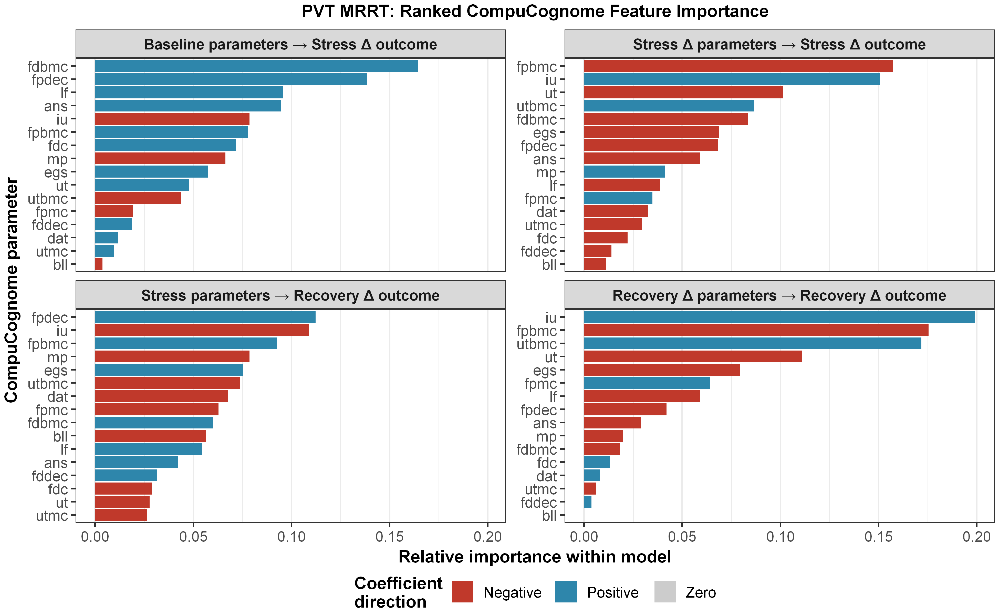

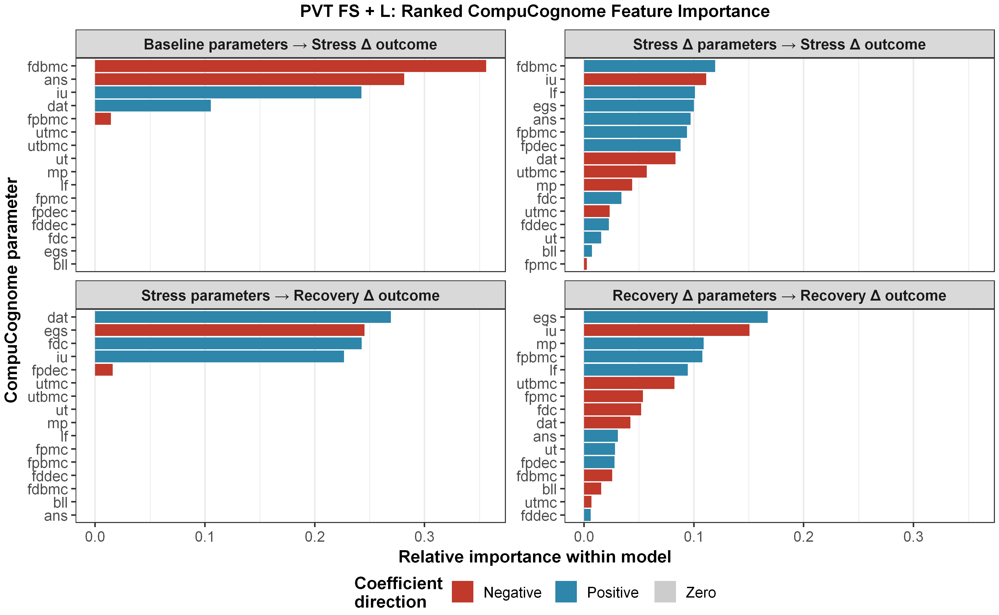

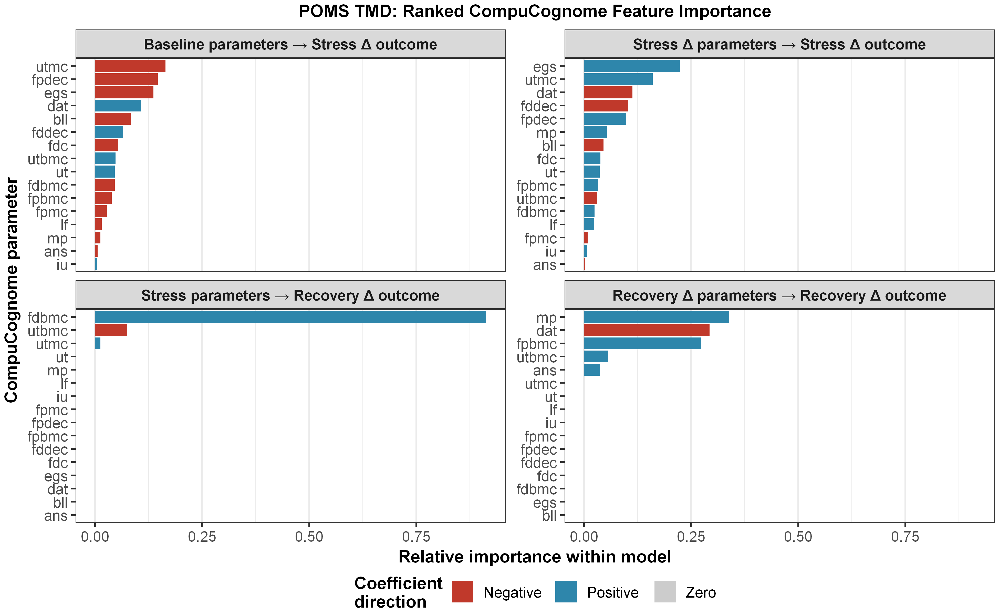

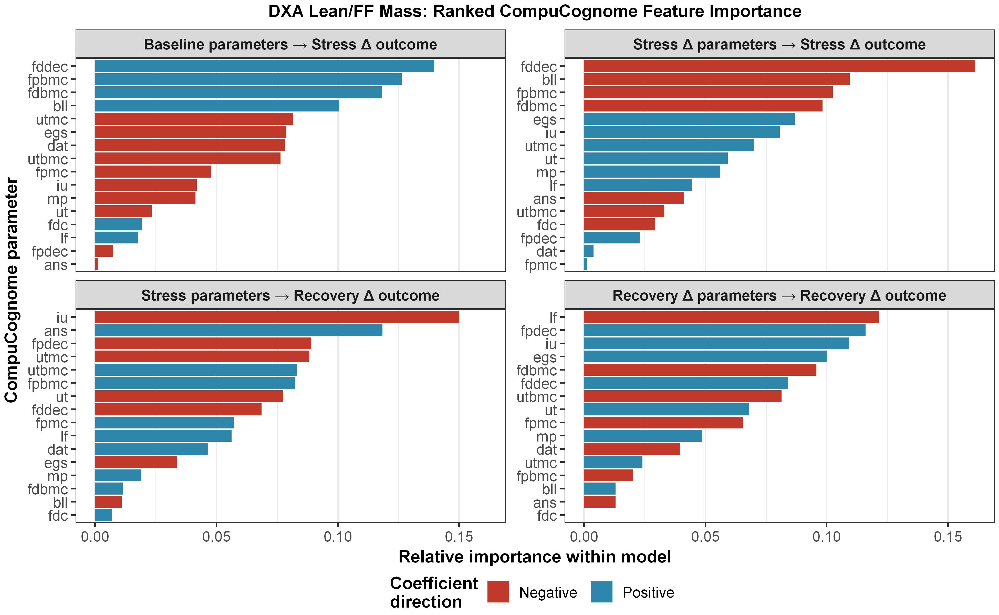

In [225]:
options(repr.plot.width=6.5, repr.plot.height=4.0, repr.plot.res=600)
importance_plots$pvt_mrrt
importance_plots$pvt_fsl
importance_plots$poms
importance_plots$dxa

In [214]:
ggsave("elastic_net_importance_pvt_mrrt.png", importance_plots$pvt_mrrt, width = 6.5, height = 4.0, dpi = 600)

ggsave(
  "elastic_net_importance_pvt_mrrt.svg",
  importance_plots$pvt_mrrt,
  width = 6.5,
  height = 4.0,
  device = "svg"
)

ggsave(
  "elastic_net_importance_pvt_mrrt.pdf",
  importance_plots$pvt_mrrt,
  width = 6.5,
  height = 4.0,
  device = cairo_pdf
)

In [215]:
ggsave("elastic_net_importance_pvt_fsl.png", importance_plots$pvt_fsl, width = 6.5, height = 4.0, dpi = 600)

ggsave(
  "elastic_net_importance_pvt_fsl.svg",
  importance_plots$pvt_fsl,
  width = 6.5,
  height = 4.0,
  device = "svg"
)

ggsave(
  "elastic_net_importance_pvt_fsl.pdf",
  importance_plots$pvt_fsl,
  width = 6.5,
  height = 4.0,
  device = cairo_pdf
)

In [216]:
ggsave("elastic_net_importance_poms.png", importance_plots$poms, width = 6.5, height = 4.0, dpi = 600)

ggsave(
  "elastic_net_importance_poms.svg",
  importance_plots$poms,
  width = 6.5,
  height = 4.0,
  device = "svg"
)

ggsave(
  "elastic_net_importance_poms.pdf",
  importance_plots$poms,
  width = 6.5,
  height = 4.0,
  device = cairo_pdf
)

In [217]:
ggsave("elastic_net_importance_dxa.png", importance_plots$dxa, width = 6.5, height = 4.0, dpi = 600)

ggsave(
  "elastic_net_importance_dxa.svg",
  importance_plots$dxa,
  width = 6.5,
  height = 4.0,
  device = "svg"
)

ggsave(
  "elastic_net_importance_dxa.pdf",
  importance_plots$dxa,
  width = 6.5,
  height = 4.0,
  device = cairo_pdf
)

In [278]:
run_enet_repeated <- function(
    n_reps = 100,
    base_seed = 123,
    analysis_specs = analysis_specs,
    model_base = model_base,
    predictor_cols = params,
    lambda_choice = "lambda.min"
) {
  
  seeds <- base_seed + seq_len(n_reps) - 1
  
  rep_results <- purrr::map2(
    seeds,
    seq_len(n_reps),
    function(seed_i, rep_i) {
      
      message("Elastic net repetition ", rep_i, " of ", n_reps)
      
      model_results_i <- purrr::pmap(
        analysis_specs,
        function(
            outcome_family,
            outcome_label,
            stress_delta_outcome,
            recovery_delta_outcome,
            predictor_set,
            analysis_label,
            analysis_order,
            outcome_period,
            outcome_col
        ) {
          fit_enet_one(
            model_base = model_base,
            outcome_family = outcome_family,
            outcome_label = outcome_label,
            predictor_set = predictor_set,
            analysis_label = analysis_label,
            analysis_order = analysis_order,
            outcome_col = outcome_col,
            predictor_cols = predictor_cols,
            lambda_choice = lambda_choice,
            seed = seed_i
          )
        }
      ) %>%
        purrr::compact()
      
      list(
        coef = purrr::map_dfr(model_results_i, "coef") %>%
          mutate(rep_id = rep_i, seed = seed_i),
        
        coef_all = purrr::map_dfr(model_results_i, "coef_all") %>%
          mutate(rep_id = rep_i, seed = seed_i),
        
        performance = purrr::map_dfr(model_results_i, "performance") %>%
          mutate(rep_id = rep_i, seed = seed_i)
      )
    }
  )
  
  list(
    coef = purrr::map_dfr(rep_results, "coef"),
    coef_all = purrr::map_dfr(rep_results, "coef_all"),
    performance = purrr::map_dfr(rep_results, "performance")
  )
}

In [279]:
enet_repeated <- run_enet_repeated(
  n_reps = 100,
  base_seed = 123,
  analysis_specs = analysis_specs,
  model_base = model_base,
  predictor_cols = params,
  lambda_choice = "lambda.min"
)

coef_results_repeated <- enet_repeated$coef
coef_all_results_repeated <- enet_repeated$coef_all
perf_results_repeated <- enet_repeated$performance

Elastic net repetition 1 of 100

Elastic net repetition 2 of 100

Elastic net repetition 3 of 100

Elastic net repetition 4 of 100

Elastic net repetition 5 of 100

Elastic net repetition 6 of 100

Elastic net repetition 7 of 100

Elastic net repetition 8 of 100

Elastic net repetition 9 of 100

Elastic net repetition 10 of 100

Elastic net repetition 11 of 100

Elastic net repetition 12 of 100

Elastic net repetition 13 of 100

Elastic net repetition 14 of 100

Elastic net repetition 15 of 100

Elastic net repetition 16 of 100

Elastic net repetition 17 of 100

Elastic net repetition 18 of 100

Elastic net repetition 19 of 100

Elastic net repetition 20 of 100

Elastic net repetition 21 of 100

Elastic net repetition 22 of 100

Elastic net repetition 23 of 100

Elastic net repetition 24 of 100

Elastic net repetition 25 of 100

Elastic net repetition 26 of 100

Elastic net repetition 27 of 100

Elastic net repetition 28 of 100

Elastic net repetition 29 of 100

Elastic net repetition 

In [280]:
importance_results <- coef_results_repeated %>%
  filter(
    usable,
    term_type == "CompuCognome parameter",
    !is.na(coef)
  ) %>%
  group_by(
    outcome_family,
    outcome_label,
    outcome,
    predictor_set,
    analysis_order,
    analysis_label,
    feature
  ) %>%
  summarise(
    n_reps = n(),
    mean_coef = mean(coef, na.rm = TRUE),
    median_coef = median(coef, na.rm = TRUE),
    mean_abs_coef = mean(abs(coef), na.rm = TRUE),
    sd_coef = sd(coef, na.rm = TRUE),
    .groups = "drop"
  ) %>%
  group_by(
    outcome_family,
    outcome_label,
    outcome,
    predictor_set,
    analysis_order,
    analysis_label
  ) %>%
  mutate(
    total_abs_coef = sum(mean_abs_coef, na.rm = TRUE),
    rel_importance = if_else(
      total_abs_coef > 0,
      mean_abs_coef / total_abs_coef,
      0
    ),
    rel_importance_pct = 100 * rel_importance,
    coef_direction = case_when(
      mean_coef > 0 ~ "Positive",
      mean_coef < 0 ~ "Negative",
      TRUE ~ "Zero"
    )
  ) %>%
  ungroup()

In [281]:
perf_results_repeated_summary <- perf_results_repeated %>%
  group_by(
    outcome_family,
    outcome_label,
    outcome,
    predictor_set,
    analysis_order,
    analysis_label
  ) %>%
  summarise(
    n_reps = n(),
    mean_cv_r2 = mean(cv_r2, na.rm = TRUE),
    sd_cv_r2 = sd(cv_r2, na.rm = TRUE),
    mean_cv_rmse_z = mean(cv_rmse_z, na.rm = TRUE),
    sd_cv_rmse_z = sd(cv_rmse_z, na.rm = TRUE),
    mean_alpha = mean(alpha, na.rm = TRUE),
    mean_lambda = mean(lambda, na.rm = TRUE),
    .groups = "drop"
  )

In [282]:
reorder_within <- function(x, by, within, fun = mean, sep = "___", ...) {
  new_x <- paste(x, within, sep = sep)
  reorder(new_x, by, FUN = fun, ...)
}

scale_y_reordered <- function(..., sep = "___") {
  scale_y_discrete(
    labels = function(x) gsub(paste0(sep, ".*$"), "", x),
    ...
  )
}

make_importance_plot <- function(
    family_name,
    analysis_order_keep = NULL,
    analysis_label_keep = NULL,
    predictor_set_keep = NULL,
    outcome_keep = NULL,
    top_n = NULL
) {
  
  plot_df <- importance_results %>%
    filter(outcome_family == family_name)
  
  if (!is.null(analysis_order_keep)) {
    plot_df <- plot_df %>%
      filter(analysis_order %in% analysis_order_keep)
  }
  
  if (!is.null(analysis_label_keep)) {
    plot_df <- plot_df %>%
      filter(analysis_label %in% analysis_label_keep)
  }
  
  if (!is.null(predictor_set_keep)) {
    plot_df <- plot_df %>%
      filter(predictor_set %in% predictor_set_keep)
  }
  
  if (!is.null(outcome_keep)) {
    plot_df <- plot_df %>%
      filter(outcome %in% outcome_keep)
  }
  
  if (nrow(plot_df) == 0) {
    stop("No rows match the requested filters.")
  }
  
  plot_df <- plot_df %>%
    mutate(
      analysis_label = factor(analysis_label, levels = analysis_levels)
    )
  
  if (!is.null(top_n)) {
    plot_df <- plot_df %>%
      group_by(outcome_family, analysis_label) %>%
      slice_max(
        order_by = rel_importance,
        n = top_n,
        with_ties = FALSE
      ) %>%
      ungroup()
  }
  
  plot_df <- plot_df %>%
    mutate(
      feature_ranked = reorder_within(
        feature,
        rel_importance,
        analysis_label
      )
    )
  
  ggplot(
    plot_df,
    aes(
      x = rel_importance,
      y = feature_ranked,
      fill = coef_direction
    )
  ) +
    geom_col() +
    facet_wrap(~ analysis_label, scales = "free_y", ncol = 2) +
    scale_y_reordered() +
    scale_x_continuous(
      labels = scales::percent_format(accuracy = 1)
    ) +
    scale_fill_manual(
      values = c(
        "Positive" = "#C0392B",
        "Negative" = "#2E86AB",
        "Zero" = "grey80"
      )
    ) +
    labs(
      title = paste0(
        unique(plot_df$outcome_label),
        ": Ranked CompuCognome Feature Importance"
      ),
      x = "Relative importance within model",
      y = "CompuCognome parameter",
      fill = "Mean coefficient\ndirection"
    ) +
    theme_bw(base_size = 8) +
    theme(
      text = element_text(size = 8, face = "bold"),
      plot.title = element_text(size = 8, hjust = 0.5),
      axis.text.x = element_text(size = 7, face = "plain"),
      axis.title.x = element_text(size = 8),
      axis.text.y = element_text(size = 7, face = "plain"),
      axis.title.y = element_text(size = 8),
      strip.text = element_text(face = "bold", size = 7),
      legend.position = "bottom",
      panel.grid.major.y = element_blank(),
      legend.title = element_text(size = 8, face = "bold"),
      legend.text = element_text(size = 7, face = "plain"),
      legend.key.size = unit(0.8, "lines"),
      legend.margin = margin(-5, 0, 0, 0),
      legend.box.margin = margin(0, 0, 0, 0),
      plot.margin = margin(2, 2, 2, 2)
    )
}

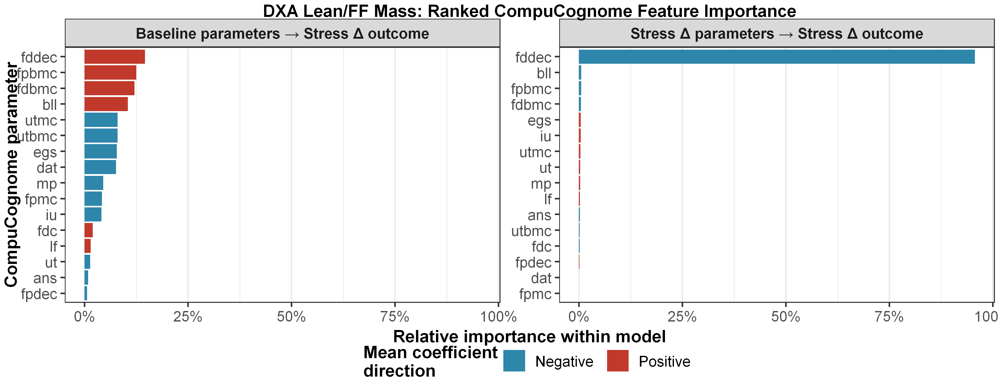

In [286]:
# 2 = Stress Δ parameters → Stress Δ outcome
# 4 = Recovery Δ parameters → Recovery Δ outcome

options(repr.plot.width = 6.5, repr.plot.height = 2.5, repr.plot.res = 600)

dxa_importance <- make_importance_plot(
  family_name = "dxa",
  analysis_order_keep = c(1,2)
)

dxa_importance


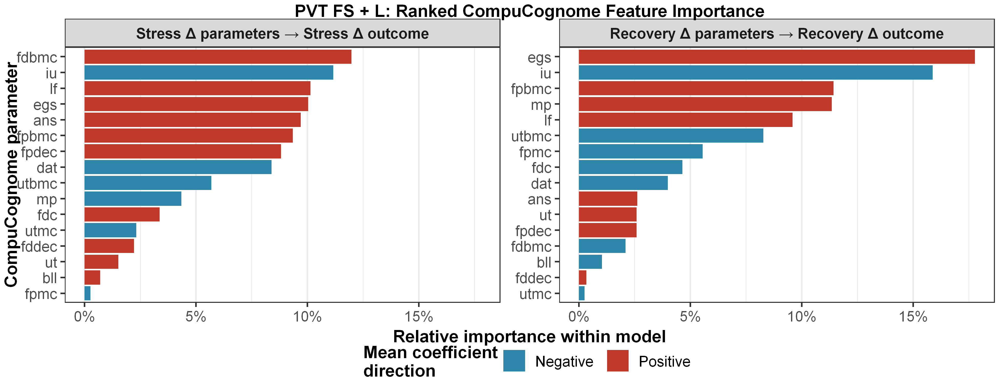

In [287]:
# 2 = Stress Δ parameters → Stress Δ outcome
# 4 = Recovery Δ parameters → Recovery Δ outcome

options(repr.plot.width = 6.5, repr.plot.height = 2.5, repr.plot.res = 600)

p_fsl_main <- make_importance_plot(
  family_name = "pvt_fsl",
  analysis_order_keep = c(2, 4)
)

p_fsl_main


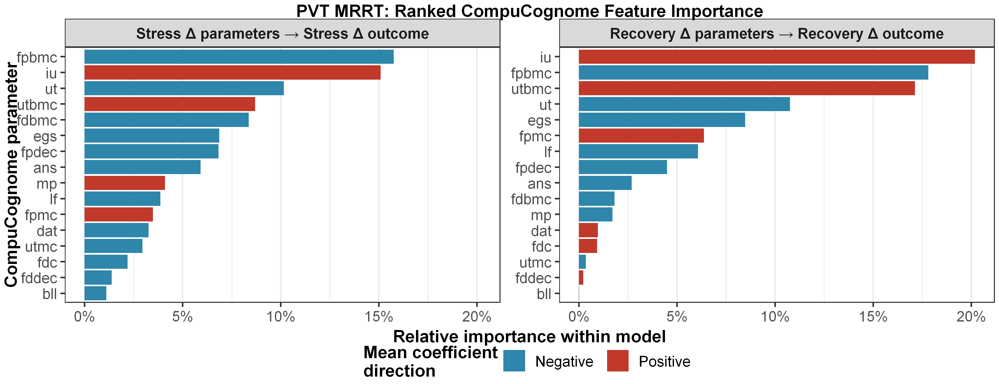

In [288]:
# 2 = Stress Δ parameters → Stress Δ outcome
# 4 = Recovery Δ parameters → Recovery Δ outcome

options(repr.plot.width = 6.5, repr.plot.height = 2.5, repr.plot.res = 600)

p_mrrt_main <- make_importance_plot(
  family_name = "pvt_mrrt",
  analysis_order_keep = c(2, 4)
)

p_mrrt_main


In [226]:
ggsave("elastic_net_importance_mrrt_main.png", p_mrrt_main, width = 6.5, height = 2.5, dpi = 600)

ggsave(
  "elastic_net_importance_mrrt_main.svg",
  p_mrrt_main,
  width = 6.5,
  height = 2.5,
  device = "svg"
)

ggsave(
  "elastic_net_importance_mrrt_main.pdf",
  p_mrrt_main,
  width = 6.5,
  height = 2.5,
  device = cairo_pdf
)

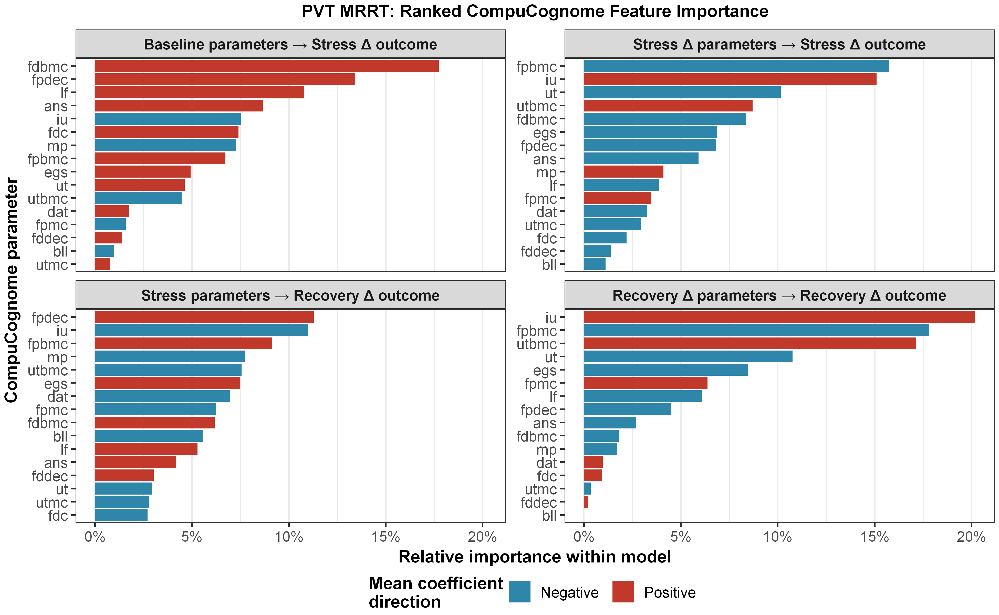

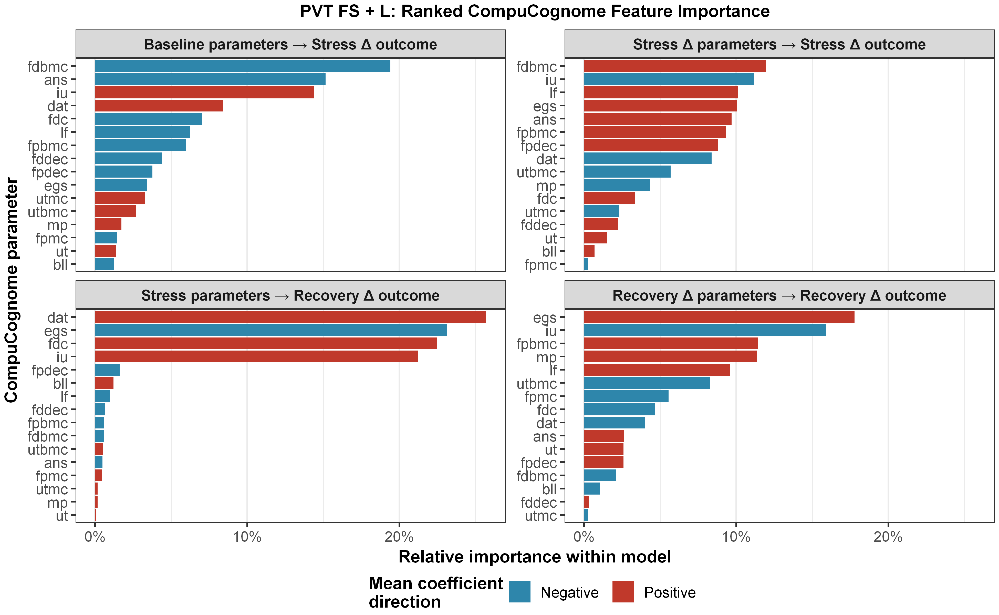

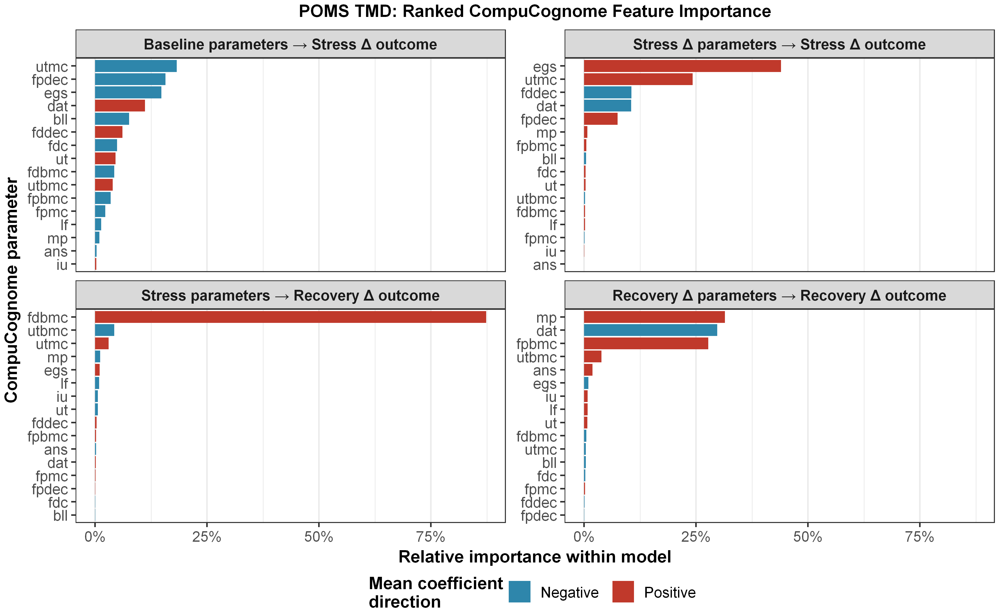

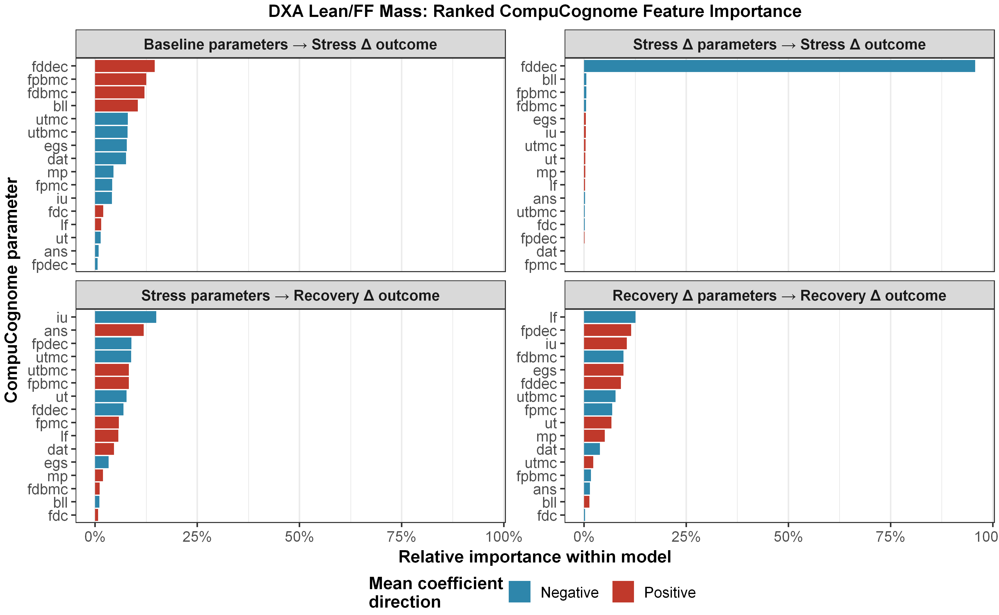

In [228]:
importance_plots_all <- setNames(
  purrr::map(
    unique(importance_results$outcome_family),
    ~ make_importance_plot(family_name = .x)
  ),
  unique(importance_results$outcome_family)
)

options(repr.plot.width = 6.5, repr.plot.height = 4.0, repr.plot.res = 600)

importance_plots_all$pvt_mrrt
importance_plots_all$pvt_fsl
importance_plots_all$poms
importance_plots_all$dxa

In [229]:
ggsave("elastic_net_importance_mrrt.png", importance_plots_all$pvt_mrrt, width = 6.5, height = 4.0, dpi = 600)

ggsave(
  "elastic_net_importance_mrrt.svg",
  importance_plots_all$pvt_mrrt,
  width = 6.5,
  height = 4.0,
  device = "svg"
)

ggsave(
  "elastic_net_importance_mrrt.pdf",
  importance_plots_all$pvt_mrrt,
  width = 6.5,
  height = 4.0,
  device = cairo_pdf
)

In [230]:
ggsave("elastic_net_importance_fsl.png", importance_plots_all$pvt_fsl, width = 6.5, height = 4.0, dpi = 600)

ggsave(
  "elastic_net_importance_fsl.svg",
  importance_plots_all$pvt_fsl,
  width = 6.5,
  height = 4.0,
  device = "svg"
)

ggsave(
  "elastic_net_importance_fsl.pdf",
  importance_plots_all$pvt_fsl,
  width = 6.5,
  height = 4.0,
  device = cairo_pdf
)

In [231]:
ggsave("elastic_net_importance_poms.png", importance_plots_all$poms, width = 6.5, height = 4.0, dpi = 600)

ggsave(
  "elastic_net_importance_poms.svg",
  importance_plots_all$poms,
  width = 6.5,
  height = 4.0,
  device = "svg"
)

ggsave(
  "elastic_net_importance_poms.pdf",
  importance_plots_all$poms,
  width = 6.5,
  height = 4.0,
  device = cairo_pdf
)

In [232]:
ggsave("elastic_net_importance_dxa.png", importance_plots_all$dxa, width = 6.5, height = 4.0, dpi = 600)

ggsave(
  "elastic_net_importance_dxa.svg",
  importance_plots_all$dxa,
  width = 6.5,
  height = 4.0,
  device = "svg"
)

ggsave(
  "elastic_net_importance_dxa.pdf",
  importance_plots_all$dxa,
  width = 6.5,
  height = 4.0,
  device = cairo_pdf
)

## Leave one out analyses

In [428]:
model_base_no_HIGH <- model_base %>%
  filter(study != "HIGH") %>%
  droplevels()

model_base_no_OPSI <- model_base %>%
  filter(study != "OPSI") %>%
  droplevels()

model_base_no_OPSII <- model_base %>%
  filter(study != "OPSII") %>%
  droplevels()

model_base_no_SERE <- model_base %>%
  filter(study != "SERE") %>%
  droplevels()

In [429]:
studies <- c("HIGH", "OPSI", "OPSII", "SERE")

loo_model_bases <- purrr::map(
  studies,
  function(study_drop) {
    model_base %>%
      filter(study != study_drop) %>%
      droplevels()
  }
)

names(loo_model_bases) <- paste0("Without_", studies)

In [427]:
run_enet_analysis_set <- function(
    model_base_i,
    analysis_specs,
    predictor_cols = params,
    lambda_choice = "lambda.min",
    seed = 123
) {
  
  model_results <- purrr::pmap(
    analysis_specs,
    function(
      outcome_family,
      outcome_label,
      stress_delta_outcome,
      recovery_delta_outcome,
      predictor_set,
      analysis_label,
      analysis_order,
      outcome_period,
      outcome_col
    ) {
      
      fit_enet_one(
        model_base = model_base_i,
        outcome_family = outcome_family,
        outcome_label = outcome_label,
        predictor_set = predictor_set,
        analysis_label = analysis_label,
        analysis_order = analysis_order,
        outcome_col = outcome_col,
        predictor_cols = predictor_cols,
        lambda_choice = lambda_choice,
        seed = seed
      )
    }
  ) %>%
    purrr::compact()
  
  list(
    results = model_results,
    
    performance = purrr::map_dfr(
      model_results,
      "performance"
    ),
    
    coefficients = purrr::map_dfr(
      model_results,
      "coef"
    ),
    
    coefficients_all = purrr::map_dfr(
      model_results,
      "coef_all"
    )
  )
}

In [430]:
loo_results <- purrr::imap(
  loo_model_bases,
  function(dat_i, analysis_name) {
    
    message("Running: ", analysis_name)
    
    res <- run_enet_analysis_set(
      model_base_i = dat_i,
      analysis_specs = analysis_specs,
      predictor_cols = params,
      lambda_choice = "lambda.min",
      seed = 123
    )
    
    res$performance <- res$performance %>%
      mutate(analysis_subset = analysis_name)
    
    res$coefficients <- res$coefficients %>%
      mutate(analysis_subset = analysis_name)
    
    res$coefficients_all <- res$coefficients_all %>%
      mutate(analysis_subset = analysis_name)
    
    res
  }
)

Running: Without_HIGH

Running: Without_OPSI

Running: Without_OPSII

Running: Without_SERE



In [431]:
loo_performance <- purrr::map_dfr(
  loo_results,
  "performance"
)

In [432]:
loo_coefficients <- purrr::map_dfr(
  loo_results,
  "coefficients"
)

In [434]:
full_performance_labeled <- perf_results %>%
  mutate(analysis_subset = "All Studies")

performance_comparison <- bind_rows(
  full_performance_labeled,
  loo_performance
)

In [436]:
head(performance_comparison)

outcome_family,outcome_label,outcome,predictor_set,analysis_label,analysis_order,n,n_predictors,alpha,lambda,cv_rmse_z,cv_r2,analysis_subset
<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
dxa,DXA Lean/FF Mass,dxa_delta_stress,baseline,Baseline parameters → Stress Δ outcome,1,159,16,0,56.195630,0.7031843,0.5024023,All Studies
dxa,DXA Lean/FF Mass,dxa_delta_stress,stress_delta,Stress Δ parameters → Stress Δ outcome,2,159,16,0,69.963211,0.7032733,0.5022763,All Studies
dxa,DXA Lean/FF Mass,dxa_delta_recovery,stress,Stress parameters → Recovery Δ outcome,3,142,16,0,98.844097,0.8875831,0.2066089,All Studies
dxa,DXA Lean/FF Mass,dxa_delta_recovery,recovery_delta,Recovery Δ parameters → Recovery Δ outcome,4,142,16,0,8.798251,0.8866719,0.2082372,All Studies
poms,POMS TMD,poms_delta_stress,baseline,Baseline parameters → Stress Δ outcome,1,161,16,0,20.521782,0.9422016,0.1067078,All Studies
poms,POMS TMD,poms_delta_stress,stress_delta,Stress Δ parameters → Stress Δ outcome,2,161,16,0,1.734138,0.9328114,0.1244246,All Studies


In [438]:
performance_comparison %>%
  select(
    analysis_subset,
    outcome_family,
    outcome_label,
    analysis_order,
    analysis_label,
    n,
    alpha,
    lambda,
    cv_r2,
    cv_rmse_z
  ) %>%
  arrange(
    outcome_family,
    analysis_order,
    analysis_subset
  )

write.csv(performance_comparison,"./elastic_net_results_comparisons.csv", row.names = FALSE)

analysis_subset,outcome_family,outcome_label,analysis_order,analysis_label,n,alpha,lambda,cv_r2,cv_rmse_z
<chr>,<chr>,<chr>,<dbl>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
All Studies,dxa,DXA Lean/FF Mass,1,Baseline parameters → Stress Δ outcome,159,0.00,56.1956304,0.50240227,0.7031843
Without_HIGH,dxa,DXA Lean/FF Mass,1,Baseline parameters → Stress Δ outcome,142,0.00,62.2701387,0.50877048,0.6984054
Without_OPSI,dxa,DXA Lean/FF Mass,1,Baseline parameters → Stress Δ outcome,109,0.00,102.0551209,0.17194641,0.9057907
Without_OPSII,dxa,DXA Lean/FF Mass,1,Baseline parameters → Stress Δ outcome,130,0.00,79.0719865,0.53972031,0.6758247
Without_SERE,dxa,DXA Lean/FF Mass,1,Baseline parameters → Stress Δ outcome,96,0.00,2.1827724,0.44501606,0.7410822
All Studies,dxa,DXA Lean/FF Mass,2,Stress Δ parameters → Stress Δ outcome,159,0.00,69.9632115,0.50227628,0.7032733
Without_HIGH,dxa,DXA Lean/FF Mass,2,Stress Δ parameters → Stress Δ outcome,142,0.00,59.6400221,0.50878100,0.6983980
Without_OPSI,dxa,DXA Lean/FF Mass,2,Stress Δ parameters → Stress Δ outcome,109,0.00,87.1089005,0.17176106,0.9058921
Without_OPSII,dxa,DXA Lean/FF Mass,2,Stress Δ parameters → Stress Δ outcome,130,0.00,66.1680069,0.53926002,0.6761626
